# EMOTIC — Phase C: GEQ (Grounded Emotion Queries)

**Every session: Run All.** Settings: GPU T4 x2, Internet on, Persistence *Files only*, same dataset as Phases A/B. Each block ends with a green banner when it executed correctly.

* Blocks 01–07 rebuild the session (Block 06 runs its smoke test and GPU pre-flight only once; Block 07 rebuilds the feature cache every session).
* Block 08 trains until 30 min before the 11.5 h budget; every run checkpoints and resumes exactly in the next session.
* Blocks 09–10 keep the test set sealed until all 60 runs are finished; in the session where the last run finishes they evaluate (pre-registered decision gate) and draw the figures.
* Block 11 cleans up every session; in the final session it writes `phaseC_results_archive.zip` and prints **PHASE C COMPLETE**.

Phase C writes only to `runs_phaseC/`, `results/phaseC_geq/`, `figures/phaseC_geq/` and `phaseC/`. See README_PhaseC.md for the session plan and troubleshooting.


In [1]:
# Block 01 — Environment, Paths, Harness & Session Guard  [Phase C: GEQ]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : none (first block of every session). Run Phase C in a NEW Kaggle
#                 notebook (same dataset, GPU T4 x2, Internet on, Persistence
#                 "Files only"). Phase A and Phase B results are not touched.
#
# PHASE C — a NOVEL ARCHITECTURE on the same data, splits and protocol
#   Phase A (no augmentation): C1_person 38.70 ± 0.09. Phase B: augmentation did not
#   help (B0_noaug 38.87 ± 0.22, B1_aug 38.77, B2_top 38.48). Phase C asks whether
#   the READOUT is the bottleneck: B0 reads all 26 emotions from one pooled vector of
#   32 class-agnostic queries, and the rare / abstract categories (Yearning 11,
#   Aversion 13, Surprise 18, Esteem 19 AP) are where it fails.
#
#   GEQ (Grounded Emotion Queries) adds one query per emotion INSIDE the Q-Former,
#   initialised from the category's annotation-guideline definition, reading the
#   LLaVA description and the visual tokens at every layer through a non-intrusive
#   mask (B0's pathway is untouched, so GEQ contains B0), scored by a classifier
#   generated from the definition encoding, added to B0's logit.
#
#   Pre-registered plan (Block 06 prints it before any training; config.yaml):
#     main      B0 (existing best) · Q2L · ML-Decoder · CSRA · GEQ        (heavy, 5 seeds)
#     lite      B0-Lite · GEQ-Lite (frozen Q-Former + LoRA)               (5 seeds)
#     ablation  A1 random init · A2 learned class embeddings · A3 late entry
#               · A4 intrusive mask · A5 no global residual               (5 seeds)
#   60 runs ≈ 60 GPU-hours ≈ 3 sessions (2 GPUs). The decision gate is evaluated
#   once, by code, in Block 09.
#
# SESSIONS: every session runs Blocks 01–07 (Block 07 rebuilds the scratch feature
#   cache, ~40 min, bit-identical), then Block 08 (training resumes exactly where it
#   stopped). Blocks 09–10 after the last run.
# ══════════════════════════════════════════════════════════════════════════════

import os, sys, gc, json, glob, time, math, random, shutil, warnings, subprocess, logging
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")      # deterministic cuBLAS (workers)
# model downloads (the InstructBLIP shards, ~10 GB) go to the scratch disk, not the root filesystem
if Path("/kaggle/temp").is_dir() and os.environ.get("EMOTIC_TEST_MODE") != "1":
    os.environ.setdefault("HF_HOME", "/kaggle/temp/hf_home")
for _lg in ("transformers", "accelerate", "torch", "huggingface_hub", "filelock",
            "PIL", "urllib3", "h5py", "timm", "datasets", "matplotlib"):
    logging.getLogger(_lg).setLevel(logging.ERROR)

import numpy as np
import torch

_G, _R, _Y, _B, _D, _0 = ("\033[92m", "\033[91m", "\033[93m", "\033[94m", "\033[90m", "\033[0m")

# ──────────────────────────────────────────────────────────────────────────────
# 1.0  SESSION CLOCK
# ──────────────────────────────────────────────────────────────────────────────
SESSION_BUDGET_H = float(os.environ.get("EMOTIC_SESSION_BUDGET_H", "11.5"))
EVAL_RESERVE_MIN = 30.0          # kept free after training for Blocks 09-10
_MARKER = Path("/tmp/emotic_session_start.txt")


def _session_start():
    now = time.time()
    cands = {"now": now}
    try:
        import psutil
        cands["kernel process"] = psutil.Process(os.getpid()).create_time()
    except Exception:
        pass
    try:
        cands["marker (/tmp)"] = float(_MARKER.read_text().strip())
    except Exception:
        pass
    valid = {k: v for k, v in cands.items() if now - 13 * 3600 < v <= now}
    start = min(valid.values())
    try:
        if not _MARKER.exists():
            _MARKER.write_text(f"{start:.3f}")
    except Exception:
        pass
    return start, cands


SESSION_START, _SESSION_CANDIDATES = _session_start()


class SessionGuard:
    """Wall-clock budget for the whole Kaggle session."""

    def __init__(self, start, budget_h, reserve_min):
        self.start, self.budget_s, self.reserve_s = start, budget_h * 3600.0, reserve_min * 60.0

    def elapsed_s(self):
        return time.time() - self.start

    def remaining_s(self):
        return max(0.0, self.budget_s - self.elapsed_s())

    def remaining_h(self):
        return self.remaining_s() / 3600.0

    def training_deadline(self):
        """Absolute unix time by which training workers must have paused."""
        return self.start + self.budget_s - self.reserve_s

    def training_remaining_s(self):
        return max(0.0, self.training_deadline() - time.time())

    def footer(self):
        return f"session left {self.remaining_h():.2f} h | elapsed {self.elapsed_s() / 3600:.2f} h"


GUARD = SessionGuard(SESSION_START, SESSION_BUDGET_H, EVAL_RESERVE_MIN)


# ──────────────────────────────────────────────────────────────────────────────
# VERDICT HARNESS (used by every block)
# ──────────────────────────────────────────────────────────────────────────────
def rule(ch="─", w=76):
    print(ch * w)


def header(title, w=76):
    print("\n" + "═" * w)
    print(f"  {title}")
    print("═" * w + "\n")


class BlockVerdict:
    """Per-block check collector. Green = as expected, red = not, yellow = warning."""

    def __init__(self, number, name):
        self.number, self.name, self.rows, self.t0 = number, name, [], time.time()

    def check(self, label, ok, got="", expected="", fatal=True):
        ok = bool(ok)
        self.rows.append((label, ok, fatal))
        mark = f"{_G}✓{_0}" if ok else (f"{_R}✗{_0}" if fatal else f"{_Y}!{_0}")
        detail = f"{_D}got {got}, expected {expected}{_0}" if (got != "" or expected != "") else ""
        print(f"  {mark} {label:<50s} {detail}")
        return ok

    def note(self, label, value=""):
        print(f"  {_B}·{_0} {label}" + (f": {value}" if value != "" else ""))

    def finish(self):
        tag = f"{self.number:02d}" if isinstance(self.number, int) else str(self.number)
        header(f"VERDICT — BLOCK {tag}")
        for label, ok, fatal in self.rows:
            mark = f"{_G}✓{_0}" if ok else (f"{_R}✗{_0}" if fatal else f"{_Y}!{_0}")
            print(f"  {mark} {label}")
        hard = [r for r in self.rows if not r[1] and r[2]]
        n, bar = len(self.rows), "█" * 76
        print()
        if hard:
            msg = f"█  BLOCK {tag}: {len(hard)} OF {n} CHECKS FAILED"
            print(f"{_R}{bar}\n{msg}{' ' * max(1, 75 - len(msg))}█\n{bar}{_0}")
        else:
            msg = f"█  BLOCK {tag}: ALL {n} CHECKS PASSED"
            print(f"{_G}{bar}\n{msg}{' ' * max(1, 75 - len(msg))}█\n{bar}{_0}")
        allv = {}
        if VERDICTS_PATH.exists():
            try:
                allv = json.loads(VERDICTS_PATH.read_text())
            except Exception:
                allv = {}
        allv[str(self.number)] = {"name": self.name, "status": "FAIL" if hard else "PASS", "checks": n,
                                  "failed": len(hard), "ts": time.strftime("%Y-%m-%d %H:%M:%S")}
        try:
            VERDICTS_PATH.write_text(json.dumps(allv, indent=2))
        except Exception:
            pass
        rule()

        def _k(kv):
            s = str(kv[0])
            return (int("".join(ch for ch in s if ch.isdigit()) or 0), not s.isdigit(), s)

        seq = "  ".join(f"{k}:{_G if v['status'] == 'PASS' else _R}{v['status']}{_0}"
                        for k, v in sorted(allv.items(), key=_k))
        print(f"  VERDICT SUMMARY   {seq}")
        rule()
        print(f"  {GUARD.footer()} | block {time.time() - self.t0:.1f} s")
        return not hard


# ──────────────────────────────────────────────────────────────────────────────
# 1.1  PATHS
# ──────────────────────────────────────────────────────────────────────────────
WORK_DIR = Path(os.environ.get("EMOTIC_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
VERDICTS_PATH = WORK_DIR / "_verdicts.json"
if VERDICTS_PATH.exists():
    VERDICTS_PATH.unlink()          # fresh summary for this session

header("BLOCK 01 — Environment, Paths, Harness & Session Guard  [Phase C: GEQ]")
V = BlockVerdict(1, "Setup")

print("1.0  SESSION CLOCK\n")
for _k, _v in _SESSION_CANDIDATES.items():
    V.note(f"  {_k}", time.strftime("%H:%M:%S", time.localtime(_v)))
V.note("session start used", time.strftime("%H:%M:%S", time.localtime(SESSION_START)))
V.note("budget", f"{SESSION_BUDGET_H:.1f} h total; training must pause by "
                 f"{time.strftime('%H:%M:%S', time.localtime(GUARD.training_deadline()))} "
                 f"(reserving {EVAL_RESERVE_MIN:.0f} min for evaluation)")
V.check("budget within Kaggle's 12 h limit", SESSION_BUDGET_H <= 11.75, f"{SESSION_BUDGET_H} h", "<= 11.75 h")
V.check("session has time left", GUARD.remaining_h() > 0.5, f"{GUARD.remaining_h():.2f} h", "> 0.5 h")

print("\n1.1  DEPENDENCIES\n")
import scipy, sklearn, transformers, torchvision, yaml          # noqa: E401
V.note("python", sys.version.split()[0])
for _m in (torch, torchvision, transformers, np, scipy, sklearn, yaml):
    V.note(f"  {_m.__name__}", getattr(_m, "__version__", "?"))
V.note("model downloads (HF_HOME)", os.environ.get("HF_HOME", "default (~/.cache/huggingface)"))
_tfv = tuple(int(x) for x in transformers.__version__.split(".")[:2])
V.check("transformers 5.x (Phase C tested on 5.0 and 5.16)", _tfv >= (5, 0), transformers.__version__, ">= 5.0")
try:
    import safetensors, psutil                   # noqa: F401
    _have_deps = True
except Exception:
    _have_deps = False
V.check("safetensors + psutil importable", _have_deps, _have_deps, True)

print("\n1.2  DATASET PATHS\n")
DATA_ROOT = Path(os.environ.get("EMOTIC_DATA_ROOT", "/kaggle/input/datasets/jasodhiyayadav/pami-version"))
if not DATA_ROOT.is_dir():
    for cand in sorted(glob.glob("/kaggle/input/**/emotic/emotic", recursive=True)):
        DATA_ROOT = Path(cand).parent.parent
        break
ANN_MAT = DATA_ROOT / "Annotations" / "Annotations" / "Annotations.mat"
IMG_BASE = DATA_ROOT / "emotic" / "emotic"
SOURCE_FOLDERS = ["ade20k", "emodb_small", "framesdb", "mscoco"]
DESC_PATHS = {s: DATA_ROOT / f"{s}_descriptions.json" for s in ("train", "val", "test")}
V.check("data root exists", DATA_ROOT.is_dir(), str(DATA_ROOT), "directory")
V.check("Annotations.mat exists", ANN_MAT.is_file(),
        f"{ANN_MAT.stat().st_size / 1e6:.2f} MB" if ANN_MAT.is_file() else "missing", ">1 MB")
V.check("image base exists", IMG_BASE.is_dir(), str(IMG_BASE), "directory")
_counts = {s: len(list((IMG_BASE / s / "images").glob("*.jpg")))
           for s in SOURCE_FOLDERS if (IMG_BASE / s / "images").is_dir()}
V.check("all 4 source folders present", len(_counts) == 4, len(_counts), 4)
_n_img = sum(_counts.values())
V.check("image count plausible", 20000 <= _n_img <= 25000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{_n_img:,}", "~23,185")
for s in SOURCE_FOLDERS:
    V.note(f"  {s}", f"{_counts.get(s, 0):,} images")
V.check("cached description JSONs present", all(p.is_file() for p in DESC_PATHS.values()),
        f"{sum(p.is_file() for p in DESC_PATHS.values())}/3", "3/3")

# ──────────────────────────────────────────────────────────────────────────────
# 1.3  LABEL SPACE (identical order in every phase)
# ──────────────────────────────────────────────────────────────────────────────
EMOTION_LABELS = [
    "Affection", "Anger", "Annoyance", "Anticipation", "Aversion",
    "Confidence", "Disapproval", "Disconnection", "Disquietment",
    "Doubt/Confusion", "Embarrassment", "Engagement", "Esteem",
    "Excitement", "Fatigue", "Fear", "Happiness", "Pain", "Peace",
    "Pleasure", "Sadness", "Sensitivity", "Suffering", "Surprise",
    "Sympathy", "Yearning",
]
NUM_CLASSES = len(EMOTION_LABELS)
EMO2IDX = {e: i for i, e in enumerate(EMOTION_LABELS)}
VAD_DIMS = ["valence", "arousal", "dominance"]

# ──────────────────────────────────────────────────────────────────────────────
# 1.4  DIRECTORIES & CONFIG (data settings; every model setting is in config.yaml)
# ──────────────────────────────────────────────────────────────────────────────
print("\n1.4  CONFIG\n")
CACHE_DIR = WORK_DIR / "cache"
ARRAY_DIR = CACHE_DIR / "arrays"
RUNS_DIR = WORK_DIR / "runs_phaseC"
LOG_DIR = WORK_DIR / "logs"
VIZ_DIR = WORK_DIR / "figures"
CONTROL_DIR = WORK_DIR / "control"
PACKAGE_DIR = WORK_DIR / "phaseC"               # the Phase C code (written by Block 06)
for _d in (CACHE_DIR, ARRAY_DIR, RUNS_DIR, LOG_DIR, VIZ_DIR, CONTROL_DIR):
    _d.mkdir(parents=True, exist_ok=True)


class CFG:
    # -- data (identical to Phases A/B) ---------------------------------------
    data_root, ann_mat, img_base, desc_paths = DATA_ROOT, ANN_MAT, IMG_BASE, DESC_PATHS
    work_dir, cache_dir, array_dir, runs_dir = WORK_DIR, CACHE_DIR, ARRAY_DIR, RUNS_DIR
    log_dir, viz_dir, control_dir, package_dir = LOG_DIR, VIZ_DIR, CONTROL_DIR, PACKAGE_DIR
    config_path = PACKAGE_DIR / "config.yaml"
    results_dir = WORK_DIR / "results" / "phaseC_geq"
    figures_dir = VIZ_DIR / "phaseC_geq"
    seed = 42                                      # data-protocol seed of Blocks 02-03 (test-like val labels)
    backbone_ckpt = os.environ.get("EMOTIC_BACKBONE", "Salesforce/instructblip-flan-t5-xl")
    vis_dim, vis_tokens, qformer_dim, num_query_tokens = 1408, 257, 768, 32
    crop_pool = 2
    crop_tokens = (16 // crop_pool) ** 2 + 1
    max_text_len = 320
    # -- published EMOTIC test mAP --------------------------------------------
    xenos_test_map = 38.52
    ccim_test_map = 39.13
    # -- earlier phases of THIS project (reported separately, never mixed) -----
    phase_a = {"config": "C1_person", "mean": 38.70, "std": 0.09}
    phase_b = {"config": "B0_noaug (mirror-averaged)", "mean": 38.87, "std": 0.22, "ensemble": 39.43}
    # -- disk of a Kaggle session -----------------------------------------------
    disk_quota_gb, working_quota_gb, disk_safety_gb = 57.0, 20.0, 2.0


V.note("backbone", CFG.backbone_ckpt)
V.note("Phase C code + config", f"{CFG.package_dir} (written by Block 06)")
V.note("runs / results / figures", f"{CFG.runs_dir.name} | {CFG.results_dir.relative_to(WORK_DIR)} | "
                                   f"{CFG.figures_dir.relative_to(WORK_DIR)}")
V.note("targets", f"Xenos {CFG.xenos_test_map} | CCIM {CFG.ccim_test_map} (published, compared as reported)")
V.note("earlier phases", f"A: {CFG.phase_a['config']} {CFG.phase_a['mean']:.2f} ± {CFG.phase_a['std']:.2f} | "
                         f"B: {CFG.phase_b['config']} {CFG.phase_b['mean']:.2f} ± {CFG.phase_b['std']:.2f} "
                         f"(reported separately)")


# ──────────────────────────────────────────────────────────────────────────────
# 1.5  UTILITIES
# ──────────────────────────────────────────────────────────────────────────────
def seed_everything(seed=CFG.seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def free_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def host_mem():
    try:
        import psutil
        vm = psutil.virtual_memory()
        return f"{(vm.total - vm.available) / 1e9:.1f}/{vm.total / 1e9:.1f}GB"
    except Exception:
        return "n/a"


def disk_free_gb(p):
    try:
        return shutil.disk_usage(str(p)).free / 1e9
    except Exception:
        return 0.0


def dir_size_gb(p):
    p = Path(p)
    if not p.exists():
        return 0.0
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9


def run_streaming(cmd, log_path, env=None, cwd=None, prefix="  "):
    """Run a command, stream its output live and into a log file; returns the exit code."""
    env = dict(os.environ, PYTHONUNBUFFERED="1", **(env or {}))
    with open(log_path, "a") as lf:
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                                env=env, cwd=str(cwd) if cwd else None)
        try:
            for line in proc.stdout:
                lf.write(line)
                print(prefix + line, end="", flush=True)
            return proc.wait()
        except KeyboardInterrupt:
            proc.terminate()
            try:
                proc.wait(timeout=60)
            except subprocess.TimeoutExpired:
                proc.kill()
            return -2


seed_everything()
N_GPUS = torch.cuda.device_count()

# ──────────────────────────────────────────────────────────────────────────────
# 1.6  HARDWARE, DISK, ENVIRONMENT RECORD
# ──────────────────────────────────────────────────────────────────────────────
print("\n1.6  HARDWARE & DISK\n")
for i in range(N_GPUS):
    p = torch.cuda.get_device_properties(i)
    V.note(f"  GPU {i}", f"{p.name}  {p.total_memory / 1e9:.1f} GB  sm_{p.major}{p.minor}")
V.check("2 GPUs available (two training workers in parallel)", N_GPUS >= 2, N_GPUS, 2,
        fatal=os.environ.get("EMOTIC_TEST_MODE") != "1")
V.note("host RAM in use", host_mem())
V.note("/kaggle/working free", f"{disk_free_gb(WORK_DIR):.1f} GB")
for _cand in ("/kaggle/temp", "/tmp"):
    if Path(_cand).exists():
        V.note(f"{_cand} free", f"{disk_free_gb(_cand):.1f} GB")
_foreign = [d for d in ("runs", "runs_v6", "runs_v7", "runs_phaseB") if (WORK_DIR / d).exists()]
V.check("a fresh notebook for Phase C (no Phase A/B run folders here)", not _foreign, _foreign or "none",
        "none", fatal=False)
if _foreign:
    print(f"  {_Y}Phase A/B folders found in this workspace; they are left untouched, but Phase C should run in "
          f"a NEW notebook so the phases stay separate.{_0}")
V.check("/kaggle/working has >= 8 GB free for checkpoints", disk_free_gb(WORK_DIR) >= 8.0,
        f"{disk_free_gb(WORK_DIR):.1f} GB", ">= 8 GB")
for _d in (CFG.results_dir, CFG.figures_dir):
    _d.mkdir(parents=True, exist_ok=True)
ENVIRONMENT = {"python": sys.version.split()[0], "torch": torch.__version__, "torchvision": torchvision.__version__,
               "transformers": transformers.__version__, "numpy": np.__version__, "scipy": scipy.__version__,
               "scikit-learn": sklearn.__version__, "pyyaml": yaml.__version__,
               "cuda": str(torch.version.cuda), "gpus": [torch.cuda.get_device_name(i) for i in range(N_GPUS)],
               "session_start": time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(SESSION_START))}
(CFG.results_dir / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))
V.note("library versions recorded", str(CFG.results_dir / "environment.json"))
(CACHE_DIR / "config_block01.json").write_text(json.dumps(
    {k: str(v) for k, v in vars(CFG).items() if not k.startswith("__")}, indent=2))

BLOCK_01_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 01 — Environment, Paths, Harness & Session Guard  [Phase C: GEQ]
════════════════════════════════════════════════════════════════════════════

1.0  SESSION CLOCK

  ·   now: 01:58:19
  ·   kernel process: 01:58:07
  · session start used: 01:58:07
  · budget: 11.5 h total; training must pause by 12:58:07 (reserving 30 min for evaluation)
  ✓ budget within Kaggle's 12 h limit                  got 11.5 h, expected <= 11.75 h
  ✓ session has time left                              got 11.50 h, expected > 0.5 h

1.1  DEPENDENCIES

  · python: 3.13.15
  ·   torch: 2.11.0+cu128
  ·   torchvision: 0.26.0+cu128
  ·   transformers: 5.16.1
  ·   numpy: 2.1.3
  ·   scipy: 1.16.3
  ·   sklearn: 1.6.1
  ·   yaml: 6.0.3
  · model downloads (HF_HOME): default (~/.cache/huggingface)
  ✓ transformers 5.x (Phase C tested on 5.0 and 5.16)  got 5.16.1, expected >= 5.0
  ✓ safetensors + psutil importable                    

In [2]:
# Block 02 — Annotation Forensics & Parsing
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Block 01
#
# Unchanged logic from the version that ran all-green (v3).
#
#   EMOTIC's `combined_categories` is the UNION over annotators. Val has 5
#   annotators, test 3, train 1, so labels/person is 1.96 / 6.16 / 4.42 by
#   construction. Every published EMOTIC mAP is computed on these labels.
#
#   2.7 builds TEST-LIKE VAL labels: the union over a seeded 3-annotator subset
#   of each val person's own annotators (test's protocol). Model selection runs
#   on these; the per-annotator sets (`ann_sets`) are kept for Block 03, which
#   measures how often a single annotator misses a label that a 3-annotator
#   union contains.
# ══════════════════════════════════════════════════════════════════════════════

from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio

header("BLOCK 02 — Annotation Forensics & Parsing  [v3]")
V = BlockVerdict(2, "Annotations")

BENCHMARK_DENSITY = {"train": 1.96, "val": 6.16, "test": 4.42}

# ──────────────────────────────────────────────────────────────────────────────
# 2.1  LOAD
# ──────────────────────────────────────────────────────────────────────────────
print("2.1  LOAD\n")
_t0 = time.time()
MAT = sio.loadmat(str(CFG.ann_mat), squeeze_me=True, struct_as_record=False)
_present = [k for k in MAT if not k.startswith("_")]
V.check("all three splits present",
        all(s in MAT for s in ("train", "val", "test")), sorted(_present),
        "train/val/test")
V.note("load time", f"{time.time() - _t0:.1f}s")


# ──────────────────────────────────────────────────────────────────────────────
# 2.2  PRIMITIVES
# ──────────────────────────────────────────────────────────────────────────────
def fields_of(o):
    return list(getattr(o, "_fieldnames", []) or [])


def as_list(x):
    if x is None:
        return []
    if isinstance(x, np.ndarray):
        if x.dtype == object or x.ndim > 0:
            f = x.flatten()
            if f.size == 0:
                return []
            return [f[0]] if f.size == 1 else list(f)
        return [x.item()]
    return [x]


def to_str(x):
    if isinstance(x, bytes):
        return x.decode("utf-8", "ignore").strip()
    if isinstance(x, (str, np.str_)):
        return str(x).strip()
    if isinstance(x, np.ndarray):
        x = x.squeeze()
        if x.ndim == 0:
            return to_str(x.item())
        if x.size == 1:
            return to_str(x.flat[0])
        return " ".join(to_str(i) for i in x.flatten())
    return str(x).strip()


def to_float(x, default=5.0):
    try:
        a = np.asarray(x, dtype=float).flatten()
        return float(a[0]) if a.size else default
    except Exception:
        return default


def to_bbox(x):
    try:
        a = np.asarray(x, dtype=float).flatten()
        if a.size >= 4:
            x1, y1, x2, y2 = int(a[0]), int(a[1]), int(a[2]), int(a[3])
            return [max(0, x1), max(0, y1), max(x1 + 1, x2), max(y1 + 1, y2)]
    except Exception:
        pass
    return None


def image_hw(entry):
    """(width, height) from entry.image_size {n_row, n_col}."""
    for n in as_list(getattr(entry, "image_size", None)):
        if n is None:
            continue
        if hasattr(n, "_fieldnames"):
            h = int(to_float(getattr(n, "n_row", 0), 0))
            w = int(to_float(getattr(n, "n_col", 0), 0))
            if w > 0 and h > 0:
                return w, h
        else:
            a = np.asarray(n, dtype=float).flatten()
            if a.size >= 2 and a[0] > 0 and a[1] > 0:
                return int(a[1]), int(a[0])
    return 0, 0


def category_strings(node):
    out = []
    for item in as_list(node):
        if item is None:
            continue
        if hasattr(item, "_fieldnames") and "categories" in fields_of(item):
            out += category_strings(getattr(item, "categories"))
            continue
        s = to_str(item)
        if s in EMO2IDX:
            out.append(s)
        elif " " in s:
            out += [p for p in s.split() if p in EMO2IDX]
    return out


def annotator_sets(person):
    """Per-annotator label index sets from `annotations_categories`."""
    if "annotations_categories" not in fields_of(person):
        return []
    sets = []
    for rec in as_list(getattr(person, "annotations_categories")):
        cats = category_strings(rec)
        if cats:
            sets.append(sorted({EMO2IDX[c] for c in cats}))
    return sets


def extract_categories(person):
    """Official benchmark labels. Returns (label names, source tag)."""
    pf = fields_of(person)
    if "combined_categories" in pf:
        cats = category_strings(getattr(person, "combined_categories"))
        if cats:
            return sorted(set(cats)), "combined"
    if "annotations_categories" in pf:
        cats = category_strings(getattr(person, "annotations_categories"))
        if cats:
            return sorted(set(cats)), "single"
    return [], "empty"


def extract_vad(person):
    pf = fields_of(person)
    for fname in ("combined_continuous", "annotations_continuous"):
        if fname not in pf:
            continue
        vals = []
        for r in as_list(getattr(person, fname)):
            if r is not None and hasattr(r, "_fieldnames"):
                vals.append([to_float(getattr(r, d, 5.0)) for d in VAD_DIMS])
        if vals:
            return np.mean(np.asarray(vals, np.float32), 0), fname
    return np.array([5.0, 5.0, 5.0], np.float32), "default"


# ──────────────────────────────────────────────────────────────────────────────
# 2.3  IMAGE INDEX & RESOLVER
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.3  IMAGE INDEX\n")
IMG_BY_SRC, IMG_BY_NAME = {}, {}
for src in SOURCE_FOLDERS:
    d = CFG.img_base / src / "images"
    if not d.is_dir():
        d = CFG.img_base / src
    if d.is_dir():
        for p in d.glob("*.jpg"):
            IMG_BY_SRC[(src, p.name)] = str(p)
            IMG_BY_NAME.setdefault(p.name, str(p))
V.check("image index populated",
        len(IMG_BY_SRC) > 20000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{len(IMG_BY_SRC):,}", "~23,185")


def resolve_image(folder_raw, fname):
    """EMOTIC `folder` is a relative path such as 'mscoco/images'."""
    folder = folder_raw.replace("\\", "/").strip("/")
    parts = [q for q in folder.split("/") if q and q != "emotic"]
    src = parts[0] if parts else ""
    c = CFG.img_base / folder / fname
    if c.is_file():
        return str(c), src
    hit = IMG_BY_SRC.get((src, fname))
    if hit:
        return hit, src
    for c in (CFG.img_base / src / "images" / fname, CFG.img_base / src / fname):
        if c.is_file():
            return str(c), src
    return IMG_BY_NAME.get(fname), src


# ──────────────────────────────────────────────────────────────────────────────
# 2.4  PARSE
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.4  PARSE\n")
records, source_tally, skipped = [], Counter(), Counter()
ann_counts = {s: Counter() for s in ("train", "val", "test")}
_t0 = time.time()

for split in ("train", "val", "test"):
    n_ok = 0
    for entry in as_list(MAT[split]):
        fname = to_str(getattr(entry, "filename", ""))
        folder_raw = to_str(getattr(entry, "folder", ""))
        if not fname or not folder_raw:
            skipped["no_name"] += 1
            continue
        img_path, src = resolve_image(folder_raw, fname)
        if img_path is None:
            skipped["no_image"] += 1
            continue
        W, H = image_hw(entry)

        for person in as_list(getattr(entry, "person", None)):
            if person is None:
                continue
            bbox = to_bbox(getattr(person, "body_bbox", None))
            if bbox is None:
                skipped["no_bbox"] += 1
                continue
            cats, csrc = extract_categories(person)
            source_tally[f"{split}:{csrc}"] += 1
            if not cats:
                skipped["no_label"] += 1
                continue

            vec = np.zeros(NUM_CLASSES, np.float32)
            for c in cats:
                vec[EMO2IDX[c]] = 1.0
            asets = annotator_sets(person)
            ann_counts[split][len(asets)] += 1
            vad, vsrc = extract_vad(person)
            vad = np.clip(vad / 10.0, 0.0, 1.0)

            records.append({
                "split": split, "img_path": img_path, "folder": src,
                "filename": fname, "img_w": W, "img_h": H,
                "xmin": bbox[0], "ymin": bbox[1], "xmax": bbox[2], "ymax": bbox[3],
                "label_vec": vec, "n_labels": int(vec.sum()),
                "ann_sets": asets, "n_annotators": len(asets),
                "valence": float(vad[0]), "arousal": float(vad[1]),
                "dominance": float(vad[2]),
                "label_source": csrc, "vad_source": vsrc,
            })
            n_ok += 1
    V.note(f"[{split}] persons parsed", f"{n_ok:,}")

DF = pd.DataFrame(records)
V.note("parse time", f"{time.time() - _t0:.1f}s")
V.check("records parsed",
        len(DF) > 30000 or os.environ.get("EMOTIC_TEST_MODE") == "1",
        f"{len(DF):,}", "~34,319")
V.note("skipped", ", ".join(f"{k}={v}" for k, v in sorted(skipped.items())) or "none")

for s in ("val", "test"):
    n_c = source_tally.get(f"{s}:combined", 0)
    n_t = sum(v for k, v in source_tally.items() if k.startswith(f"{s}:"))
    V.check(f"[{s}] uses the consensus field", n_t > 0 and n_c / n_t > 0.95,
            f"{100 * n_c / max(n_t, 1):.1f}%", "> 95%")


# ──────────────────────────────────────────────────────────────────────────────
# 2.5  ANNOTATOR STRUCTURE
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.5  ANNOTATOR STRUCTURE\n")
ANN_MEDIAN = {}
for s in ("train", "val", "test"):
    dist = ann_counts[s]
    tot = sum(dist.values())
    ANN_MEDIAN[s] = int(np.median(np.repeat(list(dist.keys()),
                                            list(dist.values())))) if tot else 0
    V.note(f"[{s}] annotators/person",
           ", ".join(f"{k}:{100 * v / tot:.0f}%" for k, v in sorted(dist.items())) +
           f"   median={ANN_MEDIAN[s]}")

V.check("train is single-annotator", ANN_MEDIAN["train"] == 1, ANN_MEDIAN["train"], 1)
V.check("val has more annotators than test",
        ANN_MEDIAN["val"] > ANN_MEDIAN["test"],
        f"val {ANN_MEDIAN['val']} vs test {ANN_MEDIAN['test']}", "val > test")
K_TESTLIKE = max(1, ANN_MEDIAN["test"])
V.note("test-like k", f"{K_TESTLIKE} annotators (val will be recut to match)")


# ──────────────────────────────────────────────────────────────────────────────
# 2.6  LABEL DENSITY — matched against the benchmark
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.6  LABEL DENSITY\n")
DENSITY = {s: float(DF.loc[DF["split"] == s, "n_labels"].mean())
           for s in ("train", "val", "test")}
for s in ("train", "val", "test"):
    V.note(f"[{s}] labels/person",
           f"{DENSITY[s]:.2f}   (benchmark {BENCHMARK_DENSITY[s]:.2f})")

_tol = 0.15 if os.environ.get("EMOTIC_TEST_MODE") != "1" else 99.0
for s in ("train", "val", "test"):
    V.check(f"[{s}] density matches benchmark",
            abs(DENSITY[s] - BENCHMARK_DENSITY[s]) < _tol,
            f"{DENSITY[s]:.2f}", f"{BENCHMARK_DENSITY[s]:.2f} +/- 0.15")

print()
print(f"  {_B}The asymmetry is the benchmark, not a bug.{_0}")
print("  combined_categories is the UNION over annotators, so density scales")
print("  with annotator count (1 / 5 / 3). Raw mAP is therefore not comparable")
print("  across splits, because each split has a different prevalence floor.")


# ──────────────────────────────────────────────────────────────────────────────
# 2.7  TEST-LIKE VAL LABELS
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.7  TEST-LIKE VAL LABELS\n")
_rng = np.random.RandomState(CFG.seed)


def testlike_vector(ann_sets, k):
    """Union over a seeded k-subset of this person's annotators."""
    if not ann_sets:
        return None
    idx = np.arange(len(ann_sets))
    if len(idx) > k:
        idx = _rng.choice(idx, size=k, replace=False)
    v = np.zeros(NUM_CLASSES, np.float32)
    for i in idx:
        for c in ann_sets[i]:
            v[c] = 1.0
    return v


tl, n_built = [], 0
for r in DF.itertuples(index=False):
    if r.split == "val":
        v = testlike_vector(r.ann_sets, K_TESTLIKE)
        if v is not None and v.sum() > 0:
            tl.append(v); n_built += 1
            continue
    tl.append(r.label_vec.copy())
DF["label_vec_testlike"] = tl
DF["n_labels_testlike"] = [int(v.sum()) for v in tl]

_d_tl = float(DF.loc[DF["split"] == "val", "n_labels_testlike"].mean())
V.note("val test-like density", f"{_d_tl:.2f}  (official val {DENSITY['val']:.2f}, "
                               f"test {DENSITY['test']:.2f})")
V.check("test-like val rebuilt for most persons",
        n_built / max((DF["split"] == "val").sum(), 1) > 0.95,
        f"{n_built:,}", f"{int((DF['split'] == 'val').sum()):,}")
V.check("test-like val density close to test",
        abs(_d_tl - DENSITY["test"]) < 1.2,
        f"{_d_tl:.2f}", f"{DENSITY['test']:.2f} +/- 1.2", fatal=False)


# ──────────────────────────────────────────────────────────────────────────────
# 2.8  SANITY & PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n2.8  SANITY & PERSIST\n")
SIZES = {s: int((DF["split"] == s).sum()) for s in ("train", "val", "test")}
EXPECTED = {"train": 23706, "val": 3332, "test": 7280}
for s in ("train", "val", "test"):
    d = abs(SIZES[s] - EXPECTED[s]) / EXPECTED[s]
    V.check(f"[{s}] size within 5% of published", d < 0.05,
            f"{SIZES[s]:,}", f"~{EXPECTED[s]:,}", fatal=False)

TEST_AUDIT = {"ours": SIZES["test"], "official": 7280, "xenos_2024": 7203,
              "no_label_skipped": int(skipped.get("no_label", 0)),
              "test_annotators": {int(k): int(v) for k, v in ann_counts["test"].items()}}
V.note("test-set audit", f"{SIZES['test']:,} persons = official 7,280 minus {skipped.get('no_label', 0)} "
                         f"with no label; Xenos et al. report 7,203 ({SIZES['test'] - 7203:+d} vs ours). Their "
                         f"exclusion list is not published, so published numbers are compared as reported.")
_t_ann = ann_counts["test"]
V.note("test annotators per person", ", ".join(f"{k}: {100 * v / max(sum(_t_ann.values()), 1):.0f}%"
                                               for k, v in sorted(_t_ann.items())))
V.check("every person has >= 1 label", int(DF["n_labels"].min()) >= 1,
        int(DF["n_labels"].min()), ">= 1")
V.check("boxes well formed",
        bool(((DF["xmax"] > DF["xmin"]) & (DF["ymax"] > DF["ymin"])).all()),
        "valid", "valid")
V.check("image sizes recovered",
        float(((DF["img_w"] > 0) & (DF["img_h"] > 0)).mean()) > 0.99,
        f"{100 * float(((DF['img_w'] > 0) & (DF['img_h'] > 0)).mean()):.1f}%", "> 99%")
V.check("VAD within [0,1]",
        bool(DF[VAD_DIMS].min().min() >= 0 and DF[VAD_DIMS].max().max() <= 1),
        "in range", "[0,1]")

_out = CFG.cache_dir / "annotations.pkl"
DF.to_pickle(_out)
V.check("dataframe persisted", _out.is_file(),
        f"{_out.stat().st_size / 1e6:.1f} MB", "written")

(CFG.cache_dir / "annotation_report.json").write_text(json.dumps({
    "density": DENSITY, "benchmark_density": BENCHMARK_DENSITY,
    "val_testlike_density": _d_tl, "k_testlike": K_TESTLIKE,
    "ann_median": ANN_MEDIAN, "sizes": SIZES, "test_audit": TEST_AUDIT}, indent=2))

del MAT
free_memory()
BLOCK_02_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 02 — Annotation Forensics & Parsing  [v3]
════════════════════════════════════════════════════════════════════════════

2.1  LOAD

  ✓ all three splits present                           got ['test', 'train', 'val'], expected train/val/test
  · load time: 5.4s

2.3  IMAGE INDEX

  ✓ image index populated                              got 23,185, expected ~23,185

2.4  PARSE

  · [train] persons parsed: 23,706
  · [val] persons parsed: 3,334
  · [test] persons parsed: 7,279
  · parse time: 15.8s
  ✓ records parsed                                     got 34,319, expected ~34,319
  · skipped: no_label=1
  ✓ [val] uses the consensus field                     got 100.0%, expected > 95%
  ✓ [test] uses the consensus field                    got 100.0%, expected > 95%

2.5  ANNOTATOR STRUCTURE

  · [train] annotators/person: 1:100%   median=1
  · [val] annotators/person: 2:0%, 3:1%, 4:19%, 5:78%, 8:0%, 9:1%, 1

In [3]:
# Block 03 — Splits, Prevalence Floors, Geometry & Protocol Gap
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–02
#
# 3.1–3.4: split frames, prevalence floors (lift = mAP / floor), per-class
# statistics, 9-D person geometry.
#
# 3.5 THE PROTOCOL GAP (the measurement behind the paper's analysis). A train
#   label comes from ONE annotator; a test label is the UNION of THREE. So a
#   train "negative" is often a test-protocol positive. Measured on val only
#   (4–5 annotators per person): one annotator is the "single" labeller, the
#   union of 3 OTHER annotators the reference, and per class
#
#       rho_c  = P( c in 3-annotator union | single annotator did not mark c )
#       beta_c = P( single annotator ticks c | 3-annotator union ticks c )
#
#   Only val annotation records are used — no test data.
#
#   Note (Phase A finding, kept for the paper): under the annotator model
#   checked here (a latent label, each annotator ticking it independently
#   with probability beta_c), the single-annotator and the 3-annotator union
#   probabilities rank persons identically within a class, and mAP depends
#   only on that ranking. Re-calibrating train targets towards the test
#   protocol therefore cannot raise mAP in principle (v6 APC: −4.2 mAP).
#   Phases B and C attack generalisation instead (B: augmentation; C: the readout).
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd

header("BLOCK 03 — Splits, Floors, Geometry & Protocol Gap  [Phase C]")
V = BlockVerdict(3, "Splits & Protocol")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

# ──────────────────────────────────────────────────────────────────────────────
# 3.1  SPLIT FRAMES
# ──────────────────────────────────────────────────────────────────────────────
print("3.1  SPLIT FRAMES\n")
df_train = DF[DF["split"] == "train"].reset_index(drop=True).copy()
df_val = DF[DF["split"] == "val"].reset_index(drop=True).copy()
df_test = DF[DF["split"] == "test"].reset_index(drop=True).copy()
SPLIT_DF = {"train": df_train, "val": df_val, "test": df_test}

for s, d in SPLIT_DF.items():
    V.note(f"[{s}]", f"{len(d):,} persons, {d['filename'].nunique():,} images")
V.check("splits non-empty", all(len(d) > 0 for d in SPLIT_DF.values()),
        [len(d) for d in SPLIT_DF.values()], "all > 0")

_img = {s: set(d["filename"]) for s, d in SPLIT_DF.items()}
_ov = {f"{a}|{b}": len(_img[a] & _img[b])
       for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
V.note("image overlap", _ov)
V.check("train|test image overlap is zero", _ov["train|test"] == 0, _ov["train|test"], 0)
V.check("val|test image overlap is zero", _ov["val|test"] == 0, _ov["val|test"], 0)
V.check("train|val overlap (official split artefact)", _ov["train|val"] < 600,
        _ov["train|val"], "< 600 (person-level split)", fatal=False)


def label_matrix(d, col="label_vec"):
    return np.stack(d[col].values).astype(np.float32)


Y = {s: label_matrix(d) for s, d in SPLIT_DF.items()}
Y_TESTLIKE_VAL = label_matrix(df_val, "label_vec_testlike")
TRAIN_LABELS, VAL_LABELS, TEST_LABELS = Y["train"], Y["val"], Y["test"]
V.check("label matrix width", TRAIN_LABELS.shape[1] == NUM_CLASSES,
        TRAIN_LABELS.shape[1], NUM_CLASSES)

# ──────────────────────────────────────────────────────────────────────────────
# 3.2  PREVALENCE FLOORS
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.2  PREVALENCE FLOORS (random-ranker mAP)\n")
PREVALENCE = {s: Y[s].mean(0) for s in Y}
PREVALENCE["val_testlike"] = Y_TESTLIKE_VAL.mean(0)
MAP_FLOOR = {s: float(p.mean() * 100.0) for s, p in PREVALENCE.items()}

for s in ("train", "val", "val_testlike", "test"):
    n = (Y_TESTLIKE_VAL if s == "val_testlike" else Y[s]).sum(1).mean()
    V.note(f"[{s}] floor", f"{MAP_FLOOR[s]:6.2f}%   (labels/person {n:.2f})")

V.check("test-like val floor matches test floor",
        abs(MAP_FLOOR["val_testlike"] - MAP_FLOOR["test"]) < 3.0,
        f"{abs(MAP_FLOOR['val_testlike'] - MAP_FLOOR['test']):.2f}", "< 3.0", fatal=False)

XENOS_TEST_MAP, CCIM_TEST_MAP = CFG.xenos_test_map, CFG.ccim_test_map
TARGET_LIFT = CCIM_TEST_MAP / MAP_FLOOR["test"]
print()
print(f"  {_B}Reference lifts on our test floor of {MAP_FLOOR['test']:.2f}{_0}")
for nm, m in (("Xenos et al. 2024", XENOS_TEST_MAP), ("EmotiCon+CCIM (SOTA)", CCIM_TEST_MAP),
              ("our paper-parity run", 38.99)):
    print(f"    {nm:<24s} {m:5.2f} mAP  ->  lift {m / MAP_FLOOR['test']:.3f}x")

# ──────────────────────────────────────────────────────────────────────────────
# 3.3  PER-CLASS STATISTICS
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.3  PER-CLASS STATISTICS\n")
stats = pd.DataFrame({
    "emotion": EMOTION_LABELS,
    "train_n": TRAIN_LABELS.sum(0).astype(int),
    "val_n": VAL_LABELS.sum(0).astype(int),
    "test_n": TEST_LABELS.sum(0).astype(int),
    "train_prev": PREVALENCE["train"],
    "test_prev": PREVALENCE["test"],
}).sort_values("train_n", ascending=False).reset_index(drop=True)
print(stats.to_string(index=False, float_format="{:.4f}".format))
V.note("imbalance", f"{stats['train_n'].max() / max(stats['train_n'].min(), 1):.1f}x")
V.check("all classes have train positives", stats["train_n"].min() > 0,
        int(stats["train_n"].min()), "> 0")
V.check("all classes have test positives", stats["test_n"].min() > 0,
        int(stats["test_n"].min()), "> 0")
stats.to_csv(CFG.cache_dir / "class_stats.csv", index=False)

# ──────────────────────────────────────────────────────────────────────────────
# 3.4  GEOMETRY FEATURES
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.4  GEOMETRY FEATURES\n")


def _iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    if inter <= 0:
        return 0.0
    ua = ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)
    return float(inter / max(ua, 1e-6))


def add_geometry(d):
    """9-D geometry from annotation image sizes: centre, size, area, aspect,
    person count, max/mean IoU with the other people in the photo."""
    d = d.copy()
    # np.array(...) copies: pandas >= 3 hands out READ-ONLY views from to_numpy()
    W = np.array(d["img_w"].to_numpy(), dtype=np.float32)
    H = np.array(d["img_h"].to_numpy(), dtype=np.float32)
    bad = (W <= 0) | (H <= 0)
    W[bad], H[bad] = 640.0, 480.0
    box = np.array(d[["xmin", "ymin", "xmax", "ymax"]].to_numpy(), dtype=np.float32)
    box[:, 0] = np.clip(box[:, 0], 0, W - 2)
    box[:, 1] = np.clip(box[:, 1], 0, H - 2)
    box[:, 2] = np.clip(box[:, 2], box[:, 0] + 1, W)
    box[:, 3] = np.clip(box[:, 3], box[:, 1] + 1, H)
    by_img = {}
    for i, k in enumerate(d["filename"].to_numpy()):
        by_img.setdefault(k, []).append(i)
    geo = np.zeros((len(d), 9), np.float32)
    for idxs in by_img.values():
        n = len(idxs)
        for i in idxs:
            x1, y1, x2, y2 = box[i]
            bw, bh = max(x2 - x1, 1.0), max(y2 - y1, 1.0)
            ious = [_iou(box[i], box[j]) for j in idxs if j != i]
            geo[i] = [(x1 + x2) / 2 / W[i], (y1 + y2) / 2 / H[i], bw / W[i], bh / H[i],
                      (bw * bh) / (W[i] * H[i]), min(bw / bh, 10.0) / 10.0, min(n, 10) / 10.0,
                      max(ious) if ious else 0.0, float(np.mean(ious)) if ious else 0.0]
    d["geometry"] = list(np.clip(geo, 0.0, 1.0))
    return d


_t0 = time.time()
for s in SPLIT_DF:
    SPLIT_DF[s] = add_geometry(SPLIT_DF[s])
df_train, df_val, df_test = SPLIT_DF["train"], SPLIT_DF["val"], SPLIT_DF["test"]
V.note("build time", f"{time.time() - _t0:.1f}s")
_g = np.stack(df_train["geometry"].values)
GEOMETRY_DIM = int(_g.shape[1])
V.check("geometry dimensionality", GEOMETRY_DIM == 9, GEOMETRY_DIM, 9)
V.check("geometry finite and in [0,1]",
        bool(np.isfinite(_g).all() and (_g >= 0).all() and (_g <= 1).all()),
        f"[{_g.min():.3f}, {_g.max():.3f}]", "[0, 1]")
V.note("multi-person images", f"{100 * (_g[:, 6] > 0.1).mean():.1f}% of train persons")

# ──────────────────────────────────────────────────────────────────────────────
# 3.5  PROTOCOL GAP  (val annotator records only)
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.5  PROTOCOL GAP — single annotator vs 3-annotator union\n")
K_REF = int(K_TESTLIKE)
_rs = np.random.RandomState(CFG.seed + 11)
_neg = np.zeros(NUM_CLASSES)
_fn = np.zeros(NUM_CLASSES)
_single_pos = np.zeros(NUM_CLASSES)
_union_pos = np.zeros(NUM_CLASSES)
_both_pos = np.zeros(NUM_CLASSES)
_n_single, _dens = 0, []
for sets in df_val["ann_sets"]:
    m = len(sets)
    if m < K_REF + 1:
        continue
    for a in range(m):
        others = [j for j in range(m) if j != a]
        pick = _rs.choice(others, size=K_REF, replace=False)
        ref = np.zeros(NUM_CLASSES, bool)
        for j in pick:
            ref[list(sets[j])] = True
        s_ = np.zeros(NUM_CLASSES, bool)
        s_[list(sets[a])] = True
        _neg += ~s_
        _fn += (~s_) & ref
        _single_pos += s_
        _union_pos += ref
        _both_pos += s_ & ref
        _n_single += 1
        _dens.append(int(s_.sum()))

PROTOCOL_RHO = (_fn / np.maximum(_neg, 1.0)).astype(np.float32)
PROTOCOL_BETA = np.clip(np.where(_union_pos > 0, _both_pos / np.maximum(_union_pos, 1.0), 0.5),
                        0.05, 1.0).astype(np.float32)
_p_single = _single_pos / max(_n_single, 1)
_p_implied = _p_single + (1.0 - _p_single) * PROTOCOL_RHO
# annotator model: P(Y=1) = p_single / beta; rho = P(Y)(1-beta)(1-(1-beta)^K) / (1 - p_single)
_pY = np.clip(_p_single / PROTOCOL_BETA, 0.0, 0.999)
_rho_model = _pY * (1 - PROTOCOL_BETA) * (1 - (1 - PROTOCOL_BETA) ** K_REF) / np.maximum(1 - _p_single, 1e-6)
gap = pd.DataFrame({
    "emotion": EMOTION_LABELS,
    "train_prev (1 ann)": PREVALENCE["train"],
    "val single-ann prev": _p_single,
    "rho (missed by 1 of 3)": PROTOCOL_RHO,
    "beta (tick rate)": PROTOCOL_BETA,
    "rho from beta model": _rho_model,
    "implied union prev": _p_implied,
    "val-TL prev (measured)": PREVALENCE["val_testlike"],
}).sort_values("rho (missed by 1 of 3)", ascending=False).reset_index(drop=True)
print(gap.to_string(index=False, float_format="{:.3f}".format))
gap.to_csv(CFG.cache_dir / "protocol_gap.csv", index=False)

_single_density = float(np.mean(_dens)) if _dens else 0.0
_train_density = float(TRAIN_LABELS.sum(1).mean())
print()
V.note("single-annotator samples used", f"{_n_single:,} (val persons with >= {K_REF + 1} annotators)")
V.note("labels per single annotator", f"val {_single_density:.2f}  vs  train {_train_density:.2f}")
V.check("enough single-vs-union comparisons", _n_single >= (100 if TEST_MODE else 5000),
        f"{_n_single:,}", ">= 5,000")
V.check("val single annotators label like the train annotator",
        abs(_single_density - _train_density) / max(_train_density, 1e-9) < 0.35,
        f"{_single_density:.2f} vs {_train_density:.2f}", "within 35%", fatal=False)
V.check("rho finite and in [0, 0.9]",
        bool(np.isfinite(PROTOCOL_RHO).all() and PROTOCOL_RHO.min() >= 0 and PROTOCOL_RHO.max() <= 0.9),
        f"[{PROTOCOL_RHO.min():.3f}, {PROTOCOL_RHO.max():.3f}]", "[0, 0.9]")
V.check("beta finite and in [0.05, 1]", bool(np.isfinite(PROTOCOL_BETA).all()), 
        f"[{PROTOCOL_BETA.min():.3f}, {PROTOCOL_BETA.max():.3f}]", "[0.05, 1]")
_mae_model = float(np.abs(_rho_model - PROTOCOL_RHO).mean())
V.note("annotator model", f"beta mean {PROTOCOL_BETA.mean():.3f}; rho predicted from beta vs measured: "
                          f"mean abs diff {_mae_model:.4f} (mean rho {PROTOCOL_RHO.mean():.3f})")
V.check("annotator model reproduces the measured rho", _mae_model < 0.03,
        f"mean abs diff {_mae_model:.4f}", "< 0.03", fatal=False)
_mae = float(np.abs(_p_implied - PREVALENCE["val_testlike"]).mean())
V.check("single+rho reproduces measured 3-annotator prevalence", _mae < 0.05,
        f"mean abs diff {_mae:.3f}", "< 0.05", fatal=False)
_common = np.argsort(-PREVALENCE["train"])[:6]
_rare = np.argsort(PREVALENCE["train"])[:6]
V.note("mean rho, 6 most common classes", f"{PROTOCOL_RHO[_common].mean():.3f}")
V.note("mean rho, 6 rarest classes", f"{PROTOCOL_RHO[_rare].mean():.3f}")
print(f"\n  {_B}Reading this table{_0}")
print("    A train negative for a class near the top is often a positive under the")
print("    test protocol. Plain BCE pushes those samples towards 0 anyway, which is")
print("    label noise concentrated exactly where EMOTIC models score worst in lift.")

# ──────────────────────────────────────────────────────────────────────────────
# 3.6  PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n3.6  PERSIST\n")
np.save(CFG.array_dir / "protocol_rho.npy", PROTOCOL_RHO)
np.save(CFG.array_dir / "protocol_beta.npy", PROTOCOL_BETA)
FLOORS = {"map_floor": MAP_FLOOR, "density": {s: float(Y[s].sum(1).mean()) for s in Y},
          "protocol_k": K_REF, "beta_mean": float(PROTOCOL_BETA.mean()), "rho_mean": float(PROTOCOL_RHO.mean()),
          "sizes": {s: int(len(d)) for s, d in SPLIT_DF.items()},
          "xenos_test_map": XENOS_TEST_MAP, "ccim_test_map": CCIM_TEST_MAP}
(CFG.cache_dir / "floors.json").write_text(json.dumps(FLOORS, indent=2))
for s, d in SPLIT_DF.items():
    d.to_pickle(CFG.cache_dir / f"df_{s}.pkl")
V.check("split frames + rho persisted",
        all((CFG.cache_dir / f"df_{s}.pkl").is_file() for s in SPLIT_DF)
        and (CFG.array_dir / "protocol_rho.npy").is_file()
        and (CFG.array_dir / "protocol_beta.npy").is_file(), "written", "written")
free_memory()
BLOCK_03_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 03 — Splits, Floors, Geometry & Protocol Gap  [Phase C]
════════════════════════════════════════════════════════════════════════════

3.1  SPLIT FRAMES

  · [train]: 23,706 persons, 17,077 images
  · [val]: 3,334 persons, 2,088 images
  · [test]: 7,279 persons, 4,389 images
  ✓ splits non-empty                                   got [23706, 3334, 7279], expected all > 0
  · image overlap: {'train|val': 383, 'train|test': 0, 'val|test': 0}
  ✓ train|test image overlap is zero                   got 0, expected 0
  ✓ val|test image overlap is zero                     got 0, expected 0
  ✓ train|val overlap (official split artefact)        got 383, expected < 600 (person-level split)
  ✓ label matrix width                                 got 26, expected 26

3.2  PREVALENCE FLOORS (random-ranker mAP)

  · [train] floor:   7.52%   (labels/person 1.96)
  · [val] floor:  23.68%   (labels/person 6.16)
  · [val

In [4]:
# Block 04 — Description Cache Remap & Coverage Validation
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–03
#
# Unchanged logic from the all-green version.
#
#   The cached LLaVa descriptions were generated under an older Kaggle mount
#   (/kaggle/input/datasets/dropatiyadav/...). Every cache key embeds that old
#   absolute path, so a plain dict lookup would miss silently and fall back to
#   a placeholder — and text is the DOMINANT modality (34.25 mAP text-only vs
#   29.19 vision-only in Xenos et al.'s ablation). Keys are re-anchored on the
#   stable suffix <source>/images/<file>. 4.3 requires >= 99.5% coverage.
# ══════════════════════════════════════════════════════════════════════════════

import json
import numpy as np
from pathlib import Path

header("BLOCK 04 — Description Cache Remap & Coverage Validation")
V = BlockVerdict(4, "Descriptions")

FALLBACK_DESC = ("The person in the image appears to be experiencing emotions "
                 "related to their current situation and context.")

# ──────────────────────────────────────────────────────────────────────────────
# 4.1  LOAD RAW CACHES
# ──────────────────────────────────────────────────────────────────────────────
print("4.1  LOAD RAW CACHES\n")
RAW = {}
for split, path in CFG.desc_paths.items():
    with open(path) as f:
        RAW[split] = json.load(f)
    V.note(f"[{split}]", f"{len(RAW[split]):,} entries  ({path.stat().st_size / 1e6:.1f} MB)")
V.check("all three caches loaded", len(RAW) == 3, len(RAW), 3)

# ──────────────────────────────────────────────────────────────────────────────
# 4.2  KEY REMAPPING
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.2  KEY REMAPPING\n")
SOURCES = ("ade20k", "emodb_small", "framesdb", "mscoco")


def rebase(path_str):
    """Re-anchor an absolute image path onto the CURRENT image root."""
    for src in SOURCES:
        marker = f"/{src}/"
        if marker in path_str:
            suffix = path_str.split(marker, 1)[1]
            return str(CFG.img_base / src / suffix)
    return path_str


def make_key(img_path, xmin, ymin, xmax, ymax):
    """Canonical cache key. Must match exactly between build and lookup."""
    return json.dumps([str(img_path), int(xmin), int(ymin), int(xmax), int(ymax)])


DESC, remap_stats = {}, {}
for split, raw in RAW.items():
    out, n_changed, n_bad = {}, 0, 0
    for k, v in raw.items():
        try:
            p, x1, y1, x2, y2 = json.loads(k)
        except Exception:
            n_bad += 1
            continue
        p2 = rebase(p)
        n_changed += p2 != p
        out[make_key(p2, x1, y1, x2, y2)] = v
    DESC[split] = out
    remap_stats[split] = {"in": len(raw), "out": len(out), "changed": n_changed, "unparsable": n_bad}
    V.note(f"[{split}] remapped", f"{n_changed:,}/{len(raw):,} keys rewritten, {n_bad} unparsable")

V.check("no unparsable keys", all(s["unparsable"] == 0 for s in remap_stats.values()),
        sum(s["unparsable"] for s in remap_stats.values()), 0)
V.check("no key collisions after remap", all(s["in"] == s["out"] for s in remap_stats.values()),
        {k: (s["in"] - s["out"]) for k, s in remap_stats.items()}, "0 lost")
for split in DESC:
    sample = [json.loads(k)[0] for k in list(DESC[split])[:300]]
    hit = sum(Path(p).is_file() for p in sample)
    V.check(f"[{split}] rebased paths exist on disk", hit / max(len(sample), 1) > 0.99,
            f"{hit}/{len(sample)}", f"{len(sample)}/{len(sample)}")

# ──────────────────────────────────────────────────────────────────────────────
# 4.3  COVERAGE
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.3  COVERAGE\n")
COVERAGE, MISSING = {}, {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    keys = [make_key(r.img_path, r.xmin, r.ymin, r.xmax, r.ymax) for r in d.itertuples(index=False)]
    have = [k in DESC[split] for k in keys]
    COVERAGE[split] = float(np.mean(have)) if have else 0.0
    MISSING[split] = [k for k, h in zip(keys, have) if not h]
    V.note(f"[{split}] coverage", f"{100 * COVERAGE[split]:.2f}%  "
                                  f"({len(keys) - len(MISSING[split]):,}/{len(keys):,})")
for split in ("train", "val", "test"):
    V.check(f"[{split}] coverage >= 99.5%", COVERAGE[split] >= 0.995,
            f"{100 * COVERAGE[split]:.2f}%", ">= 99.50%")

# ──────────────────────────────────────────────────────────────────────────────
# 4.4  QUALITY AUDIT
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.4  QUALITY AUDIT\n")
HEDGE_MARKERS = ("not possible to", "difficult to determine", "cannot be determined",
                 "without more context", "hard to tell", "cannot definitively")
QUALITY = {}
for split, d in DESC.items():
    vals = list(d.values())
    lens = np.array([len(v) for v in vals])
    QUALITY[split] = {"n": len(vals), "unique": len(set(vals)),
                      "mean_chars": float(lens.mean()), "p95_chars": float(np.percentile(lens, 95)),
                      "hedged_pct": 100.0 * sum(any(m in v.lower() for m in HEDGE_MARKERS) for v in vals) / len(vals),
                      "mentions_box_pct": 100.0 * sum("red box" in v.lower() for v in vals) / len(vals)}
    q = QUALITY[split]
    V.note(f"[{split}]", f"{q['mean_chars']:.0f} chars mean, p95 {q['p95_chars']:.0f}, "
                         f"{q['unique']:,} unique, {q['mentions_box_pct']:.1f}% cite the red box, "
                         f"{q['hedged_pct']:.1f}% hedge")
V.check("descriptions are mostly distinct",
        all(q["unique"] / q["n"] > 0.95 for q in QUALITY.values()),
        {k: round(q["unique"] / q["n"], 3) for k, q in QUALITY.items()}, "> 0.95")
V.check("hedging rate below 15%", all(q["hedged_pct"] < 15.0 for q in QUALITY.values()),
        {k: round(q["hedged_pct"], 1) for k, q in QUALITY.items()}, "< 15%", fatal=False)

# ──────────────────────────────────────────────────────────────────────────────
# 4.5  PERSIST
# ──────────────────────────────────────────────────────────────────────────────
print("\n4.5  PERSIST\n")
for split, d in DESC.items():
    p = CFG.cache_dir / f"desc_{split}_remapped.json"
    p.write_text(json.dumps(d, ensure_ascii=False))
    V.note(f"[{split}] saved", f"{p.name}  ({p.stat().st_size / 1e6:.1f} MB)")
desc_train, desc_val, desc_test = DESC["train"], DESC["val"], DESC["test"]
V.check("lookup handles available",
        all(isinstance(x, dict) and len(x) > 0 for x in (desc_train, desc_val, desc_test)),
        [len(desc_train), len(desc_val), len(desc_test)], "all non-empty")
del RAW
free_memory()
BLOCK_04_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 04 — Description Cache Remap & Coverage Validation
════════════════════════════════════════════════════════════════════════════

4.1  LOAD RAW CACHES

  · [train]: 23,700 entries  (20.6 MB)
  · [val]: 3,334 entries  (2.9 MB)
  · [test]: 7,279 entries  (6.3 MB)
  ✓ all three caches loaded                            got 3, expected 3

4.2  KEY REMAPPING

  · [train] remapped: 23,700/23,700 keys rewritten, 0 unparsable
  · [val] remapped: 3,334/3,334 keys rewritten, 0 unparsable
  · [test] remapped: 7,279/7,279 keys rewritten, 0 unparsable
  ✓ no unparsable keys                                 got 0, expected 0
  ✓ no key collisions after remap                      got {'train': 0, 'val': 0, 'test': 0}, expected 0 lost
  ✓ [train] rebased paths exist on disk                got 300/300, expected 300/300
  ✓ [val] rebased paths exist on disk                  got 300/300, expected 300/300
  ✓ [test] rebased

In [5]:
# Block 05 — Tokenisation, Mirror-Consistent Descriptions & Training Arrays
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–04
#
# Writes everything a GPU worker needs, except the visual features (Block 07),
# to /kaggle/working/cache/arrays/:
#
#   {split}_ids_flat.npy / _ids_off.npy        Q-Former tokens of each description,
#                                              stored ragged (no padding on disk)
#   {split}_ids_flip_flat.npy / _flip_off.npy  the SAME description with spatial
#                                              left <-> right swapped: used with every
#                                              mirrored view, so text and image agree
#   {split}_labels.npy                         official labels (benchmark protocol)
#   val_labels_tl.npy                          test-like val labels (selection)
#   {split}_geo.npy, {split}_vad.npy           9-D geometry, VAD targets
#   {split}_index.npz                          image path + raw box, for Block 07
#   protocol_rho.npy                           written by Block 03
#
# WHY 320 TOKENS
#   5.2 measures real token lengths with the Q-Former tokenizer. At 224 tokens
#   a fifth of descriptions lose their final sentence — typically LLaVa's
#   conclusion naming the emotions. Workers pad each batch only to its own
#   longest description, so the extra length costs little compute.
#
# MIRROR-CONSISTENT TEXT (Phase B; used by the Phase C mirror test view)
#   A mirrored image of "a man standing to the left of the person" shows the
#   man on the right. A word "left"/"right" is swapped only when it is used
#   spatially: preceded by a determiner/preposition (the, his, her, their, its,
#   to, on, at, from, far, lower, upper, top, bottom, …) or followed by a
#   body part / side noun (side, hand, arm, leg, foot, shoulder, eye, corner,
#   edge, half, of, …), or after a direction verb (facing, looking, turned, …)
#   unless it is the intensifier ("looking right at", "right next to"); pairs
#   ("left and right") swap together. "left the room", "right now" and "at
#   right angles" are left alone. Mirrored views always use the swapped
#   version, unmirrored views the original.
# ══════════════════════════════════════════════════════════════════════════════

import hashlib
import re
import numpy as np
from transformers import InstructBlipProcessor

header("BLOCK 05 — Tokenisation, Mirror-Consistent Text & Arrays  [Phase C]")
V = BlockVerdict(5, "Arrays")

# ──────────────────────────────────────────────────────────────────────────────
# 5.1  TOKENIZER
# ──────────────────────────────────────────────────────────────────────────────
print("5.1  TOKENIZER\n")
_t0 = time.time()
_proc = InstructBlipProcessor.from_pretrained(CFG.backbone_ckpt)
QTOK = _proc.qformer_tokenizer
del _proc
V.note("loaded", f"{type(QTOK).__name__} in {time.time() - _t0:.1f}s")
PAD_ID, CLS_ID, SEP_ID = int(QTOK.pad_token_id), int(QTOK.cls_token_id), int(QTOK.sep_token_id)
V.note("special ids", f"pad {PAD_ID}  cls {CLS_ID}  sep {SEP_ID}  vocab {len(QTOK):,}")
V.check("Q-Former tokenizer is BERT-style (pad 0, cls 101, sep 102)",
        (PAD_ID, CLS_ID, SEP_ID) == (0, 101, 102), (PAD_ID, CLS_ID, SEP_ID), (0, 101, 102))
V.check("text length fits Q-Former position table (512)", CFG.max_text_len <= 512,
        CFG.max_text_len, "<= 512")

# ──────────────────────────────────────────────────────────────────────────────
# 5.2  TOKENISE (and measure true lengths)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.2  TOKENISE\n")
DESC_BY_SPLIT = {"train": desc_train, "val": desc_val, "test": desc_test}
TOKENS, TEXTS, LENGTH_STATS = {}, {}, {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    texts, n_fallback = [], 0
    for r in d.itertuples(index=False):
        t = DESC_BY_SPLIT[split].get(make_key(r.img_path, r.xmin, r.ymin, r.xmax, r.ymax))
        if not isinstance(t, str) or len(t.strip()) < 20:
            t, n_fallback = FALLBACK_DESC, n_fallback + 1
        texts.append(t)
    TEXTS[split] = texts
    full = QTOK(texts, truncation=False, padding=False)["input_ids"]
    true_len = np.array([len(x) for x in full])
    enc = QTOK(texts, truncation=True, max_length=CFG.max_text_len, padding=False)["input_ids"]
    TOKENS[split] = enc
    LENGTH_STATS[split] = {
        "n": len(texts), "fallback": n_fallback,
        "mean": float(true_len.mean()), "p50": float(np.percentile(true_len, 50)),
        "p95": float(np.percentile(true_len, 95)), "max": int(true_len.max()),
        "cut_at_224_pct": float(100 * (true_len > 224).mean()),
        "cut_at_max_pct": float(100 * (true_len > CFG.max_text_len).mean())}
    s = LENGTH_STATS[split]
    V.note(f"[{split}] tokens", f"mean {s['mean']:.0f}  p50 {s['p50']:.0f}  p95 {s['p95']:.0f}  "
                                f"max {s['max']}  | cut at 224: {s['cut_at_224_pct']:.1f}%  "
                                f"cut at {CFG.max_text_len}: {s['cut_at_max_pct']:.1f}%")

for split in TOKENS:
    V.check(f"[{split}] no fallback descriptions", LENGTH_STATS[split]["fallback"] == 0,
            LENGTH_STATS[split]["fallback"], 0)
_cut = max(s["cut_at_max_pct"] for s in LENGTH_STATS.values())
V.check(f"descriptions cut at {CFG.max_text_len} tokens below 5%", _cut < 5.0, f"{_cut:.1f}%", "< 5%")
V.check("every sequence starts [CLS] and ends [SEP]",
        all(seq[0] == CLS_ID and seq[-1] == SEP_ID for t in TOKENS.values() for seq in t),
        "yes", "yes")

# ──────────────────────────────────────────────────────────────────────────────
# 5.3  MIRROR-CONSISTENT DESCRIPTIONS (left <-> right where used spatially)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.3  MIRROR-CONSISTENT DESCRIPTIONS\n")
_SWAP_ALWAYS = {"leftmost": "rightmost", "rightmost": "leftmost", "lefthand": "righthand",
                "righthand": "lefthand", "leftward": "rightward", "rightward": "leftward",
                "leftwards": "rightwards", "rightwards": "leftwards"}
_PREV = {"the", "his", "her", "their", "its", "to", "on", "at", "from", "far", "your", "our", "my",
         "lower", "upper", "bottom", "top", "towards", "toward", "front", "back", "rear", "center",
         "centre", "middle", "extreme"}
_NEXT = {"side", "sides", "hand", "hands", "arm", "arms", "leg", "legs", "foot", "feet", "shoulder",
         "shoulders", "eye", "eyes", "ear", "ears", "cheek", "cheeks", "wrist", "wrists", "elbow", "elbows",
         "knee", "knees", "hip", "hips", "thigh", "thighs", "corner", "corners", "edge", "edges", "half",
         "part", "portion", "area", "region", "background", "foreground", "profile", "of", "wing", "lane",
         "field", "frame", "panel", "border", "margin", "hemisphere", "eyebrow", "temple", "palm", "fist",
         "ankle", "toe", "finger", "fingers", "thumb"}
# direction verbs: "facing left", "glances right" — but NOT the intensifier "right"
# ("looking right at the camera", "standing right next to her")
_VERB = {"facing", "faces", "faced", "looking", "looks", "looked", "turned", "turning", "turns", "glancing",
         "glances", "glanced", "gazing", "gazes", "gazed", "pointing", "points", "pointed", "leaning", "leans",
         "leaned", "tilted", "tilting", "tilts", "angled", "oriented", "veering", "heading", "slightly"}
_NOT_DIR = {"at", "next", "behind", "beside", "by", "above", "below", "under", "over", "there", "here", "now",
            "away", "back", "up", "down", "through", "after", "before", "into", "in", "on", "onto", "across",
            "around", "near", "outside", "inside", "against", "along", "toward", "towards", "between", "beneath",
            "underneath", "upon", "with", "within", "out", "off"}
# "right" meaning correct / perpendicular: "at right angles", "the right moment"
_IDIOM_NEXT = {"angle", "angles", "answer", "answers", "time", "moment", "thing", "things", "choice", "decision",
               "track", "word", "words"}
_PAIR = {"and", "or", "to", "nor", "versus", "vs"}
_WORD = re.compile(r"[A-Za-z]+")


def _case_like(src, word):
    if src.isupper():
        return word.upper()
    if src[:1].isupper():
        return word[:1].upper() + word[1:]
    return word


def swap_left_right(text):
    """(text with spatial left/right swapped, number of swaps)."""
    words = list(_WORD.finditer(text))
    low = [m.group(0).lower() for m in words]
    swap = set()
    for j, w in enumerate(low):
        if w in _SWAP_ALWAYS:
            swap.add(j)
            continue
        if w not in ("left", "right"):
            continue
        prev = low[j - 1] if j > 0 else ""
        nxt = low[j + 1] if j + 1 < len(low) else ""
        if w == "right" and nxt in _IDIOM_NEXT:
            continue                                              # "at right angles", "the right moment"
        if prev in _PREV or nxt in _NEXT or (prev in _VERB and nxt not in _NOT_DIR):
            swap.add(j)
    for j, w in enumerate(low):                                   # "left and right", "glances left or right"
        if w in ("left", "right") and j not in swap:
            if (j >= 2 and j - 2 in swap and low[j - 2] in ("left", "right") and low[j - 1] in _PAIR) or \
                    (j + 2 < len(low) and j + 2 in swap and low[j + 2] in ("left", "right") and low[j + 1] in _PAIR):
                swap.add(j)
    edits = []
    for j in sorted(swap):
        m, w = words[j], low[j]
        rep = _SWAP_ALWAYS[w] if w in _SWAP_ALWAYS else ("right" if w == "left" else "left")
        edits.append((m.start(), m.end(), _case_like(m.group(0), rep)))
    out = text
    for a, b, rep in reversed(edits):
        out = out[:a] + rep + out[b:]
    return out, len(edits)


_cases = [("The man to the left of the person smiles.", "The man to the right of the person smiles."),
          ("She raises her left hand; Right side of the image.", "She raises her right hand; Left side of the image."),
          ("He left the room right now.", "He left the room right now."),
          ("In the top-right corner, the leftmost child.", "In the top-left corner, the rightmost child."),
          ("A woman on the right, LEFT arm raised.", "A woman on the left, RIGHT arm raised."),
          ("She is facing left, looking right at the camera.", "She is facing right, looking right at the camera."),
          ("He glances left and right.", "He glances right and left."),
          ("The table is at right angles to the wall.", "The table is at right angles to the wall."),
          ("People from left to right: Ann, Bob.", "People from right to left: Ann, Bob."),
          ("He is standing right next to her, on the right of the frame.",
           "He is standing right next to her, on the left of the frame."),
          ("To the right there is a tree.", "To the left there is a tree.")]
_case_ok = all(swap_left_right(a)[0] == b for a, b in _cases)
V.check("left/right swap rules behave on test sentences", _case_ok,
        f"all {len(_cases)} as expected" if _case_ok else
        [(a, swap_left_right(a)[0]) for a, b in _cases if swap_left_right(a)[0] != b], f"all {len(_cases)}")
TOKENS_FLIP, SWAP_STATS = {}, {}
for split in TOKENS:
    sw = [swap_left_right(t) for t in TEXTS[split]]
    n_sw = np.array([k for _, k in sw])
    TOKENS_FLIP[split] = QTOK([t for t, _ in sw], truncation=True, max_length=CFG.max_text_len,
                              padding=False)["input_ids"]
    dl = np.array([len(a) - len(b) for a, b in zip(TOKENS_FLIP[split], TOKENS[split])])
    SWAP_STATS[split] = {"descriptions_with_swap": int((n_sw > 0).sum()), "swaps": int(n_sw.sum()),
                         "pct": float(100 * (n_sw > 0).mean()), "max_len_change": int(np.abs(dl).max())}
    V.note(f"[{split}] spatial left/right", f"{SWAP_STATS[split]['descriptions_with_swap']:,} descriptions "
                                            f"({SWAP_STATS[split]['pct']:.1f}%), {SWAP_STATS[split]['swaps']:,} words "
                                            f"swapped for mirrored views")
    V.check(f"[{split}] swapped descriptions keep their length (±2 tokens)", np.abs(dl).max() <= 2,
            f"max |Δ| {np.abs(dl).max()}", "<= 2")
_shown = 0
for _a in TEXTS["train"]:
    _b, _k = swap_left_right(_a)
    if _k == 0:
        continue
    _i = next(j for j in range(min(len(_a), len(_b))) if _a[j] != _b[j])     # first changed character
    print(f"    e.g. …{_a[max(0, _i - 50):_i + 30]!r}\n      →  …{_b[max(0, _i - 50):_i + 30]!r}")
    _shown += 1
    if _shown == 2:
        break

# ──────────────────────────────────────────────────────────────────────────────
# 5.4  WRITE ARRAYS
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.4  WRITE ARRAYS\n")
AD = CFG.array_dir


def _ragged(seqs):
    off = np.zeros(len(seqs) + 1, np.int64)
    off[1:] = np.cumsum([len(x) for x in seqs])
    flat = np.fromiter((t for s in seqs for t in s), dtype=np.int32, count=int(off[-1]))
    return flat, off


ORDER_HASH = {}
for split, d in (("train", df_train), ("val", df_val), ("test", df_test)):
    flat, off = _ragged(TOKENS[split])
    np.save(AD / f"{split}_ids_flat.npy", flat)
    np.save(AD / f"{split}_ids_off.npy", off)
    flat_f, off_f = _ragged(TOKENS_FLIP[split])
    np.save(AD / f"{split}_ids_flip_flat.npy", flat_f)
    np.save(AD / f"{split}_ids_flip_off.npy", off_f)
    np.save(AD / f"{split}_labels.npy", np.stack(d["label_vec"].values).astype(np.float32))
    np.save(AD / f"{split}_geo.npy", np.stack(d["geometry"].values).astype(np.float32))
    np.save(AD / f"{split}_vad.npy", d[VAD_DIMS].to_numpy(np.float32))
    np.savez(AD / f"{split}_index.npz", paths=np.array([str(p) for p in d["img_path"]]),
             boxes=d[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.int32))
    h = hashlib.sha1()
    for r in d.itertuples(index=False):
        h.update(f"{r.img_path}|{r.xmin}|{r.ymin}|{r.xmax}|{r.ymax};".encode())
    ORDER_HASH[split] = h.hexdigest()
    V.note(f"[{split}]", f"{len(TOKENS[split]):,} rows, {off[-1]:,} tokens, order {ORDER_HASH[split][:10]}")
np.save(AD / "val_labels_tl.npy", np.stack(df_val["label_vec_testlike"].values).astype(np.float32))
for _old in ("train_folds.npy",):                     # Phase A leftovers are not used in Phase C
    (AD / _old).unlink(missing_ok=True)

ARRAYS_META = {"n": {s: len(TOKENS[s]) for s in TOKENS}, "max_text_len": CFG.max_text_len,
               "pad_id": PAD_ID, "cls_id": CLS_ID, "sep_id": SEP_ID, "order_hash": ORDER_HASH,
               "length_stats": LENGTH_STATS, "geometry_dim": GEOMETRY_DIM, "mirror_text": SWAP_STATS}
(AD / "meta.json").write_text(json.dumps(ARRAYS_META, indent=2))

# ──────────────────────────────────────────────────────────────────────────────
# 5.5  VERIFY BY READING BACK (exactly what a worker will read)
# ──────────────────────────────────────────────────────────────────────────────
print("\n5.5  VERIFY\n")
for split in ("train", "val", "test"):
    flat = np.load(AD / f"{split}_ids_flat.npy")
    off = np.load(AD / f"{split}_ids_off.npy")
    flat_f = np.load(AD / f"{split}_ids_flip_flat.npy")
    off_f = np.load(AD / f"{split}_ids_flip_off.npy")
    lab = np.load(AD / f"{split}_labels.npy")
    geo = np.load(AD / f"{split}_geo.npy")
    z = np.load(AD / f"{split}_index.npz")
    n = len(lab)
    V.check(f"[{split}] rows consistent", len(off) == n + 1 and len(off_f) == n + 1 and len(geo) == n
            and len(z["paths"]) == n and len(z["boxes"]) == n, n, "all equal")
    i = n // 2
    V.check(f"[{split}] row {i} round-trips (original and mirror text)",
            flat[off[i]:off[i + 1]].tolist() == list(TOKENS[split][i])
            and flat_f[off_f[i]:off_f[i + 1]].tolist() == list(TOKENS_FLIP[split][i]), "match", "match")
    V.check(f"[{split}] token ids inside the vocabulary", max(int(flat.max()), int(flat_f.max())) < len(QTOK),
            int(flat.max()), f"< {len(QTOK)}")
    V.check(f"[{split}] labels binary and non-empty",
            bool(np.isin(lab, (0, 1)).all() and (lab.sum(1) >= 1).all()), "yes", "yes")
tl = np.load(AD / "val_labels_tl.npy")
V.check("test-like val labels present", tl.shape == np.load(AD / "val_labels.npy").shape,
        tl.shape, "same as val labels")
V.check("protocol rho present (Block 03)", (AD / "protocol_rho.npy").is_file(), "yes", "yes")
V.note("arrays on disk", f"{dir_size_gb(AD) * 1024:.0f} MB in {AD}")
free_memory()
BLOCK_05_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 05 — Tokenisation, Mirror-Consistent Text & Arrays  [Phase C]
════════════════════════════════════════════════════════════════════════════

5.1  TOKENIZER



  · loaded: BertTokenizer in 4.0s
  · special ids: pad 0  cls 101  sep 102  vocab 30,523
  ✓ Q-Former tokenizer is BERT-style (pad 0, cls 101, sep 102) got (0, 101, 102), expected (0, 101, 102)
  ✓ text length fits Q-Former position table (512)     got 320, expected <= 512

5.2  TOKENISE

  · [train] tokens: mean 146  p50 135  p95 227  max 354  | cut at 224: 5.7%  cut at 320: 0.1%
  · [val] tokens: mean 144  p50 132  p95 224  max 351  | cut at 224: 4.9%  cut at 320: 0.0%
  · [test] tokens: mean 145  p50 133  p95 226  max 350  | cut at 224: 5.3%  cut at 320: 0.0%
  ✓ [train] no fallback descriptions                   got 0, expected 0
  ✓ [val] no fallback descriptions                     got 0, expected 0
  ✓ [test] no fallback descriptions                    got 0, expected 0
  ✓ descriptions cut at 320 tokens below 5%            got 0.1%, expected < 5%
  ✓ every sequence starts [CLS] and ends [SEP]         got yes, expected yes

5.3  MIRROR-CONSISTENT DESCRIPTIONS

  ✓ left/right swa

In [6]:
# Block 06 — Phase C Code, Pre-registration, Phase C Arrays, CPU Smoke Test & GPU Pre-flight
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–05
#
# 6.1  Writes the Phase C package to /kaggle/working/phaseC/ (utils, dataset, model,
#      baselines, losses, metrics, train, evaluate, ablation, visualize, smoke_test,
#      config.yaml) + requirements.txt, and imports it. GPU workers are separate
#      processes that read only files on disk, never notebook variables.
# 6.2  PRE-REGISTRATION: prints the experiment plan and the decision gate from
#      config.yaml and freezes them together with the sha1 of every code file
#      (results/phaseC_geq/preregistration.json at the first execution; a later change
#      of the config is flagged red, a change of the code yellow — reported, never hidden).
# 6.3  Phase C arrays: the 26 category definitions (tokenised), emotion-word-masked
#      val/test descriptions (text-shift robustness only), image-source codes.
# 6.4  CPU smoke test: tiny InstructBLIP + synthetic EMOTIC-format data through the
#      REAL code (extraction, pre-flight with an injected OOM, every planned model
#      1 epoch, exact resume, evaluation, gate, tables, figures, saliency sanity check)
#      — ~12 min, ONCE per code + library version (later sessions reuse the result).
# 6.5  GPU pre-flight: the real 186 M-parameter Q-Former for every (architecture,
#      variant) on the LONGEST batch (320 tokens): the largest micro-batch of 32/16/8/4
#      with 1.5 GB headroom — once per code, configuration and GPU type.
# ══════════════════════════════════════════════════════════════════════════════

import hashlib
import importlib

header("BLOCK 06 — Phase C Code, Pre-registration, Arrays, Smoke Test & Pre-flight  [Phase C]")
V = BlockVerdict(6, "Code & pre-registration")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

PACKAGE_SOURCES = {
    "phaseC/__init__.py": r'''"""EMOTIC Phase C — Grounded Emotion Queries (GEQ). See README in the notebook (Block 06)."""
from .utils import PHASE_C_VERSION

__all__ = ["PHASE_C_VERSION"]
''',
    "phaseC/utils.py": r'''"""Shared constants and helpers for EMOTIC Phase C (Grounded Emotion Queries, GEQ).

Nothing in this module touches data splits or labels; it holds the label space,
the annotation-protocol definitions of the 26 categories, the fixed emotion
lexicon used by the text-shift robustness test, process control (stop files,
deadlines, signals), atomic I/O and seeding / determinism switches.
"""
from __future__ import annotations

import copy
import ctypes
import gc
import hashlib
import json
import os
import random
import re
import shutil
import signal
import sys
import threading
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Mapping, Optional, Tuple

import numpy as np

PHASE_C_VERSION = "2026.10.16-C1"

# Label order is identical to Phases A and B (Blocks 01-05 write arrays in this order).
EMOTION_LABELS: List[str] = [
    "Affection", "Anger", "Annoyance", "Anticipation", "Aversion",
    "Confidence", "Disapproval", "Disconnection", "Disquietment",
    "Doubt/Confusion", "Embarrassment", "Engagement", "Esteem",
    "Excitement", "Fatigue", "Fear", "Happiness", "Pain", "Peace",
    "Pleasure", "Sadness", "Sensitivity", "Suffering", "Surprise",
    "Sympathy", "Yearning",
]
NUM_CLASSES: int = len(EMOTION_LABELS)

# Definitions shown to the EMOTIC annotators (Kosti et al., "Context Based Emotion
# Recognition using EMOTIC Dataset", IEEE TPAMI 2019, Table 1). GEQ grounds one
# query and one classifier per category in these sentences.
EMOTION_DEFINITIONS: Dict[str, str] = {
    "Affection": "fond feelings; love; tenderness",
    "Anger": "intense displeasure or rage; furious; resentful",
    "Annoyance": "bothered by something or someone; irritated; impatient; frustrated",
    "Anticipation": "state of looking forward; hoping on or getting prepared for possible future events",
    "Aversion": "feeling disgust, dislike, repulsion; feeling hate",
    "Confidence": "feeling of being certain; conviction that an outcome will be favorable; encouraged; proud",
    "Disapproval": "feeling that something is wrong or reprehensible; contempt; hostile",
    "Disconnection": "feeling not interested in the main event of the surrounding; indifferent; bored; distracted",
    "Disquietment": "nervous; worried; upset; anxious; tense; pressured; alarmed",
    "Doubt/Confusion": "difficulty to understand or decide; thinking about different options",
    "Embarrassment": "feeling ashamed or guilty",
    "Engagement": "paying attention to something; absorbed into something; curious; interested",
    "Esteem": "feelings of favorable opinion or judgment; respect; admiration; gratefulness",
    "Excitement": "feeling enthusiasm; stimulated; energetic",
    "Fatigue": "weariness; tiredness; sleepy",
    "Fear": "feeling suspicious or afraid of danger, threat, evil or pain; horror",
    "Happiness": "feeling delighted; feeling enjoyment or amusement",
    "Pain": "physical suffering",
    "Peace": "well being and relaxed; no worry; having positive thoughts or sensations; satisfied",
    "Pleasure": "feeling of delight in the senses",
    "Sadness": "feeling unhappy, sorrow, disappointed, or discouraged",
    "Sensitivity": "feeling of being physically or emotionally wounded; feeling delicate or vulnerable",
    "Suffering": "psychological or emotional pain; distressed; anguished",
    "Surprise": "sudden discovery of something unexpected",
    "Sympathy": "state of sharing others emotions, goals or troubles; supportive; compassionate",
    "Yearning": "strong desire to have something; jealous; envious; lust",
}


def definition_sentences() -> List[str]:
    """'<Category>: <definition>' in label order (the text GEQ encodes)."""
    return [f"{c}: {EMOTION_DEFINITIONS[c]}" for c in EMOTION_LABELS]


# Fixed BEFORE any experiment (no tuning): words that NAME an affective state.
# Behaviours (smiling, laughing, crying, frowning, hugging) are deliberately NOT
# included — they are visual evidence, not label words. Used only for the
# text-shift robustness test (every match is replaced by [MASK]).
EMOTION_LEXICON: Tuple[str, ...] = tuple(sorted(set("""
affection affectionate affectionately love loving loved lovingly fond fondness tender tenderness caring
anger angry angrily angered furious fury rage enraged resentful resentment mad irate
annoyance annoyed annoying irritated irritation irritable impatient impatience frustrated frustration
frustrating bothered
anticipation anticipating anticipate anticipates anticipated anticipatory expectant expectation hopeful
hoping eager eagerly eagerness
aversion averse disgust disgusted disgusting dislike dislikes repulsed repulsion repulsive hate hatred hateful
confidence confident confidently proud pride assured determined determination encouraged
disapproval disapproving disapprove disapproves contempt contemptuous hostile hostility disdain
disconnection disconnected indifferent indifference bored boredom distracted detached disinterested
uninterested
disquietment disquiet disquieted nervous nervously nervousness worried worry worrying worries anxious
anxiously anxiety tense tension stressed stress pressured alarmed uneasy unease apprehensive
doubt doubtful doubting doubts confusion confused confusing puzzled perplexed uncertain uncertainty
hesitant hesitation
embarrassment embarrassed embarrassing ashamed shame shameful guilty guilt sheepish awkward
engagement engaged engaging attentive attention focused concentrated concentrating absorbed engrossed
curious curiosity interested
esteem respect respectful admiration admiring admire grateful gratitude thankful
excitement excited exciting enthusiastic enthusiasm energetic thrilled elated exhilarated
fatigue fatigued tired tiredness weary weariness exhausted exhaustion sleepy drowsy
fear fearful fearfully afraid scared frightened terrified terror horror horrified suspicious panic panicked
happiness happy happily joy joyful joyous cheerful delighted delight glad amused amusement enjoyment
enjoying
pain painful pained hurt hurting
peace peaceful peacefully calm calmness relaxed relaxing serene serenity tranquil content contented
contentment satisfied satisfaction
pleasure pleased pleasant pleasurable
sadness sad sadly unhappy sorrow sorrowful disappointed disappointment discouraged depressed gloomy
melancholy miserable grief grieving lonely loneliness upset heartbroken
sensitivity sensitive vulnerable vulnerability fragile wounded
suffering suffer suffers distressed distress anguish anguished agony
surprise surprised surprising astonished astonishment amazed amazement shocked startled
sympathy sympathetic sympathize compassion compassionate supportive empathy empathetic concerned concern
yearning yearn yearns longing jealous jealousy envious envy lust desire
""".split())))

_LEXICON_RE = re.compile(r"\b(" + "|".join(re.escape(w) for w in sorted(EMOTION_LEXICON, key=len, reverse=True))
                         + r")\b", flags=re.IGNORECASE)
MASK_TOKEN = "[MASK]"


def mask_emotion_words(text: str) -> Tuple[str, int]:
    """Replace every lexicon word (whole word, any case) by [MASK]; returns (text, number replaced)."""
    out, n = _LEXICON_RE.subn(MASK_TOKEN, text)
    return out, int(n)


# ANSI colours: green = as expected, red = not, yellow = warning.
G, R, Y, B, D, Z = "\033[92m", "\033[91m", "\033[93m", "\033[94m", "\033[90m", "\033[0m"


def log(msg: str = "") -> None:
    print(msg, flush=True)


# ══════════════════════════════════════════════════════════════════════════════
#  Atomic I/O
# ══════════════════════════════════════════════════════════════════════════════
def _json_default(o: Any) -> Any:
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


def write_json(path: os.PathLike, obj: Any) -> None:
    """Atomic JSON write: a crash never leaves a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, default=_json_default))
    os.replace(tmp, path)


def read_json(path: os.PathLike, default: Any = None) -> Any:
    try:
        return json.loads(Path(path).read_text())
    except Exception:
        return default


def atomic_torch_save(obj: Any, path: os.PathLike) -> Path:
    import torch
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    with open(tmp, "rb") as f:
        os.fsync(f.fileno())
    os.replace(tmp, path)
    return path


def append_jsonl(path: os.PathLike, obj: Mapping[str, Any]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "a") as f:
        f.write(json.dumps(obj, default=_json_default) + "\n")


def free_gb(path: os.PathLike) -> float:
    try:
        return shutil.disk_usage(str(path)).free / 1e9
    except Exception:
        return float("inf")


def dir_bytes(path: os.PathLike) -> int:
    """Bytes actually stored under a directory (sparse files count only written blocks)."""
    p = Path(path)
    if not p.exists():
        return 0
    tot = 0
    for f in p.rglob("*"):
        try:
            if f.is_file() and not f.is_symlink():
                st = f.stat()
                tot += min(st.st_size, getattr(st, "st_blocks", st.st_size // 512 + 1) * 512)
        except OSError:
            pass
    return tot


def array_sha(a: np.ndarray) -> str:
    return hashlib.sha1(np.ascontiguousarray(a).tobytes()).hexdigest()[:12]


def tensor_dict_sha(sd: Mapping[str, Any], max_tensors: int = 64) -> str:
    """Short content hash of (up to max_tensors, sorted by name) tensors of a state dict."""
    import torch
    h = hashlib.sha1()
    for k in sorted(sd)[:max_tensors]:
        v = sd[k]
        if isinstance(v, torch.Tensor):
            h.update(k.encode())
            h.update(v.detach().float().cpu().numpy().tobytes())
    return h.hexdigest()[:16]


def cuda_cleanup() -> None:
    """Return cached blocks to the driver; call between phases, never inside a step."""
    gc.collect()
    try:
        import torch
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception:
        pass


def quiet_transformers() -> None:
    """Keep worker logs readable: library warnings (transformers load reports, the
    'no deterministic implementation' notices of warn-only determinism) are silenced;
    every message of our own code is still printed."""
    import warnings
    warnings.filterwarnings("ignore")
    os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
    os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
    try:
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
        hf_logging.disable_progress_bar()
    except Exception:
        pass
    try:
        from huggingface_hub.utils import disable_progress_bars
        disable_progress_bars()
    except Exception:
        pass


# ══════════════════════════════════════════════════════════════════════════════
#  Seeds, determinism, configuration
# ══════════════════════════════════════════════════════════════════════════════
def seed_everything(seed: int) -> None:
    import torch
    random.seed(int(seed))
    np.random.seed(int(seed) % (2 ** 32 - 1))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))


def set_determinism(enabled: bool) -> None:
    """Deterministic kernels where PyTorch has them (warn, never fail, where it has not).
    CUBLAS_WORKSPACE_CONFIG must be set before the first cuBLAS call; the scheduler
    also sets it in every worker's environment. Fused attention (flash / memory-efficient /
    cuDNN) may accumulate gradients in a non-deterministic order on CUDA, so with
    determinism on, scaled_dot_product_attention — the Q-Former runner and PyTorch's own
    nn.MultiheadAttention in the Q2L / ML-Decoder heads — uses the math kernel (matmul +
    softmax, the same computation as the eager Hugging Face Q-Former used in Phases A/B)."""
    import torch
    if enabled:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.backends.cudnn.benchmark = not enabled
    torch.backends.cudnn.deterministic = bool(enabled)
    try:
        torch.use_deterministic_algorithms(bool(enabled), warn_only=True)
    except TypeError:                                    # very old torch: no warn_only
        torch.use_deterministic_algorithms(bool(enabled))
    cb = torch.backends.cuda
    for name in ("enable_flash_sdp", "enable_mem_efficient_sdp", "enable_cudnn_sdp"):
        if hasattr(cb, name):
            getattr(cb, name)(not enabled)
    if hasattr(cb, "enable_math_sdp"):
        cb.enable_math_sdp(True)


def deep_update(base: Dict[str, Any], upd: Mapping[str, Any]) -> Dict[str, Any]:
    """Recursive dict merge (returns a new dict; `upd` wins)."""
    out = copy.deepcopy(base)
    for k, v in upd.items():
        if isinstance(v, Mapping) and isinstance(out.get(k), dict):
            out[k] = deep_update(out[k], v)
        else:
            out[k] = copy.deepcopy(v)
    return out


def load_config(path: os.PathLike) -> Dict[str, Any]:
    import yaml
    with open(path) as f:
        cfg = yaml.safe_load(f)
    if not isinstance(cfg, dict):
        raise ValueError(f"{path}: not a YAML mapping")
    return cfg


# ══════════════════════════════════════════════════════════════════════════════
#  Process control: stop files, signals, deadline, parent death
# ══════════════════════════════════════════════════════════════════════════════
class Control:
    """A worker checks this at every optimizer step; any reason triggers an exact pause."""

    def __init__(self, name: str, control_dir: Optional[str], deadline: Optional[float],
                 parent_pid: Optional[int]):
        self.flag = threading.Event()
        self.reason: Optional[str] = None
        self.name = name
        self.control_dir = Path(control_dir) if control_dir else None
        self.deadline = float(deadline) if deadline else None
        self.parent_pid = int(parent_pid) if parent_pid else None

    def install(self) -> None:
        for sig in (signal.SIGTERM, signal.SIGINT):
            try:
                signal.signal(sig, self._on_signal)
            except Exception:
                pass
        try:  # ask the kernel to SIGTERM us if the notebook process dies (Linux)
            libc = ctypes.CDLL("libc.so.6", use_errno=True)
            libc.prctl(1, signal.SIGTERM, 0, 0, 0)  # PR_SET_PDEATHSIG
        except Exception:
            pass
        if self.parent_pid:
            threading.Thread(target=self._watch_parent, daemon=True).start()

    def _on_signal(self, signum: int, frame: Any) -> None:
        self.request(f"signal {signum}")

    def _watch_parent(self) -> None:
        while not self.flag.is_set():
            if os.getppid() != self.parent_pid:
                self.request("notebook process ended")
                return
            time.sleep(15)

    def request(self, reason: str) -> None:
        if not self.flag.is_set():
            self.reason = reason
            self.flag.set()

    def check(self) -> Optional[str]:
        if self.flag.is_set():
            return self.reason
        if self.control_dir is not None:
            if (self.control_dir / "STOP").exists():
                self.request("STOP file")
            elif (self.control_dir / f"STOP_{self.name}").exists():
                self.request(f"STOP_{self.name} file")
        if self.deadline is not None and time.time() > self.deadline:
            self.request("session deadline")
        return self.reason if self.flag.is_set() else None


def set_status(run_dir: os.PathLike, status: str, **extra: Any) -> None:
    p = Path(run_dir) / "status.json"
    d = read_json(p, {}) or {}
    d.update(extra)
    d.update({"status": status, "updated": time.time(), "pid": os.getpid()})
    write_json(p, d)


def fmt_hms(seconds: float) -> str:
    s = int(max(0, seconds))
    return f"{s // 3600:d}h{(s % 3600) // 60:02d}m" if s >= 3600 else f"{s // 60:d}m{s % 60:02d}s"


def environment_versions() -> Dict[str, str]:
    """Versions of every library the pipeline imports (recorded with the results)."""
    out = {"python": sys.version.split()[0]}
    for mod in ("numpy", "scipy", "sklearn", "pandas", "matplotlib", "PIL", "yaml", "torch", "torchvision",
                "transformers", "safetensors", "huggingface_hub", "tokenizers", "psutil"):
        try:
            m = __import__(mod)
            out[mod] = str(getattr(m, "__version__", "?"))
        except Exception:
            out[mod] = "not installed"
    try:
        import torch
        out["cuda"] = str(torch.version.cuda)
        out["cudnn"] = str(torch.backends.cudnn.version())
        out["gpus"] = ", ".join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())) or "none"
    except Exception:
        pass
    return out


def chunks(seq: List[Any], n: int) -> Iterable[List[Any]]:
    for i in range(0, len(seq), n):
        yield seq[i:i + n]
''',
    "phaseC/dataset.py": r'''"""Data for EMOTIC Phase C: frozen-encoder token cache, test-time views, text variants, loaders.

Data preparation is NOT re-implemented here: Blocks 02-05 of the notebook (the
unchanged Phase A/B pipeline) parse the official Annotations.mat, keep the
official train / val / test splits, map the cached LLaVA descriptions and
tokenise them. This module starts from their arrays, so data, splits and
preprocessing are identical to the existing experiment.

Leakage safety
  * splits are the official ones (no re-splitting); val is used only for model
    selection, thresholds, calibration and inference-mode choice; the test set
    is scored once per run and sealed in scores.npz;
  * the only data-derived statistics (8-bit channel scales of the cache) are
    calibrated on TRAIN persons only; image normalisation uses the encoder's
    fixed constants; geometry is computed per image;
  * there is no training augmentation in Phase C; every test-time view is a
    fixed, label-free function of (split, person, view);
  * `near_duplicate_audit` hashes every image (dHash) and reports exact and
    near-duplicate images across splits (sensitivity analysis in evaluate.py).

Cached views (EVA-ViT-g final layer, 257 image + 65 person-crop tokens, int8):
    train  0 orig
    val    0 orig   1 mirror
    test   0 orig   1 mirror   2 noise (Gaussian, sigma 0.18)   3 blur (Gaussian, sigma 3 px)
Text variants: original; left/right-swapped (used with every mirrored view);
emotion-words-masked (val/test only; text-shift robustness).

CLI
    python -m phaseC.dataset extract --manifest <json>
    python -m phaseC.dataset audit   --feat-dir <dir> --array-dir <dir> --out <json>
"""
from __future__ import annotations

import argparse
import copy
import gc
import hashlib
import json
import math
import os
import sys
import time
import traceback
from pathlib import Path
from typing import Any, Dict, Iterator, List, Optional, Sequence, Tuple

import numpy as np

from .utils import (EMOTION_LABELS, NUM_CLASSES, G, R, Y, Z, atomic_torch_save, cuda_cleanup,
                    definition_sentences, dir_bytes, log, mask_emotion_words, quiet_transformers,
                    read_json, tensor_dict_sha, write_json)

# ══════════════════════════════════════════════════════════════════════════════
#  8-bit storage of cached EVA tokens (identical format to Phase B, core v9)
# ══════════════════════════════════════════════════════════════════════════════
QUANT_LEVELS = 127.0
QUANT_OUTLIERS = 8
KINDS: Tuple[str, ...] = ("img", "crop")
VIEW_CHOICES = ("orig", "mirror", "noise", "blur")


def quant_group(dim: int) -> int:
    for g in (64, 32, 16, 8):
        if int(dim) % g == 0:
            return g
    return int(dim)


def channel_scale(x: np.ndarray, q: float = 50.0) -> np.ndarray:
    """Per-channel scale [D]: the median |x| of each channel over sample tokens x [..., D]."""
    x = np.asarray(x, np.float32)
    a = np.abs(x.reshape(-1, x.shape[-1]))
    s = np.percentile(a, q, axis=0).astype(np.float32)
    return np.maximum(s, max(1e-6, float(s.max()) * 1e-4)).astype(np.float32)


def quantize_tokens(x, chan, group: int, k_out: int = QUANT_OUTLIERS):
    """torch [..., D] → (q int8 [..., D], s fp16 [..., D//group + k], i int16 [..., k]).
    s holds the group scales followed by the k exact outlier values; i their channels."""
    import torch
    y = x.float() / chan
    shp = y.shape
    k = min(int(k_out), shp[-1])
    if k > 0:
        idx = y.abs().topk(k, dim=-1).indices
        top = torch.gather(y, -1, idx)
        y = y.scatter(-1, idx, 0.0)
    g = y.reshape(*shp[:-1], shp[-1] // group, group)
    sc = (g.abs().amax(-1) / QUANT_LEVELS).clamp(min=1e-6).half()
    q = torch.round(g / sc.float().unsqueeze(-1)).clamp(-QUANT_LEVELS, QUANT_LEVELS).to(torch.int8)
    if k > 0:
        return q.reshape(shp), torch.cat([sc, top.half()], -1), idx.to(torch.int16)
    return q.reshape(shp), sc, torch.zeros(*shp[:-1], 0, dtype=torch.int16, device=x.device)


def dequantize_np(q: np.ndarray, s: np.ndarray, i: np.ndarray, chan: np.ndarray, group: int,
                  dtype=np.float16) -> np.ndarray:
    """Inverse of quantize_tokens in numpy."""
    q = np.asarray(q)
    Gn = q.shape[-1] // group
    s = np.asarray(s, np.float32)
    x = (q.reshape(*q.shape[:-1], Gn, group).astype(np.float32) * s[..., :Gn, None]).reshape(q.shape)
    i = np.asarray(i)
    if i.shape[-1] > 0:
        np.put_along_axis(x, i.astype(np.int64), s[..., Gn:], axis=-1)
    return (x * np.asarray(chan, np.float32)).astype(dtype)


def bytes_per_token(hid: int, k_out: int = QUANT_OUTLIERS) -> int:
    return int(hid) + 2 * (int(hid) // quant_group(hid) + int(k_out)) + 2 * int(k_out)


def planned_cache_bytes(n_by_split: Dict[str, int], views: Dict[str, Sequence[str]], n_tok: int, n_crop: int,
                        hid: int, n_check: int = 64) -> int:
    """Exact size of the cache `extract_features` writes (without init_C.pt)."""
    per_tok = bytes_per_token(hid)
    tot = 0
    for s, n in n_by_split.items():
        nv = len(views[s])
        tot += int(n) * nv * (n_tok + n_crop) * per_tok
        tot += int(n) * nv * (4 * 4 + 9 * 4 + 1) + int(n) * 8          # roi, geometry, mirror flag; dHash
        m = min(int(n), int(n_check))
        tot += m * (n_tok + n_crop) * int(hid) * 2                       # fp16 check rows of view 0
    return tot


def validate_views(views: Dict[str, Sequence[str]]) -> None:
    for s, names in views.items():
        names = list(names)
        if not names or names[0] != "orig":
            raise ValueError(f"{s}: view 0 must be 'orig' (got {names})")
        if any(n not in VIEW_CHOICES for n in names) or len(set(names)) != len(names):
            raise ValueError(f"{s}: unknown or repeated view names {names}")
        if s == "train" and names != ["orig"]:
            raise ValueError("Phase C trains without augmentation: train views must be ['orig']")
        if "mirror" in names and names.index("mirror") != 1:
            raise ValueError(f"{s}: the mirror view must be view 1")


# ══════════════════════════════════════════════════════════════════════════════
#  Rendering of a person view (identical to the Phase A/B inputs for orig/mirror)
# ══════════════════════════════════════════════════════════════════════════════
CROP_FILL = (124, 116, 104)          # ImageNet mean colour for padding outside the image
BASE_CROP_MARGIN = 1.2               # person crop: square, side = 1.2 x max(w, h)
SPLIT_CODE = {"train": 1, "val": 2, "test": 3}


def square_crop(img, cx: float, cy: float, side: float):
    """Square crop centred at (cx, cy), padded with the mean colour outside the image."""
    from PIL import Image
    W, H = img.size
    S = max(1, int(round(side)))
    Lx, Ty = int(round(cx - side / 2.0)), int(round(cy - side / 2.0))
    crop = Image.new("RGB", (S, S), CROP_FILL)
    ix1, iy1, ix2, iy2 = max(0, Lx), max(0, Ty), min(W, Lx + S), min(H, Ty + S)
    if ix2 > ix1 and iy2 > iy1:
        crop.paste(img.crop((ix1, iy1, ix2, iy2)), (ix1 - Lx, iy1 - Ty))
    return crop


def render_view(img, box_raw: Sequence[int], flip: bool, base_geo: np.ndarray):
    """(context image with red box, person crop, roi [4], geometry [9]) of one person.
    flip=False reproduces the Phase A/B view 0, flip=True the Phase B val/test mirror view."""
    from PIL import ImageDraw, ImageOps
    W, H = img.size
    xmin, ymin, xmax, ymax = [int(v) for v in box_raw]
    x1 = max(0, min(xmin, W - 2))
    y1 = max(0, min(ymin, H - 2))
    x2 = max(x1 + 1, min(xmax, W - 1))
    y2 = max(y1 + 1, min(ymax, H - 1))
    if flip:
        img = ImageOps.mirror(img)
        x1, x2 = W - 1 - x2, W - 1 - x1
    bw, bh = x2 - x1, y2 - y1
    cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    side = max(16.0, max(bw, bh) * BASE_CROP_MARGIN)
    crop = square_crop(img, cx, cy, side)
    ctx = img.copy()
    lw = max(2, int(round(min(W, H) / 150)))
    ImageDraw.Draw(ctx).rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=lw)
    roi = np.array([x1 / W, y1 / H, x2 / W, y2 / H], np.float32)
    gw, gh = max(float(x2 - x1), 1.0), max(float(y2 - y1), 1.0)
    geo = np.array([(x1 + x2) / 2.0 / W, (y1 + y2) / 2.0 / H, gw / W, gh / H, gw * gh / (W * H),
                    min(gw / gh, 10.0) / 10.0, base_geo[6], base_geo[7], base_geo[8]], np.float32)
    return ctx, crop, np.clip(roi, 0.0, 1.0), np.clip(geo, 0.0, 1.0)


def corruption_seed(seed: int, split: str, gidx: int, v: int) -> int:
    return (int(seed) * 1000003 + SPLIT_CODE.get(split, 9) * 100003 + int(gidx) * 131 + int(v)) % (2 ** 31 - 1)


def corrupt_pixels(pv, kind: str, mean: Sequence[float], std: Sequence[float], noise_sigma: float,
                   blur_sigma: float, seed: int):
    """ImageNet-C style corruption applied at the encoder input (224 x 224, after the
    processor's resize), in [0, 1] pixel space: 'noise' adds N(0, sigma^2), 'blur' is a
    Gaussian blur with std sigma pixels. pv: normalised float tensor [N, 3, H, W]."""
    import torch
    import torchvision.transforms.functional as TF
    m = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1)
    s = torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1)
    x = pv.float() * s + m
    if kind == "noise":
        gen = torch.Generator().manual_seed(int(seed))
        x = (x + float(noise_sigma) * torch.randn(x.shape, generator=gen)).clamp(0.0, 1.0)
    elif kind == "blur":
        k = 2 * int(math.ceil(3.0 * float(blur_sigma))) + 1
        x = TF.gaussian_blur(x, kernel_size=[k, k], sigma=[float(blur_sigma), float(blur_sigma)]).clamp(0.0, 1.0)
    else:
        raise ValueError(f"unknown corruption {kind}")
    return (x - m) / s


def dhash_bytes(img) -> np.ndarray:
    """64-bit difference hash of an image as 8 uint8 (robust to rescaling / recompression)."""
    from PIL import Image
    g = img.convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).reshape(-1)).astype(np.uint8)


def _torch_dataset_base():
    import torch
    return torch.utils.data.Dataset


class ViewDataset(_torch_dataset_base()):
    """Per person: every cached view x (context image, person crop), preprocessed for the encoder."""

    def __init__(self, split: str, paths: np.ndarray, boxes: np.ndarray, base_geo: np.ndarray,
                 global_idx: np.ndarray, image_processor, view_names: Sequence[str], corruption: Dict[str, float]):
        self.split, self.paths, self.boxes, self.base_geo = split, paths, boxes, base_geo
        self.gidx, self.ip, self.view_names = global_idx, image_processor, list(view_names)
        self.corr = dict(corruption)
        self.mean = list(getattr(image_processor, "image_mean", [0.48145466, 0.4578275, 0.40821073]))
        self.std = list(getattr(image_processor, "image_std", [0.26862954, 0.26130258, 0.27577711]))

    def __len__(self) -> int:
        return len(self.paths)

    def load(self, i: int):
        from PIL import Image
        try:
            return Image.open(str(self.paths[i])).convert("RGB"), True
        except Exception:
            return Image.new("RGB", (224, 224), (128, 128, 128)), False

    def render(self, i: int):
        img, ok = self.load(i)
        views = [render_view(img, self.boxes[i], name == "mirror", self.base_geo[i]) for name in self.view_names]
        return img, views, ok

    def __getitem__(self, i: int):
        import torch
        img, views, ok = self.render(i)
        dh = dhash_bytes(img) if ok else np.zeros(8, np.uint8)
        ims = [im for ctx, crop, _, _ in views for im in (ctx, crop)]
        pv = self.ip(images=ims, return_tensors="pt")["pixel_values"].float()
        for v, name in enumerate(self.view_names):
            if name in ("noise", "blur"):
                pv[2 * v:2 * v + 2] = corrupt_pixels(
                    pv[2 * v:2 * v + 2], name, self.mean, self.std, self.corr["noise_sigma"],
                    self.corr["blur_sigma"], corruption_seed(self.corr["seed"], self.split, int(self.gidx[i]), v))
        roi = torch.from_numpy(np.stack([r for _, _, r, _ in views]))
        geo = torch.from_numpy(np.stack([g for _, _, _, g in views]))
        flip = torch.tensor([name == "mirror" for name in self.view_names])
        # fp16 halves the loader's shared-memory traffic; the encoder runs in fp16 on the GPU anyway
        return pv.half(), roi, geo, flip, torch.tensor(ok), torch.tensor(int(self.gidx[i])), torch.from_numpy(dh)


# ══════════════════════════════════════════════════════════════════════════════
#  Feature extraction with the frozen EVA-ViT-g (InstructBLIP flan-t5-xl)
# ══════════════════════════════════════════════════════════════════════════════
def resolve_file(repo: str, filename: str, attempts: int = 4) -> str:
    """Local file of `repo` (a directory or a Hugging Face repo id). Transient network errors
    are retried with back-off (a partial download resumes); a missing file is not retried."""
    p = Path(str(repo))
    if p.is_dir():
        f = p / filename
        if not f.exists():
            raise FileNotFoundError(str(f))
        return str(f)
    from huggingface_hub import hf_hub_download
    for i in range(int(attempts)):
        try:
            return hf_hub_download(str(repo), filename)
        except Exception as e:
            if i == int(attempts) - 1 or "NotFound" in type(e).__name__ or "404" in str(e):
                raise
            log(f"{Y}[download] {filename}: {type(e).__name__} — retrying in {20 * (i + 1)} s{Z}")
            time.sleep(20 * (i + 1))
    raise RuntimeError("unreachable")


def load_vision_and_qformer(repo: str, icfg, want_half: bool):
    """Selective load of vision_model.* / qformer.* / query_tokens (skips the 3 B LLM)."""
    import torch
    from transformers.models.instructblip.modeling_instructblip import InstructBlipVisionModel
    icfg.vision_config._attn_implementation = "sdpa"
    try:
        from safetensors import safe_open
        try:
            wm = json.load(open(resolve_file(repo, "model.safetensors.index.json")))["weight_map"]
            shards = sorted({f for k, f in wm.items()
                             if k.startswith(("vision_model.", "qformer.")) or k == "query_tokens"})
        except Exception:
            shards = ["model.safetensors"]
        vis_sd, q_sd, qtok = {}, {}, None
        for sh in shards:
            with safe_open(resolve_file(repo, sh), framework="pt") as f:
                for k in f.keys():
                    if k.startswith("vision_model."):
                        vis_sd[k[len("vision_model."):]] = f.get_tensor(k)
                    elif k.startswith("qformer."):
                        q_sd[k[len("qformer."):]] = f.get_tensor(k).float()
                    elif k == "query_tokens":
                        qtok = f.get_tensor(k).float()
        with torch.device("meta"):
            vm = InstructBlipVisionModel(icfg.vision_config)
        vm.load_state_dict(vis_sd, strict=True, assign=True)
        assert qtok is not None and len(q_sd) > 0, "Q-Former weights not found"
        how = f"selective safetensors ({len(vis_sd)} vision + {len(q_sd)} Q-Former tensors)"
    except Exception as e:
        log(f"{Y}[extract] selective load failed ({type(e).__name__}: {e}); falling back to the full load{Z}")
        from transformers import InstructBlipForConditionalGeneration
        full = InstructBlipForConditionalGeneration.from_pretrained(repo, torch_dtype=torch.float16,
                                                                    low_cpu_mem_usage=True)
        vm = full.vision_model
        q_sd = {k: v.detach().float().clone() for k, v in full.qformer.state_dict().items()}
        qtok = full.query_tokens.detach().float().clone()
        del full
        how = "full from_pretrained (fallback)"
    vm = vm.half() if want_half else vm.float()
    vm.eval()
    for p in vm.parameters():
        p.requires_grad_(False)
    return vm, q_sd, qtok, how


def eva_final(vm, x):
    """Post-LayerNorm output of the vision encoder (what the Q-Former reads in InstructBLIP)."""
    h = vm.embeddings(x)
    for layer in vm.encoder.layers:
        h = layer(h)
        if isinstance(h, (tuple, list)):
            h = h[0]
    return vm.post_layernorm(h)


def pool_tokens(h, pool: int):
    """[B, 1 + g*g, D] → CLS + (g/pool)^2 average-pooled patch tokens."""
    import torch
    import torch.nn.functional as F
    if int(pool) <= 1:
        return h
    n, t, d = h.shape
    g = int(math.isqrt(t - 1))
    assert g * g == t - 1 and g % int(pool) == 0, f"cannot pool {t - 1} patches by {pool}"
    x = h[:, 1:, :].float().reshape(n, g, g, d).permute(0, 3, 1, 2)
    x = F.avg_pool2d(x, int(pool)).flatten(2).transpose(1, 2)
    return torch.cat([h[:, :1, :].float(), x], dim=1)


def drop_hf_checkpoint(repo: str, min_mb: int = 100) -> float:
    """Delete the downloaded checkpoint shards of `repo` from the Hugging Face cache once
    the weights are in memory (~10 GB of the session's limited disk). Returns GB freed."""
    if Path(str(repo)).is_dir():
        return 0.0
    try:
        from huggingface_hub import constants
        root = Path(constants.HF_HUB_CACHE) / ("models--" + str(repo).replace("/", "--"))
    except Exception:
        return 0.0
    if not root.is_dir():
        return 0.0
    items = list(root.rglob("*"))
    for f in items:
        try:
            if f.is_symlink():
                t = f.resolve()
                if not t.exists() or t.stat().st_size >= min_mb * 1e6:
                    f.unlink()
        except OSError:
            pass
    freed = 0.0
    for f in items:
        try:
            if f.exists() and f.is_file() and not f.is_symlink() and f.stat().st_size >= min_mb * 1e6:
                freed += f.stat().st_size / 1e9
                f.unlink()
        except OSError:
            pass
    return freed


def view_file(feat_dir: Path, split: str, kind: str, v: int, part: str) -> Path:
    return Path(feat_dir) / f"{split}_{kind}_v{v}.{part}.npy"


def extract_features(man: Dict[str, Any]) -> int:
    """Encode every view of every person ONCE with the frozen EVA-ViT-g and store the
    tokens in 8 bits. Refuses to start if the planned size exceeds man['max_gb']."""
    import torch
    from transformers import InstructBlipConfig, InstructBlipProcessor
    t0 = time.time()
    torch.set_num_threads(2)
    feat_dir = Path(man["feat_dir"])
    feat_dir.mkdir(parents=True, exist_ok=True)
    repo = man["repo"]
    pool = int(man.get("crop_pool", 2))
    views = {s: list(v) for s, v in man["views"].items()}
    validate_views(views)
    corr = {"noise_sigma": float(man["corruption"]["noise_sigma"]), "blur_sigma": float(man["corruption"]["blur_sigma"]),
            "seed": int(man["corruption"]["seed"])}
    n_gpu = torch.cuda.device_count()
    devices = [torch.device(f"cuda:{i}") for i in range(min(2, n_gpu))] or [torch.device("cpu")]
    use_half = devices[0].type == "cuda"

    icfg = InstructBlipConfig.from_pretrained(repo)
    icfg.save_pretrained(str(feat_dir / "hf_config"))
    vcfg = icfg.vision_config
    g = vcfg.image_size // vcfg.patch_size
    n_tok = g * g + 1
    n_crop = (g // pool) ** 2 + 1 if pool > 1 else n_tok
    hid = int(vcfg.hidden_size)
    group = quant_group(hid)
    n_check = int(man.get("check_rows", 64))
    n_by_split = {sp["name"]: int(len(np.load(sp["index_path"], allow_pickle=False)["paths"])) for sp in man["splits"]}
    plan_gb = planned_cache_bytes(n_by_split, views, n_tok, n_crop, hid, n_check) / 1e9
    max_gb = float(man.get("max_gb") or 0)
    log(f"[extract] planned cache {plan_gb:.1f} GB (int8; views {views})" + (f" | budget {max_gb:.1f} GB" if max_gb else ""))
    if max_gb and plan_gb > max_gb:
        raise RuntimeError(f"planned cache {plan_gb:.1f} GB exceeds the disk budget {max_gb:.1f} GB")

    vm, q_sd, qtok, how = load_vision_and_qformer(repo, icfg, use_half)
    init_path = feat_dir / "init_C.pt"
    atomic_torch_save({"qformer": q_sd, "query_tokens": qtok, "qformer_sha": tensor_dict_sha(q_sd)}, init_path)
    n_layers = len(vm.encoder.layers)
    log(f"[extract] EVA vision {n_layers} layers x {hid}d (final layer cached) | person crop {n_crop} tokens "
        f"(pool {pool}) | devices {[str(d) for d in devices]} | weights: {how}")
    del q_sd, qtok
    ip = InstructBlipProcessor.from_pretrained(repo).image_processor
    log(f"[extract] image processor: {type(ip).__name__}")
    models = []
    for k, dev in enumerate(devices):
        m = vm if k == len(devices) - 1 else copy.deepcopy(vm)
        models.append(m.to(dev))
    del vm
    gc.collect()
    freed = drop_hf_checkpoint(repo)
    if freed > 0:
        log(f"[extract] removed the downloaded checkpoint shards from the HF cache ({freed:.1f} GB freed)")

    def encode(model, dev, pv, n_v: int):
        """pixel values [nb, n_v * 2, 3, H, W] → {kind: tokens [nb, n_v, T, D]}."""
        nb_ = pv.size(0)
        x = pv.reshape(nb_ * n_v * 2, *pv.shape[2:]).to(dev, non_blocking=True)
        x = x.half() if use_half else x.float()
        with torch.no_grad(), torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=use_half):
            fin = eva_final(model, x)
        fin = fin.reshape(nb_, n_v, 2, n_tok, hid)
        crop = pool_tokens(fin[:, :, 1].reshape(nb_ * n_v, n_tok, hid), pool).reshape(nb_, n_v, n_crop, hid)
        return {"img": fin[:, :, 0], "crop": crop}

    # per-channel scales from view 0 of the first TRAIN persons (fixed, reproducible; train only)
    if all((feat_dir / f"{kd}_chan.npy").exists() for kd in KINDS):
        chan = {kd: np.load(feat_dir / f"{kd}_chan.npy").astype(np.float32) for kd in KINDS}
    else:
        sp = next(s for s in man["splits"] if s["name"] == "train")
        z = np.load(sp["index_path"], allow_pickle=False)
        n_cal = min(len(z["paths"]), int(man.get("calib_rows", 128)))
        bg = np.load(sp["geo_path"]).astype(np.float32)
        ds = ViewDataset("train", z["paths"][:n_cal], z["boxes"][:n_cal].astype(np.int64), bg[:n_cal],
                         np.arange(n_cal), ip, ["orig"], corr)
        acc: Dict[str, List[np.ndarray]] = {kd: [] for kd in KINDS}
        for pv, *_ in torch.utils.data.DataLoader(ds, batch_size=int(man.get("batch_size", 8)), shuffle=False,
                                                 num_workers=0):
            out = encode(models[0], devices[0], pv, 1)
            for kd in KINDS:
                acc[kd].append(out[kd].float().cpu().numpy().reshape(-1, hid))
        chan = {}
        for kd in KINDS:
            chan[kd] = channel_scale(np.concatenate(acc[kd]))
            np.save(feat_dir / f"{kd}_chan.npy", chan[kd])
        del acc
        log(f"[extract] channel scales calibrated on {n_cal} TRAIN persons: "
            + ", ".join(f"{kd} median {np.median(chan[kd]):.3f} max {chan[kd].max():.2f}" for kd in KINDS))
    chan_dev = {(kd, str(d)): torch.from_numpy(chan[kd]).to(d) for kd in KINDS for d in devices}
    write_json(feat_dir / "views.json", {
        "views": views, "n_views": {s: len(v) for s, v in views.items()}, "layer": "final",
        "img_tokens": n_tok, "crop_tokens": n_crop, "hidden": hid, "n_layers": n_layers, "kinds": list(KINDS),
        "quant": "int8", "qgroup": group, "qoutliers": QUANT_OUTLIERS, "corruption": corr, "crop_pool": pool})

    bs = int(man.get("batch_size", 8))
    nw = int(man.get("workers_per_device", 2))
    summary: Dict[str, Any] = {}
    for sp in man["splits"]:
        name = sp["name"]
        V = len(views[name])
        names = {(kd, v, part): view_file(feat_dir, name, kd, v, part)
                 for kd in KINDS for v in range(V) for part in ("q", "s", "i")}
        done = feat_dir / f"{name}_done.json"
        if done.exists() and all(p.exists() for p in names.values()):
            log(f"[extract] {name}: already complete — skipped")
            summary[name] = read_json(done)
            continue
        z = np.load(sp["index_path"], allow_pickle=False)
        paths, boxes = z["paths"], z["boxes"].astype(np.int64)
        base_geo = np.load(sp["geo_path"]).astype(np.float32)
        n = len(paths)
        mms = {}
        for key, p in names.items():
            kd, v, part = key
            T_ = n_tok if kd == "img" else n_crop
            if part == "q":
                shape, dt = (n, T_, hid), np.int8
            elif part == "s":
                shape, dt = (n, T_, hid // group + QUANT_OUTLIERS), np.float16
            else:
                shape, dt = (n, T_, QUANT_OUTLIERS), np.int16
            mms[key] = np.lib.format.open_memmap(str(p.with_name(p.name.replace(".npy", ".partial.npy"))),
                                                 mode="w+", dtype=dt, shape=shape)
        roi = np.zeros((n, V, 4), np.float32)
        geo = np.zeros((n, V, 9), np.float32)
        flip = np.zeros((n, V), bool)
        ok = np.ones(n, bool)
        dh = np.zeros((n, 8), np.uint8)
        m_chk = min(n, n_check)
        chk = {kd: np.zeros((m_chk, n_tok if kd == "img" else n_crop, hid), np.float16) for kd in KINDS}
        shards = [s for s in np.array_split(np.arange(n), len(devices)) if len(s)]
        loaders = []
        for k, s in enumerate(shards):
            ds = ViewDataset(name, paths[s], boxes[s], base_geo[s], s, ip, views[name], corr)
            loaders.append(iter(torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=False, num_workers=nw,
                                                            pin_memory=devices[k].type == "cuda")))
        active = list(range(len(shards)))
        t_split, done_n, nb = time.time(), 0, 0
        while active:
            launched = []
            for k in list(active):
                try:
                    pv, r, gg, fl, okb, gi, dhb = next(loaders[k])
                except StopIteration:
                    active.remove(k)
                    continue
                dev = devices[k]
                out = encode(models[k], dev, pv, V)
                packed = {kd: quantize_tokens(out[kd], chan_dev[(kd, str(dev))], group) + (out[kd][:, 0],)
                          for kd in KINDS}
                launched.append((packed, r, gg, fl, okb, gi, dhb))
            for packed, r, gg, fl, okb, gi, dhb in launched:      # both GPUs ran concurrently above
                gidx = gi.numpy()
                for kd, (q, sc, oi, t0v) in packed.items():
                    if not torch.isfinite(sc.float()).all():
                        raise RuntimeError(f"non-finite EVA features in split {name}")
                    qn, sn, on = q.cpu().numpy(), sc.cpu().numpy(), oi.cpu().numpy()
                    for v in range(V):
                        mms[(kd, v, "q")][gidx] = qn[:, v]
                        mms[(kd, v, "s")][gidx] = sn[:, v]
                        mms[(kd, v, "i")][gidx] = on[:, v]
                    sel = gidx < m_chk
                    if sel.any():
                        chk[kd][gidx[sel]] = t0v[torch.from_numpy(sel).to(t0v.device)].to(torch.float16).cpu().numpy()
                roi[gidx], geo[gidx], flip[gidx] = r.numpy(), gg.numpy(), fl.numpy()
                ok[gidx] = okb.numpy()
                dh[gidx] = dhb.numpy()
                done_n += len(gidx)
                nb += 1
            del launched
            if nb and nb % 100 < len(shards) and active:
                el = time.time() - t_split
                rate = done_n / max(el, 1e-9)
                log(f"[extract] {name}: {done_n:,}/{n:,} ({100 * done_n / n:.0f}%)  {rate:.1f} persons/s "
                    f"({2 * V} images each)  eta {(n - done_n) / max(rate, 1e-9) / 60:.1f}m  "
                    f"cache {dir_bytes(feat_dir) / 1e9:.1f}/{plan_gb:.1f} GB")
        for mm in mms.values():
            mm.flush()
        del mms
        for p in names.values():
            os.replace(p.with_name(p.name.replace(".npy", ".partial.npy")), p)
        np.save(feat_dir / f"{name}_roi.npy", roi)
        np.save(feat_dir / f"{name}_geo.npy", geo)
        np.save(feat_dir / f"{name}_flip.npy", flip)
        np.save(feat_dir / f"{name}_dhash.npy", dh)
        for kd in KINDS:
            np.save(feat_dir / f"{name}_{kd}_v0_check.npy", chk[kd])
        info = {"n": n, "views": views[name], "failed_images": int((~ok).sum()), "seconds": time.time() - t_split}
        pick = np.sort(np.random.RandomState(0).choice(n, size=min(n, 256), replace=False))
        for kd in KINDS:
            qa = np.load(names[(kd, 0, "q")], mmap_mode="r")
            sa = np.load(names[(kd, 0, "s")], mmap_mode="r")
            ia = np.load(names[(kd, 0, "i")], mmap_mode="r")
            smp = dequantize_np(qa[pick], sa[pick], ia[pick], chan[kd], group, np.float32)
            info[f"{kd}_shape"] = list(qa.shape)
            info[f"{kd}_mean_abs"] = float(np.abs(smp).mean())
            info[f"{kd}_finite"] = bool(np.isfinite(smp).all())
            del qa, sa, ia
        write_json(done, info)
        summary[name] = info
        cuda_cleanup()
        used = dir_bytes(feat_dir) / 1e9
        log(f"{G}[extract] {name}: {n:,} persons x {V} views done in {info['seconds'] / 60:.1f}m  "
            + "  ".join(f"mean|x| {kd} {info[f'{kd}_mean_abs']:.3f}" for kd in KINDS)
            + f"  failed images {info['failed_images']}  | cache {used:.1f} GB of {plan_gb:.1f} GB planned{Z}")
        if used > plan_gb + 1.5:
            raise RuntimeError(f"cache uses {used:.1f} GB, more than the {plan_gb:.1f} GB planned — stopped")
    h = hashlib.sha1()
    for kd in KINDS:
        h.update(chan[kd].tobytes())
    for sp in man["splits"]:
        for kd in KINDS:
            for v in range(len(views[sp["name"]])):
                a = np.load(view_file(feat_dir, sp["name"], kd, v, "q"), mmap_mode="r")
                h.update(np.ascontiguousarray(a[:16]).tobytes())
                del a
    fingerprint = h.hexdigest()[:16]
    write_json(feat_dir / "extract_done.json", {
        "splits": summary, "seconds": time.time() - t0, "weights": how, "views": views, "n_tokens": n_tok,
        "crop_tokens": n_crop, "hidden": hid, "n_layers": n_layers, "crop_pool": pool, "qgroup": group,
        "corruption": corr, "devices": [str(d) for d in devices], "planned_gb": plan_gb,
        "used_gb": dir_bytes(feat_dir) / 1e9, "hf_freed_gb": freed, "fingerprint": fingerprint})
    log(f"{G}[extract] ALL DONE in {(time.time() - t0) / 60:.1f} min — cache {dir_bytes(feat_dir) / 1e9:.1f} GB, "
        f"fingerprint {fingerprint}{Z}")
    return 0


# ══════════════════════════════════════════════════════════════════════════════
#  Phase C arrays written next to the Block 05 arrays
# ══════════════════════════════════════════════════════════════════════════════
def ragged(seqs: Sequence[Sequence[int]]) -> Tuple[np.ndarray, np.ndarray]:
    off = np.zeros(len(seqs) + 1, np.int64)
    off[1:] = np.cumsum([len(x) for x in seqs])
    flat = np.fromiter((t for s in seqs for t in s), dtype=np.int32, count=int(off[-1]))
    return flat, off


def prepare_phase_c_arrays(array_dir: os.PathLike, texts: Dict[str, List[str]], tokenizer, max_len: int,
                           sources: Dict[str, Sequence[str]]) -> Dict[str, Any]:
    """Writes (1) the tokenised category definitions, (2) emotion-word-masked descriptions
    for val and test (text-shift robustness; never used for training or selection),
    (3) the image-source code of every person (subgroup analysis)."""
    ad = Path(array_dir)
    sents = definition_sentences()
    enc = tokenizer(sents, padding="max_length", truncation=True, max_length=48)
    ids = np.asarray(enc["input_ids"], np.int64)
    att = np.asarray(enc["attention_mask"], np.int64)
    np.save(ad / "definition_ids.npy", ids)
    np.save(ad / "definition_mask.npy", att)
    write_json(ad / "definitions.json", {"labels": EMOTION_LABELS, "sentences": sents,
                                         "source": "Kosti et al., IEEE TPAMI 2019, Table 1"})
    stats: Dict[str, Any] = {"definition_tokens": att.sum(1).tolist(),
                             "definitions_truncated": int((att.sum(1) >= 48).sum())}
    mask_id = int(tokenizer.convert_tokens_to_ids("[MASK]"))
    for split in ("val", "test"):
        res = [mask_emotion_words(t) for t in texts[split]]
        toks = tokenizer([t for t, _ in res], truncation=True, max_length=int(max_len), padding=False)["input_ids"]
        flat, off = ragged(toks)
        np.save(ad / f"{split}_ids_mask_flat.npy", flat)
        np.save(ad / f"{split}_ids_mask_off.npy", off)
        nm = np.array([k for _, k in res])
        stats[split] = {"descriptions_with_mask": int((nm > 0).sum()), "pct": float(100 * (nm > 0).mean()),
                        "words_masked_mean": float(nm.mean()), "mask_tokens": int((flat == mask_id).sum())}
    names = sorted({str(s) for v in sources.values() for s in v})
    for split, src in sources.items():
        np.save(ad / f"{split}_source.npy", np.array([names.index(str(s)) for s in src], np.int16))
    stats["source_names"] = names
    stats["mask_token_id"] = mask_id
    write_json(ad / "phaseC_arrays.json", stats)
    return stats


def validate_arrays(array_dir: os.PathLike, phase_c: bool = True) -> Dict[str, int]:
    """The contract between Blocks 02-06 and the workers; raises on any inconsistency."""
    ad = Path(array_dir)
    n = {}
    for s in ("train", "val", "test"):
        lab = np.load(ad / f"{s}_labels.npy")
        off = np.load(ad / f"{s}_ids_off.npy")
        offf = np.load(ad / f"{s}_ids_flip_off.npy")
        geo = np.load(ad / f"{s}_geo.npy")
        z = np.load(ad / f"{s}_index.npz")
        k = len(lab)
        assert lab.shape == (k, NUM_CLASSES) and np.isin(lab, (0, 1)).all(), f"{s}: labels"
        assert (lab.sum(1) >= 1).all(), f"{s}: a person without labels"
        assert len(off) == k + 1 and len(offf) == k + 1 and geo.shape == (k, 9), f"{s}: row counts"
        assert len(z["paths"]) == k and z["boxes"].shape == (k, 4), f"{s}: index"
        if phase_c:
            src = np.load(ad / f"{s}_source.npy")
            assert len(src) == k, f"{s}: source codes"
            if s != "train":
                offm = np.load(ad / f"{s}_ids_mask_off.npy")
                assert len(offm) == k + 1, f"{s}: masked text rows"
        n[s] = k
    tl = np.load(ad / "val_labels_tl.npy")
    assert tl.shape == (n["val"], NUM_CLASSES), "test-like val labels"
    if phase_c:
        d = np.load(ad / "definition_ids.npy")
        assert d.shape[0] == NUM_CLASSES, "definitions"
    return n


# ══════════════════════════════════════════════════════════════════════════════
#  Worker-side access to the cache
# ══════════════════════════════════════════════════════════════════════════════
class SplitArrays:
    """Everything a worker needs for one split, loaded from disk (memory-mapped tokens)."""

    def __init__(self, array_dir: os.PathLike, split: str, feat_dir: Optional[os.PathLike] = None):
        a = Path(array_dir)
        self.split = split
        self.text: Dict[str, Tuple[np.ndarray, np.ndarray]] = {
            "orig": (np.load(a / f"{split}_ids_flat.npy"), np.load(a / f"{split}_ids_off.npy"))}
        if (a / f"{split}_ids_flip_flat.npy").exists():
            self.text["flip"] = (np.load(a / f"{split}_ids_flip_flat.npy"), np.load(a / f"{split}_ids_flip_off.npy"))
        if (a / f"{split}_ids_mask_flat.npy").exists():
            self.text["mask"] = (np.load(a / f"{split}_ids_mask_flat.npy"), np.load(a / f"{split}_ids_mask_off.npy"))
        self.lengths = np.diff(self.text["orig"][1]).astype(np.int64)
        self.labels = np.load(a / f"{split}_labels.npy").astype(np.float32)
        tl = a / f"{split}_labels_tl.npy"
        self.labels_tl = np.load(tl).astype(np.float32) if tl.exists() else None
        self.base_geo = np.load(a / f"{split}_geo.npy").astype(np.float32)
        self.n = int(len(self.labels))
        for k, (_, off) in self.text.items():
            assert len(off) == self.n + 1, f"{split}: {k} text offsets do not match the labels"
        assert self.labels.shape[1] == NUM_CLASSES, f"{split}: label width"
        self.view_names: List[str] = []
        self.paths: Dict[str, List[Tuple[str, str, str]]] = {k: [] for k in KINDS}
        self.shapes: Dict[str, Tuple[int, ...]] = {}
        self.chan: Dict[str, np.ndarray] = {}
        self.qgroup = 0
        self.roi = self.geo = self.flip = None
        if feat_dir is not None:
            f = Path(feat_dir)
            meta = read_json(f / "views.json", {}) or {}
            self.view_names = list(meta.get("views", {}).get(split, []))
            assert self.view_names, f"{split}: no views listed in {f / 'views.json'}"
            self.qgroup = int(meta["qgroup"])
            for k in KINDS:
                for v in range(len(self.view_names)):
                    trio = tuple(str(view_file(f, split, k, v, part)) for part in ("q", "s", "i"))
                    if not all(Path(t).exists() for t in trio):
                        raise FileNotFoundError(f"{split}: cache file missing for {k} view {v} in {f}")
                    self.paths[k].append(trio)
                mm = np.load(self.paths[k][0][0], mmap_mode="r")
                self.shapes[k] = tuple(mm.shape)
                del mm
                assert self.shapes[k][0] == self.n, f"{split}: {k} rows {self.shapes[k][0]} != {self.n}"
                self.chan[k] = np.load(f / f"{k}_chan.npy").astype(np.float32)
                assert self.shapes[k][2] % self.qgroup == 0, f"{split}: {k} width not a multiple of the group"
            V = len(self.view_names)
            self.roi = np.load(f / f"{split}_roi.npy").astype(np.float32)
            self.geo = np.load(f / f"{split}_geo.npy").astype(np.float32)
            self.flip = np.load(f / f"{split}_flip.npy").astype(bool)
            assert self.roi.shape == (self.n, V, 4), f"{split}: roi shape {self.roi.shape}"
            assert self.geo.shape == (self.n, V, 9), f"{split}: geo shape {self.geo.shape}"
            assert self.flip.shape == (self.n, V), f"{split}: flip shape {self.flip.shape}"

    def restrict(self, n: int) -> "SplitArrays":
        """Keep only the first n persons (smoke tests on a tiny subset of the real cache)."""
        n = int(min(n, self.n))
        self.n = n
        self.labels = self.labels[:n]
        if self.labels_tl is not None:
            self.labels_tl = self.labels_tl[:n]
        self.base_geo = self.base_geo[:n]
        self.text = {k: (flat, off[: n + 1]) for k, (flat, off) in self.text.items()}
        self.lengths = self.lengths[:n]
        if self.roi is not None:
            self.roi, self.geo, self.flip = self.roi[:n], self.geo[:n], self.flip[:n]
        return self

    def view_index(self, name: str) -> int:
        if name not in self.view_names:
            raise KeyError(f"{self.split}: view '{name}' not cached (cached: {self.view_names})")
        return self.view_names.index(name)

    @property
    def n_views(self) -> int:
        return len(self.view_names)


class FeatureDataset(_torch_dataset_base()):
    """One item = one person in one cached view with one text variant.
    text='auto' uses the left/right-swapped description for mirrored views."""

    def __init__(self, arr: SplitArrays, view: int = 0, text: str = "auto"):
        self.a = arr
        self.view = int(view)
        self.text = text
        self._mm: Dict[Tuple[str, int], Tuple[np.ndarray, np.ndarray, np.ndarray]] = {}

    def __len__(self) -> int:
        return self.a.n

    def _row(self, kind: str, v: int, i: int) -> np.ndarray:
        key = (kind, v)
        if key not in self._mm:                 # opened lazily, once per loader worker
            self._mm[key] = tuple(np.load(p, mmap_mode="r") for p in self.a.paths[kind][v])
        q, s, oi = self._mm[key]
        return dequantize_np(q[i], s[i], oi[i], self.a.chan[kind], self.a.qgroup)

    def text_variant(self, i: int) -> str:
        if self.text == "auto":
            return "flip" if (bool(self.a.flip[i, self.view]) and "flip" in self.a.text) else "orig"
        if self.text not in self.a.text:
            raise KeyError(f"{self.a.split}: text variant '{self.text}' not available")
        return self.text

    def __getitem__(self, i: int) -> Dict[str, Any]:
        v = self.view
        flat, off = self.a.text[self.text_variant(i)]
        s, e = int(off[i]), int(off[i + 1])
        return {"vis": self._row("img", v, i), "crop": self._row("crop", v, i),
                "ids": flat[s:e].astype(np.int64), "labels": self.a.labels[i],
                "roi": self.a.roi[i, v], "geo": self.a.geo[i, v], "idx": int(i)}


def collate(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    import torch
    n = len(batch)
    lens = [len(b["ids"]) for b in batch]
    L = max(lens)
    ids = np.zeros((n, L), dtype=np.int64)
    mask = np.zeros((n, L), dtype=np.int64)
    for j, b in enumerate(batch):
        ids[j, :lens[j]] = b["ids"]
        mask[j, :lens[j]] = 1
    return {"vis": torch.from_numpy(np.stack([b["vis"] for b in batch])),
            "crop": torch.from_numpy(np.stack([b["crop"] for b in batch])),
            "input_ids": torch.from_numpy(ids), "attn_mask": torch.from_numpy(mask),
            "labels": torch.from_numpy(np.stack([b["labels"] for b in batch]).astype(np.float32)),
            "roi": torch.from_numpy(np.stack([b["roi"] for b in batch]).astype(np.float32)),
            "geo": torch.from_numpy(np.stack([b["geo"] for b in batch]).astype(np.float32)),
            "idx": torch.as_tensor([b["idx"] for b in batch], dtype=torch.long)}


def _torch_sampler_base():
    import torch
    return torch.utils.data.Sampler


class BucketBatchSampler(_torch_sampler_base()):
    """The batches of one epoch, fixed by (seed, epoch): a seeded permutation cut into
    chunks of `chunk` batches, rows sorted by description length inside a chunk, cut into
    batches, batch order shuffled. Every row at most once, the last partial batch dropped;
    `start` skips the batches already done (exact mid-epoch resume)."""

    def __init__(self, indices: np.ndarray, lengths: np.ndarray, batch_size: int, seed: int, epoch: int,
                 start: int = 0, bucket: bool = True, chunk: int = 50):
        idx = np.asarray(indices, dtype=np.int64)
        bs = int(batch_size)
        rs = np.random.RandomState((int(seed) * 100003 + int(epoch) * 7919 + 17) % (2 ** 32 - 1))
        perm = idx[rs.permutation(len(idx))]
        nb = len(perm) // bs
        perm = perm[: nb * bs]
        if bucket and nb > 1:
            lens = np.asarray(lengths)
            step = bs * max(1, int(chunk))
            parts = [perm[s:s + step][np.argsort(lens[perm[s:s + step]], kind="mergesort")].reshape(-1, bs)
                     for s in range(0, len(perm), step)]
            batches = np.concatenate(parts, 0)
            batches = batches[rs.permutation(len(batches))]
        else:
            batches = perm.reshape(nb, bs)
        self.batches = batches[int(start):]

    def __iter__(self) -> Iterator[List[int]]:
        return iter([b.tolist() for b in self.batches])

    def __len__(self) -> int:
        return len(self.batches)


def eval_batches(indices: np.ndarray, lengths: np.ndarray, batch_size: int) -> List[List[int]]:
    """Prediction batches: longest descriptions first (an OOM shows at once), little padding."""
    idx = np.asarray(indices, dtype=np.int64)
    o = idx[np.argsort(-np.asarray(lengths)[idx], kind="mergesort")]
    bs = int(batch_size)
    return [o[i:i + bs].tolist() for i in range(0, len(o), bs)]


def make_loader(ds, batch_sampler, num_workers: int = 0, pin: bool = False):
    import torch
    kw = dict(batch_sampler=batch_sampler, num_workers=num_workers, pin_memory=pin, collate_fn=collate,
              persistent_workers=False,
              # a private generator: building a loader never consumes the global RNG (exact resume)
              generator=torch.Generator().manual_seed(0))
    if num_workers > 0:
        kw["prefetch_factor"] = 4
    return torch.utils.data.DataLoader(ds, **kw)


BATCH_KEYS = ("vis", "crop", "input_ids", "attn_mask", "labels", "roi", "geo")


def to_device(batch: Dict[str, Any], device) -> Dict[str, Any]:
    nb = device.type == "cuda"
    return {k: batch[k].to(device, non_blocking=nb) for k in BATCH_KEYS if k in batch}


def slice_batch(t: Dict[str, Any], a: int, b: int) -> Dict[str, Any]:
    return {k: v[a:b] for k, v in t.items()}


# ══════════════════════════════════════════════════════════════════════════════
#  Leakage audit: exact and near-duplicate images across splits (dHash)
# ══════════════════════════════════════════════════════════════════════════════
_POP8 = np.array([bin(i).count("1") for i in range(256)], np.uint8)


def _unique_images(paths: np.ndarray, hashes: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """(unique paths, their hashes [U, 8], person → unique index)."""
    uniq, first, inv = np.unique(paths.astype(str), return_index=True, return_inverse=True)
    return uniq, hashes[first], inv


def min_hamming(query: np.ndarray, ref: np.ndarray, chunk: int = 256) -> np.ndarray:
    """For each query hash [Q, 8] the minimum Hamming distance to any reference hash [N, 8]."""
    out = np.full(len(query), 64, np.int16)
    if len(ref) == 0:
        return out
    r64 = ref.copy().view(np.uint64).reshape(-1)
    for s in range(0, len(query), chunk):
        q64 = query[s:s + chunk].copy().view(np.uint64).reshape(-1)
        x = (q64[:, None] ^ r64[None, :])
        d = _POP8[x.view(np.uint8)].reshape(len(q64), len(r64), 8).sum(-1, dtype=np.int16)
        out[s:s + chunk] = d.min(1)
    return out


def near_duplicate_audit(feat_dir: os.PathLike, array_dir: os.PathLike, near: int = 4, similar: int = 8
                         ) -> Dict[str, Any]:
    """Exact (same file name) and perceptual (dHash Hamming <= near / <= similar) duplicates
    across splits. Writes test_near_dup_mask.npy (persons whose image has a near-duplicate
    in TRAIN) for the sensitivity analysis in evaluate.py."""
    f, ad = Path(feat_dir), Path(array_dir)
    data = {}
    for s in ("train", "val", "test"):
        z = np.load(ad / f"{s}_index.npz")
        names = np.array([Path(str(p)).name for p in z["paths"]])
        data[s] = (names,) + _unique_images(names, np.load(f / f"{s}_dhash.npy"))
    rep: Dict[str, Any] = {"thresholds": {"near": near, "similar": similar}}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        ua, ha, _ = data[a][1:]
        ub, hb, inv_b = data[b][1:]
        exact = int(len(set(ua.tolist()) & set(ub.tolist())))
        dmin = min_hamming(hb, ha)
        rep[f"{a}|{b}"] = {"same_file_name_images": exact, f"{b}_images": int(len(ub)),
                           f"{b}_images_near_dup_in_{a}": int((dmin <= near).sum()),
                           f"{b}_images_similar_in_{a}": int((dmin <= similar).sum()),
                           f"{b}_persons_near_dup_in_{a}": int((dmin[inv_b] <= near).sum())}
        if (a, b) == ("train", "test"):
            np.save(ad / "test_near_dup_mask.npy", dmin[inv_b] <= near)
    write_json(ad / "leakage_audit.json", rep)
    return rep


# ══════════════════════════════════════════════════════════════════════════════
#  CLI
# ══════════════════════════════════════════════════════════════════════════════
def main(argv: Optional[Sequence[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C data tools")
    sub = ap.add_subparsers(dest="cmd", required=True)
    e = sub.add_parser("extract")
    e.add_argument("--manifest", required=True)
    a = sub.add_parser("audit")
    a.add_argument("--feat-dir", required=True)
    a.add_argument("--array-dir", required=True)
    a.add_argument("--out", required=True)
    args = ap.parse_args(argv)
    quiet_transformers()
    if args.cmd == "extract":
        man = json.loads(Path(args.manifest).read_text())
        try:
            return extract_features(man)
        except Exception:
            log(f"{R}{traceback.format_exc()}{Z}")
            write_json(Path(man["feat_dir"]) / "extract_failed.json", {"error": traceback.format_exc()[-3000:],
                                                                       "time": time.time()})
            return 2
    rep = near_duplicate_audit(args.feat_dir, args.array_dir)
    write_json(args.out, rep)
    log(json.dumps(rep, indent=2))
    return 0


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/model.py": r'''"""GEQ — Grounded Emotion Queries — and the shared backbone of every Phase C model.

Shared backbone (identical for B0, the baselines and GEQ)
  * frozen EVA-ViT-g tokens (cached): context image with red box (257), RoI-aligned
    person region (49), person crop (65, 2x2-pooled), box geometry (1), each stream
    with a learned type embedding — the Phase B "B0_noaug" input;
  * the InstructBLIP Q-Former (12 layers, 768-d, cross-attention every 2nd layer)
    reading the LLaVA description of the person and 32 pretrained query tokens;
  * B0 readout: mean of the 32 query outputs -> dropout -> Linear -> 26 logits.

GEQ adds ONE query per emotion category INSIDE the Q-Former:
  1. definition-initialised: query c starts as the mean word embedding of the
     annotation-guideline definition of category c (Kosti et al., TPAMI 2019);
  2. non-intrusive asymmetric attention: emotion queries attend to the generic
     queries, the description tokens and each other, and cross-attend to the visual
     tokens at every cross-attention layer, while the generic queries and the text
     never attend to the emotion queries — the B0 pathway is computed exactly as in
     B0, so GEQ contains B0 by construction and its gain is attributable to the
     label-specific pathway;
  3. definition-grounded head: s_c = <U h_c, V d_c> / sqrt(r), with h_c the output
     of emotion query c and d_c the Q-Former text encoding of definition c; U, V are
     shared by all 26 classes (rare categories borrow statistical strength through
     the shared map), U is zero-initialised;
  4. global residual: logits = B0 logits + s, so training starts exactly from B0.

Light / heavy switch (config `model.variant`)
  heavy: the whole Q-Former is fine-tuned (lr x 0.1) — as B0;
  lite:  the Q-Former is frozen and LoRA adapters (rank r) are trained on every
         linear layer of it; new modules train fully. ~1.5 % of the parameters are
         trained / stored per task; inference FLOPs are unchanged after merging.

The Q-Former is executed by `FusionQFormer`, which calls the Hugging Face
sub-modules (linear layers, output blocks, FFNs) with explicit additive masks, so
the code is independent of how a transformers version builds masks or dispatches
attention (verified equal to the HF forward on transformers 5.0 and 5.16).
"""
from __future__ import annotations

import math
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F

from .utils import NUM_CLASSES

MASK_VALUE = -1.0e4                 # safe in fp16 and fp32; exp(-1e4) == 0 after the softmax
ARCHS = ("b0", "geq", "q2l", "mldecoder", "csra")
Recorder = Optional[Callable[[str, int, torch.Tensor], None]]


# ══════════════════════════════════════════════════════════════════════════════
#  LoRA (Hu et al., ICLR 2022)
# ══════════════════════════════════════════════════════════════════════════════
class LoRALinear(nn.Module):
    """y = W x + b + (alpha / r) B A dropout(x), with W, b frozen and B zero-initialised."""

    def __init__(self, base: nn.Linear, rank: int, alpha: float, dropout: float):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)
        self.rank = int(rank)
        self.scaling = float(alpha) / float(rank)
        self.lora_A = nn.Parameter(torch.empty(self.rank, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, self.rank))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.lora_dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.merged = False

    @property
    def in_features(self) -> int:
        return self.base.in_features

    @property
    def out_features(self) -> int:
        return self.base.out_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = self.base(x)
        if self.merged:
            return y
        return y + F.linear(F.linear(self.lora_dropout(x), self.lora_A), self.lora_B) * self.scaling

    @torch.no_grad()
    def merge(self) -> None:
        if not self.merged:
            self.base.weight += (self.lora_B.float() @ self.lora_A.float()).to(self.base.weight.dtype) * self.scaling
            self.merged = True


def apply_lora(module: nn.Module, rank: int, alpha: float, dropout: float) -> int:
    """Wrap every nn.Linear below `module` (in place). Returns the number wrapped."""
    n = 0
    for name, child in list(module.named_children()):
        if isinstance(child, nn.Linear):
            setattr(module, name, LoRALinear(child, rank, alpha, dropout))
            n += 1
        elif not isinstance(child, LoRALinear):
            n += apply_lora(child, rank, alpha, dropout)
    return n


def merge_lora(model: nn.Module) -> int:
    n = 0
    for m in model.modules():
        if isinstance(m, LoRALinear):
            m.merge()
            n += 1
    return n


# ══════════════════════════════════════════════════════════════════════════════
#  Attention with explicit additive masks
# ══════════════════════════════════════════════════════════════════════════════
def attention(q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask_add: Optional[torch.Tensor], p_drop: float,
              training: bool, eager: bool, record: Optional[Callable[[torch.Tensor], None]] = None) -> torch.Tensor:
    """q, k, v [B, h, S, d]; mask_add broadcastable to [B, h, Sq, Sk] (0 = attend, MASK_VALUE = blocked).
    Fast path: fused scaled-dot-product attention. Eager path (interpretability, FLOP counting):
    explicit softmax whose probabilities can be recorded (with gradients)."""
    if not eager and record is None:
        m = None if mask_add is None else mask_add.to(q.dtype)
        return F.scaled_dot_product_attention(q, k, v, attn_mask=m, dropout_p=p_drop if training else 0.0)
    scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(q.size(-1))
    if mask_add is not None:
        scores = scores + mask_add.to(scores.dtype)
    probs = torch.softmax(scores.float(), dim=-1).to(q.dtype)
    if record is not None:
        record(probs)
    probs = F.dropout(probs, p=p_drop, training=training)
    return torch.matmul(probs, v)


class FusionQFormer(nn.Module):
    """The InstructBLIP Q-Former run layer by layer with explicit masks.

    Sequence layout: [generic queries (Ng) | extra (emotion) queries (Ne) | text (L)].
    Query positions (generic + extra) use the query FFN and cross-attend to the
    encoder tokens at cross-attention layers; text positions use the text FFN.
    mode 'nonintrusive': generic-query and text rows cannot attend to extra-query keys.
    mode 'full':         plain bidirectional attention over the whole sequence.
    """

    def __init__(self, qformer: nn.Module):
        super().__init__()
        self.qformer = qformer
        c = qformer.config
        self.num_heads = int(c.num_attention_heads)
        self.hidden = int(c.hidden_size)
        self.head_dim = self.hidden // self.num_heads
        self.attn_p = float(c.attention_probs_dropout_prob)
        self.eager = False

    @property
    def layers(self) -> nn.ModuleList:
        return self.qformer.encoder.layer

    @property
    def n_layers(self) -> int:
        return len(self.qformer.encoder.layer)

    def _split(self, x: torch.Tensor) -> torch.Tensor:
        b, s, _ = x.shape
        return x.view(b, s, self.num_heads, self.head_dim).transpose(1, 2)

    def _merge(self, x: torch.Tensor) -> torch.Tensor:
        b, h, s, d = x.shape
        return x.transpose(1, 2).reshape(b, s, h * d)

    def embed(self, queries: Optional[torch.Tensor], input_ids: Optional[torch.Tensor]) -> torch.Tensor:
        """Same computation as the HF embeddings: word + position for text, queries prepended,
        LayerNorm and dropout per position."""
        emb = self.qformer.embeddings
        parts = []
        if queries is not None:
            parts.append(queries)
        if input_ids is not None:
            pos = emb.position_ids[:, : input_ids.size(1)]
            parts.append(emb.word_embeddings(input_ids) + emb.position_embeddings(pos))
        x = torch.cat(parts, dim=1).to(emb.layernorm.weight.dtype)
        return emb.dropout(emb.layernorm(x))

    @staticmethod
    def self_mask(batch: int, ng: int, ne: int, text_pad: torch.Tensor, mode: str) -> Optional[torch.Tensor]:
        """Additive self-attention mask: [B, 1, 1, S] (key padding only) or [B, 1, S, S]."""
        dev = text_pad.device
        key_pad = torch.cat([torch.zeros(batch, ng + ne, dtype=torch.bool, device=dev), text_pad], dim=1)
        if ne == 0 or mode == "full":
            if not bool(key_pad.any()):
                return None
            return key_pad[:, None, None, :].float() * MASK_VALUE
        if mode != "nonintrusive":
            raise ValueError(f"unknown attention mode {mode}")
        S = key_pad.size(1)
        block = torch.zeros(S, S, dtype=torch.bool, device=dev)
        rows = torch.ones(S, dtype=torch.bool, device=dev)
        rows[ng:ng + ne] = False                      # every row except the extra queries ...
        block[rows, ng:ng + ne] = True                # ... is blocked from the extra-query keys
        return (key_pad[:, None, :] | block[None]).unsqueeze(1).float() * MASK_VALUE

    def forward(self, generic: Optional[torch.Tensor], extra: Optional[torch.Tensor], input_ids: torch.Tensor,
                text_mask: torch.Tensor, enc: Optional[torch.Tensor], mode: str = "nonintrusive",
                entry_layer: int = 0, record: Recorder = None) -> Dict[str, Optional[torch.Tensor]]:
        ng = 0 if generic is None else int(generic.size(1))
        ne = 0 if extra is None else int(extra.size(1))
        if ne and not 0 <= int(entry_layer) < self.n_layers:
            raise ValueError(f"entry_layer {entry_layer} outside [0, {self.n_layers})")
        bsz = input_ids.size(0)
        L = int(input_ids.size(1))
        x = self.embed(generic, input_ids)
        e_emb = self.embed(extra, None) if ne else None
        text_pad = text_mask == 0
        masks: Dict[int, Optional[torch.Tensor]] = {}
        eager = self.eager or record is not None
        for i, layer in enumerate(self.layers):
            if ne and i == int(entry_layer):
                x = torch.cat([x[:, :ng], e_emb, x[:, ng:]], dim=1)
            ne_now = ne if (ne and i >= int(entry_layer)) else 0
            nq = ng + ne_now
            if ne_now not in masks:
                masks[ne_now] = self.self_mask(bsz, ng, ne_now, text_pad, mode)
            # self-attention over [queries | text]
            a = layer.attention.attention
            rec = (lambda p, i=i: record("self", i, p)) if record is not None else None
            ctx = attention(self._split(a.query(x)), self._split(a.key(x)), self._split(a.value(x)),
                            masks[ne_now], self.attn_p, self.training, eager, rec)
            h = layer.attention.output(self._merge(ctx), x)
            outs = []
            if nq > 0:
                hq = h[:, :nq]
                if layer.has_cross_attention:
                    if enc is None:
                        raise ValueError("encoder tokens are required at cross-attention layers")
                    ca = layer.crossattention.attention
                    rec = (lambda p, i=i: record("cross", i, p)) if record is not None else None
                    ctx = attention(self._split(ca.query(hq)), self._split(ca.key(enc)), self._split(ca.value(enc)),
                                    None, self.attn_p, self.training, eager, rec)
                    hq = layer.crossattention.output(self._merge(ctx), hq)
                outs.append(layer.feed_forward_chunk_query(hq))
            if L > 0:
                outs.append(layer.feed_forward_chunk(h[:, nq:]))
            x = torch.cat(outs, dim=1)
        return {"generic": x[:, :ng] if ng else None, "extra": x[:, ng:ng + ne] if ne else None,
                "text": x[:, ng + ne:]}


# ══════════════════════════════════════════════════════════════════════════════
#  Visual tokens (the Phase B "person" streams)
# ══════════════════════════════════════════════════════════════════════════════
class VisualTokenizer(nn.Module):
    """[image 257 | RoI 49 | person crop 65 | geometry 1] + learned type embedding per stream."""

    def __init__(self, vis_dim: int, geo_dim: int = 9, roi_grid: int = 7):
        super().__init__()
        self.roi_grid = int(roi_grid)
        self.type_emb = nn.Parameter(torch.zeros(4, vis_dim))
        nn.init.normal_(self.type_emb, std=0.02)
        self.geo_proj = nn.Sequential(nn.Linear(geo_dim, 256), nn.GELU(), nn.Linear(256, vis_dim),
                                      nn.LayerNorm(vis_dim))

    def roi_tokens(self, img: torch.Tensor, roi: torch.Tensor) -> torch.Tensor:
        from torchvision.ops import roi_align
        n, p, c = img.size(0), img.size(1) - 1, img.size(2)
        g = int(math.isqrt(p))
        assert g * g == p, f"patch tokens {p} are not a square grid"
        fmap = img[:, 1:, :].transpose(1, 2).reshape(n, c, g, g)
        box = roi.to(fmap.device, torch.float32).clone() * float(g)
        box[:, 2] = torch.maximum(box[:, 2], box[:, 0] + 1e-2)
        box[:, 3] = torch.maximum(box[:, 3], box[:, 1] + 1e-2)
        idx = torch.arange(n, device=fmap.device, dtype=torch.float32).unsqueeze(1)
        with torch.autocast(device_type=fmap.device.type, enabled=False):
            pooled = roi_align(fmap.float(), torch.cat([idx, box], 1), output_size=(self.roi_grid, self.roi_grid),
                               spatial_scale=1.0, sampling_ratio=2, aligned=True)
        return pooled.flatten(2).transpose(1, 2)

    def forward(self, vis: torch.Tensor, crop: torch.Tensor, roi: torch.Tensor, geo: torch.Tensor) -> torch.Tensor:
        img = vis.float()
        parts = [img + self.type_emb[0], self.roi_tokens(img, roi) + self.type_emb[1],
                 crop.float() + self.type_emb[2], self.geo_proj(geo.float()).float().unsqueeze(1) + self.type_emb[3]]
        return torch.cat(parts, dim=1)

    @staticmethod
    def stream_slices(n_img: int, roi_grid: int, n_crop: int) -> Dict[str, Tuple[int, int]]:
        a = n_img
        b = a + roi_grid * roi_grid
        c = b + n_crop
        return {"image": (0, a), "roi": (a, b), "crop": (b, c), "geo": (c, c + 1)}


# ══════════════════════════════════════════════════════════════════════════════
#  GEQ head
# ══════════════════════════════════════════════════════════════════════════════
class GEQHead(nn.Module):
    """s_c = <U drop(h_c), V e_c> / sqrt(r): one classifier per class GENERATED from the
    class embedding e_c by the shared map V (e_c = definition encoding, or a free learned
    vector in ablation A2). U is zero-initialised when the head is a residual on B0."""

    def __init__(self, hidden: int, num_classes: int, rank: int, class_emb: str, dropout: float,
                 residual: bool):
        super().__init__()
        if class_emb not in ("definition", "learned"):
            raise ValueError(f"class_emb must be 'definition' or 'learned', got {class_emb}")
        self.class_emb_mode = class_emb
        self.U = nn.Linear(hidden, rank, bias=False)
        self.V = nn.Linear(hidden, rank, bias=False)
        if residual:
            nn.init.zeros_(self.U.weight)
        else:
            nn.init.normal_(self.U.weight, std=1.0 / math.sqrt(hidden))
        nn.init.normal_(self.V.weight, std=1.0 / math.sqrt(hidden))
        if class_emb == "definition":
            self.register_buffer("class_emb", torch.zeros(num_classes, hidden))
        else:
            self.class_emb = nn.Parameter(torch.randn(num_classes, hidden))
        self.bias = None if residual else nn.Parameter(torch.full((num_classes,), -2.0))
        self.dropout = nn.Dropout(dropout)
        self.scale = 1.0 / math.sqrt(rank)

    @torch.no_grad()
    def set_definitions(self, d: torch.Tensor) -> None:
        """Definition encodings, rescaled to norm sqrt(hidden) (the scale of a LayerNorm output)."""
        if self.class_emb_mode != "definition":
            return
        d = d.float()
        d = d / d.norm(dim=1, keepdim=True).clamp_min(1e-6) * math.sqrt(d.size(1))
        self.class_emb.copy_(d)

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        q = self.U(self.dropout(h.float()))                       # [B, C, r]
        k = self.V(self.class_emb.float())                        # [C, r]
        s = (q * k.unsqueeze(0)).sum(-1) * self.scale
        return s + self.bias if self.bias is not None else s


# ══════════════════════════════════════════════════════════════════════════════
#  The model
# ══════════════════════════════════════════════════════════════════════════════
class EmotionModel(nn.Module):
    """Shared backbone + one of the readouts in ARCHS."""

    def __init__(self, qformer: nn.Module, num_queries: int, vis_dim: int, geo_dim: int, spec: Dict[str, Any],
                 num_classes: int = NUM_CLASSES):
        super().__init__()
        arch = spec["arch"]
        if arch not in ARCHS:
            raise ValueError(f"unknown arch {arch}")
        hidden = int(qformer.config.hidden_size)
        self.arch = arch
        self.num_classes = int(num_classes)
        # shared modules, created in a FIXED order so that every architecture with the
        # same seed starts from the same tokenizer / query tokens / global head
        self.fusion = FusionQFormer(qformer)
        self.tokenizer = VisualTokenizer(vis_dim, geo_dim, int(spec["roi_grid"]))
        self.query_tokens = nn.Parameter(torch.zeros(1, int(num_queries), hidden))
        self.head_dropout = nn.Dropout(float(spec["head_dropout"]))
        self.classifier = nn.Linear(hidden, self.num_classes)
        nn.init.normal_(self.classifier.weight, std=0.01)
        nn.init.constant_(self.classifier.bias, -2.0)
        self.use_global = arch in ("b0", "geq", "q2l", "mldecoder") and bool(spec.get("global_residual", True))
        if arch == "b0":
            self.use_global = True
        self.geq_mode = str(spec.get("geq_mask", "nonintrusive"))
        self.entry_layer = 0
        self.emotion_queries: Optional[nn.Parameter] = None
        self.geq_head: Optional[GEQHead] = None
        self.label_head: Optional[nn.Module] = None
        # architecture-specific modules from a forked RNG stream: they never shift the
        # shared initialisation or the random stream used afterwards
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(int(spec.get("seed", 0)) * 1009 + ARCHS.index(arch) * 7 + 3)
            if arch == "geq":
                self.emotion_queries = nn.Parameter(torch.zeros(1, self.num_classes, hidden))
                nn.init.normal_(self.emotion_queries, std=0.02)
                self.geq_head = GEQHead(hidden, self.num_classes, int(spec["geq_rank"]), str(spec["geq_class_emb"]),
                                        float(spec["head_dropout"]), residual=self.use_global)
                el = int(spec.get("geq_entry_layer", 0))
                self.entry_layer = el if el >= 0 else self.fusion.n_layers + el
                if not 0 <= self.entry_layer < self.fusion.n_layers:
                    raise ValueError(f"geq_entry_layer {el} invalid for {self.fusion.n_layers} layers")
                if el < 0 and self.entry_layer == 0:
                    raise ValueError(f"geq_entry_layer {el} resolves to layer 0 of a {self.fusion.n_layers}-layer "
                                     "Q-Former: a late entry would be identical to the full model")
            elif arch in ("q2l", "mldecoder", "csra"):
                from .baselines import build_head
                self.label_head = build_head(arch, spec, hidden, self.num_classes, zero_init=self.use_global)

    # ── forward ─────────────────────────────────────────────────────────────────
    def forward(self, vis: torch.Tensor, crop: torch.Tensor, input_ids: torch.Tensor, attn_mask: torch.Tensor,
                roi: torch.Tensor, geo: torch.Tensor, record: Recorder = None, return_aux: bool = False):
        enc = self.tokenizer(vis, crop, roi, geo)
        n = vis.size(0)
        generic = self.query_tokens.expand(n, -1, -1)
        extra = self.emotion_queries.expand(n, -1, -1) if self.emotion_queries is not None else None
        out = self.fusion(generic, extra, input_ids, attn_mask, enc, mode=self.geq_mode,
                          entry_layer=self.entry_layer, record=record)
        Z = out["generic"]
        label_logits = None
        if self.label_head is not None and self.arch in ("q2l", "mldecoder"):
            mem = torch.cat([Z, out["text"]], dim=1)
            valid = torch.cat([torch.ones(n, Z.size(1), dtype=torch.bool, device=Z.device), attn_mask > 0], dim=1)
            label_logits = self.label_head(mem, valid)
        with torch.autocast(device_type=Z.device.type, enabled=False):
            if self.arch == "csra":
                mem = torch.cat([Z, out["text"]], dim=1).float()
                valid = torch.cat([torch.ones(n, Z.size(1), dtype=torch.bool, device=Z.device), attn_mask > 0], dim=1)
                logits = self.label_head(Z.float(), mem, valid, self.classifier)
            else:
                logits = torch.zeros(n, self.num_classes, device=Z.device)
                if self.use_global:
                    logits = logits + self.classifier(self.head_dropout(Z.float().mean(dim=1)))
                if self.geq_head is not None:
                    logits = logits + self.geq_head(out["extra"].float())
                if label_logits is not None:
                    logits = logits + label_logits.float()
        if return_aux:
            return logits, {"generic": Z, "extra": out["extra"], "text": out["text"], "enc": enc}
        return logits

    # ── GEQ grounding ───────────────────────────────────────────────────────────
    @torch.no_grad()
    def definition_embeddings(self, def_ids: torch.Tensor, def_mask: torch.Tensor
                              ) -> Tuple[torch.Tensor, torch.Tensor]:
        """(input-space: mean word embedding of the definition's content tokens,
            output-space: mean Q-Former text encoding of the whole definition), both [C, H]."""
        was = self.fusion.training
        self.fusion.eval()
        dev = self.query_tokens.device
        ids, msk = def_ids.to(dev), def_mask.to(dev)
        content = msk.clone()
        content[:, 0] = 0                                            # [CLS]
        content[torch.arange(len(msk), device=dev), msk.sum(1) - 1] = 0  # [SEP]
        we = self.fusion.qformer.embeddings.word_embeddings(ids).float()
        inp = (we * content[..., None]).sum(1) / content.sum(1, keepdim=True).clamp_min(1)
        txt = self.fusion(None, None, ids, msk, None)["text"].float()
        outp = (txt * msk[..., None]).sum(1) / msk.sum(1, keepdim=True).clamp_min(1)
        self.fusion.train(was)
        return inp, outp

    @torch.no_grad()
    def ground(self, def_ids: torch.Tensor, def_mask: torch.Tensor, query_init: str) -> Dict[str, float]:
        """Initialise the emotion queries and the head's class embeddings from the definitions."""
        if self.arch != "geq":
            return {}
        inp, outp = self.definition_embeddings(def_ids, def_mask)
        if query_init == "definition":
            self.emotion_queries.copy_(inp.unsqueeze(0))
        elif query_init != "random":
            raise ValueError(f"query_init must be 'definition' or 'random', got {query_init}")
        self.geq_head.set_definitions(outp)
        cos = F.normalize(outp, dim=1) @ F.normalize(outp, dim=1).t()
        off = cos[~torch.eye(len(cos), dtype=torch.bool, device=cos.device)]
        return {"definition_cos_mean": float(off.mean()), "definition_cos_max": float(off.max())}


# ══════════════════════════════════════════════════════════════════════════════
#  Construction, initialisation, parameter groups, checkpoints
# ══════════════════════════════════════════════════════════════════════════════
def build_qformer(hf_config_dir: str, dropout: float):
    from transformers import InstructBlipConfig
    from transformers.models.instructblip.modeling_instructblip import InstructBlipQFormerModel
    cfg = InstructBlipConfig.from_pretrained(str(hf_config_dir))
    q = cfg.qformer_config
    q.hidden_dropout_prob = float(dropout)
    q.attention_probs_dropout_prob = float(dropout)
    return InstructBlipQFormerModel(q), cfg


def load_pretrained_init(model: EmotionModel, init_path: str) -> Dict[str, Any]:
    """Pretrained Q-Former + its 32 query tokens (strict)."""
    init = torch.load(init_path, map_location="cpu", weights_only=False)
    model.fusion.qformer.load_state_dict(init["qformer"], strict=True)
    qt = init["query_tokens"].float()
    if qt.numel() != model.query_tokens.numel():
        raise ValueError("query token count mismatch")
    with torch.no_grad():
        model.query_tokens.copy_(qt.reshape_as(model.query_tokens))
    return {"n_tensors": len(init["qformer"]) + 1, "qformer_sha": init.get("qformer_sha", "")}


def frozen_pretrained_key(name: str) -> bool:
    """Keys that the lite variant never trains (they always come from init_C.pt)."""
    return (name.startswith("fusion.qformer.") and ".lora_" not in name) or name == "query_tokens"


def configure_trainable(model: EmotionModel, variant: str) -> None:
    for n, p in model.named_parameters():
        if variant == "heavy":
            p.requires_grad_(".lora_" not in n)
        elif variant == "lite":
            p.requires_grad_(not frozen_pretrained_key(n))
        else:
            raise ValueError(f"unknown variant {variant}")
    if model.arch == "mldecoder":                       # ML-Decoder's queries are fixed by design
        model.label_head.query_embed.weight.requires_grad_(False)


def build_model(spec: Dict[str, Any], vis_dim: int, geo_dim: int, init_path: Optional[str],
                def_ids: torch.Tensor, def_mask: torch.Tensor, pretrained: bool = True) -> Tuple[EmotionModel, Dict]:
    """Q-Former from the saved HF config -> EmotionModel -> pretrained init -> GEQ grounding
    -> LoRA (lite) -> trainable flags. `pretrained=False` keeps random weights (pre-flight /
    efficiency benchmarks, where only shapes matter)."""
    qformer, hfcfg = build_qformer(spec["hf_config_dir"], float(spec["qformer_dropout"]))
    if int(hfcfg.qformer_config.encoder_hidden_size) != int(vis_dim):
        raise ValueError(f"feature width {vis_dim} != Q-Former encoder width {hfcfg.qformer_config.encoder_hidden_size}")
    nq = int(getattr(hfcfg, "num_query_tokens", 32))
    model = EmotionModel(qformer, nq, int(vis_dim), int(geo_dim), spec)
    info: Dict[str, Any] = {"arch": spec["arch"], "variant": spec["variant"]}
    if pretrained:
        info.update(load_pretrained_init(model, init_path))
    info.update(model.ground(def_ids, def_mask, str(spec.get("geq_query_init", "definition"))))
    if spec["variant"] == "lite":
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(int(spec.get("seed", 0)) * 7919 + 11)
            info["lora_layers"] = apply_lora(model.fusion.qformer.encoder, int(spec["lora_rank"]),
                                             float(spec["lora_alpha"]), float(spec["lora_dropout"]))
    configure_trainable(model, spec["variant"])
    info.update(count_params(model))
    return model, info


def count_params(model: nn.Module) -> Dict[str, int]:
    tot = sum(p.numel() for p in model.parameters())
    tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    lora = sum(p.numel() for n, p in model.named_parameters() if ".lora_" in n)
    qf = sum(p.numel() for n, p in model.named_parameters() if n.startswith("fusion.qformer.") and ".lora_" not in n)
    return {"params_total": int(tot), "params_trainable": int(tr), "params_lora": int(lora),
            "params_qformer": int(qf), "params_new": int(tot - qf - lora - model.query_tokens.numel())}


_NO_DECAY = ("embeddings", "query_tokens", "type_emb", "emotion_queries", "class_emb", "query_embed",
             "LayerNorm", "layernorm", "norm")


def param_groups(model: EmotionModel, spec: Dict[str, Any]) -> List[Dict[str, Any]]:
    """Pretrained Q-Former + its query tokens at lr x backbone_lr_mult; LoRA adapters at
    lr x lora_lr_mult; every newly initialised module at the full lr. Weight decay only on
    weight matrices (not biases, norms, embeddings, queries). Groups are LISTS (a generator
    would be consumed by the first filter pass and leave AdamW an empty group)."""
    groups: Dict[Tuple[str, bool], List[nn.Parameter]] = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if ".lora_" in n:
            part = "lora"
        elif n.startswith("fusion.qformer.") or n == "query_tokens":
            part = "qformer"
        else:
            part = "head"
        decay = p.ndim >= 2 and not any(s in n for s in _NO_DECAY)
        groups.setdefault((part, decay), []).append(p)
    mult = {"qformer": float(spec["backbone_lr_mult"]), "lora": float(spec["lora_lr_mult"]), "head": 1.0}
    out = [{"params": ps, "name": f"{part}_{'decay' if decay else 'nodecay'}", "lr": float(spec["lr"]) * mult[part],
            "weight_decay": float(spec["weight_decay"]) if decay else 0.0}
           for (part, decay), ps in sorted(groups.items())]
    if not out or any(len(g["params"]) == 0 for g in out):
        raise RuntimeError("empty parameter group")
    return out


def checkpoint_state(model: EmotionModel, variant: str) -> Dict[str, torch.Tensor]:
    """heavy: the full state dict; lite: everything except the frozen pretrained weights
    (they are rebuilt from init_C.pt, whose hash is stored with the checkpoint)."""
    sd = model.state_dict()
    if variant == "lite":
        return {k: v for k, v in sd.items() if not frozen_pretrained_key(k)}
    return sd


def load_checkpoint_state(model: EmotionModel, sd: Dict[str, torch.Tensor], variant: str) -> None:
    sd = {k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()}
    res = model.load_state_dict(sd, strict=False)
    missing = [k for k in res.missing_keys if not (variant == "lite" and frozen_pretrained_key(k))]
    if missing or res.unexpected_keys:
        raise RuntimeError(f"checkpoint mismatch: missing {missing[:5]}, unexpected {res.unexpected_keys[:5]}")


def load_definitions(array_dir: str) -> Tuple[torch.Tensor, torch.Tensor]:
    import numpy as np
    ad = Path(array_dir)
    return (torch.from_numpy(np.load(ad / "definition_ids.npy")).long(),
            torch.from_numpy(np.load(ad / "definition_mask.npy")).long())
''',
    "phaseC/baselines.py": r'''"""The three strongest label-specific readouts from the multi-label literature,
re-implemented on the SAME backbone as B0 and GEQ (same cached tokens, same
Q-Former, same data, recipe, budget and seeds). They read the fused Q-Former
output — the 32 query slots plus the description tokens — i.e. they retrieve
label-specific evidence AFTER fusion, whereas GEQ does so INSIDE it.

Q2L   Query2Label (Liu et al., 2021): 1 transformer encoder layer + 2 decoder layers
      with one learnable query per class, per-class linear projection (paper default;
      d = 768, 8 heads, FFN 2048, dropout 0.1, post-norm, DETR's final decoder norm).
MLDEC ML-Decoder (Ridnik et al., WACV 2023): one decoder layer WITHOUT self-attention,
      non-learnable (frozen random) queries, group fully-connected output; with 26 <= 100
      classes this is full decoding (one query per class); embedding 768, FFN 2048.
CSRA  Class-Specific Residual Attention (Zhu & Wu, ICCV 2021): logit = base (mean
      pooling) + lambda x class-specific attention pooling with the SAME (normalised)
      classifier; single head, T = 1, lambda = 0.3 — the paper's setting for ViT
      backbones on the person-attribute dataset WIDER-Attribute.

Parity rule: for Q2L and ML-Decoder the B0 global logit is added and their output layer
is zero-initialised (they start exactly from B0, like GEQ); CSRA already is "global +
residual" by construction and shares B0's classifier. No hyperparameter of any model is
tuned on EMOTIC; published defaults are used.
"""
from __future__ import annotations

import math
from typing import Any, Dict

import torch
import torch.nn as nn
import torch.nn.functional as F


class GroupWiseLinear(nn.Module):
    """Q2L's per-class linear projection: logit_c = <W_c, x_c> + b_c."""

    def __init__(self, num_classes: int, hidden: int, zero_init: bool):
        super().__init__()
        self.W = nn.Parameter(torch.empty(1, num_classes, hidden))
        self.b = nn.Parameter(torch.empty(1, num_classes))
        if zero_init:
            nn.init.zeros_(self.W)
            nn.init.zeros_(self.b)
        else:
            stdv = 1.0 / math.sqrt(hidden)
            nn.init.uniform_(self.W, -stdv, stdv)
            nn.init.uniform_(self.b, -stdv, stdv)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return (self.W.float() * x.float()).sum(-1) + self.b.float()


class Q2LHead(nn.Module):
    def __init__(self, hidden: int, num_classes: int, enc_layers: int, dec_layers: int, nhead: int, dim_ff: int,
                 dropout: float, zero_init: bool):
        super().__init__()
        self.encoder = None
        if enc_layers > 0:
            el = nn.TransformerEncoderLayer(hidden, nhead, dim_ff, dropout, activation="relu", batch_first=True)
            self.encoder = nn.TransformerEncoder(el, enc_layers, enable_nested_tensor=False)
        dl = nn.TransformerDecoderLayer(hidden, nhead, dim_ff, dropout, activation="relu", batch_first=True)
        self.decoder = nn.TransformerDecoder(dl, dec_layers, norm=nn.LayerNorm(hidden))
        self.query_embed = nn.Embedding(num_classes, hidden)
        self.fc = GroupWiseLinear(num_classes, hidden, zero_init)

    def forward(self, memory: torch.Tensor, valid: torch.Tensor) -> torch.Tensor:
        pad = ~valid
        mem = self.encoder(memory, src_key_padding_mask=pad) if self.encoder is not None else memory
        tgt = self.query_embed.weight.unsqueeze(0).expand(memory.size(0), -1, -1).to(mem.dtype)
        out = self.decoder(tgt, mem, memory_key_padding_mask=pad)
        return self.fc(out)


class MLDecoderLayer(nn.Module):
    """ML-Decoder's TransformerDecoderLayerOptimal: no self-attention; the first residual adds a
    dropout of the queries to themselves exactly as in the official implementation."""

    def __init__(self, d_model: int, nhead: int, dim_ff: int, dropout: float, eps: float = 1e-5):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model, eps=eps)
        self.dropout = nn.Dropout(dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.multihead_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.linear1 = nn.Linear(d_model, dim_ff)
        self.linear2 = nn.Linear(dim_ff, d_model)
        self.norm2 = nn.LayerNorm(d_model, eps=eps)
        self.norm3 = nn.LayerNorm(d_model, eps=eps)

    def forward(self, tgt: torch.Tensor, memory: torch.Tensor, memory_key_padding_mask: torch.Tensor) -> torch.Tensor:
        tgt = tgt + self.dropout1(tgt)
        tgt = self.norm1(tgt)
        tgt2 = self.multihead_attn(tgt, memory, memory, key_padding_mask=memory_key_padding_mask,
                                   need_weights=False)[0]
        tgt = tgt + self.dropout2(tgt2)
        tgt = self.norm2(tgt)
        tgt2 = self.linear2(self.dropout(F.relu(self.linear1(tgt))))
        tgt = tgt + self.dropout3(tgt2)
        return self.norm3(tgt)


class MLDecoderHead(nn.Module):
    def __init__(self, hidden: int, num_classes: int, num_groups: int, embedding: int, nhead: int, dim_ff: int,
                 dropout: float, zero_init: bool):
        super().__init__()
        k = 100 if num_groups < 0 else int(num_groups)
        k = min(k, num_classes)
        self.num_classes = num_classes
        self.embed_standart = nn.Linear(hidden, embedding)
        self.layer = MLDecoderLayer(embedding, nhead, dim_ff, dropout)
        self.query_embed = nn.Embedding(k, embedding)
        self.query_embed.weight.requires_grad_(False)             # non-learnable queries (official)
        self.duplicate_factor = int(math.ceil(num_classes / k))
        self.duplicate_pooling = nn.Parameter(torch.empty(k, embedding, self.duplicate_factor))
        self.duplicate_pooling_bias = nn.Parameter(torch.zeros(num_classes))
        if zero_init:
            nn.init.zeros_(self.duplicate_pooling)
        else:
            nn.init.xavier_normal_(self.duplicate_pooling)

    def forward(self, memory: torch.Tensor, valid: torch.Tensor) -> torch.Tensor:
        x = F.relu(self.embed_standart(memory))
        tgt = self.query_embed.weight.unsqueeze(0).expand(memory.size(0), -1, -1).to(x.dtype)
        h = self.layer(tgt, x, memory_key_padding_mask=~valid)
        out = torch.einsum("bkd,kdf->bkf", h.float(), self.duplicate_pooling.float()).flatten(1)
        return out[:, : self.num_classes] + self.duplicate_pooling_bias.float()


class CSRAHead(nn.Module):
    """logit_c = mean_k<w_c/|w_c|, z_k> + b_c + lambda * sum_m softmax_m(T s_cm) s_cm,
    s_cm = <w_c/|w_c|, x_m>; z = the 32 query slots (B0's pooling), x = all fused tokens.
    T = inf gives max pooling. The classifier (w, b) is B0's, passed in at call time."""

    def __init__(self, lam: float, temperature: float, dropout: float):
        super().__init__()
        self.lam = float(lam)
        self.temperature = float(temperature)
        self.dropout = nn.Dropout(dropout)

    def forward(self, Z: torch.Tensor, memory: torch.Tensor, valid: torch.Tensor,
                classifier: nn.Linear) -> torch.Tensor:
        w = classifier.weight.float()
        wn = w / w.norm(dim=1, keepdim=True).clamp_min(1e-6)
        z = self.dropout(Z.float())
        m = self.dropout(memory.float())
        base = z.mean(1) @ wn.t() + classifier.bias.float()
        score = torch.einsum("bmh,ch->bcm", m, wn)                    # [B, C, M]
        keep = valid[:, None, :]
        if math.isinf(self.temperature):
            att = score.masked_fill(~keep, float("-inf")).amax(-1)
        else:
            p = torch.softmax((self.temperature * score).masked_fill(~keep, -1.0e4), dim=-1)
            att = (p * score.masked_fill(~keep, 0.0)).sum(-1)
        return base + self.lam * att


def build_head(arch: str, spec: Dict[str, Any], hidden: int, num_classes: int, zero_init: bool) -> nn.Module:
    if arch == "q2l":
        return Q2LHead(hidden, num_classes, int(spec["q2l_enc_layers"]), int(spec["q2l_dec_layers"]),
                       int(spec["q2l_heads"]), int(spec["q2l_ff"]), float(spec["q2l_dropout"]), zero_init)
    if arch == "mldecoder":
        return MLDecoderHead(hidden, num_classes, int(spec["mld_groups"]), int(spec["mld_embedding"]),
                             int(spec["mld_heads"]), int(spec["mld_ff"]), float(spec["mld_dropout"]), zero_init)
    if arch == "csra":
        return CSRAHead(float(spec["csra_lambda"]), float(spec["csra_temperature"]), float(spec["head_dropout"]))
    raise ValueError(f"no baseline head for arch {arch}")
''',
    "phaseC/losses.py": r'''"""Training objective for EMOTIC Phase C.

Every model in the comparison (B0, Q2L, ML-Decoder, CSRA, GEQ and all ablations)
is trained with the SAME objective — binary cross-entropy on the official
single-annotator train labels, mean over persons and classes — so that the
comparison isolates the architecture. Query2Label's paper uses an asymmetric
loss; it is deliberately not used for any model here (changing the loss for one
model would confound the comparison), and BCE is the loss of the existing best
model (B0, Phases A/B).
"""
from __future__ import annotations

from typing import Callable, Dict

import torch
import torch.nn.functional as F

LossFn = Callable[[torch.Tensor, torch.Tensor], torch.Tensor]


def bce_loss(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """Mean binary cross-entropy, always computed in fp32 (logits may come from fp16 autocast)."""
    if logits.shape != targets.shape:
        raise ValueError(f"logits {tuple(logits.shape)} and targets {tuple(targets.shape)} differ")
    return F.binary_cross_entropy_with_logits(logits.float(), targets.float())


LOSSES: Dict[str, LossFn] = {"bce": bce_loss}


def build_loss(name: str) -> LossFn:
    if name not in LOSSES:
        raise ValueError(f"unknown loss '{name}' (available: {sorted(LOSSES)})")
    return LOSSES[name]
''',
    "phaseC/metrics.py": r'''"""Metrics and statistics for EMOTIC Phase C.

Ranking metrics follow the EMOTIC protocol (mean of the 26 per-class APs, sklearn
definition, ties grouped). Uncertainty is quantified at two levels:

* seeds   — 5 independent trainings per configuration (paired by seed across
            configurations: same data order, same shared initialisation);
* persons — the finite test set, by resampling persons (multinomial weights).

`BootstrapPlan` draws ONE set of person weights and seed indices that every
configuration reuses, so all differences are PAIRED (same resamples).
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from typing import Dict, Optional, Sequence, Tuple

import numpy as np


# ══════════════════════════════════════════════════════════════════════════════
#  Ranking / set metrics
# ══════════════════════════════════════════════════════════════════════════════
def per_class_ap(scores: np.ndarray, labels: np.ndarray) -> np.ndarray:
    """AP per class; NaN where a class has no positives (or no negatives)."""
    from sklearn.metrics import average_precision_score
    out = np.full(labels.shape[1], np.nan, np.float64)
    for c in range(labels.shape[1]):
        p = labels[:, c].sum()
        if 0 < p < len(labels):
            out[c] = average_precision_score(labels[:, c], scores[:, c])
    return out


def compute_map(scores: np.ndarray, labels: np.ndarray) -> float:
    ap = per_class_ap(np.asarray(scores, np.float64), np.asarray(labels, np.float64))
    return float(np.nanmean(ap) * 100.0) if np.isfinite(ap).any() else 0.0


def prevalence_floor(labels: np.ndarray) -> float:
    """Random-ranker mAP: a random ranking scores AP equal to the class prevalence."""
    prev = np.asarray(labels, np.float64).mean(0)
    v = (prev > 0) & (prev < 1)
    return float(prev[v].mean() * 100.0) if v.any() else 0.0


def weighted_ap(scores_c: np.ndarray, y_c: np.ndarray, W: np.ndarray) -> np.ndarray:
    """
    AP of one class under per-person weights W [B, n] (bootstrap resample counts;
    a row of ones gives the plain AP). Ties are grouped exactly as in sklearn:
    every person in a tie group gets the precision at the END of the group.
    """
    o = np.argsort(-np.asarray(scores_c), kind="mergesort")
    s = np.asarray(scores_c)[o]
    y = np.asarray(y_c, np.float64)[o]
    w = np.asarray(W, np.float64)[:, o]
    tp = np.cumsum(w * y, 1)
    fp = np.cumsum(w * (1.0 - y), 1)
    ends = np.r_[np.nonzero(np.diff(s))[0], len(s) - 1]
    grp_end = ends[np.searchsorted(ends, np.arange(len(s)))]
    prec = tp[:, grp_end] / np.maximum(tp[:, grp_end] + fp[:, grp_end], 1e-12)
    npos = (w * y).sum(1)
    ap = (prec * w * y).sum(1) / np.maximum(npos, 1e-12)
    return np.where(npos > 0, ap, np.nan)


def ap_under_weights(scores: np.ndarray, labels: np.ndarray, W: np.ndarray) -> np.ndarray:
    """Per-class AP for every bootstrap resample: [B, C] (NaN for classes without positives)."""
    C = labels.shape[1]
    out = np.full((W.shape[0], C), np.nan)
    for c in range(C):
        if labels[:, c].sum() > 0:
            out[:, c] = weighted_ap(scores[:, c], labels[:, c], W)
    return out


def exact_map(scores: np.ndarray, labels: np.ndarray) -> float:
    """mAP through the bootstrap code path with unit weights (checked against sklearn)."""
    ap = ap_under_weights(np.asarray(scores, np.float64), np.asarray(labels, np.float64),
                          np.ones((1, len(labels))))[0]
    return float(np.nanmean(ap) * 100.0)


def optimal_thresholds(scores: np.ndarray, labels: np.ndarray, min_t: float = 0.02,
                       max_t: float = 0.98) -> np.ndarray:
    """Per-class F1-optimal threshold (fitted on validation only; mAP is threshold-free)."""
    C = scores.shape[1]
    th = np.full(C, 0.5, np.float32)
    for c in range(C):
        y = labels[:, c]
        npos = y.sum()
        if npos == 0:
            continue
        order = np.argsort(-scores[:, c], kind="mergesort")
        ys, ss = y[order], scores[:, c][order]
        tp = np.cumsum(ys)
        fp = np.cumsum(1.0 - ys)
        f1 = 2.0 * tp / np.maximum(2.0 * tp + fp + (npos - tp), 1e-9)
        k = int(np.argmax(f1))
        th[c] = float(np.clip(ss[k], min_t, max_t))
    return th


def precision_recall_at_k(scores: np.ndarray, labels: np.ndarray, k: int) -> Tuple[float, float]:
    k = min(k, scores.shape[1])
    idx = np.argpartition(-scores, kth=k - 1, axis=1)[:, :k]
    hits = np.take_along_axis(labels, idx, axis=1).sum(1)
    npos = labels.sum(1)
    p = float(np.mean(hits / k))
    r = float(np.mean(np.divide(hits, npos, out=np.zeros_like(hits, dtype=np.float64), where=npos > 0)))
    return p, r


def evaluate_scores(scores: np.ndarray, labels: np.ndarray, thresholds: Optional[np.ndarray] = None,
                    ranking: bool = True) -> Dict[str, object]:
    """Full metric bundle. mAP is the headline; F1-type metrics use val-fitted thresholds."""
    from sklearn.metrics import (coverage_error, f1_score, hamming_loss, jaccard_score,
                                 label_ranking_loss, precision_score, recall_score, roc_auc_score)
    scores = np.asarray(scores, np.float64)
    labels = np.asarray(labels, np.float64)
    ap = per_class_ap(scores, labels)
    floor = prevalence_floor(labels)
    m = float(np.nanmean(ap) * 100.0)
    th = (np.full(scores.shape[1], 0.5, np.float32) if thresholds is None
          else np.asarray(thresholds, np.float32))
    preds = (scores >= th[None, :]).astype(np.int32)
    lab_i = labels.astype(np.int32)
    aucs = np.full(labels.shape[1], np.nan)
    for c in range(labels.shape[1]):
        p = labels[:, c].sum()
        if 0 < p < len(labels):
            aucs[c] = roc_auc_score(labels[:, c], scores[:, c])
    prev = labels.mean(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        ap_over_prev = ap / np.where(prev > 0, prev, np.nan)
    r: Dict[str, object] = {
        "mAP": m, "floor": floor, "lift": (m / floor if floor > 1e-9 else 0.0),
        "AUC": float(np.nanmean(aucs)) if np.isfinite(aucs).any() else 0.5,
        "micro_f1": float(f1_score(lab_i, preds, average="micro", zero_division=0)),
        "macro_f1": float(f1_score(lab_i, preds, average="macro", zero_division=0)),
        "macro_prec": float(precision_score(lab_i, preds, average="macro", zero_division=0)),
        "macro_rec": float(recall_score(lab_i, preds, average="macro", zero_division=0)),
        "jaccard": float(jaccard_score(lab_i, preds, average="samples", zero_division=0)),
        "hamming": float(hamming_loss(lab_i, preds)),
        "n": int(len(labels)), "density": float(labels.sum(1).mean()),
        "pred_density": float(preds.sum(1).mean()),
        "per_class_ap": ap, "per_class_auc": aucs, "per_class_prev": prev, "ap_over_prev": ap_over_prev,
        "classes_below_floor": int(np.nansum(ap_over_prev < 1.0)), "thresholds": th,
    }
    if ranking:
        r["ranking_loss"] = float(label_ranking_loss(lab_i, scores))
        r["coverage"] = float(coverage_error(lab_i, scores))
        top1 = np.argmax(scores, 1)
        r["one_error"] = float(1.0 - np.mean(labels[np.arange(len(labels)), top1]))
        for k in (1, 3, 5):
            p, rec = precision_recall_at_k(scores, labels, k)
            r[f"P@{k}"], r[f"R@{k}"] = p, rec
    return r


def scalar_metrics(r: Dict[str, object]) -> Dict[str, float]:
    """Drop arrays so a metric dict can go into JSON."""
    return {k: float(v) for k, v in r.items() if isinstance(v, (int, float, np.floating, np.integer))}


# ══════════════════════════════════════════════════════════════════════════════
#  Calibration
# ══════════════════════════════════════════════════════════════════════════════
def sigmoid(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, np.float64)
    return np.where(x >= 0, 1.0 / (1.0 + np.exp(-np.clip(x, 0, None))),
                    np.exp(np.clip(x, None, 0)) / (1.0 + np.exp(np.clip(x, None, 0))))


def logit(p: np.ndarray, eps: float = 1e-7) -> np.ndarray:
    p = np.clip(np.asarray(p, np.float64), eps, 1.0 - eps)
    return np.log(p) - np.log1p(-p)


def reliability_bins(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15
                     ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Equal-width bins over all (person, class) pairs: (centre, accuracy, confidence, count)."""
    p = np.asarray(probs, np.float64).ravel()
    y = np.asarray(labels, np.float64).ravel()
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1], right=False), 0, n_bins - 1)
    cnt = np.bincount(idx, minlength=n_bins).astype(np.float64)
    acc = np.bincount(idx, weights=y, minlength=n_bins) / np.maximum(cnt, 1)
    conf = np.bincount(idx, weights=p, minlength=n_bins) / np.maximum(cnt, 1)
    return 0.5 * (edges[1:] + edges[:-1]), acc, conf, cnt


def ece_flat(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15) -> float:
    """Expected calibration error over all (person, class) pairs (multi-label ECE)."""
    _, acc, conf, cnt = reliability_bins(probs, labels, n_bins)
    return float(np.sum(cnt / max(cnt.sum(), 1.0) * np.abs(acc - conf)))


def ece_classwise(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15) -> float:
    """Mean over classes of the per-class ECE."""
    vals = [ece_flat(probs[:, c], labels[:, c], n_bins) for c in range(labels.shape[1])]
    return float(np.mean(vals))


def fit_platt(logits: np.ndarray, labels: np.ndarray, iters: int = 100, l2: float = 1e-4
              ) -> Tuple[np.ndarray, np.ndarray]:
    """Per-class Platt scaling p = sigmoid(a * z + b), fitted by Newton's method on
    VALIDATION logits only (2 parameters per class, tiny L2 for stability)."""
    z = np.asarray(logits, np.float64)
    y = np.asarray(labels, np.float64)
    C = z.shape[1]
    a, b = np.ones(C), np.zeros(C)
    for c in range(C):
        zc, yc = z[:, c], y[:, c]
        if yc.sum() == 0 or yc.sum() == len(yc):
            continue
        ac, bc = 1.0, 0.0
        for _ in range(iters):
            p = sigmoid(ac * zc + bc)
            g_a = np.sum((p - yc) * zc) + l2 * (ac - 1.0)
            g_b = np.sum(p - yc) + l2 * bc
            w = p * (1 - p)
            h_aa = np.sum(w * zc * zc) + l2
            h_ab = np.sum(w * zc)
            h_bb = np.sum(w) + l2
            det = h_aa * h_bb - h_ab * h_ab
            if det <= 1e-12:
                break
            da = (h_bb * g_a - h_ab * g_b) / det
            db = (h_aa * g_b - h_ab * g_a) / det
            ac, bc = ac - da, bc - db
            if abs(da) < 1e-8 and abs(db) < 1e-8:
                break
        a[c], b[c] = ac, bc
    return a, b


def apply_platt(logits: np.ndarray, a: np.ndarray, b: np.ndarray) -> np.ndarray:
    return sigmoid(np.asarray(logits, np.float64) * a[None, :] + b[None, :])


# ══════════════════════════════════════════════════════════════════════════════
#  Statistical tests
# ══════════════════════════════════════════════════════════════════════════════
def paired_seed_tests(a: Sequence[float], b: Sequence[float]) -> Dict[str, float]:
    """a (proposed) vs b (comparator), aligned by seed. Two-sided tests.
    NOTE: with n = 5 the exact Wilcoxon test cannot go below p = 0.0625."""
    from scipy import stats
    a = np.asarray(a, np.float64)
    b = np.asarray(b, np.float64)
    d = a - b
    n = len(d)
    out = {"n": float(n), "delta_mean": float(d.mean()) if n else float("nan"),
           "delta_sd": float(d.std(ddof=1)) if n > 1 else float("nan"),
           "wins": float((d > 0).sum()), "losses": float((d < 0).sum())}
    if n > 1 and out["delta_sd"] > 0:
        t = stats.ttest_rel(a, b)
        out["t"], out["p_t"] = float(t.statistic), float(t.pvalue)
        h = stats.t.ppf(0.975, n - 1) * out["delta_sd"] / math.sqrt(n)
        out["ci_t_lo"], out["ci_t_hi"] = out["delta_mean"] - h, out["delta_mean"] + h
        out["dz"] = out["delta_mean"] / out["delta_sd"]
    else:
        out.update(t=float("nan"), p_t=float("nan"), ci_t_lo=float("nan"), ci_t_hi=float("nan"),
                   dz=float("nan"))
    nz = d[d != 0]
    if len(nz) >= 1:
        try:
            w = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided", method="exact")
            out["p_wilcoxon"] = float(w.pvalue)
            # matched-pairs rank-biserial correlation (effect size of the Wilcoxon test)
            ranks = stats.rankdata(np.abs(nz))
            out["rank_biserial"] = float((ranks[nz > 0].sum() - ranks[nz < 0].sum()) / ranks.sum())
        except Exception:
            out["p_wilcoxon"], out["rank_biserial"] = float("nan"), float("nan")
    else:
        out["p_wilcoxon"], out["rank_biserial"] = float("nan"), float("nan")
    return out


def holm(pvals: Sequence[float]) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values (NaN entries stay NaN)."""
    p = np.asarray(pvals, np.float64)
    out = np.full_like(p, np.nan)
    ok = np.isfinite(p)
    if not ok.any():
        return out
    pv = p[ok]
    m = len(pv)
    order = np.argsort(pv)
    adj = np.empty(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * pv[i])
        adj[i] = min(1.0, run)
    out[ok] = adj
    return out


def _midranks(x: np.ndarray) -> np.ndarray:
    from scipy.stats import rankdata
    return rankdata(x, method="average")


def delong_test(y: np.ndarray, s1: np.ndarray, s2: np.ndarray) -> Dict[str, float]:
    """Two-sided DeLong test for two correlated ROC AUCs on the same persons
    (fast algorithm of Sun & Xu, IEEE SPL 2014)."""
    from scipy.stats import norm
    y = np.asarray(y).astype(bool)
    m, n = int(y.sum()), int((~y).sum())
    if m == 0 or n == 0:
        return {"auc1": float("nan"), "auc2": float("nan"), "z": float("nan"), "p": float("nan")}
    preds = np.vstack([np.asarray(s1, np.float64), np.asarray(s2, np.float64)])
    pos, neg = preds[:, y], preds[:, ~y]
    k = preds.shape[0]
    tx = np.vstack([_midranks(pos[r]) for r in range(k)])
    ty = np.vstack([_midranks(neg[r]) for r in range(k)])
    tz = np.vstack([_midranks(np.concatenate([pos[r], neg[r]])) for r in range(k)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return {"auc1": float(aucs[0]), "auc2": float(aucs[1]), "z": 0.0, "p": 1.0}
    z = (aucs[0] - aucs[1]) / math.sqrt(var)
    return {"auc1": float(aucs[0]), "auc2": float(aucs[1]), "z": float(z), "p": float(2 * norm.sf(abs(z)))}


def mcnemar_exact(y: np.ndarray, pred1: np.ndarray, pred2: np.ndarray) -> Dict[str, float]:
    """Exact two-sided McNemar test on per-person correctness of two thresholded classifiers."""
    from scipy.stats import binom
    c1 = np.asarray(pred1).astype(bool) == np.asarray(y).astype(bool)
    c2 = np.asarray(pred2).astype(bool) == np.asarray(y).astype(bool)
    b = int((c1 & ~c2).sum())
    c = int((~c1 & c2).sum())
    if b + c == 0:
        return {"b": 0.0, "c": 0.0, "p": 1.0}
    p = min(1.0, 2.0 * binom.cdf(min(b, c), b + c, 0.5))
    return {"b": float(b), "c": float(c), "p": float(p)}


# ══════════════════════════════════════════════════════════════════════════════
#  Paired two-level bootstrap (persons x seeds)
# ══════════════════════════════════════════════════════════════════════════════
@dataclass
class BootstrapPlan:
    """One draw of person weights W [B, n], shared by all configurations, and — for every number
    of seeds S — one draw of seed indices [B, S] (uniform over the S seeds), also shared."""
    W: np.ndarray
    seed: int

    @staticmethod
    def make(n_persons: int, B: int, seed: int) -> "BootstrapPlan":
        rs = np.random.RandomState(int(seed))
        W = rs.multinomial(n_persons, np.full(n_persons, 1.0 / n_persons), size=B).astype(np.float64)
        return BootstrapPlan(W=W, seed=int(seed))

    @property
    def B(self) -> int:
        return int(self.W.shape[0])

    def seed_indices(self, S: int) -> np.ndarray:
        return np.random.RandomState(self.seed + 7919 * int(S)).randint(0, int(S), size=(self.B, int(S)))


def boot_ap_matrix(scores: np.ndarray, labels: np.ndarray, plan: BootstrapPlan) -> np.ndarray:
    """[B, C] per-class AP of one score matrix under the plan's person resamples."""
    return ap_under_weights(np.asarray(scores, np.float64), np.asarray(labels, np.float64), plan.W)


def seed_mean_distribution(boot_maps: Sequence[np.ndarray], plan: BootstrapPlan,
                           resample_seeds: bool = True) -> np.ndarray:
    """boot_maps: per seed, [B] bootstrap mAP. Returns [B] mean over (resampled) seeds."""
    M = np.stack([np.asarray(m, np.float64) for m in boot_maps])         # [S, B]
    S = M.shape[0]
    if not resample_seeds or S == 1:
        return M.mean(0)
    idx = plan.seed_indices(S)                                           # [B, S]
    return M[idx, np.arange(plan.B)[:, None]].mean(1)


def t_interval(x: Sequence[float], level: float = 0.95) -> Tuple[float, float]:
    """Student-t interval of a mean over seeds (seed variability only)."""
    from scipy import stats
    x = np.asarray(x, np.float64)
    if len(x) < 2:
        return float("nan"), float("nan")
    h = stats.t.ppf(0.5 + level / 2, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x))
    return float(x.mean() - h), float(x.mean() + h)


def percentile_ci(dist: np.ndarray, level: float = 0.95) -> Tuple[float, float]:
    d = np.asarray(dist, np.float64)
    d = d[np.isfinite(d)]
    lo = (1 - level) / 2 * 100
    return float(np.percentile(d, lo)), float(np.percentile(d, 100 - lo))


def _finite(dist: np.ndarray) -> np.ndarray:
    d = np.asarray(dist, np.float64)
    return d[np.isfinite(d)]


def normal_ci(point: float, dist: np.ndarray, level: float = 0.95) -> Tuple[float, float]:
    """Bootstrap standard-normal interval: point ± z * SD(replicates) (Efron & Tibshirani 1993,
    sec. 12.2), centred on the reported estimate. Used instead of the percentile interval because
    person-resampled AP is biased upward — a duplicated positive raises its own precision — so
    the replicates sit above the estimate while their spread still matches the sampling SD; the
    percentile interval then inherits the shift and under-covers."""
    from scipy import stats
    d = _finite(dist)
    if len(d) < 2 or not np.isfinite(point):
        return float("nan"), float("nan")
    h = float(stats.norm.ppf(0.5 + level / 2)) * float(d.std(ddof=1))
    return float(point - h), float(point + h)


def bootstrap_p_two_sided(point: float, delta_dist: np.ndarray) -> float:
    """Two-sided p-value of H0: delta = 0 under the same normal approximation as normal_ci
    (p < 0.05 exactly when the 95 % interval excludes 0)."""
    from scipy import stats
    d = _finite(delta_dist)
    if len(d) < 2 or not np.isfinite(point):
        return float("nan")
    sd = float(d.std(ddof=1))
    if sd == 0.0:
        return 1.0 if point == 0 else 0.0
    return float(2.0 * stats.norm.sf(abs(point) / sd))


def bootstrap_bias(point: float, dist: np.ndarray) -> float:
    """Mean bootstrap replicate minus the estimate (reported for transparency)."""
    d = _finite(dist)
    return float(d.mean() - point) if len(d) else float("nan")


# ══════════════════════════════════════════════════════════════════════════════
#  Error analysis helpers
# ══════════════════════════════════════════════════════════════════════════════
def per_person_bce(probs: np.ndarray, labels: np.ndarray) -> np.ndarray:
    p = np.clip(np.asarray(probs, np.float64), 1e-7, 1 - 1e-7)
    y = np.asarray(labels, np.float64)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean(1)


def conditional_fp_matrix(pred: np.ndarray, labels: np.ndarray) -> np.ndarray:
    """M[i, j] = P(predict j and j is NOT true | i is true), i != j; M[i, i] = miss rate of i.
    The multi-label analogue of a confusion matrix: which emotions are wrongly added
    when a given emotion is present."""
    pr = np.asarray(pred).astype(np.float64)
    y = np.asarray(labels).astype(np.float64)
    C = y.shape[1]
    M = np.full((C, C), np.nan)
    for i in range(C):
        rows = y[:, i] > 0
        if not rows.any():
            continue
        yi, pi = y[rows], pr[rows]
        neg = 1.0 - yi
        M[i] = (pi * neg).sum(0) / np.maximum(neg.sum(0), 1.0)
        M[i, i] = 1.0 - pi[:, i].mean()
    return M


def subgroup_map(scores: np.ndarray, labels: np.ndarray, groups: np.ndarray) -> Dict[str, Tuple[float, int]]:
    """mAP inside each subgroup (classes without positives in a subgroup are skipped)."""
    out = {}
    for g in sorted(set(np.asarray(groups).tolist())):
        m = np.asarray(groups) == g
        if m.sum() >= 20:
            out[str(g)] = (compute_map(scores[m], labels[m]), int(m.sum()))
    return out
''',
    "phaseC/train.py": r'''"""Training, sealed scoring and GPU pre-flight of ONE run (a separate worker process).

    python -m phaseC.train train     --spec <run_dir>/spec.json
    python -m phaseC.train evaluate  --spec <run_dir>/spec.json   (re-score best.pt: fallback only)
    python -m phaseC.train preflight --spec <preflight_spec.json>

A worker never depends on notebook state: the spec (a flat JSON written by the
scheduler from config.yaml) and the files on disk are everything it reads.

Recipe (identical for every model; it is the Phase B "B0_noaug" recipe): AdamW,
lr 1e-4 for new modules, x0.1 for the pretrained Q-Former (LoRA x lora_lr_mult in the
lite variant), weight decay 0.05 on matrices, effective batch 64 (micro-batch x grad
accumulation), fp16 autocast with dynamic loss scaling (a non-finite fp16 loss is
recomputed in fp32), gradient clipping at 1.0, linear warm-up (1 epoch) then cosine to 0
over 12 epochs, EMA of the weights (0.998). After every epoch the raw and the EMA
weights are scored on test-like VALIDATION (view 0) and the better one is kept as
best.pt; early stopping after `patience` epochs without a gain > min_delta (never before
min_epochs). The test set is never looked at during training: after training, best.pt
scores every cached val/test view ONCE and the scores are sealed in scores.npz.

Crash safety: last.pt every epoch end and at every pause (exact micro-batch; session
deadline, STOP file, SIGTERM, notebook death); resume is bit-exact on the same hardware
with deterministic kernels; finished.json makes the end of training idempotent.
"""
from __future__ import annotations

import argparse
import copy
import csv
import json
import math
import os
import sys
import time
import traceback
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import numpy as np

from .utils import (NUM_CLASSES, PHASE_C_VERSION, B, Control, G, R, Y, Z, atomic_torch_save,
                    cuda_cleanup, free_gb, log, quiet_transformers, read_json, seed_everything, set_determinism,
                    set_status, write_json)

# keys every training spec must carry (the scheduler fills them from config.yaml)
SPEC_KEYS = (
    "name", "config_name", "arch", "variant", "seed",
    "roi_grid", "head_dropout", "qformer_dropout", "global_residual", "geq_mask", "geq_rank", "geq_class_emb",
    "geq_entry_layer", "geq_query_init", "lora_rank", "lora_alpha", "lora_dropout",
    "q2l_enc_layers", "q2l_dec_layers", "q2l_heads", "q2l_ff", "q2l_dropout",
    "mld_groups", "mld_embedding", "mld_heads", "mld_ff", "mld_dropout", "csra_lambda", "csra_temperature",
    "batch_size", "grad_accum", "eval_batch_size", "lr", "backbone_lr_mult", "lora_lr_mult", "weight_decay",
    "grad_clip", "max_epochs", "min_epochs", "patience", "min_delta", "warmup_epochs", "ema_decay", "amp",
    "num_workers", "log_every", "max_oom_per_epoch", "bucket", "bucket_chunk", "loss", "deterministic",
    "floor_check_epoch", "floor_min_lift", "keep_weights",
    "run_dir", "array_dir", "feat_dir", "hf_config_dir", "init_path", "control_dir")
TRAJECTORY_KEYS = tuple(k for k in SPEC_KEYS if k not in (
    "name", "config_name", "num_workers", "log_every", "max_oom_per_epoch", "eval_batch_size", "min_epochs",
    "patience", "min_delta", "floor_check_epoch", "floor_min_lift", "keep_weights", "run_dir", "array_dir",
    "feat_dir", "hf_config_dir", "init_path", "control_dir"))
TEST_HOOKS = {"test_inject_nonfinite_every": 0, "test_stop_after_steps": 0, "test_inject_oom_every": 0,
              "smoke_limit": 0}

HISTORY_FIELDS = ["epoch", "variant_used", "train_loss", "lr", "lr_scale", "train_min", "eval_min",
                  "val_tl_mAP", "val_tl_mAP_raw", "val_tl_mAP_ema", "val_tl_lift", "val_tl_AUC", "val_tl_micro_f1",
                  "val_tl_macro_f1", "val_tl_P@3", "val_tl_one_error", "val_tl_ranking_loss", "val_tl_below_floor",
                  "val_mAP", "fp16_retry", "skipped", "overflow_steps", "oom", "gpu_peak_gb", "no_improve",
                  "best_val_tl_mAP"]
SCORE_TOLERANCE = 0.05          # |re-scored - selection| val-TL mAP allowed (GPU nondeterminism only)


def check_spec(spec: Dict[str, Any]) -> Dict[str, Any]:
    missing = [k for k in SPEC_KEYS if k not in spec]
    if missing:
        raise KeyError(f"spec is missing keys: {missing}")
    out = dict(TEST_HOOKS)
    out.update(spec)
    return out


def run_signature(spec: Dict[str, Any], steps_per_epoch: int, warmup_steps: int, n_train: int) -> str:
    """Everything that shapes the trajectory; a resume with a different signature is refused."""
    parts = [f"{k}={spec[k]}" for k in TRAJECTORY_KEYS]
    return f"C1|spe{steps_per_epoch}|w{warmup_steps}|n{n_train}|" + "|".join(parts)


# ══════════════════════════════════════════════════════════════════════════════
#  Schedule and EMA
# ══════════════════════════════════════════════════════════════════════════════
class WarmupCosine:
    """Linear warm-up, then cosine decay to 0 at the end of max_epochs (per optimizer step)."""

    def __init__(self, opt, warmup_steps: int, total_steps: int):
        self.opt = opt
        self.base = [float(g["lr"]) for g in opt.param_groups]
        self.warmup_steps, self.total_steps = int(warmup_steps), int(total_steps)
        self.step_n = 0
        self._apply()

    @property
    def scale(self) -> float:
        s = self.step_n
        if s < self.warmup_steps:
            return (s + 1) / max(1, self.warmup_steps)
        prog = (s - self.warmup_steps) / max(1, self.total_steps - self.warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))

    def _apply(self) -> None:
        sc = self.scale
        for g, b in zip(self.opt.param_groups, self.base):
            g["lr"] = b * sc

    def step(self) -> None:
        self.step_n += 1
        self._apply()

    def state_dict(self) -> Dict[str, Any]:
        return {"base": self.base, "warmup_steps": self.warmup_steps, "total_steps": self.total_steps,
                "step_n": self.step_n}

    def load_state_dict(self, d: Dict[str, Any]) -> None:
        self.base, self.step_n = list(d["base"]), int(d["step_n"])
        self._apply()


class EMA:
    """Exponential moving average of the TRAINED weights (+ buffers), kept as a second model in eval mode."""

    def __init__(self, model, decay: float):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay = float(decay)
        self.updates = 0
        persistent = set(model.state_dict().keys())
        self.keys = ([k for k, p in model.named_parameters() if p.requires_grad and k in persistent]
                     + [k for k, _ in model.named_buffers() if k in persistent])

    def update(self, model) -> None:
        import torch
        with torch.no_grad():
            self.updates += 1
            d = min(self.decay, (1.0 + self.updates) / (10.0 + self.updates))
            msd = model.state_dict()
            esd = self.model.state_dict()
            for k in self.keys:
                v = esd[k]
                if v.dtype.is_floating_point:
                    v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
                else:
                    v.copy_(msd[k])

    def state_dict(self) -> Dict[str, Any]:
        sd = self.model.state_dict()
        return {"model": {k: sd[k] for k in self.keys}, "updates": self.updates, "decay": self.decay}

    def load_state_dict(self, sd: Dict[str, Any]) -> None:
        res = self.model.load_state_dict(sd["model"], strict=False)
        if res.unexpected_keys:
            raise RuntimeError(f"EMA state has unexpected keys {res.unexpected_keys[:5]}")
        self.updates = int(sd["updates"])


# ══════════════════════════════════════════════════════════════════════════════
#  Data / model construction from a spec
# ══════════════════════════════════════════════════════════════════════════════
def load_split(spec: Dict[str, Any], split: str):
    from .dataset import SplitArrays
    arr = SplitArrays(spec["array_dir"], split, spec["feat_dir"])
    if int(spec.get("smoke_limit") or 0) > 0:          # smoke tests only: first N persons of every split
        arr.restrict(int(spec["smoke_limit"]))
    return arr


def make_model(spec: Dict[str, Any], arr, pretrained: bool = True):
    from .model import build_model, load_definitions
    def_ids, def_mask = load_definitions(spec["array_dir"])
    return build_model(spec, int(arr.shapes["img"][2]), int(arr.geo.shape[2]), spec["init_path"], def_ids, def_mask,
                       pretrained=pretrained)


def _model_logits(model, t: Dict[str, Any], device, use_fp16: bool):
    import torch
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_fp16):
        return model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"]).float()


def _logits_safe(model, t, device, amp: bool, counters: Dict[str, int]):
    """Logits of a batch; fp32 retry on non-finite fp16 output; halves on CUDA OOM."""
    import torch
    from .dataset import slice_batch
    oom = False
    try:
        z = _model_logits(model, t, device, amp)
        if not bool(torch.isfinite(z).all()):
            counters["retries"] += 1
            z = _model_logits(model, t, device, False)
        return z
    except torch.cuda.OutOfMemoryError:
        oom = True
    if oom:
        counters["oom"] += 1
        cuda_cleanup()
        n = t["vis"].size(0)
        if n <= 1:
            raise RuntimeError("CUDA out of memory for a single sample")
        h = n // 2
        return torch.cat([_logits_safe(model, slice_batch(t, 0, h), device, amp, counters),
                          _logits_safe(model, slice_batch(t, h, n), device, amp, counters)])


def predict_logits(model, arr, view: int, text: str, batch_size: int, device, amp: bool, num_workers: int
                   ) -> Tuple[np.ndarray, int]:
    """Logits [n, C] (row order of the split) for one cached view and text variant."""
    import torch
    from .dataset import FeatureDataset, eval_batches, make_loader, to_device
    model.eval()
    ds = FeatureDataset(arr, view=view, text=text)
    idx = np.arange(arr.n, dtype=np.int64)
    lengths = np.diff(arr.text["orig"][1])
    loader = make_loader(ds, eval_batches(idx, lengths, batch_size), num_workers, pin=device.type == "cuda")
    out = np.zeros((arr.n, NUM_CLASSES), np.float32)
    seen = np.zeros(arr.n, bool)
    counters = {"retries": 0, "oom": 0}
    with torch.no_grad():
        for b in loader:
            z = _logits_safe(model, to_device(b, device), device, amp, counters)
            bi = b["idx"].numpy()
            out[bi] = z.cpu().numpy()
            seen[bi] = True
    del loader
    cuda_cleanup()
    if not seen.all():
        raise RuntimeError("prediction missed rows")
    if not np.isfinite(out).all():
        raise RuntimeError("non-finite logits even after the fp32 retry")
    return out, counters["retries"] + counters["oom"]


def sigmoid_np(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))


# ══════════════════════════════════════════════════════════════════════════════
#  Training
# ══════════════════════════════════════════════════════════════════════════════
def _new_epoch_stats() -> Dict[str, Any]:
    return {"micro": 0, "loss_sum": 0.0, "loss_n": 0, "fp16_retry": 0, "skipped": 0, "overflow_steps": 0,
            "train_seconds": 0.0, "oom": 0}


def _write_history(run_dir: Path, history: List[Dict[str, Any]]) -> None:
    path = run_dir / "history.csv"
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=HISTORY_FIELDS, extrasaction="ignore")
        w.writeheader()
        for row in history:
            w.writerow(row)
    os.replace(tmp, path)


def train_run(spec: Dict[str, Any]) -> int:
    spec = check_spec(spec)
    run_dir = Path(spec["run_dir"])
    run_dir.mkdir(parents=True, exist_ok=True)
    ctl = Control(spec["name"], spec.get("control_dir"), spec.get("deadline"), spec.get("parent_pid"))
    ctl.install()
    try:
        return _train(spec, ctl, run_dir)
    except Exception as e:
        log(f"{R}{traceback.format_exc()}{Z}")
        set_status(run_dir, "failed", message=f"{type(e).__name__}: {e}"[:800])
        write_json(run_dir / "result.json", {"name": spec["name"], "status": "failed",
                                              "message": f"{type(e).__name__}: {e}"[:800]})
        return 2


def _train(spec: Dict[str, Any], ctl: Control, run_dir: Path) -> int:
    import torch
    from .dataset import BucketBatchSampler, FeatureDataset, make_loader, slice_batch, to_device
    from .losses import build_loss
    from .metrics import compute_map, evaluate_scores, optimal_thresholds
    from .model import checkpoint_state, load_checkpoint_state, param_groups

    t_start = time.time()
    set_determinism(bool(spec["deterministic"]))
    torch.set_num_threads(2)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = bool(spec["amp"]) and device.type == "cuda"
    write_json(run_dir / "spec_resolved.json", spec)

    res = read_json(run_dir / "result.json", {}) or {}
    if res.get("status") == "done":
        log(f"{G}== {spec['name']}: already done ({res.get('stop_reason', 'finished')}) — nothing to do.{Z}")
        return 0
    fin = read_json(run_dir / "finished.json")
    if fin:
        log(f"{Y}== {spec['name']}: training already finished — finalising only.{Z}")
        return _finalize(spec, run_dir, device, amp, fin, t_start)
    set_status(run_dir, "starting", name=spec["name"])

    tr = load_split(spec, "train")
    va = load_split(spec, "val")
    if va.labels_tl is None:
        raise RuntimeError("test-like val labels missing (val_labels_tl.npy)")
    train_idx = np.arange(tr.n, dtype=np.int64)
    loss_fn = build_loss(str(spec["loss"]))

    # each seed draws its own initial weights; shared modules are created in a fixed order
    seed_everything(int(spec["seed"]))
    model, info = make_model(spec, tr)
    init_sha = info.get("qformer_sha", "")
    model.to(device)
    ema = EMA(model, float(spec["ema_decay"]))
    opt = torch.optim.AdamW(param_groups(model, spec), betas=(0.9, 0.999), eps=1e-8)
    seed_everything(int(spec["seed"]) + 100003)          # data order and dropout stream
    n_trainable = int(info["params_trainable"])

    bs, accum = int(spec["batch_size"]), int(spec["grad_accum"])
    micro_per_epoch = len(train_idx) // bs
    steps_per_epoch = micro_per_epoch // accum
    if steps_per_epoch < 1:
        raise RuntimeError(f"{len(train_idx)} rows give no optimizer step at {bs} x {accum}")
    micro_used = steps_per_epoch * accum
    warmup_steps = int(round(float(spec["warmup_epochs"]) * steps_per_epoch))
    sched = WarmupCosine(opt, warmup_steps, steps_per_epoch * int(spec["max_epochs"]))
    scaler = torch.amp.GradScaler(device.type, enabled=amp)
    signature = run_signature(spec, steps_per_epoch, warmup_steps, len(train_idx))
    params = [p for p in model.parameters() if p.requires_grad]
    variant = str(spec["variant"])

    state: Dict[str, Any] = {"epoch": 0, "micro": 0, "global_step": 0, "best": None, "history": [],
                             "no_improve": 0, "epoch_stats": _new_epoch_stats(), "train_seconds_total": 0.0,
                             "sessions": 0}
    last = run_dir / "last.pt"
    resumed = False
    if last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        if ck.get("signature") != signature:
            raise RuntimeError(f"resume signature mismatch — delete {last} to restart this run.\n"
                               f"checkpoint: {ck.get('signature')}\nnow:        {signature}")
        if ck.get("init_sha") != init_sha:
            raise RuntimeError("the pretrained Q-Former (init_C.pt) differs from the one this run started from")
        load_checkpoint_state(model, ck["model"], variant)
        ema.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["optimizer"])
        sched.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        state = ck["state"]
        torch.set_rng_state(ck["rng_cpu"])
        if device.type == "cuda" and ck.get("rng_cuda") is not None:
            try:
                torch.cuda.set_rng_state(ck["rng_cuda"])
            except Exception:
                pass
        resumed = True
        del ck
        cuda_cleanup()
    state["sessions"] = int(state.get("sessions", 0)) + 1

    def save_last() -> None:
        obj = {"signature": signature, "init_sha": init_sha, "model": checkpoint_state(model, variant),
               "ema": ema.state_dict(), "optimizer": opt.state_dict(), "scheduler": sched.state_dict(),
               "scaler": scaler.state_dict(), "state": state, "rng_cpu": torch.get_rng_state(),
               "rng_cuda": torch.cuda.get_rng_state() if device.type == "cuda" else None}
        if last.exists() and free_gb(run_dir) < last.stat().st_size / 1e9 * 1.15 + 0.5:
            log(f"{Y}   low disk ({free_gb(run_dir):.1f} GB free): replacing last.pt in place{Z}")
            last.unlink()
        atomic_torch_save(obj, last)

    train_ds, nw = FeatureDataset(tr, view=0, text="orig"), int(spec["num_workers"])
    log(f"{B}== {spec['name']} == phaseC {PHASE_C_VERSION} | device {device} amp {amp} | arch {spec['arch']} "
        f"({variant}) | seed {spec['seed']} | deterministic {bool(spec['deterministic'])}{Z}")
    log(f"   train {tr.n:,} x img {tr.shapes['img'][1]} + crop {tr.shapes['crop'][1]} tokens | val {va.n:,} | "
        f"{steps_per_epoch} steps/epoch (bs {bs} x {accum}) | cosine over {spec['max_epochs']} epochs, warm-up "
        f"{warmup_steps} steps | early stop after {spec['patience']} flat epochs (min {spec['min_epochs']}) | "
        f"{n_trainable / 1e6:.2f} M trained of {info['params_total'] / 1e6:.1f} M parameters")
    if resumed:
        log(f"{G}   RESUMED at epoch {state['epoch']} micro-batch {state['micro']} (global step {state['global_step']}) "
            f"| best val-TL {(state['best'] or {}).get('val_tl_mAP', float('nan')):.2f} | "
            f"{state['no_improve']}/{spec['patience']} epochs without gain{Z}")
    set_status(run_dir, "running", name=spec["name"], epoch=state["epoch"])

    inject_every = int(spec.get("test_inject_nonfinite_every") or 0)
    oom_every = int(spec.get("test_inject_oom_every") or 0)
    stop_after = int(spec.get("test_stop_after_steps") or 0)

    def forward_loss(t, use_fp16: bool, inject: bool):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_fp16):
            logits = model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"])
        loss = loss_fn(logits.float(), t["labels"])
        if inject:
            loss = loss * float("nan")
        return loss

    def micro_step(t, frac: float, inject: bool, stats: Dict[str, Any]) -> Optional[float]:
        loss = forward_loss(t, amp, inject)
        if not bool(torch.isfinite(loss)):
            stats["fp16_retry"] += 1
            del loss
            loss = forward_loss(t, False, False)
            if not bool(torch.isfinite(loss)):
                stats["skipped"] += 1
                if stats["skipped"] >= 5 and stats["skipped"] > 0.01 * (stats["micro"] + 1):
                    raise RuntimeError(f"non-finite loss persists in fp32 ({stats['skipped']} micro-batches)")
                return None
        scaler.scale(loss * (frac / accum)).backward()
        v = float(loss.detach())
        del loss
        return v

    for epoch in range(int(state["epoch"]), int(spec["max_epochs"])):
        stats = state["epoch_stats"] if state["micro"] > 0 else _new_epoch_stats()
        sampler = BucketBatchSampler(train_idx, tr.lengths, bs, int(spec["seed"]), epoch, start=state["micro"],
                                     bucket=bool(spec["bucket"]), chunk=int(spec["bucket_chunk"]))
        loader = make_loader(train_ds, sampler, num_workers=nw, pin=device.type == "cuda")
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()
        model.train()
        opt.zero_grad(set_to_none=True)
        micro = int(state["micro"])
        window_ok = 0
        t_seg = t_log = time.time()
        for batch in loader:
            if micro >= micro_used:
                break
            t = to_device(batch, device)
            del batch
            inject = inject_every > 0 and micro % inject_every == 0
            results: List[Optional[float]] = []
            oom = False
            try:
                if oom_every > 0 and micro % oom_every == oom_every - 1:
                    raise torch.cuda.OutOfMemoryError("injected by the smoke test")
                results.append(micro_step(t, 1.0, inject, stats))
            except torch.cuda.OutOfMemoryError:
                oom = True
            if oom:
                # gradients of this accumulation window may be partial: drop them and redo the batch in halves
                stats["oom"] += 1
                opt.zero_grad(set_to_none=True)
                window_ok = 0
                cuda_cleanup()
                if stats["oom"] > int(spec["max_oom_per_epoch"]):
                    raise RuntimeError(f"{stats['oom']} CUDA OOM events this epoch — use a smaller micro-batch")
                n_b = t["labels"].size(0)
                h = n_b // 2
                results = []
                try:
                    for a0, b0 in ((0, h), (h, n_b)):
                        results.append(micro_step(slice_batch(t, a0, b0), (b0 - a0) / n_b, False, stats))
                except torch.cuda.OutOfMemoryError:
                    stats["oom"] += 1
                    stats["skipped"] += 1
                    opt.zero_grad(set_to_none=True)
                    results = []
                    cuda_cleanup()
                log(f"{Y}   CUDA OOM at micro-batch {micro}: {'recovered in halves' if results else 'skipped'} "
                    f"(epoch total {stats['oom']}){Z}")
            del t
            good = [r for r in results if r is not None]
            if good:
                window_ok += 1
                stats["loss_sum"] += float(np.mean(good))
                stats["loss_n"] += 1
            micro += 1
            stats["micro"] += 1
            if micro % accum == 0:
                if window_ok > 0:
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(params, float(spec["grad_clip"]))
                    s_before = scaler.get_scale() if amp else 1.0
                    scaler.step(opt)
                    scaler.update()
                    if amp and scaler.get_scale() < s_before:
                        stats["overflow_steps"] += 1
                opt.zero_grad(set_to_none=True)
                sched.step()
                ema.update(model)
                state["global_step"] += 1
                window_ok = 0
                if state["global_step"] % 10 == 0 or stop_after:
                    if stop_after and state["global_step"] >= stop_after:
                        ctl.request("smoke-test stop")
                    reason = ctl.check()
                    if reason:
                        stats["train_seconds"] += time.time() - t_seg
                        state["train_seconds_total"] += time.time() - t_seg
                        state.update(epoch=epoch, micro=micro, epoch_stats=stats)
                        del loader
                        save_last()
                        set_status(run_dir, "paused", reason=reason, epoch=epoch, micro=micro,
                                   best=(state["best"] or {}).get("val_tl_mAP"))
                        log(f"{Y}   PAUSED ({reason}) at epoch {epoch} micro-batch {micro}/{micro_used} — "
                            f"state saved, resumes exactly here.{Z}")
                        return 0
            if micro % int(spec["log_every"]) == 0:
                el = time.time() - t_log
                rate = int(spec["log_every"]) / max(el, 1e-9)
                eta = (micro_used - micro) / max(rate, 1e-9)
                t_log = time.time()
                mem = f"  gpu {torch.cuda.max_memory_allocated() / 1e9:.1f}GB" if device.type == "cuda" else ""
                log(f"   ep{epoch + 1:02d} [{micro:>4}/{micro_used}] loss {stats['loss_sum'] / max(stats['loss_n'], 1):.4f}"
                    f"  lr {opt.param_groups[-1]['lr']:.2e}  {rate:.2f} it/s  eta {eta / 60:.1f}m  retry "
                    f"{stats['fp16_retry']} skip {stats['skipped']} oom {stats['oom']}" + mem)
                write_json(run_dir / "progress.json", {"name": spec["name"], "epoch": epoch, "micro": micro,
                                                       "micro_used": micro_used, "it_s": rate, "eta_epoch_s": eta,
                                                       "updated": time.time(),
                                                       "best": (state["best"] or {}).get("val_tl_mAP")})
        if micro < micro_used:
            raise RuntimeError(f"loader ended early: {micro}/{micro_used} micro-batches")
        del loader
        stats["train_seconds"] += time.time() - t_seg
        state["train_seconds_total"] += time.time() - t_seg
        gpu_peak = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.0
        opt.zero_grad(set_to_none=True)
        cuda_cleanup()

        # ── validation (view 0, original text): raw and EMA, select on test-like val mAP ──
        t_eval = time.time()
        ebs = int(spec["eval_batch_size"])
        raw_l, rr = predict_logits(model, va, 0, "orig", ebs, device, amp, nw)
        ema_l, re_ = predict_logits(ema.model, va, 0, "orig", ebs, device, amp, nw)
        m_raw, m_ema = compute_map(raw_l, va.labels_tl), compute_map(ema_l, va.labels_tl)
        used, sel = ("ema", ema_l) if m_ema > m_raw else ("raw", raw_l)
        p_sel = sigmoid_np(sel)
        th = optimal_thresholds(p_sel, va.labels_tl)
        r_tl = evaluate_scores(p_sel, va.labels_tl, thresholds=th)
        r_off = evaluate_scores(p_sel, va.labels, thresholds=th, ranking=False)
        eval_s = time.time() - t_eval
        prev_best = (state["best"] or {}).get("val_tl_mAP")
        flag = ""
        if prev_best is None or r_tl["mAP"] > prev_best:
            gain = r_tl["mAP"] - (prev_best if prev_best is not None else -1e9)
            src = ema.model if used == "ema" else model
            meta = {"epoch": epoch, "weights": used, "val_tl_mAP": r_tl["mAP"], "val_tl_lift": r_tl["lift"],
                    "val_tl_AUC": r_tl["AUC"], "val_mAP": r_off["mAP"], "thresholds": th.tolist(),
                    "arch": spec["arch"], "variant": variant, "seed": int(spec["seed"]), "init_sha": init_sha,
                    "phase_c_version": PHASE_C_VERSION}
            atomic_torch_save({"model": checkpoint_state(src, variant), "meta": meta}, run_dir / "best.pt")
            state["best"] = meta
            if gain > float(spec["min_delta"]):
                state["no_improve"] = 0
                flag = f"  {G}* NEW BEST ({used}){Z}"
            else:
                state["no_improve"] += 1
                flag = f"  {Y}* best (+{gain:.3f} <= min_delta, {used}){Z}"
        else:
            state["no_improve"] += 1
        row = {"epoch": epoch, "variant_used": used, "train_loss": stats["loss_sum"] / max(stats["loss_n"], 1),
               "lr": opt.param_groups[-1]["lr"], "lr_scale": sched.scale, "train_min": stats["train_seconds"] / 60.0,
               "eval_min": eval_s / 60.0, "val_tl_mAP": r_tl["mAP"], "val_tl_mAP_raw": m_raw,
               "val_tl_mAP_ema": m_ema, "val_tl_lift": r_tl["lift"], "val_tl_AUC": r_tl["AUC"],
               "val_tl_micro_f1": r_tl["micro_f1"], "val_tl_macro_f1": r_tl["macro_f1"], "val_tl_P@3": r_tl["P@3"],
               "val_tl_one_error": r_tl["one_error"], "val_tl_ranking_loss": r_tl["ranking_loss"],
               "val_tl_below_floor": r_tl["classes_below_floor"], "val_mAP": r_off["mAP"],
               "fp16_retry": stats["fp16_retry"], "skipped": stats["skipped"],
               "overflow_steps": stats["overflow_steps"], "oom": stats["oom"], "gpu_peak_gb": gpu_peak,
               "no_improve": state["no_improve"], "best_val_tl_mAP": state["best"]["val_tl_mAP"]}
        state["history"].append(row)
        _write_history(run_dir, state["history"])
        log(f"  {'─' * 72}")
        log(f"  {spec['name']}  ep{epoch + 1:02d}/{spec['max_epochs']}  train {row['train_min']:.1f}m + eval "
            f"{row['eval_min']:.1f}m  loss {row['train_loss']:.4f}  lr {row['lr']:.2e}  no-gain "
            f"{state['no_improve']}/{spec['patience']}{flag}")
        log(f"     SELECT val-TL mAP {r_tl['mAP']:6.2f} ({r_tl['lift']:.3f}x)  raw {m_raw:.2f}  ema {m_ema:.2f} -> {used}"
            f"   best {state['best']['val_tl_mAP']:.2f} @ep{state['best']['epoch'] + 1}   AUC {r_tl['AUC']:.4f}  "
            f"maF1 {r_tl['macro_f1']:.4f}  official val {r_off['mAP']:.2f}")
        hl = G if (stats["fp16_retry"] == 0 and stats["skipped"] == 0 and stats["oom"] == 0) else Y
        log(f"     {hl}health fp16->fp32 retries {stats['fp16_retry']}  skipped {stats['skipped']}  CUDA OOM "
            f"{stats['oom']}  overflow steps {stats['overflow_steps']}  eval retries {rr + re_}  GPU peak "
            f"{gpu_peak:.1f} GB{Z}")
        state.update(epoch=epoch + 1, micro=0, epoch_stats=_new_epoch_stats())
        save_last()
        del raw_l, ema_l, sel
        cuda_cleanup()
        set_status(run_dir, "running", epoch=epoch + 1, best=state["best"]["val_tl_mAP"],
                   no_improve=state["no_improve"], lr_scale=sched.scale)
        write_json(run_dir / "progress.json", {"name": spec["name"], "epoch": epoch + 1, "micro": 0,
                                               "micro_used": micro_used, "updated": time.time(),
                                               "best": state["best"]["val_tl_mAP"], "no_improve": state["no_improve"],
                                               "epoch_minutes": row["train_min"] + row["eval_min"]})
        if (epoch + 1 >= int(spec["floor_check_epoch"])
                and state["best"]["val_tl_lift"] < float(spec["floor_min_lift"])):
            raise RuntimeError(f"floor check failed: best val-TL lift {state['best']['val_tl_lift']:.3f} < "
                               f"{spec['floor_min_lift']} after {epoch + 1} epochs")
        if epoch + 1 >= int(spec["min_epochs"]) and state["no_improve"] >= int(spec["patience"]):
            log(f"  {G}early stop: {state['no_improve']} epochs without a gain > {spec['min_delta']}; best val-TL "
                f"{state['best']['val_tl_mAP']:.2f} at epoch {state['best']['epoch'] + 1}{Z}")
            state["stop_reason"] = "early_stop"
            break
        reason = ctl.check()
        if reason and epoch + 1 < int(spec["max_epochs"]):
            set_status(run_dir, "paused", reason=reason, epoch=epoch + 1, micro=0, best=state["best"]["val_tl_mAP"])
            log(f"{Y}   PAUSED ({reason}) at the end of epoch {epoch + 1} — resumes at epoch {epoch + 2}.{Z}")
            return 0

    stop_reason = state.pop("stop_reason", None) or "max_epochs"
    fin = {"best": state["best"], "epochs_run": len(state["history"]), "train_seconds_total": state["train_seconds_total"],
           "sessions": state["sessions"], "signature": signature, "stop_reason": stop_reason,
           "no_improve": state["no_improve"], "n_train": int(len(train_idx)), "n_trainable": n_trainable,
           "params_total": int(info["params_total"]), "init_sha": init_sha,
           "gpu_peak_gb": max([float(h.get("gpu_peak_gb") or 0) for h in state["history"]] or [0.0]),
           "epoch_train_min_median": float(np.median([h["train_min"] for h in state["history"]]))}
    write_json(run_dir / "finished.json", fin)
    model = ema = opt = sched = scaler = params = None
    cuda_cleanup()
    return _finalize(spec, run_dir, device, amp, fin, t_start)


# ══════════════════════════════════════════════════════════════════════════════
#  Sealed scoring of the selected checkpoint
# ══════════════════════════════════════════════════════════════════════════════
def load_best_model(spec: Dict[str, Any], run_dir: Path, device, arr=None):
    """best.pt -> model on `device` (eval mode). Returns (model, meta)."""
    import torch
    from .model import load_checkpoint_state
    ck = torch.load(Path(run_dir) / "best.pt", map_location="cpu", weights_only=False)
    arr = arr if arr is not None else load_split(spec, "val")
    model, info = make_model(spec, arr)
    if ck["meta"].get("init_sha") and info.get("qformer_sha") and ck["meta"]["init_sha"] != info["qformer_sha"]:
        raise RuntimeError("best.pt was trained from a different init_C.pt")
    load_checkpoint_state(model, ck["model"], str(spec["variant"]))
    model.to(device).eval()
    return model, ck["meta"]


def score_best(spec: Dict[str, Any], run_dir: Path, device, amp: bool) -> Dict[str, Any]:
    """Logits of best.pt for every cached val/test view (+ the masked-text test variant)."""
    from .metrics import compute_map, optimal_thresholds
    va, te = load_split(spec, "val"), load_split(spec, "test")
    model, meta = load_best_model(spec, run_dir, device, va)
    nw, ebs = int(spec["num_workers"]), int(spec["eval_batch_size"])
    out: Dict[str, np.ndarray] = {}
    retries = 0
    for split, arr in (("val", va), ("test", te)):
        for v, name in enumerate(arr.view_names):
            out[f"{split}_{name}"], r = predict_logits(model, arr, v, "auto", ebs, device, amp, nw)
            retries += r
        if "mask" in arr.text:
            out[f"{split}_textmask"], r = predict_logits(model, arr, 0, "mask", ebs, device, amp, nw)
            retries += r
    tmp = Path(run_dir) / "scores.npz.tmp"
    with open(tmp, "wb") as f:
        np.savez(f, **out, val_labels=va.labels, val_labels_tl=va.labels_tl, test_labels=te.labels)
    os.replace(tmp, Path(run_dir) / "scores.npz")
    pv = sigmoid_np(out["val_orig"])
    ev: Dict[str, Any] = {"name": spec["name"], "val_tl_mAP_recomputed": compute_map(out["val_orig"], va.labels_tl),
                          "val_tl_mAP_at_selection": float(meta["val_tl_mAP"]), "retries": retries,
                          "keys": sorted(out), "n_val": va.n, "n_test": te.n, "updated": time.time(),
                          "thresholds_orig": optimal_thresholds(pv, va.labels_tl).tolist(),
                          "epoch": meta["epoch"], "weights": meta["weights"]}
    if "val_mirror" in out:
        pm = 0.5 * (pv + sigmoid_np(out["val_mirror"]))
        ev["val_tl_mAP_mirror_view"] = compute_map(out["val_mirror"], va.labels_tl)
        ev["val_tl_mAP_mirror_avg"] = compute_map(pm, va.labels_tl)
        ev["thresholds_mirror_avg"] = optimal_thresholds(pm, va.labels_tl).tolist()
    write_json(Path(run_dir) / "eval.json", ev)
    del model
    cuda_cleanup()
    return ev


def compact_best(run_dir: Path) -> None:
    import torch
    p = Path(run_dir) / "best.pt"
    ck = torch.load(p, map_location="cpu", weights_only=False)
    if ck["meta"].get("weights_dtype") == "float16":
        return
    ck["model"] = {k: (v.half() if v.is_floating_point() else v) for k, v in ck["model"].items()}
    ck["meta"]["weights_dtype"] = "float16"
    atomic_torch_save(ck, p)


def _finalize(spec: Dict[str, Any], run_dir: Path, device, amp: bool, fin: Dict[str, Any], t_start: float) -> int:
    best = fin["best"]
    set_status(run_dir, "scoring", best=best["val_tl_mAP"])
    scored = False
    try:
        ev = score_best(spec, run_dir, device, amp)
        diff = abs(ev["val_tl_mAP_recomputed"] - ev["val_tl_mAP_at_selection"])
        scored = diff < SCORE_TOLERANCE
        tta = (f"; mirror view {ev['val_tl_mAP_mirror_view']:.2f}, mirror-avg {ev['val_tl_mAP_mirror_avg']:.2f}"
               if "val_tl_mAP_mirror_avg" in ev else "")
        log(f"{G if scored else R}   scored best.pt: val-TL recomputed {ev['val_tl_mAP_recomputed']:.2f} (selection "
            f"{ev['val_tl_mAP_at_selection']:.2f}){tta}; test logits sealed in scores.npz ({len(ev['keys'])} views){Z}")
    except Exception as e:
        log(f"{Y}   scoring after training failed ({type(e).__name__}: {e}); the evaluation block will re-score.{Z}")
    cuda_cleanup()
    (run_dir / "last.pt").unlink(missing_ok=True)
    if scored:
        if bool(spec["keep_weights"]):
            compact_best(run_dir)
        else:
            (run_dir / "best.pt").unlink(missing_ok=True)
    result = {"name": spec["name"], "config_name": spec["config_name"], "arch": spec["arch"],
              "variant": spec["variant"], "seed": int(spec["seed"]), "status": "done", "best": best,
              "epochs_run": fin["epochs_run"], "stop_reason": fin["stop_reason"], "n_train": fin["n_train"],
              "n_trainable": fin["n_trainable"], "params_total": fin["params_total"],
              "train_hours": fin["train_seconds_total"] / 3600.0, "sessions": fin["sessions"],
              "signature": fin["signature"], "scored": scored, "gpu_peak_gb": fin.get("gpu_peak_gb"),
              "epoch_train_min_median": fin.get("epoch_train_min_median"),
              "weights_kept": bool(spec["keep_weights"]) and (run_dir / "best.pt").exists()}
    write_json(run_dir / "result.json", result)
    set_status(run_dir, "done", best=best["val_tl_mAP"], epoch=best["epoch"], stop_reason=fin["stop_reason"])
    log(f"{G}== {spec['name']} DONE ({fin['stop_reason']}) — best val-TL {best['val_tl_mAP']:.2f} at epoch "
        f"{best['epoch'] + 1} [{best['weights']}] after {fin['epochs_run']} epochs | {time.time() - t_start:.0f}s "
        f"this process =={Z}")
    return 0


def evaluate_run(spec: Dict[str, Any]) -> int:
    """Fallback: re-score best.pt of a finished run whose scoring did not complete."""
    import torch
    spec = check_spec(spec)
    run_dir = Path(spec["run_dir"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    set_determinism(bool(spec["deterministic"]))
    try:
        ev = score_best(spec, run_dir, device, bool(spec["amp"]) and device.type == "cuda")
        ok = abs(ev["val_tl_mAP_recomputed"] - ev["val_tl_mAP_at_selection"]) < 0.30   # best.pt may be fp16 now
        res = read_json(run_dir / "result.json", {}) or {}
        if ok and res.get("status") == "done" and not res.get("scored"):
            res["scored"] = True
            write_json(run_dir / "result.json", res)
        log(f"{G if ok else R}[eval] {spec['name']}: val-TL {ev['val_tl_mAP_recomputed']:.2f} "
            f"(selection {ev['val_tl_mAP_at_selection']:.2f}){Z}")
        return 0 if ok else 3
    except Exception as e:
        log(f"{R}{traceback.format_exc()}{Z}")
        write_json(run_dir / "eval.json", {"name": spec["name"], "error": f"{type(e).__name__}: {e}"})
        return 2


# ══════════════════════════════════════════════════════════════════════════════
#  GPU memory / speed pre-flight (worst-case batch: every description at max length)
# ══════════════════════════════════════════════════════════════════════════════
def preflight(pf: Dict[str, Any]) -> int:
    """For each (arch, variant) a randomly initialised full-size model trains a few steps on
    the LONGEST possible batch for each candidate micro-batch (largest first); the largest
    that fits with `headroom_gb` is kept (gradient accumulation keeps the batch at 64)."""
    import torch
    from .losses import build_loss
    from .model import build_model, param_groups
    from .model import build_qformer
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = device.type == "cuda"
    set_determinism(bool(pf.get("deterministic", True)))
    _, hfcfg = build_qformer(pf["hf_config_dir"], 0.4)
    vis_dim = int(hfcfg.qformer_config.encoder_hidden_size)
    vocab = int(hfcfg.qformer_config.vocab_size)
    n_tok, n_crop, L = int(pf["vis_tokens"]), int(pf["crop_tokens"]), int(pf["text_len"])
    total = torch.cuda.get_device_properties(0).total_memory / 1e9 if amp else None
    loss_fn = build_loss("bce")
    out: Dict[str, Any] = {"device": str(device), "total_gb": total, "text_len": L, "results": {},
                           "phase_c_version": PHASE_C_VERSION}

    def batch(bs: int) -> Dict[str, Any]:
        ids = torch.randint(1000, vocab - 1, (bs, L), device=device)
        ids[:, 0], ids[:, -1] = 101, 102
        r = torch.rand(bs, 4, device=device) * 0.5
        r[:, 2:] = r[:, :2] + 0.3
        return {"vis": torch.randn(bs, n_tok, vis_dim, device=device).half(),
                "crop": torch.randn(bs, n_crop, vis_dim, device=device).half(),
                "input_ids": ids, "attn_mask": torch.ones(bs, L, dtype=torch.long, device=device),
                "labels": (torch.rand(bs, NUM_CLASSES, device=device) < 0.1).float(), "roi": r,
                "geo": torch.rand(bs, 9, device=device)}

    def_ids = torch.randint(1000, vocab - 1, (NUM_CLASSES, 24))
    def_ids[:, 0], def_ids[:, -1] = 101, 102
    def_mask = torch.ones_like(def_ids)
    for combo in pf["combos"]:
        spec = dict(pf["base_spec"], arch=combo["arch"], variant=combo["variant"], seed=0)
        spec.update(combo.get("overrides", {}))
        key = combo["key"]
        torch.manual_seed(0)
        model, info = build_model(spec, vis_dim, 9, None, def_ids, def_mask, pretrained=False)
        model.to(device)
        ema = EMA(model, 0.998)
        opt = torch.optim.AdamW(param_groups(model, spec))
        scaler = torch.amp.GradScaler(device.type, enabled=amp)
        oom_at = {int(b) for b in (pf.get("test_inject_oom_at") or {}).get(key, [])}   # smoke test only

        def trial(bs: int) -> Dict[str, Any]:
            """Three training steps + one evaluation batch at micro-batch `bs`. Every tensor is
            local to this frame, so an OOM releases all of it once the exception is handled."""
            if amp:
                cuda_cleanup()
                torch.cuda.reset_peak_memory_stats()
            model.train()
            times = []
            for _ in range(int(pf.get("steps", 3))):
                tb = batch(bs)
                if amp:
                    torch.cuda.synchronize()
                t0 = time.time()
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                    logits = model(tb["vis"], tb["crop"], tb["input_ids"], tb["attn_mask"], tb["roi"], tb["geo"])
                loss = loss_fn(logits, tb["labels"])
                if bs in oom_at:
                    raise torch.cuda.OutOfMemoryError("injected by the smoke test")
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([q for q in model.parameters() if q.requires_grad], 1.0)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                ema.update(model)
                if amp:
                    torch.cuda.synchronize()
                times.append(time.time() - t0)
                del tb, logits, loss
            train_peak = torch.cuda.max_memory_allocated() / 1e9 if amp else None
            train_reserved = torch.cuda.max_memory_reserved() / 1e9 if amp else None
            model.eval()
            if amp:
                torch.cuda.reset_peak_memory_stats()
            with torch.no_grad():
                tb = batch(int(pf["eval_batch_size"]))
                pr = torch.sigmoid(_model_logits(model, tb, device, amp))
            if amp:
                torch.cuda.synchronize()
            return {"ok": bool(torch.isfinite(pr).all()), "peak_gb": train_peak, "reserved_gb": train_reserved,
                    "eval_peak_gb": (torch.cuda.max_memory_allocated() / 1e9 if amp else None),
                    "sec_per_micro": float(np.median(times[1:] if len(times) > 1 else times))}

        results = []
        for bs in pf["batch_sizes"]:
            rec: Dict[str, Any] = {"batch_size": int(bs), "ok": False}
            try:
                rec.update(trial(int(bs)))
            except Exception as e:
                rec.update(ok=False, error=f"{type(e).__name__}: {str(e)[:300]}")
            # the failed trial's frame (and its graph) is released here, before the next candidate
            opt.zero_grad(set_to_none=True)
            cuda_cleanup()
            rec["fits"] = bool(rec["ok"] and (total is None or rec["reserved_gb"] <= total - float(pf["headroom_gb"])))
            results.append(rec)
            log(f"[preflight] {key} micro-batch {bs}: " + json.dumps(rec))
            if rec["fits"]:
                break
        out["results"][key] = {"arch": combo["arch"], "variant": combo["variant"], "trials": results,
                               "params_total": info["params_total"], "params_trainable": info["params_trainable"]}
        model = ema = opt = scaler = None
        cuda_cleanup()
    write_json(pf["out"], out)
    return 0


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C worker")
    sub = ap.add_subparsers(dest="cmd", required=True)
    for c in ("train", "evaluate", "preflight"):
        s = sub.add_parser(c)
        s.add_argument("--spec", required=True)
    a = ap.parse_args(argv)
    quiet_transformers()
    spec = json.loads(Path(a.spec).read_text())
    if a.cmd == "preflight":
        return preflight(spec)
    if a.cmd == "train":
        return train_run(spec)
    return evaluate_run(spec)


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/evaluate.py": r'''"""Evaluation of the finished Phase C runs.

    python -m phaseC.evaluate --config phaseC/config.yaml --work-dir /kaggle/working \
                              --feat-dir /kaggle/temp/emotic_feats_phaseC [--no-efficiency]

Order of operations (fixed in advance; the order is the integrity guarantee):
  1. SELECTION on test-like validation only — per experiment, the inference mode
     (original view / mirror-averaged) with the higher seed-mean val mAP; per run, F1
     thresholds and Platt calibration fitted on val. Written to selection.json BEFORE any
     test array is read.
  2. TEST METRICS of every run in its selected mode; every execution is appended to
     test_access_log.jsonl.
  3. Aggregation: seed mean ± std; 95 % CI = estimate ± 1.96 x SD of a two-level bootstrap
     (persons AND seeds resampled, one shared plan -> paired comparisons; centred on the
     estimate because resampled AP is biased upward, see metrics.normal_ci); Student-t
     interval over seeds alongside; seed ensembles as separate rows.
  4. Significance: paired t-test and exact Wilcoxon over seeds, Cohen's d_z, paired
     two-level bootstrap of the difference, Holm correction across comparators; per-class
     DeLong (AUC) and exact McNemar (val thresholds) with Holm across classes.
  5. The PRE-REGISTERED DECISION GATE (config.yaml: gate).
  6. Calibration (ECE raw / Platt), robustness (noise, blur, emotion-word masking),
     subgroups (image source, person size, crowd size, near-duplicate exclusion),
     per-class gains, error structure, efficiency, LaTeX + Markdown tables.
"""
from __future__ import annotations

import argparse
import json
import os
import subprocess
import sys
import time
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Sequence

import numpy as np

from . import metrics as MT
from .ablation import ABLATION_COMPONENT, experiment_spec, parse_run, with_paths
from .utils import (EMOTION_LABELS, NUM_CLASSES, PHASE_C_VERSION, append_jsonl, environment_versions, load_config,
                    log, quiet_transformers, read_json, write_json)

MODES = ("orig", "mirror_avg")


def sigmoid(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))


# ══════════════════════════════════════════════════════════════════════════════
#  Discovery, re-scoring, selection
# ══════════════════════════════════════════════════════════════════════════════
def discover(cfg: Dict[str, Any], runs_dir: Path) -> Dict[str, Dict[int, Dict[str, Any]]]:
    """experiment -> seed -> result.json of finished runs."""
    out: Dict[str, Dict[int, Dict[str, Any]]] = {}
    for exp in cfg["experiments"]:
        for s in cfg["project"]["seeds"]:
            res = read_json(runs_dir / f"{exp}_s{s}" / "result.json", {}) or {}
            if res.get("status") == "done":
                out.setdefault(exp, {})[int(s)] = res
    return out


def needs_scoring(run_dir: Path) -> bool:
    ev = read_json(run_dir / "eval.json", {}) or {}
    return not (run_dir / "scores.npz").exists() or "error" in ev or "val_tl_mAP_recomputed" not in ev


def rescore(cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, names: List[str], package_parent: Path,
            printer: Callable[[str], None] = log) -> Dict[str, int]:
    """Score best.pt of finished runs whose worker could not (two GPUs in parallel)."""
    try:
        import torch
        devs: List[Any] = list(range(min(torch.cuda.device_count(), 2))) or ["cpu"]
    except Exception:
        devs = ["cpu"]
    queue, live, rcs = list(names), {}, {}
    while queue or live:
        for dv in devs:
            if dv not in live and queue:
                n = queue.pop(0)
                d = work_dir / "runs_phaseC" / n
                old = read_json(d / "spec_resolved.json", {}) or experiment_spec(cfg, *parse_run(n))
                spec = with_paths(old, work_dir, feat_dir, d)
                write_json(d / "eval_spec.json", spec)
                env = dict(os.environ, PYTHONUNBUFFERED="1", CUDA_VISIBLE_DEVICES=str(dv) if isinstance(dv, int) else "",
                           PYTHONPATH=str(package_parent) + os.pathsep + os.environ.get("PYTHONPATH", ""))
                lf = open(d / "evaluate.log", "w")
                live[dv] = (n, subprocess.Popen([sys.executable, "-m", "phaseC.train", "evaluate", "--spec",
                                                 str(d / "eval_spec.json")], env=env, stdout=lf,
                                                stderr=subprocess.STDOUT, cwd=str(package_parent)), lf)
        time.sleep(2)
        for dv in list(live):
            n, p, lf = live[dv]
            if p.poll() is not None:
                lf.close()
                rcs[n] = int(p.returncode)
                printer("  " + " | ".join((work_dir / "runs_phaseC" / n / "evaluate.log").read_text()
                                          .strip().splitlines()[-1:]))
                del live[dv]
    return rcs


class RunScores:
    """Lazy access to a run's sealed scores: validation first, test only after selection."""

    def __init__(self, run_dir: Path):
        self.run_dir = run_dir
        self.z = np.load(run_dir / "scores.npz")
        self.keys = set(self.z.files)

    def val(self, mode: str) -> np.ndarray:
        """Validation probabilities in an inference mode."""
        p = sigmoid(self.z["val_orig"])
        return p if mode == "orig" else 0.5 * (p + sigmoid(self.z["val_mirror"]))

    def test(self, mode: str) -> np.ndarray:
        p = sigmoid(self.z["test_orig"])
        return p if mode == "orig" else 0.5 * (p + sigmoid(self.z["test_mirror"]))

    def test_view(self, key: str) -> Optional[np.ndarray]:
        k = f"test_{key}"
        return sigmoid(self.z[k]) if k in self.keys else None


def select_on_validation(cfg: Dict[str, Any], found: Dict[str, Dict[int, Dict[str, Any]]], runs_dir: Path,
                         val_tl: np.ndarray) -> Dict[str, Any]:
    """Inference mode per experiment and val-fitted thresholds / Platt per run. No test data."""
    sel: Dict[str, Any] = {"experiments": {}, "runs": {}}
    for exp, seeds in found.items():
        means = {}
        for mode in MODES:
            vals = []
            for s in sorted(seeds):
                rs = RunScores(runs_dir / f"{exp}_s{s}")
                if mode == "mirror_avg" and "val_mirror" not in rs.keys:
                    vals = []
                    break
                vals.append(MT.compute_map(rs.val(mode), val_tl))
            means[mode] = float(np.mean(vals)) if vals else float("-inf")
        mode = max(MODES, key=lambda m: (means[m], m == "orig"))
        sel["experiments"][exp] = {"mode": mode, "val_tl_mean": means, "seeds": sorted(seeds)}
        for s in sorted(seeds):
            rs = RunScores(runs_dir / f"{exp}_s{s}")
            pv = rs.val(mode)
            a, b = MT.fit_platt(MT.logit(pv), val_tl)
            sel["runs"][f"{exp}_s{s}"] = {"mode": mode, "val_tl_mAP": MT.compute_map(pv, val_tl),
                                          "thresholds": MT.optimal_thresholds(pv, val_tl).tolist(),
                                          "platt_a": a.tolist(), "platt_b": b.tolist()}
    sel["decided_at"] = time.strftime("%Y-%m-%d %H:%M:%S")
    sel["rule"] = ("per experiment: inference mode in {original view, mirror-averaged} with the higher seed-mean "
                   "test-like val mAP; per run: F1 thresholds and Platt calibration fitted on test-like val; "
                   "test arrays not read before this file was written")
    return sel


# ══════════════════════════════════════════════════════════════════════════════
#  Efficiency
# ══════════════════════════════════════════════════════════════════════════════
def encoder_gmacs(vision_config) -> float:
    """Analytic multiply-accumulates of one EVA-ViT forward (patch embedding + L blocks)."""
    d, f, L = int(vision_config.hidden_size), int(vision_config.intermediate_size), int(vision_config.num_hidden_layers)
    p, s = int(vision_config.patch_size), int(vision_config.image_size)
    n = (s // p) ** 2 + 1
    patch = 3 * p * p * d * (n - 1)
    block = 4 * n * d * d + 2 * n * d * f + 2 * n * n * d
    return float(patch + L * block) / 1e9


def benchmark_model(model, device, text_len: int, batch_sizes: Sequence[int], warmup: int, iters: int,
                    n_img: int, n_crop: int, vis_dim: int) -> Dict[str, Any]:
    """FLOPs (eager attention, batch 1), latency (median ms), throughput and peak memory."""
    import torch
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()

    def batch(bs: int) -> Dict[str, Any]:
        ids = torch.randint(1000, 2000, (bs, text_len), device=device)
        ids[:, 0], ids[:, -1] = 101, 102
        return {"vis": torch.randn(bs, n_img, vis_dim, device=device), "crop": torch.randn(bs, n_crop, vis_dim, device=device),
                "input_ids": ids, "attn_mask": torch.ones(bs, text_len, dtype=torch.long, device=device),
                "roi": torch.tensor([[0.2, 0.2, 0.7, 0.9]] * bs, device=device), "geo": torch.rand(bs, 9, device=device)}

    use_amp = device.type == "cuda"
    out: Dict[str, Any] = {}
    for p in model.parameters():          # inference only; the FLOP counter's module tracker
        p.requires_grad_(False)           # trips over parameter views that still require grad
    t = batch(1)
    model.fusion.eager = True
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"])
    model.fusion.eager = False
    out["gflops"] = fc.get_total_flops() / 1e9
    out["gmacs"] = out["gflops"] / 2.0
    for bs in batch_sizes:
        t = batch(int(bs))
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            for _ in range(int(warmup)):
                model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"])
            if use_amp:
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
            times = []
            for _ in range(int(iters)):
                if use_amp:
                    s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                    s.record()
                    model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"])
                    e.record()
                    torch.cuda.synchronize()
                    times.append(s.elapsed_time(e))
                else:
                    t0 = time.perf_counter()
                    model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"])
                    times.append((time.perf_counter() - t0) * 1000)
        ms = float(np.median(times))
        out[f"latency_ms_b{bs}"] = ms
        out[f"throughput_b{bs}"] = float(bs) / (ms / 1000.0)
        out[f"peak_mem_gb_b{bs}"] = (torch.cuda.max_memory_allocated() / 1e9) if use_amp else None
    return out


def efficiency_report(cfg: Dict[str, Any], feat_dir: Path, array_dir: Path, found: Dict[str, Dict[int, Dict]],
                      runs_dir: Path, printer: Callable[[str], None] = log) -> Dict[str, Any]:
    import torch
    from .model import build_model, merge_lora, build_qformer
    from .dataset import SplitArrays
    te = SplitArrays(array_dir, "test")
    text_len = int(np.median(te.lengths))
    _, hfcfg = build_qformer(str(feat_dir / "hf_config"), 0.0)
    vis_dim = int(hfcfg.qformer_config.encoder_hidden_size)
    views = read_json(feat_dir / "views.json", {}) or {}
    n_img, n_crop = int(views.get("img_tokens", 257)), int(views.get("crop_tokens", 65))
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    e = cfg["evaluation"]["efficiency"]
    enc = encoder_gmacs(hfcfg.vision_config)
    def_ids = torch.randint(1000, 2000, (NUM_CLASSES, 24))
    def_ids[:, 0], def_ids[:, -1] = 101, 102
    def_mask = torch.ones_like(def_ids)
    rep: Dict[str, Any] = {"text_len_median": text_len, "encoder_gmacs_per_image": enc,
                           "encoder_gmacs_per_person": 2 * enc, "device": str(device), "models": {},
                           "batch_sizes": [int(b) for b in e["batch_sizes"]]}
    exps = [x for x in cfg["experiments"] if cfg["experiments"][x]["group"] in ("main", "lite")]
    for exp in exps:
        spec = experiment_spec(cfg, exp, 1)
        spec["hf_config_dir"] = str(feat_dir / "hf_config")
        torch.manual_seed(0)
        model, info = build_model(spec, vis_dim, 9, None, def_ids, def_mask, pretrained=False)
        merged = merge_lora(model) if spec["variant"] == "lite" else 0
        model.to(device)
        b = benchmark_model(model, device, text_len, e["batch_sizes"], e["warmup"], e["iters"], n_img, n_crop, vis_dim)
        runs = found.get(exp, {})
        train_h = [r.get("train_hours") for r in runs.values() if r.get("train_hours") is not None]
        peak = [r.get("gpu_peak_gb") for r in runs.values() if r.get("gpu_peak_gb") is not None]
        ep_min = [r.get("epoch_train_min_median") for r in runs.values() if r.get("epoch_train_min_median") is not None]
        rep["models"][exp] = {"arch": spec["arch"], "variant": spec["variant"], "params_total": info["params_total"],
                              "params_trainable": info["params_trainable"],
                              "trainable_fraction": info["params_trainable"] / max(1, info["params_total"]),
                              "lora_layers_merged": merged, **b,
                              "gmacs_with_encoder": b["gmacs"] + 2 * enc,
                              "train_hours_mean": float(np.mean(train_h)) if train_h else None,
                              "train_peak_gb_max": float(np.max(peak)) if peak else None,
                              "epoch_train_min_median": float(np.median(ep_min)) if ep_min else None}
        thr_key = "throughput_b" + str(e["batch_sizes"][-1])
        printer(f"  {exp:<8s} {spec['arch']:<9s} {spec['variant']:<5s} params {info['params_total'] / 1e6:7.1f}M "
                f"(trainable {info['params_trainable'] / 1e6:7.2f}M)  fusion {b['gmacs']:6.2f} GMACs  "
                f"latency b1 {b.get('latency_ms_b1', float('nan')):6.1f} ms  throughput "
                f"{b.get(thr_key, float('nan')):7.1f}/s")
        model = None
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return rep


# ══════════════════════════════════════════════════════════════════════════════
#  Tables
# ══════════════════════════════════════════════════════════════════════════════
def _f(x: Optional[float], nd: int = 2) -> str:
    return "--" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:.{nd}f}"


def _p(x: Optional[float]) -> str:
    if x is None or not np.isfinite(x):
        return "--"
    return f"{x:.3f}" if x >= 0.001 else f"{x:.1e}"


def _m(n: Optional[float]) -> str:
    return "--" if n is None else f"{n / 1e6:.1f}M" if n >= 1e6 else f"{n / 1e3:.0f}K"


def render_tables(R: Dict[str, Any]) -> Dict[str, str]:
    """LaTeX and Markdown versions of the main, ablation and efficiency tables."""
    agg, labels, eff = R["aggregate"], R["labels"], (R.get("efficiency") or {}).get("models", {})
    pub = R["published"]
    groups = R.get("groups", {})
    main_rows: List[Any] = [("Xenos et al. 2024 (published)", None, pub["xenos_2024"], None, None, None, None, None),
                            ("EmotiCon+CCIM, CVPR 2023 (published)", None, pub["emoticon_ccim_2023"], None, None, None,
                             None, None), "MIDRULE"]
    prev_group = "main"
    for exp in R["main_order"]:
        a = agg.get(exp)
        if not a:
            continue
        if groups.get(exp, "main") != prev_group:
            main_rows.append("MIDRULE")
            prev_group = groups.get(exp, "main")
        main_rows.append((labels.get(exp, exp), a.get("params_trainable"), a["mean"], a["std"], a["ci"],
                          a.get("auc_mean"), a.get("macro_f1_mean"), a.get("ece_platt_mean")))
    ens_rows = [(f"{labels.get(exp, exp)} — {len(agg[exp]['seeds'])}-seed ensemble", agg[exp]["ensemble_mAP"],
                 agg[exp]["ensemble_ci"]) for exp in R["main_order"]
                if exp in agg and agg[exp].get("ensemble_mAP") and groups.get(exp, "main") == "main"]
    n_seeds = max((len(a["seeds"]) for a in agg.values()), default=0)
    tex = ["% Auto-generated by phaseC/evaluate.py — do not edit numbers by hand.",
           "\\begin{table}[t]", "\\centering", "\\small",
           "\\caption{EMOTIC test set (26 categories, official labels, " + f"{R['n_test']:,}".replace(",", "{,}")
           + f" persons). Single models: mean $\\pm$ std over {n_seeds} seeds; 95\\% CI = mean $\\pm$ 1.96 SD of a "
             "two-level (persons and seeds) bootstrap; inference mode chosen on validation. Ensembles are reported "
             "separately.}",
           "\\label{tab:main}", "\\begin{tabular}{lrccccc}", "\\toprule",
           "Method & Trained params & mAP & 95\\% CI & AUC & macro-F1 & ECE$_{\\mathrm{cal}}$ \\\\", "\\midrule"]
    md = ["| Method | Trained params | mAP | 95% CI | AUC | macro-F1 | ECE (cal.) |",
          "|---|---:|---|---|---|---|---|"]
    pm_tex, pm_md, eol = " $\\pm$ ", " ± ", " \\\\"
    for row in main_rows:
        if row == "MIDRULE":
            tex.append("\\midrule")
            continue
        name, ptr, mean, std, ci, auc, f1, ece = row
        ms_t = _f(mean) if std is None else _f(mean) + pm_tex + _f(std)
        ms_m = _f(mean) if std is None else _f(mean) + pm_md + _f(std)
        cis = "--" if ci is None else f"[{_f(ci[0])}, {_f(ci[1])}]"
        tex.append(f"{name} & {_m(ptr)} & {ms_t} & {cis} & {_f(auc, 4)} & {_f(f1, 4)} & {_f(ece, 4)}" + eol)
        md.append(f"| {name} | {_m(ptr)} | {ms_m} | {cis} | {_f(auc, 4)} | {_f(f1, 4)} | {_f(ece, 4)} |")
    if ens_rows:
        tex.append("\\midrule")
        for name, mean, ci in ens_rows:
            tex.append(f"{name.replace(' — ', ' --- ')} & -- & {_f(mean)} & [{_f(ci[0])}, {_f(ci[1])}] & -- & -- & -- \\\\")
            md.append(f"| {name} | -- | {_f(mean)} | [{_f(ci[0])}, {_f(ci[1])}] | -- | -- | -- |")
    tex += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]

    ab = ["\\begin{table}[t]", "\\centering", "\\small",
          "\\caption{Ablations of GEQ (heavy), one component removed at a time; $\\Delta$ = ablation $-$ GEQ, paired over "
          "seeds (t-test) and over persons and seeds (95\\% CI = $\\Delta \\pm$ 1.96 bootstrap SD).}",
          "\\label{tab:ablation}",
          "\\begin{tabular}{llcccc}", "\\toprule",
          "Variant & Component removed / replaced & mAP & $\\Delta$ & 95\\% CI of $\\Delta$ & $p$ (paired t) \\\\",
          "\\midrule"]
    abm = ["| Variant | Component removed / replaced | mAP | Δ | 95% CI of Δ | p (paired t) |", "|---|---|---|---|---|---|"]
    g = agg.get(R["gate"]["proposed"])
    if g:
        ab.append(f"GEQ (full) & -- & {_f(g['mean'])} $\\pm$ {_f(g['std'])} & -- & -- & -- \\\\")
        abm.append(f"| GEQ (full) | -- | {_f(g['mean'])} ± {_f(g['std'])} | -- | -- | -- |")
    for exp, comp in ABLATION_COMPONENT.items():
        a, c = agg.get(exp), R["comparisons"].get(f"{exp}|{R['gate']['proposed']}")
        if not a or not c:
            continue
        exp_t = exp.replace("_", "\\_")
        comp_t = comp.replace("->", "$\\rightarrow$")
        ab.append(f"{exp_t} & {comp_t} & {_f(a['mean'])}" + pm_tex + f"{_f(a['std'])} & "
                  f"{c['delta_mean']:+.2f} & [{_f(c['boot_ci'][0])}, {_f(c['boot_ci'][1])}] & {_p(c['p_t'])}" + eol)
        abm.append(f"| {exp} | {comp} | {_f(a['mean'])} ± {_f(a['std'])} | {c['delta_mean']:+.2f} | "
                   f"[{_f(c['boot_ci'][0])}, {_f(c['boot_ci'][1])}] | {_p(c['p_t'])} |")
    ab += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]

    bmax = max((R.get("efficiency") or {}).get("batch_sizes", [64]))
    ef = ["\\begin{table}[t]", "\\centering", "\\small",
          "\\caption{Efficiency. Fusion = everything after the frozen EVA-ViT-g (cached); GMACs at batch 1 and the median "
          f"description length ({(R.get('efficiency') or {}).get('text_len_median', '--')} tokens); the frozen encoder adds "
          f"{_f((R.get('efficiency') or {}).get('encoder_gmacs_per_person'), 1)} GMACs per person (context image + crop); "
          "LLaVA description generation is not included. Latency/throughput: fp16, one T4, LoRA merged.}",
          "\\label{tab:efficiency}", "\\begin{tabular}{lrrrrrrr}", "\\toprule",
          f"Model & Params & Trained & Fusion GMACs & Latency b1 (ms) & Throughput b{bmax} (/s) & Peak mem b{bmax} (GB) & "
          "Train h/run \\\\", "\\midrule"]
    efm = [f"| Model | Params | Trained | Fusion GMACs | Latency b1 (ms) | Throughput b{bmax} (/s) | Peak mem b{bmax} (GB) "
           "| Train h/run |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for exp in R["main_order"]:
        e = eff.get(exp)
        if not e:
            continue
        row = [labels.get(exp, exp), _m(e["params_total"]), _m(e["params_trainable"]), _f(e["gmacs"]),
               _f(e.get("latency_ms_b1"), 1), _f(e.get(f"throughput_b{bmax}"), 0), _f(e.get(f"peak_mem_gb_b{bmax}")),
               _f(e.get("train_hours_mean"))]
        ef.append(" & ".join(row) + " \\\\")
        efm.append("| " + " | ".join(row) + " |")
    ef += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    return {"main.tex": "\n".join(tex), "main.md": "\n".join(md), "ablation.tex": "\n".join(ab),
            "ablation.md": "\n".join(abm), "efficiency.tex": "\n".join(ef), "efficiency.md": "\n".join(efm)}


# ══════════════════════════════════════════════════════════════════════════════
#  The evaluation
# ══════════════════════════════════════════════════════════════════════════════
def run_evaluation(cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, results_dir: Path,
                   printer: Callable[[str], None] = log, efficiency: bool = True,
                   package_parent: Optional[Path] = None) -> Dict[str, Any]:
    work_dir, feat_dir, results_dir = Path(work_dir), Path(feat_dir), Path(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    runs_dir, array_dir = work_dir / "runs_phaseC", work_dir / "cache" / "arrays"
    gate_cfg, seeds_all = cfg["gate"], list(cfg["project"]["seeds"])
    labels = {k: v.get("label", k) for k, v in cfg["experiments"].items()}

    found = discover(cfg, runs_dir)
    todo = [f"{e}_s{s}" for e, ss in found.items() for s in ss if needs_scoring(runs_dir / f"{e}_s{s}")]
    if todo:
        printer(f"  re-scoring {len(todo)} run(s) whose worker could not: {', '.join(todo)}")
        rescore(cfg, work_dir, feat_dir, todo, package_parent or Path(__file__).resolve().parent.parent, printer)
        found = {e: {s: r for s, r in ss.items() if not needs_scoring(runs_dir / f"{e}_s{s}")} for e, ss in found.items()}
        found = {e: ss for e, ss in found.items() if ss}
    if not found:
        raise RuntimeError("no finished and scored run")
    complete = [e for e in found if set(seeds_all) <= set(found[e])]
    needed = [gate_cfg["proposed"]] + list(gate_cfg["comparators"])
    provisional = not all(e in complete for e in needed)

    # ── 1. selection on validation only ─────────────────────────────────────────
    val_tl = np.load(array_dir / "val_labels_tl.npy").astype(np.float64)
    sel = select_on_validation(cfg, found, runs_dir, val_tl)
    sel["provisional"] = provisional
    write_json(results_dir / "selection.json", sel)
    printer(f"  selection written before any test read: {results_dir / 'selection.json'}")

    # ── 2. test metrics ──────────────────────────────────────────────────────────
    append_jsonl(results_dir / "test_access_log.jsonl", {
        "time": time.strftime("%Y-%m-%d %H:%M:%S"), "phase_c_version": PHASE_C_VERSION,
        "runs": sorted(f"{e}_s{s}" for e, ss in found.items() for s in ss), "provisional": provisional})
    n_access = sum(1 for _ in open(results_dir / "test_access_log.jsonl"))
    y_test = np.load(array_dir / "test_labels.npy").astype(np.float64)
    n_test = len(y_test)
    per_run: Dict[str, Dict[str, Any]] = {}
    probs: Dict[str, Dict[int, np.ndarray]] = {}
    for exp, ss in found.items():
        mode = sel["experiments"][exp]["mode"]
        for s in sorted(ss):
            name = f"{exp}_s{s}"
            rs = RunScores(runs_dir / name)
            if not np.array_equal(rs.z["test_labels"], y_test.astype(np.float32)):
                raise RuntimeError(f"{name}: sealed test labels do not match this session's arrays (row order)")
            p = rs.test(mode)
            r = sel["runs"][name]
            th = np.asarray(r["thresholds"], np.float32)
            m = MT.evaluate_scores(p, y_test, thresholds=th)
            cal = MT.apply_platt(MT.logit(p), np.asarray(r["platt_a"]), np.asarray(r["platt_b"]))
            m["ece_raw"] = MT.ece_flat(p, y_test, cfg["evaluation"]["ece_bins"])
            m["ece_platt"] = MT.ece_flat(cal, y_test, cfg["evaluation"]["ece_bins"])
            m["ece_classwise_platt"] = MT.ece_classwise(cal, y_test, cfg["evaluation"]["ece_bins"])
            m["mode"] = mode
            rob = {}
            for key in ("orig", "noise", "blur", "textmask", "mirror"):
                pv = rs.test_view(key)
                if pv is not None:
                    rob[key] = MT.compute_map(pv, y_test)
            m["robustness"] = rob
            per_run[name] = m
            probs.setdefault(exp, {})[s] = p
    printer(f"  test metrics computed for {len(per_run)} runs (test-access log: {n_access} execution(s))")
    chk = MT.exact_map(next(iter(probs[next(iter(probs))].values())), y_test)
    first = f"{next(iter(probs))}_s{next(iter(probs[next(iter(probs))]))}"
    if abs(chk - per_run[first]["mAP"]) > 1e-6:
        raise RuntimeError("bootstrap AP code disagrees with sklearn on the real scores")

    # ── 3. aggregation with a shared two-level bootstrap plan ───────────────────
    B = int(cfg["evaluation"]["bootstrap"])
    plan = MT.BootstrapPlan.make(n_test, B, int(cfg["evaluation"]["bootstrap_seed"]))
    boot_ap: Dict[str, Dict[int, np.ndarray]] = {}
    agg: Dict[str, Dict[str, Any]] = {}
    for exp, ps in probs.items():
        boot_ap[exp] = {s: MT.boot_ap_matrix(p, y_test, plan) for s, p in ps.items()}
        seeds = sorted(ps)
        maps = np.array([per_run[f"{exp}_s{s}"]["mAP"] for s in seeds])
        dist = MT.seed_mean_distribution([np.nanmean(boot_ap[exp][s], 1) * 100 for s in seeds], plan)
        ens = np.mean([ps[s] for s in seeds], 0)
        ens_map = MT.compute_map(ens, y_test)
        ens_dist = np.nanmean(MT.boot_ap_matrix(ens, y_test, plan), 1) * 100
        res0 = found[exp][seeds[0]]
        agg[exp] = {"seeds": seeds, "per_seed": maps.tolist(), "mean": float(maps.mean()),
                    "std": float(maps.std(ddof=1)) if len(maps) > 1 else 0.0,
                    "ci": list(MT.normal_ci(float(maps.mean()), dist)), "ci_t": list(MT.t_interval(maps)),
                    "boot_sd": float(np.nanstd(dist, ddof=1)) if len(dist) > 1 else float("nan"),
                    "boot_bias": MT.bootstrap_bias(float(maps.mean()), dist),
                    "mode": sel["experiments"][exp]["mode"],
                    "val_tl_mean": sel["experiments"][exp]["val_tl_mean"][sel["experiments"][exp]["mode"]],
                    "ensemble_mAP": ens_map, "ensemble_ci": list(MT.normal_ci(ens_map, ens_dist)),
                    "auc_mean": float(np.mean([per_run[f"{exp}_s{s}"]["AUC"] for s in seeds])),
                    "macro_f1_mean": float(np.mean([per_run[f"{exp}_s{s}"]["macro_f1"] for s in seeds])),
                    "micro_f1_mean": float(np.mean([per_run[f"{exp}_s{s}"]["micro_f1"] for s in seeds])),
                    "ece_raw_mean": float(np.mean([per_run[f"{exp}_s{s}"]["ece_raw"] for s in seeds])),
                    "ece_platt_mean": float(np.mean([per_run[f"{exp}_s{s}"]["ece_platt"] for s in seeds])),
                    "params_trainable": res0.get("n_trainable"), "params_total": res0.get("params_total"),
                    "complete": exp in complete, "arch": res0.get("arch"), "variant": res0.get("variant"),
                    "per_class_ap": np.nanmean([per_run[f"{exp}_s{s}"]["per_class_ap"] for s in seeds], 0).tolist()}
        for k in ("noise", "blur", "textmask"):
            v = [per_run[f"{exp}_s{s}"]["robustness"].get(k) for s in seeds]
            if all(x is not None for x in v):
                agg[exp][f"rob_{k}"] = float(np.mean(v))
                agg[exp][f"rob_{k}_std"] = float(np.std(v, ddof=1)) if len(v) > 1 else 0.0
        rk = [agg[exp].get(f"rob_{k}") for k in ("noise", "blur", "textmask")]
        agg[exp]["rob_mean"] = float(np.mean(rk)) if all(x is not None for x in rk) else None
        for key in ("ranking_loss", "coverage", "one_error", "P@1", "P@3", "P@5", "hamming", "jaccard", "macro_prec",
                    "macro_rec"):
            agg[exp][f"{key}_mean"] = float(np.mean([per_run[f"{exp}_s{s}"][key] for s in seeds]))

    # ── 4. significance ─────────────────────────────────────────────────────────
    def compare(a: str, b: str) -> Optional[Dict[str, Any]]:
        common = sorted(set(probs.get(a, {})) & set(probs.get(b, {})))
        if not common:
            return None
        xa = np.array([per_run[f"{a}_s{s}"]["mAP"] for s in common])
        xb = np.array([per_run[f"{b}_s{s}"]["mAP"] for s in common])
        out = MT.paired_seed_tests(xa, xb)
        da = [np.nanmean(boot_ap[a][s], 1) * 100 - np.nanmean(boot_ap[b][s], 1) * 100 for s in common]
        dd = MT.seed_mean_distribution(da, plan)
        d0 = float(out["delta_mean"])
        out.update(seeds=common, boot_ci=list(MT.normal_ci(d0, dd)), p_boot=MT.bootstrap_p_two_sided(d0, dd),
                   boot_bias=MT.bootstrap_bias(d0, dd))
        return out

    comparisons: Dict[str, Dict[str, Any]] = {}
    prop = gate_cfg["proposed"]
    for c in gate_cfg["comparators"]:
        r = compare(prop, c)
        if r:
            comparisons[f"{prop}|{c}"] = r
    hp = MT.holm([comparisons[k]["p_t"] for k in comparisons])
    for k, h in zip(list(comparisons), hp):
        comparisons[k]["p_t_holm"] = float(h)
    for exp in ABLATION_COMPONENT:
        r = compare(exp, prop)
        if r:
            comparisons[f"{exp}|{prop}"] = r
    lite = gate_cfg["lite"]
    for a_, b_ in ((lite["proposed"], lite["paired_reference"]), (lite["proposed"], lite["reference"])):
        r = compare(a_, b_)
        if r:
            comparisons[f"{a_}|{b_}"] = r

    # per-class: Δ AP with paired two-level bootstrap CIs, DeLong and McNemar (ensemble level), Holm over classes
    per_class: Dict[str, Any] = {}
    strongest = None
    comps_avail = [c for c in gate_cfg["comparators"] if c in agg]
    if prop in agg and comps_avail:
        strongest = max(comps_avail, key=lambda c: agg[c]["mean"])
        common = sorted(set(probs[prop]) & set(probs[strongest]))
        S = len(common)
        diff = np.stack([boot_ap[prop][s] - boot_ap[strongest][s] for s in common]) * 100   # [S, B, C]
        idx = plan.seed_indices(S)
        dcls = diff[idx, np.arange(plan.B)[:, None], :].mean(1)                              # [B, C]
        ens_p = np.mean([probs[prop][s] for s in common], 0)
        ens_s = np.mean([probs[strongest][s] for s in common], 0)
        th_p = MT.optimal_thresholds(np.mean([RunScores(runs_dir / f"{prop}_s{s}").val(agg[prop]["mode"])
                                              for s in common], 0), val_tl)
        th_s = MT.optimal_thresholds(np.mean([RunScores(runs_dir / f"{strongest}_s{s}").val(agg[strongest]["mode"])
                                              for s in common], 0), val_tl)
        dl, mc = [], []
        for c in range(NUM_CLASSES):
            dl.append(MT.delong_test(y_test[:, c], ens_p[:, c], ens_s[:, c]))
            mc.append(MT.mcnemar_exact(y_test[:, c], ens_p[:, c] >= th_p[c], ens_s[:, c] >= th_s[c]))
        dl_h = MT.holm([d["p"] for d in dl])
        mc_h = MT.holm([m["p"] for m in mc])
        prev = y_test.mean(0)
        d_point = np.nanmean([np.asarray(per_run[f"{prop}_s{s}"]["per_class_ap"])
                              - np.asarray(per_run[f"{strongest}_s{s}"]["per_class_ap"]) for s in common], 0) * 100
        cls_ci = [MT.normal_ci(float(d_point[c]), dcls[:, c]) for c in range(NUM_CLASSES)]
        per_class = {"strongest": strongest, "prevalence": prev.tolist(),
                     "ap_proposed": agg[prop]["per_class_ap"], "ap_strongest": agg[strongest]["per_class_ap"],
                     "delta_ap": d_point.tolist(),
                     "delta_ci_lo": [lo for lo, _ in cls_ci], "delta_ci_hi": [hi for _, hi in cls_ci],
                     "delong": dl, "delong_p_holm": dl_h.tolist(), "mcnemar": mc, "mcnemar_p_holm": mc_h.tolist(),
                     "delong_sig_better": int(sum(1 for d, h in zip(dl, dl_h) if h < 0.05 and d["auc1"] > d["auc2"])),
                     "delong_sig_worse": int(sum(1 for d, h in zip(dl, dl_h) if h < 0.05 and d["auc1"] < d["auc2"])),
                     "mcnemar_sig_better": int(sum(1 for m, h in zip(mc, mc_h) if h < 0.05 and m["b"] > m["c"])),
                     "mcnemar_sig_worse": int(sum(1 for m, h in zip(mc, mc_h) if h < 0.05 and m["b"] < m["c"]))}
        order = np.argsort(-prev)
        terc = np.array_split(order, 3)
        per_class["tercile_delta"] = {name: float(np.nanmean(np.asarray(per_class["delta_ap"])[t]))
                                      for name, t in zip(("frequent", "middle", "rare"), terc)}
        per_class["tercile_members"] = {name: [EMOTION_LABELS[i] for i in t]
                                        for name, t in zip(("frequent", "middle", "rare"), terc)}

    # ── 5. the pre-registered gate ──────────────────────────────────────────────
    gate: Dict[str, Any] = {"proposed": prop, "comparators": gate_cfg["comparators"], "provisional": provisional,
                            "strongest": strongest, "criteria": {}}
    if strongest is not None:
        cmp_ = comparisons[f"{prop}|{strongest}"]
        crit = gate["criteria"]
        crit["margin"] = {"value": cmp_["delta_mean"], "threshold": gate_cfg["min_margin"],
                          "pass": bool(cmp_["delta_mean"] >= gate_cfg["min_margin"])}
        p_h = cmp_.get("p_t_holm", cmp_["p_t"])
        crit["paired_t"] = {"value": p_h, "raw_p": cmp_["p_t"], "threshold": gate_cfg["alpha"],
                            "pass": bool(np.isfinite(p_h) and p_h < gate_cfg["alpha"] and cmp_["delta_mean"] > 0)}
        crit["bootstrap_ci"] = {"value": cmp_["boot_ci"], "pass": bool(cmp_["boot_ci"][0] > 0)}
        crit["seed_wins"] = {"value": int(cmp_["wins"]), "threshold": gate_cfg["min_seed_wins"],
                             "pass": bool(cmp_["wins"] >= gate_cfg["min_seed_wins"])}
        de = agg[prop]["ece_platt_mean"] - agg[strongest]["ece_platt_mean"]
        crit["calibration_guard"] = {"value": de, "threshold": gate_cfg["ece_tolerance"],
                                     "pass": bool(de <= gate_cfg["ece_tolerance"])}
        rp, rs_ = agg[prop].get("rob_mean"), agg[strongest].get("rob_mean")
        dr = (rp - rs_) if (rp is not None and rs_ is not None) else None
        crit["robustness_guard"] = {"value": dr, "threshold": -gate_cfg["robustness_tolerance"],
                                    "pass": bool(dr is not None and dr >= -gate_cfg["robustness_tolerance"])}
        gate["win"] = bool(all(v["pass"] for v in crit.values())) and not provisional
        gate["verdict"] = ("PROVISIONAL — " if provisional else "") + ("WIN" if all(v["pass"] for v in crit.values())
                                                                      else "NO WIN")
        pm = agg[prop]["mean"]
        gate["sota"] = {"mean": pm, "ci": agg[prop]["ci"], "beats_ccim": bool(pm > cfg["published"]["emoticon_ccim_2023"]),
                        "beats_xenos": bool(pm > cfg["published"]["xenos_2024"]),
                        "ci_low_above_ccim": bool(agg[prop]["ci"][0] > cfg["published"]["emoticon_ccim_2023"]),
                        "ci_low_above_xenos": bool(agg[prop]["ci"][0] > cfg["published"]["xenos_2024"])}
    lp, lr_ = lite["proposed"], lite["reference"]
    if lp in agg and lr_ in agg:
        c = comparisons.get(f"{lp}|{lr_}")
        frac = (agg[lp]["params_trainable"] or 0) / max(1, agg[lp]["params_total"] or 1)
        gate["lite"] = {"delta_vs_reference": agg[lp]["mean"] - agg[lr_]["mean"],
                        "boot_ci_delta": c["boot_ci"] if c else None, "trainable_fraction": frac,
                        "noninferior": bool(c is not None and c["boot_ci"][0] > -lite["noninferiority_margin"]),
                        "small_enough": bool(frac <= lite["max_trainable_fraction"])}
        gate["lite"]["claim"] = bool(gate["lite"]["noninferior"] and gate["lite"]["small_enough"])

    # ── 6. subgroups, near-duplicates, error structure ──────────────────────────
    subgroups: Dict[str, Any] = {}
    src_path = array_dir / "test_source.npy"
    meta_c = read_json(array_dir / "phaseC_arrays.json", {}) or {}
    groups: Dict[str, np.ndarray] = {}
    if src_path.exists():
        names = meta_c.get("source_names") or []
        codes = np.load(src_path)
        groups["source"] = np.array([names[int(c)] if int(c) < len(names) else str(c) for c in codes])
    geo_p = feat_dir / "test_geo.npy"
    if geo_p.exists():
        g0 = np.load(geo_p)[:, 0]
        area = g0[:, 4]
        q1, q2 = np.percentile(area, [100 / 3, 200 / 3])
        groups["person_size"] = np.where(area < q1, "small", np.where(area < q2, "medium", "large"))
        crowd = np.rint(g0[:, 6] * 10).astype(int)
        groups["crowd"] = np.where(crowd <= 1, "1 person", np.where(crowd <= 3, "2-3 persons", "4+ persons"))
    for gname, gv in groups.items():
        subgroups[gname] = {}
        for exp in [e for e in R_ORDER(cfg) if e in probs]:
            vals: Dict[str, List[float]] = {}
            ns: Dict[str, int] = {}
            for s, p in probs[exp].items():
                for k, (mval, n) in MT.subgroup_map(p, y_test, gv).items():
                    vals.setdefault(k, []).append(mval)
                    ns[k] = n
            subgroups[gname][exp] = {k: {"mean": float(np.mean(v)), "n": ns[k]} for k, v in vals.items()}
    nd_path = array_dir / "test_near_dup_mask.npy"
    near_dup: Dict[str, Any] = {}
    if nd_path.exists():
        nd = np.load(nd_path).astype(bool)
        near_dup["n_excluded"] = int(nd.sum())
        if nd.any() and (~nd).sum() > 100:
            for exp in [e for e in R_ORDER(cfg) if e in probs]:
                near_dup[exp] = float(np.mean([MT.compute_map(p[~nd], y_test[~nd]) for p in probs[exp].values()]))

    viz: Dict[str, Any] = {}
    display: Dict[str, str] = {}
    for exp in [prop, strongest] if strongest else [prop]:
        if exp in probs:
            vs = {s: sel["runs"][f"{exp}_s{s}"]["val_tl_mAP"] for s in probs[exp]}
            order_ = sorted(vs, key=vs.get)
            display[exp] = f"{exp}_s{order_[len(order_) // 2]}"
    if prop in probs:
        dname = display[prop]
        p_d = probs[prop][parse_run(dname)[1]]
        th_d = np.asarray(sel["runs"][dname]["thresholds"], np.float32)
        viz["proposed_probs"] = p_d
        viz["proposed_pred"] = (p_d >= th_d[None]).astype(np.int8)
        viz["proposed_cfp"] = MT.conditional_fp_matrix(viz["proposed_pred"], y_test)
        loss = MT.per_person_bce(p_d, y_test)
        viz["failure_idx"] = np.argsort(-loss)[:24]
        viz["per_person_loss"] = loss
        cal = MT.apply_platt(MT.logit(p_d), np.asarray(sel["runs"][dname]["platt_a"]),
                             np.asarray(sel["runs"][dname]["platt_b"]))
        viz["proposed_probs_cal"] = cal
    if strongest and strongest in probs:
        sname = display[strongest]
        p_s = probs[strongest][parse_run(sname)[1]]
        th_s2 = np.asarray(sel["runs"][sname]["thresholds"], np.float32)
        viz["strongest_probs"] = p_s
        viz["strongest_cfp"] = MT.conditional_fp_matrix((p_s >= th_s2[None]).astype(np.int8), y_test)
        viz["strongest_probs_cal"] = MT.apply_platt(MT.logit(p_s), np.asarray(sel["runs"][sname]["platt_a"]),
                                                    np.asarray(sel["runs"][sname]["platt_b"]))
    viz["y_test"] = y_test.astype(np.int8)
    np.savez_compressed(results_dir / "viz_inputs.npz", **{k: np.asarray(v) for k, v in viz.items()})

    # ── 7. efficiency ───────────────────────────────────────────────────────────
    eff = None
    if efficiency:
        printer("  efficiency benchmark (random weights; FLOPs/latency do not depend on the trained values):")
        eff = efficiency_report(cfg, feat_dir, array_dir, found, runs_dir, printer)

    R: Dict[str, Any] = {
        "phase": "C_GEQ", "phase_c_version": PHASE_C_VERSION, "written": time.strftime("%Y-%m-%d %H:%M:%S"),
        "n_test": n_test, "test_floor": MT.prevalence_floor(y_test), "provisional": provisional,
        "test_reads": n_access, "selection": sel, "aggregate": agg, "comparisons": comparisons, "gate": gate,
        "per_class": per_class, "subgroups": subgroups, "near_duplicates": near_dup, "efficiency": eff,
        "display_runs": display, "published": cfg["published"], "labels": labels,
        "main_order": [e for e in R_ORDER(cfg, ("main", "lite")) if e in agg],
        "ablation_order": [e for e in R_ORDER(cfg, ("ablation",)) if e in agg],
        "groups": {e: cfg["experiments"][e]["group"] for e in agg}, "environment": environment_versions(),
        "per_run": {k: MT.scalar_metrics(v) | {"robustness": v["robustness"], "mode": v["mode"]}
                    for k, v in per_run.items()}}
    R["gate"].setdefault("proposed", prop)
    tables = render_tables(R)
    tdir = results_dir / "tables"
    tdir.mkdir(parents=True, exist_ok=True)
    for fn, txt in tables.items():
        (tdir / fn).write_text(txt + "\n")
    R["tables"] = sorted(tables)
    write_json(results_dir / "final_results.json", R)
    return R


def R_ORDER(cfg: Dict[str, Any], groups: Optional[Sequence[str]] = None) -> List[str]:
    """Display order: main group, then lite, then ablations (as in config.yaml)."""
    gs = [g for g in cfg["order"] if groups is None or g in groups]
    return [n for g in gs for n, e in cfg["experiments"].items() if e["group"] == g]


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C evaluation")
    ap.add_argument("--config", required=True)
    ap.add_argument("--work-dir", default="/kaggle/working")
    ap.add_argument("--feat-dir", default="/kaggle/temp/emotic_feats_phaseC")
    ap.add_argument("--results-dir", default=None)
    ap.add_argument("--no-efficiency", action="store_true")
    a = ap.parse_args(argv)
    quiet_transformers()
    cfg = load_config(a.config)
    work = Path(a.work_dir)
    res_dir = Path(a.results_dir) if a.results_dir else work / "results" / "phaseC_geq"
    R = run_evaluation(cfg, work, Path(a.feat_dir), res_dir, efficiency=not a.no_efficiency)
    g = R["gate"]
    log(json.dumps({"verdict": g.get("verdict"), "strongest": g.get("strongest"),
                    "criteria": {k: v["pass"] for k, v in g.get("criteria", {}).items()}}, indent=2))
    return 0


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/ablation.py": r'''"""Pre-registered experiment plan (main comparison, light/heavy pair, ablations) and the
two-GPU scheduler that runs it, resumably, across Kaggle sessions.

    python -m phaseC.ablation plan   --config phaseC/config.yaml
    python -m phaseC.ablation run    --config phaseC/config.yaml --work-dir /kaggle/working \
                                     --feat-dir /kaggle/temp/emotic_feats_phaseC [--groups main lite ablation]
                                     [--deadline-hours 10.5]
    python -m phaseC.ablation status --config phaseC/config.yaml --work-dir /kaggle/working

Ablations (one novel component removed or replaced at a time, all on GEQ-heavy, seeds 1-5):
    A1_randinit   emotion queries randomly initialised (N(0, 0.02)) instead of from the definitions
    A2_freeemb    head class embeddings learned freely instead of the fixed definition encodings
    A3_late       emotion queries join only the last 2 Q-Former layers (retrieval after fusion)
    A4_intrusive  plain attention: generic queries and text may attend to the emotion queries
    A5_noglobal   no B0 global logit: predictions from the emotion queries only
"""
from __future__ import annotations

import argparse
import csv
import os
import signal
import subprocess
import sys
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Tuple

import numpy as np

from .utils import B, D, G, R, Y, Z, free_gb, load_config, log, quiet_transformers, read_json, write_json

ABLATION_COMPONENT = {
    "A1_randinit": "definition-initialised emotion queries -> random initialisation",
    "A2_freeemb": "definition-grounded classifier generator -> freely learned class embeddings",
    "A3_late": "retrieval inside the fusion module (all layers) -> only the last 2 layers",
    "A4_intrusive": "non-intrusive asymmetric mask -> plain bidirectional attention",
    "A5_noglobal": "global residual (B0 logit) -> emotion-query logits only",
}


# ══════════════════════════════════════════════════════════════════════════════
#  Specs
# ══════════════════════════════════════════════════════════════════════════════
def experiment_names(cfg: Dict[str, Any], groups: Optional[List[str]] = None) -> List[str]:
    groups = groups or list(cfg["order"])
    return [n for g in groups for n, e in cfg["experiments"].items() if e["group"] == g]


def plan_runs(cfg: Dict[str, Any], groups: Optional[List[str]] = None, seeds: Optional[List[int]] = None
              ) -> List[str]:
    """Group-major (main, lite, ablation), then seed-major inside a group: every finished seed
    of a group is a complete PAIRED row of that group."""
    seeds = seeds or list(cfg["project"]["seeds"])
    out = []
    for g in (groups or list(cfg["order"])):
        names = [n for n, e in cfg["experiments"].items() if e["group"] == g]
        out += [f"{n}_s{s}" for s in seeds for n in names]
    return out


def parse_run(name: str) -> Tuple[str, int]:
    c, s = name.rsplit("_s", 1)
    return c, int(s)


def combo_key(arch: str, variant: str) -> str:
    return f"{arch}|{variant}"


def experiment_spec(cfg: Dict[str, Any], exp: str, seed: int) -> Dict[str, Any]:
    """Flat worker spec for one (experiment, seed) — paths are added by the caller."""
    m, tr, e = cfg["model"], cfg["train"], cfg["experiments"][exp]
    spec: Dict[str, Any] = {
        "name": f"{exp}_s{seed}", "config_name": exp, "arch": e["arch"], "variant": e.get("variant", m["variant"]),
        "seed": int(seed), "group": e["group"],
        "roi_grid": m["roi_grid"], "head_dropout": m["head_dropout"], "qformer_dropout": m["qformer_dropout"],
        "global_residual": m["global_residual"],
        "geq_mask": m["geq"]["mask"], "geq_rank": m["geq"]["rank"], "geq_class_emb": m["geq"]["class_emb"],
        "geq_entry_layer": m["geq"]["entry_layer"], "geq_query_init": m["geq"]["query_init"],
        "lora_rank": m["lite"]["lora_rank"], "lora_alpha": m["lite"]["lora_alpha"],
        "lora_dropout": m["lite"]["lora_dropout"], "lora_lr_mult": m["lite"]["lora_lr_mult"],
        "q2l_enc_layers": m["q2l"]["enc_layers"], "q2l_dec_layers": m["q2l"]["dec_layers"],
        "q2l_heads": m["q2l"]["heads"], "q2l_ff": m["q2l"]["ff"], "q2l_dropout": m["q2l"]["dropout"],
        "mld_groups": m["mldecoder"]["groups"], "mld_embedding": m["mldecoder"]["embedding"],
        "mld_heads": m["mldecoder"]["heads"], "mld_ff": m["mldecoder"]["ff"], "mld_dropout": m["mldecoder"]["dropout"],
        "csra_lambda": m["csra"]["lambda"], "csra_temperature": m["csra"]["temperature"],
        "deterministic": bool(cfg["project"]["deterministic"]), "keep_weights": bool(e.get("keep_weights", False)),
    }
    spec.update({k: tr[k] for k in tr})
    spec.update(e.get("overrides", {}) or {})
    return spec


def with_paths(spec: Dict[str, Any], work_dir: Path, feat_dir: Path, run_dir: Path) -> Dict[str, Any]:
    out = dict(spec)
    out.update(run_dir=str(run_dir), array_dir=str(work_dir / "cache" / "arrays"), feat_dir=str(feat_dir),
               hf_config_dir=str(feat_dir / "hf_config"), init_path=str(feat_dir / "init_C.pt"),
               control_dir=str(work_dir / "control"))
    return out


# ══════════════════════════════════════════════════════════════════════════════
#  Run state on disk
# ══════════════════════════════════════════════════════════════════════════════
def run_state(run_dir: Path) -> str:
    res = read_json(run_dir / "result.json", {}) or {}
    if res.get("status") == "done":
        return "done"
    if (run_dir / "finished.json").exists():
        return "finishing"
    if res.get("status") == "failed":
        return "failed"
    if (run_dir / "last.pt").exists():
        return "paused"
    return "new"


def is_terminal_failure(run_dir: Path) -> bool:
    """A run stopped by the pre-registered floor check is final: it is never retried."""
    res = read_json(Path(run_dir) / "result.json", {}) or {}
    return res.get("status") == "failed" and "floor check" in str(res.get("message", ""))


def plan_progress(runs_dir: Path, runs: List[str]) -> Dict[str, List[str]]:
    """done | stopped (floor check, final) | paused | failed (retried next session) | new."""
    out: Dict[str, List[str]] = {"done": [], "stopped": [], "paused": [], "failed": [], "new": []}
    for n in runs:
        d = Path(runs_dir) / n
        st = run_state(d)
        if st == "done":
            out["done"].append(n)
        elif st == "failed":
            out["stopped" if is_terminal_failure(d) else "failed"].append(n)
        elif st in ("paused", "finishing"):
            out["paused"].append(n)
        else:
            out["new"].append(n)
    return out


def best_val(run_dir: Path) -> Optional[float]:
    res = read_json(run_dir / "result.json", {}) or {}
    if isinstance(res.get("best"), dict):
        return float(res["best"]["val_tl_mAP"])
    b = (read_json(run_dir / "status.json", {}) or {}).get("best")
    return float(b) if isinstance(b, (int, float)) else None


def worker_pids() -> List[int]:
    pids = []
    try:
        import psutil
        for p in psutil.process_iter(["pid", "cmdline"]):
            cl = p.info.get("cmdline") or []
            if "phaseC.train" in cl and any(c in cl for c in ("train", "evaluate")):
                pids.append(int(p.info["pid"]))
    except Exception:
        pass
    return pids


# ══════════════════════════════════════════════════════════════════════════════
#  Scheduler
# ══════════════════════════════════════════════════════════════════════════════
@dataclass
class Slot:
    name: str
    dev: Any
    proc: subprocess.Popen
    logf: Any
    offset: int
    mode: str
    t0: float = field(default_factory=time.time)


class Scheduler:
    """Runs the plan on up to two GPUs: resume / finalise first, then one retry of a crashed
    run, then new runs. Workers pause exactly (last.pt) at the deadline, on a STOP file or a
    signal; a new session resumes them bit-identically."""

    MAX_LAUNCHES = 3

    def __init__(self, cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, runs: List[str],
                 micro: Dict[str, Tuple[int, int]], deadline: float, package_parent: Path,
                 test_mode: bool = False, printer: Callable[[str], None] = log, runs_subdir: str = "runs_phaseC"):
        self.cfg, self.work_dir, self.feat_dir = cfg, Path(work_dir), Path(feat_dir)
        self.runs_dir = self.work_dir / runs_subdir
        self.control_dir = self.work_dir / "control"
        self.runs, self.micro, self.deadline = list(runs), dict(micro), float(deadline)
        self.package_parent = Path(package_parent)
        self.test_mode = bool(test_mode)
        self.print = printer
        self.launches: Dict[str, int] = {}
        self.retried: set = set()
        self.exits: List[Tuple[str, int, str]] = []
        self.min_left = (dict(fresh=1, resume=1, retry=1) if test_mode else dict(fresh=35, resume=12, retry=45))
        try:
            import torch
            n_gpu = torch.cuda.device_count()
        except Exception:
            n_gpu = 0
        self.slots_ids: List[Any] = list(range(min(n_gpu, 2))) if n_gpu > 0 else ["cpu0", "cpu1"]
        self.slots: Dict[Any, Optional[Slot]] = {d: None for d in self.slots_ids}
        self.runs_dir.mkdir(parents=True, exist_ok=True)
        self.control_dir.mkdir(parents=True, exist_ok=True)
        self.test_overrides: Dict[str, Any] = {}

    # ── decisions ───────────────────────────────────────────────────────────────
    def rdir(self, name: str) -> Path:
        return self.runs_dir / name

    def time_left_min(self) -> float:
        return (self.deadline - time.time()) / 60.0

    def next_job(self, active: set) -> Optional[Tuple[str, str]]:
        tl = self.time_left_min()
        order = [n for n in self.runs if n not in active and self.launches.get(n, 0) < self.MAX_LAUNCHES]
        for n in order:
            if run_state(self.rdir(n)) in ("paused", "finishing") and tl > self.min_left["resume"]:
                return n, "resume"
        for n in order:
            if run_state(self.rdir(n)) != "failed" or n in self.retried or tl < self.min_left["retry"]:
                continue
            msg = str((read_json(self.rdir(n) / "result.json", {}) or {}).get("message", ""))
            if "floor check" not in msg and "signature mismatch" not in msg:
                return n, "retry"
        for n in order:
            if run_state(self.rdir(n)) == "new" and tl > self.min_left["fresh"]:
                return n, "fresh"
        return None

    def spec_for(self, name: str, mode: str) -> Dict[str, Any]:
        d = self.rdir(name)
        exp, seed = parse_run(name)
        old = read_json(d / "spec_resolved.json") if mode != "fresh" else None
        if old:
            spec = dict(old)                       # the run keeps its own trajectory settings
            for k in ("min_epochs", "patience", "min_delta", "log_every", "num_workers", "eval_batch_size",
                      "max_oom_per_epoch", "floor_check_epoch", "floor_min_lift"):
                if k in self.cfg["train"] and not self.test_mode:
                    spec[k] = self.cfg["train"][k]
        else:
            spec = experiment_spec(self.cfg, exp, seed)
            bs, acc = self.micro[combo_key(spec["arch"], spec["variant"])]
            spec.update(batch_size=int(bs), grad_accum=int(acc))
            spec.update(self.test_overrides)
        spec = with_paths(spec, self.work_dir, self.feat_dir, d)
        spec.update(deadline=self.deadline, parent_pid=os.getpid(), test_inject_nonfinite_every=0,
                    test_stop_after_steps=0, test_inject_oom_every=0)
        return spec

    # ── processes ───────────────────────────────────────────────────────────────
    def launch(self, name: str, dev: Any, mode: str) -> Slot:
        d = self.rdir(name)
        d.mkdir(parents=True, exist_ok=True)
        self.launches[name] = self.launches.get(name, 0) + 1
        if mode == "retry":
            self.retried.add(name)
            if (d / "result.json").exists():
                os.replace(d / "result.json", d / f"result_failed_{int(time.time())}.json")
        spec = self.spec_for(name, mode)
        write_json(d / "spec.json", spec)
        (self.control_dir / f"STOP_{name}").unlink(missing_ok=True)
        logp = d / "worker.log"
        offset = logp.stat().st_size if logp.exists() else 0
        logf = open(logp, "a")
        logf.write(f"\n##### {mode} {time.strftime('%Y-%m-%d %H:%M:%S')} on {dev} #####\n")
        logf.flush()
        env = dict(os.environ, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="2", CUBLAS_WORKSPACE_CONFIG=":4096:8",
                   PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True",
                   CUDA_VISIBLE_DEVICES=str(dev) if isinstance(dev, int) else "",
                   PYTHONPATH=str(self.package_parent) + os.pathsep + os.environ.get("PYTHONPATH", ""))
        proc = subprocess.Popen([sys.executable, "-m", "phaseC.train", "train", "--spec", str(d / "spec.json")],
                                stdout=logf, stderr=subprocess.STDOUT, env=env, cwd=str(self.package_parent),
                                start_new_session=True)
        tag = f"GPU {dev}" if isinstance(dev, int) else dev
        desc = self.cfg["experiments"][parse_run(name)[0]].get("description", "")
        self.print(f"\n{B}▶ {mode.upper():<6s} {name}  on {tag}  (pid {proc.pid}, micro-batch "
                   f"{spec['batch_size']} x {spec['grad_accum']})  — {desc}{Z}")
        return Slot(name, dev, proc, logf, offset, mode)

    def stream(self, slot: Slot) -> None:
        p = self.rdir(slot.name) / "worker.log"
        try:
            with open(p, "rb") as f:
                f.seek(slot.offset)
                data = f.read()
        except FileNotFoundError:
            return
        cut = data.rfind(b"\n")
        if cut < 0:
            return
        slot.offset += cut + 1
        for line in data[:cut].decode("utf-8", "replace").splitlines():
            if line.startswith("#####") or not line.strip():
                continue
            self.print(f"{D}{slot.name:<16s}|{Z} {line}")

    def status_table(self) -> None:
        seeds = list(self.cfg["project"]["seeds"]) if not self.test_mode else sorted({parse_run(n)[1] for n in self.runs})
        exps = []
        for n in self.runs:
            e = parse_run(n)[0]
            if e not in exps:
                exps.append(e)
        active = {s.name for s in self.slots.values() if s}
        self.print(f"\n  {'─' * 86}\n  STATUS {time.strftime('%H:%M:%S')} | training time left "
                   f"{max(0.0, self.time_left_min()) / 60:.2f} h | /kaggle/working free {free_gb(self.work_dir):.1f} GB")
        self.print("  best test-like val mAP per run (▶ running  ‖ paused  ✗ failed  · waiting)")
        self.print(f"  {'experiment':<14s}" + "".join(f"{f's{s}':>9s}" for s in seeds) + f"{'mean (n)':>14s}")
        for e in exps:
            cells, vals = [], []
            for s in seeds:
                n = f"{e}_s{s}"
                if n not in self.runs:
                    cells.append(f"{'':>9s}")
                    continue
                st = "running" if n in active else run_state(self.rdir(n))
                v = best_val(self.rdir(n))
                if st == "done" and v is not None:
                    vals.append(v)
                    cells.append(f"{v:9.2f}")
                elif st == "running":
                    ep = (read_json(self.rdir(n) / "progress.json", {}) or {}).get("epoch", 0)
                    cells.append(f"{'▶ep' + str(ep):>9s}")
                elif st in ("paused", "finishing"):
                    cells.append(f"{'‖' + (f'{v:.2f}' if v else ''):>9s}")
                elif st == "failed":
                    cells.append(f"{'✗':>9s}")
                else:
                    cells.append(f"{'·':>9s}")
            mean = f"{np.mean(vals):6.2f} ({len(vals)})" if vals else "-"
            self.print(f"  {e:<14s}" + "".join(cells) + f"{mean:>14s}")
        done = sum(run_state(self.rdir(n)) == "done" for n in self.runs)
        self.print(f"  {done}/{len(self.runs)} runs done\n  {'─' * 86}")

    def stop_all(self, reason: str) -> None:
        alive = [s for s in self.slots.values() if s and s.proc.poll() is None]
        (self.control_dir / "STOP").write_text(reason)
        self.print(f"\n{Y}■ STOP requested ({reason}). {len(alive)} worker(s) are saving an exact resume point — "
                   f"usually < 1 min. Do not interrupt again.{Z}")
        t0 = time.time()
        while any(s.proc.poll() is None for s in alive) and time.time() - t0 < 300:
            for s in alive:
                self.stream(s)
            time.sleep(3)
        for s in alive:
            if s.proc.poll() is None:
                s.proc.send_signal(signal.SIGTERM)
        t1 = time.time()
        while any(s.proc.poll() is None for s in alive) and time.time() - t1 < 90:
            time.sleep(3)
        for s in alive:
            if s.proc.poll() is None:
                s.proc.kill()
        for s in self.slots.values():
            if s:
                self.stream(s)
                s.logf.close()
        (self.control_dir / "STOP").unlink(missing_ok=True)
        for s in alive:
            st = run_state(self.rdir(s.name))
            self.print(f"  {G if st in ('paused', 'done', 'finishing', 'new') else R}{s.name}: {st}{Z}")
        for k in list(self.slots):
            self.slots[k] = None

    def run(self, table_every_s: float = 900.0, min_free_gb: float = 4.0) -> Dict[str, Any]:
        for f in self.control_dir.glob("STOP*"):
            f.unlink()
        orphans = worker_pids()
        if orphans:
            self.print(f"{Y}  workers from an earlier cell still alive {orphans} — asking them to save and exit{Z}")
            (self.control_dir / "STOP").write_text("orphan cleanup")
            t = time.time()
            while worker_pids() and time.time() - t < 300:
                time.sleep(5)
            (self.control_dir / "STOP").unlink(missing_ok=True)
        t_table, blocked = 0.0, False
        try:
            while True:
                for dev, s in list(self.slots.items()):
                    if s is not None and s.proc.poll() is not None:
                        self.stream(s)
                        s.logf.close()
                        st = run_state(self.rdir(s.name))
                        self.exits.append((s.name, int(s.proc.returncode), st))
                        bv = best_val(self.rdir(s.name))
                        c = G if st in ("done", "paused") else R
                        self.print(f"\n{c}■ {s.name} exited ({st}, rc {s.proc.returncode}) after "
                                   f"{(time.time() - s.t0) / 60:.1f} min"
                                   + (f" — best val-TL {bv:.2f}" if bv is not None else "") + f"{Z}")
                        if st == "failed":
                            self.print("\n".join((self.rdir(s.name) / "worker.log").read_text().splitlines()[-30:]))
                        self.slots[dev] = None
                blocked = False
                for dev in [d for d, s in self.slots.items() if s is None]:
                    job = self.next_job({s.name for s in self.slots.values() if s})
                    if job is None:
                        break
                    if free_gb(self.work_dir) < min_free_gb:
                        self.print(f"{R}  not launching {job[0]}: only {free_gb(self.work_dir):.1f} GB free in "
                                   f"{self.work_dir}{Z}")
                        blocked = True
                        break
                    self.slots[dev] = self.launch(job[0], dev, job[1])
                for s in self.slots.values():
                    if s:
                        self.stream(s)
                if time.time() - t_table > table_every_s:
                    self.status_table()
                    t_table = time.time()
                if all(s is None for s in self.slots.values()) and (self.next_job(set()) is None or blocked):
                    break
                time.sleep(2 if self.test_mode else 5)
        except KeyboardInterrupt:
            self.stop_all("notebook interrupt")
        self.status_table()
        states = {n: run_state(self.rdir(n)) for n in self.runs}
        return {"states": states, "exits": self.exits, "blocked": blocked,
                "done": [n for n, s in states.items() if s == "done"],
                "failed": [n for n, s in states.items() if s == "failed"],
                "paused": [n for n, s in states.items() if s in ("paused", "finishing")]}


def micro_from_preflight(pf: Dict[str, Any], effective_batch: int) -> Dict[str, Tuple[int, int]]:
    out = {}
    for key, r in (pf.get("results") or {}).items():
        fits = [t for t in r["trials"] if t.get("fits")]
        if fits:
            bs = int(fits[0]["batch_size"])
            out[key] = (bs, max(1, effective_batch // bs))
    return out


def epoch_minutes(runs_dir: Path, runs: List[str]) -> Optional[float]:
    vals = []
    for n in runs:
        h = runs_dir / n / "history.csv"
        if h.exists():
            try:
                vals += [float(r["train_min"]) + float(r["eval_min"]) for r in csv.DictReader(open(h))]
            except Exception:
                pass
    return float(np.median(vals)) if vals else None


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C experiment plan and scheduler")
    ap.add_argument("cmd", choices=["plan", "run", "status"])
    ap.add_argument("--config", required=True)
    ap.add_argument("--work-dir", default="/kaggle/working")
    ap.add_argument("--feat-dir", default="/kaggle/temp/emotic_feats_phaseC")
    ap.add_argument("--groups", nargs="*", default=None)
    ap.add_argument("--deadline-hours", type=float, default=10.5)
    a = ap.parse_args(argv)
    quiet_transformers()
    cfg = load_config(a.config)
    runs = plan_runs(cfg, a.groups)
    if a.cmd == "plan":
        for g in (a.groups or cfg["order"]):
            for n in experiment_names(cfg, [g]):
                e = cfg["experiments"][n]
                log(f"{g:<9s} {n:<14s} arch {e['arch']:<9s} variant {e.get('variant', cfg['model']['variant']):<6s} "
                    f"{e.get('description', '')}")
        log(f"{len(runs)} runs")
        return 0
    work = Path(a.work_dir)
    if a.cmd == "status":
        sch = Scheduler(cfg, work, Path(a.feat_dir), runs, {}, time.time(), Path(__file__).resolve().parent.parent)
        sch.status_table()
        return 0
    pf = read_json(work / "cache" / "preflight_phaseC.json", {}) or {}
    micro = micro_from_preflight(pf, int(cfg["train"]["batch_size"]) * int(cfg["train"]["grad_accum"]))
    need = {combo_key(experiment_spec(cfg, parse_run(n)[0], 1)["arch"], experiment_spec(cfg, parse_run(n)[0], 1)["variant"])
            for n in runs}
    if not need <= set(micro):
        log(f"{R}pre-flight results missing for {sorted(need - set(micro))}; run the GPU pre-flight first{Z}")
        return 2
    sch = Scheduler(cfg, work, Path(a.feat_dir), runs, micro, time.time() + a.deadline_hours * 3600,
                    Path(__file__).resolve().parent.parent)
    out = sch.run()
    write_json(work / "runs_phaseC" / "scheduler_last.json", out)
    return 0 if not out["failed"] else 1


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/visualize.py": r'''"""Figures for EMOTIC Phase C: training curves, error structure (conditional false-positive
matrix), ROC / PR, reliability diagrams, per-class gains, robustness, qualitative samples,
failure cases, and saliency (gradient-weighted cross-attention relevance, GEQ's per-emotion
attention, gradient x input on the description) with a model-parameter randomisation sanity
check (Adebayo et al., NeurIPS 2018): maps must change when the weights are randomised.

    python -m phaseC.visualize --config phaseC/config.yaml --work-dir /kaggle/working \
                               --feat-dir /kaggle/temp/emotic_feats_phaseC
"""
from __future__ import annotations

import argparse
import csv
import math
import sys
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import numpy as np

from .utils import EMOTION_LABELS, NUM_CLASSES, load_config, log, quiet_transformers, read_json, write_json


def _plt():
    import matplotlib
    if "ipykernel" not in sys.modules:          # inside a notebook keep its inline backend
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def _save(fig, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=110, bbox_inches="tight")
    _plt().close(fig)
    return path


# ══════════════════════════════════════════════════════════════════════════════
#  Curves and summary plots
# ══════════════════════════════════════════════════════════════════════════════
def plot_training_curves(runs_dir: Path, R: Dict[str, Any], out: Path) -> Path:
    plt = _plt()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for exp in R["main_order"]:
        curves, losses = [], []
        for s in R["aggregate"][exp]["seeds"]:
            h = runs_dir / f"{exp}_s{s}" / "history.csv"
            if h.exists():
                rows = list(csv.DictReader(open(h)))
                curves.append([float(r["val_tl_mAP"]) for r in rows])
                losses.append([float(r["train_loss"]) for r in rows])
        if not curves:
            continue
        L = max(len(c) for c in curves)
        M = np.full((len(curves), L), np.nan)
        T = np.full((len(curves), L), np.nan)
        for i, (c, l_) in enumerate(zip(curves, losses)):
            M[i, :len(c)] = c
            T[i, :len(l_)] = l_
        x = np.arange(1, L + 1)
        mu, sd = np.nanmean(M, 0), np.nanstd(M, 0)
        lab = R["labels"].get(exp, exp)
        ax[0].plot(x, mu, marker="o", ms=3, label=lab)
        ax[0].fill_between(x, mu - sd, mu + sd, alpha=0.15)
        ax[1].plot(x, np.nanmean(T, 0), marker="o", ms=3, label=lab)
    from matplotlib.ticker import MaxNLocator
    ax[0].set(xlabel="epoch", ylabel="test-like val mAP (selection metric)", title="Validation curves (mean ± std over seeds)")
    ax[1].set(xlabel="epoch", ylabel="train BCE", title="Training loss (mean over seeds)")
    for a in ax:
        a.grid(alpha=0.3)
        a.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].legend(fontsize=7, ncol=2)
    return _save(fig, out)


def plot_conditional_fp(viz: Dict[str, np.ndarray], R: Dict[str, Any], out: Path) -> Optional[Path]:
    if "proposed_cfp" not in viz:
        return None
    plt = _plt()
    has_s = "strongest_cfp" in viz
    fig, ax = plt.subplots(1, 2 if has_s else 1, figsize=(17 if has_s else 9, 7.5), squeeze=False)
    M = viz["proposed_cfp"]
    im = ax[0, 0].imshow(M, cmap="viridis", vmin=0, vmax=np.nanmax(M))
    ax[0, 0].set_title(f"{R['gate']['proposed']}: P(predict column, column not true | row true)\n(diagonal = miss rate)",
                       fontsize=9)
    fig.colorbar(im, ax=ax[0, 0], fraction=0.046)
    if has_s:
        D = M - viz["strongest_cfp"]
        v = np.nanmax(np.abs(D))
        im2 = ax[0, 1].imshow(D, cmap="coolwarm", vmin=-v, vmax=v)
        ax[0, 1].set_title(f"{R['gate']['proposed']} − {R['gate']['strongest']} (blue = fewer errors)", fontsize=9)
        fig.colorbar(im2, ax=ax[0, 1], fraction=0.046)
    for a in ax[0]:
        a.set_xticks(range(NUM_CLASSES))
        a.set_yticks(range(NUM_CLASSES))
        a.set_xticklabels(EMOTION_LABELS, rotation=90, fontsize=6)
        a.set_yticklabels(EMOTION_LABELS, fontsize=6)
    return _save(fig, out)


def plot_roc_pr(viz: Dict[str, np.ndarray], R: Dict[str, Any], out: Path) -> Optional[Path]:
    if "proposed_probs" not in viz:
        return None
    from sklearn.metrics import precision_recall_curve, roc_curve
    plt = _plt()
    y = viz["y_test"].astype(int)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    sets = [(R["gate"]["proposed"], viz["proposed_probs"])]
    if "strongest_probs" in viz:
        sets.append((R["gate"]["strongest"], viz["strongest_probs"]))
    for name, p in sets:
        pr, rc, _ = precision_recall_curve(y.ravel(), p.ravel())
        fpr, tpr, _ = roc_curve(y.ravel(), p.ravel())
        ax[0].plot(rc, pr, label=name)
        ax[1].plot(fpr, tpr, label=name)
    ax[0].set(xlabel="recall", ylabel="precision", title="Micro-averaged PR (display runs)")
    ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    ax[1].set(xlabel="false-positive rate", ylabel="true-positive rate", title="Micro-averaged ROC")
    prev = y.mean(0)
    order = np.argsort(-prev)
    pick = [order[0], order[2], order[-3], order[-1]]
    for c in pick:
        for (name, p), ls in zip(sets, ("-", "--")):
            pr, rc, _ = precision_recall_curve(y[:, c], p[:, c])
            ax[2].plot(rc, pr, ls, label=f"{EMOTION_LABELS[c]} ({name})", lw=1)
    ax[2].set(xlabel="recall", ylabel="precision", title="Per-class PR: 2 frequent, 2 rare classes")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(fontsize=6)
    return _save(fig, out)


def plot_reliability(viz: Dict[str, np.ndarray], R: Dict[str, Any], out: Path, bins: int = 15) -> Optional[Path]:
    if "proposed_probs" not in viz:
        return None
    from .metrics import ece_flat, reliability_bins
    plt = _plt()
    y = viz["y_test"]
    sets = [(R["gate"]["proposed"], viz["proposed_probs"], viz.get("proposed_probs_cal"))]
    if "strongest_probs" in viz:
        sets.append((R["gate"]["strongest"], viz["strongest_probs"], viz.get("strongest_probs_cal")))
    fig, ax = plt.subplots(1, len(sets), figsize=(6 * len(sets), 4.6), squeeze=False)
    for a, (name, p, pc) in zip(ax[0], sets):
        for probs, lab in ((p, "raw"), (pc, "Platt (fitted on val)")):
            if probs is None:
                continue
            cen, acc, conf, cnt = reliability_bins(probs, y, bins)
            ok = cnt > 0
            a.plot(conf[ok], acc[ok], marker="o", ms=3, label=f"{lab}: ECE {ece_flat(probs, y, bins):.4f}")
        a.plot([0, 1], [0, 1], "k--", lw=0.8)
        a.set(xlabel="confidence", ylabel="observed frequency", title=f"Reliability — {name} (test)")
        a.grid(alpha=0.3)
        a.legend(fontsize=7)
    return _save(fig, out)


def plot_per_class(R: Dict[str, Any], out: Path) -> Optional[Path]:
    pc = R.get("per_class") or {}
    if not pc:
        return None
    plt = _plt()
    prev = np.asarray(pc["prevalence"])
    order = np.argsort(-prev)
    d = np.asarray(pc["delta_ap"])[order]
    lo, hi = np.asarray(pc["delta_ci_lo"])[order], np.asarray(pc["delta_ci_hi"])[order]
    fig, ax = plt.subplots(figsize=(14, 4.2))
    col = ["tab:green" if x > 0 else "tab:red" for x in d]
    ax.bar(range(NUM_CLASSES), d, color=col, alpha=0.8)
    ax.errorbar(range(NUM_CLASSES), d, yerr=[d - lo, hi - d], fmt="none", ecolor="k", lw=0.8, capsize=2)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xticklabels([f"{EMOTION_LABELS[i]}\n{100 * prev[i]:.0f}%" for i in order], rotation=90, fontsize=7)
    ax.set_ylabel("Δ AP (points)")
    ax.set_title(f"Per-class AP gain of {R['gate']['proposed']} over {pc['strongest']} (seed mean; 95% CI = ± 1.96 SD "
                 f"of the two-level bootstrap), classes by test prevalence")
    ax.grid(alpha=0.3, axis="y")
    return _save(fig, out)


def plot_robustness(R: Dict[str, Any], out: Path) -> Optional[Path]:
    plt = _plt()
    exps = [e for e in R["main_order"] if R["aggregate"][e].get("rob_mean") is not None]
    if not exps:
        return None
    keys = [("mean", "clean"), ("rob_noise", "Gaussian noise"), ("rob_blur", "Gaussian blur"),
            ("rob_textmask", "emotion words masked")]
    fig, ax = plt.subplots(figsize=(13, 4.2))
    w = 0.8 / len(keys)
    for j, (k, lab) in enumerate(keys):
        v = [R["aggregate"][e][k] for e in exps]
        ax.bar(np.arange(len(exps)) + j * w, v, w, label=lab)
    ax.set_xticks(np.arange(len(exps)) + 0.4 - w / 2)
    ax.set_xticklabels([R["labels"].get(e, e) for e in exps], rotation=20, fontsize=8)
    ax.set_ylabel("test mAP (seed mean)")
    ax.set_title("Robustness: corrupted images (ImageNet-C severity 3) and descriptions without emotion words")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
    lo = min(min(R["aggregate"][e][k] for k, _ in keys) for e in exps)
    ax.set_ylim(max(0.0, lo - 3), None)
    return _save(fig, out)


# ══════════════════════════════════════════════════════════════════════════════
#  Persons: rendering, qualitative samples, failure cases
# ══════════════════════════════════════════════════════════════════════════════
def person_image(array_dir: Path, i: int):
    """The view-0 context image with the red box, as the encoder saw it (before resizing)."""
    from PIL import Image
    from .dataset import render_view
    z = np.load(array_dir / "test_index.npz")
    geo = np.load(array_dir / "test_geo.npy")
    try:
        img = Image.open(str(z["paths"][i])).convert("RGB")
    except Exception:
        img = Image.new("RGB", (224, 224), (128, 128, 128))
    ctx, crop, roi, _ = render_view(img, z["boxes"][i].astype(np.int64), False, geo[i])
    return ctx, crop, roi


def pick_samples(y: np.ndarray, n: int, seed: int = 7) -> np.ndarray:
    """A fixed, label-agnostic-ish choice: persons with >= 2 labels, drawn with a fixed seed."""
    cand = np.where(y.sum(1) >= 2)[0]
    cand = cand if len(cand) >= n else np.arange(len(y))
    return np.sort(np.random.RandomState(seed).choice(cand, size=n, replace=False))


def plot_persons(array_dir: Path, idx: np.ndarray, y: np.ndarray, probs: np.ndarray, title: str, out: Path,
                 extra: Optional[np.ndarray] = None, extra_name: str = "") -> Path:
    plt = _plt()
    n = len(idx)
    cols = 3
    rows = int(math.ceil(n / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(5.6 * cols, 6.4 * rows), squeeze=False)
    for k, i in enumerate(idx):
        a = ax[k // cols, k % cols]
        ctx, _, _ = person_image(array_dir, int(i))
        a.imshow(ctx)
        a.set_xticks([])
        a.set_yticks([])
        gt = [EMOTION_LABELS[c] for c in np.where(y[i] > 0)[0]]
        top = np.argsort(-probs[i])[:5]
        lines = []
        for c in top:
            mark = "✓" if y[i, c] > 0 else "✗"
            lines.append(f"{mark} {EMOTION_LABELS[c]} {probs[i, c]:.2f}"
                         + (f" | {extra_name} {extra[i, c]:.2f}" if extra is not None else ""))
        gt_txt = ", ".join(gt)
        if len(gt_txt) > 60:
            cut = gt_txt[:60].rfind(", ")
            gt_txt = gt_txt[:cut] + ",\n" + gt_txt[cut + 2:]
        a.set_title(f"test person {int(i)}\nGT: {gt_txt}", fontsize=8)
        a.set_xlabel("top-5 predicted:\n" + "\n".join(lines), fontsize=7, family="monospace", loc="left")
    for k in range(n, rows * cols):
        ax[k // cols, k % cols].axis("off")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return _save(fig, out)


# ══════════════════════════════════════════════════════════════════════════════
#  Saliency + sanity check
# ══════════════════════════════════════════════════════════════════════════════
def _batch_for(arr, i: int, device):
    from .dataset import FeatureDataset, collate, to_device
    ds = FeatureDataset(arr, view=0, text="orig")
    return to_device(collate([ds[int(i)]]), device), ds[int(i)]["ids"]


def relevance(model, t: Dict[str, Any], cls: int) -> Dict[str, np.ndarray]:
    """Gradient-weighted cross-attention relevance over the visual tokens (Chefer et al., CVPR
    2021: mean over heads of relu(grad * attention), summed over query rows and cross-attention
    layers), GEQ's own attention of emotion query `cls` (if present), and gradient x input on
    the description tokens. fp32, eval mode."""
    import torch
    store: List[Tuple[str, int, torch.Tensor]] = []

    def rec(kind: str, layer: int, p: torch.Tensor) -> None:
        if kind == "cross":
            p.retain_grad()
            store.append((kind, layer, p))

    emb_out: Dict[str, torch.Tensor] = {}

    def hook(_m, _inp, out):
        if not out.requires_grad:          # frozen embeddings (lite variant): make the output a grad leaf
            out.requires_grad_(True)
        else:
            out.retain_grad()
        emb_out["we"] = out

    h = model.fusion.qformer.embeddings.word_embeddings.register_forward_hook(hook)
    model.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits = model(t["vis"], t["crop"], t["input_ids"], t["attn_mask"], t["roi"], t["geo"], record=rec)
            logits[0, cls].backward()
    finally:
        h.remove()
    rel = None
    own = None
    ng = model.query_tokens.size(1)
    for _, _, p in store:
        g = p.grad
        r = torch.relu(g * p).mean(1)[0]                         # [Nq, Nv]
        rel = r.sum(0) if rel is None else rel + r.sum(0)
        if model.emotion_queries is not None and p.size(2) > ng + cls:
            a = p.detach().mean(1)[0, ng + cls]                  # emotion query `cls` row
            own = a if own is None else own + a
    we = emb_out["we"]
    txt = (we.grad * we).sum(-1).abs()[0].detach().cpu().numpy()
    return {"visual": rel.detach().cpu().numpy() if rel is not None else None,
            "own": own.detach().cpu().numpy() if own is not None else None, "text": txt,
            "logit": float(logits[0, cls].detach())}


def _spearman(a: np.ndarray, b: np.ndarray) -> float:
    from scipy.stats import spearmanr
    if a is None or b is None or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")
    return float(spearmanr(a, b).correlation)


def randomize_stage(model, stage: str, seed: int) -> None:
    """Cascading randomisation, top to bottom: 'head' -> 'upper' (top half of the Q-Former)
    -> 'all' (every Q-Former layer, queries and the visual tokenizer)."""
    import torch
    import torch.nn as nn
    g = torch.Generator().manual_seed(int(seed))

    def reinit(mod: nn.Module) -> None:
        for p in mod.parameters(recurse=True):
            with torch.no_grad():
                p.copy_(torch.randn(p.shape, generator=g).to(p.device, p.dtype) * 0.02)

    heads = [model.classifier] + [m for m in (model.geq_head, model.label_head) if m is not None]
    if stage == "head":
        for m in heads:
            reinit(m)
        return
    L = model.fusion.n_layers
    if stage == "upper":
        for i in range(L // 2, L):
            reinit(model.fusion.layers[i])
        return
    if stage == "all":
        for i in range(0, L):
            reinit(model.fusion.layers[i])
        reinit(model.tokenizer)
        with torch.no_grad():
            model.query_tokens.copy_(torch.randn(model.query_tokens.shape, generator=g).to(model.query_tokens.device) * 0.02)
            if model.emotion_queries is not None:
                model.emotion_queries.copy_(torch.randn(model.emotion_queries.shape, generator=g).to(
                    model.emotion_queries.device) * 0.02)
        return
    raise ValueError(stage)


def saliency_figure(cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, run_name: str, persons: np.ndarray,
                    classes: np.ndarray, out_fig: Path, out_sanity: Path,
                    tokenizer_repo: Optional[str] = None) -> Dict[str, Any]:
    """Maps for one emotion per person (the proposed model's top prediction, so that every model
    is explained for the SAME emotion) + the randomisation sanity check."""
    import copy
    import torch
    from .train import load_best_model, load_split
    plt = _plt()
    run_dir = work_dir / "runs_phaseC" / run_name
    spec = read_json(run_dir / "spec_resolved.json", {}) or {}
    from .ablation import with_paths
    spec = with_paths(spec, work_dir, feat_dir, run_dir)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    te = load_split(spec, "test")
    model, meta = load_best_model(spec, run_dir, device, te)
    model.float()
    views = read_json(feat_dir / "views.json", {}) or {}
    n_img = int(views.get("img_tokens", 257))
    gsz = int(math.isqrt(n_img - 1))
    results: Dict[str, Any] = {"run": run_name, "persons": persons.tolist(), "stages": ["trained", "head", "upper", "all"],
                         "spearman_visual": {}, "spearman_text": {}, "spearman_own": {}}
    base: List[Dict[str, Any]] = []
    for i, c in zip(persons, classes):
        t, ids = _batch_for(te, int(i), device)
        c = int(c)
        r = relevance(model, t, c)
        base.append({"i": int(i), "cls": c, **r, "ids": ids})
    for stage in ("head", "upper", "all"):
        mr = copy.deepcopy(model)
        for st in ("head", "upper", "all")[: ("head", "upper", "all").index(stage) + 1]:
            randomize_stage(mr, st, seed=17)
        sv, stx, so = [], [], []
        for b in base:
            t, _ = _batch_for(te, b["i"], device)
            r = relevance(mr, t, b["cls"])
            sv.append(_spearman(b["visual"], r["visual"]))
            stx.append(_spearman(b["text"], r["text"]))
            so.append(_spearman(b["own"], r["own"]) if b["own"] is not None else float("nan"))
        results["spearman_visual"][stage] = float(np.nanmean(sv))
        results["spearman_text"][stage] = float(np.nanmean(stx))
        results["spearman_own"][stage] = float(np.nanmean(so)) if np.isfinite(so).any() else None
        del mr
    final = results["spearman_visual"]["all"]
    results["passes"] = bool(np.isfinite(final) and final < 0.5)
    try:
        from transformers import AutoTokenizer
        tok = AutoTokenizer.from_pretrained(str(tokenizer_repo or cfg["backbone"]["repo"]), subfolder="qformer_tokenizer")
    except Exception:
        tok = None
    ncols = 3 if base and base[0]["own"] is not None else 2
    fig, ax = plt.subplots(len(base), ncols, figsize=(5.2 * ncols, 4.2 * len(base)), squeeze=False)
    for r_, b in enumerate(base):
        ctx, _, _ = person_image(work_dir / "cache" / "arrays", b["i"])
        W, H = ctx.size
        vis = b["visual"][1:1 + gsz * gsz].reshape(gsz, gsz)
        ax[r_, 0].imshow(ctx)
        ax[r_, 0].imshow(vis, cmap="jet", alpha=0.45, extent=(0, W, H, 0), interpolation="bilinear")
        ax[r_, 0].set_title(f"person {b['i']}: relevance for '{EMOTION_LABELS[b['cls']]}'", fontsize=8)
        k = 1
        if ncols == 3:
            own = b["own"][1:1 + gsz * gsz].reshape(gsz, gsz)
            ax[r_, 1].imshow(ctx)
            ax[r_, 1].imshow(own, cmap="jet", alpha=0.45, extent=(0, W, H, 0), interpolation="bilinear")
            ax[r_, 1].set_title(f"GEQ query '{EMOTION_LABELS[b['cls']]}' — its own cross-attention", fontsize=8)
            k = 2
        words = []
        top = np.argsort(-b["text"])[:10]
        for j in top:
            w = tok.convert_ids_to_tokens(int(b["ids"][j])) if tok is not None else str(int(b["ids"][j]))
            words.append(f"{w:<14s} {b['text'][j]:.3g}")
        ax[r_, k].axis("off")
        ax[r_, k].text(0.0, 1.0, "description tokens (grad x input):\n" + "\n".join(words), va="top",
                       family="monospace", fontsize=8)
        for a in ax[r_, :k]:
            a.set_xticks([])
            a.set_yticks([])
    fig.suptitle(f"Saliency — {run_name}. Randomisation check (Spearman with trained maps): head "
                 f"{results['spearman_visual']['head']:.2f}, upper {results['spearman_visual']['upper']:.2f}, all "
                 f"{results['spearman_visual']['all']:.2f}", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    _save(fig, out_fig)
    plt2 = _plt()
    fig2, a2 = plt2.subplots(figsize=(6, 4))
    st = results["stages"]
    for key, lab in (("spearman_visual", "visual relevance"), ("spearman_text", "text grad x input"),
                     ("spearman_own", "GEQ own attention")):
        vals = [1.0] + [results[key][s] if results[key][s] is not None else np.nan for s in st[1:]]
        a2.plot(st, vals, marker="o", label=lab)
    a2.axhline(0.5, color="k", ls="--", lw=0.8)
    a2.set(ylabel="Spearman ρ with trained maps", title="Model-parameter randomisation test", ylim=(-0.2, 1.05))
    a2.grid(alpha=0.3)
    a2.legend(fontsize=8)
    _save(fig2, out_sanity)
    del model
    return results


# ══════════════════════════════════════════════════════════════════════════════
#  Driver
# ══════════════════════════════════════════════════════════════════════════════
def display_run(R: Dict[str, Any], exp: str) -> Optional[str]:
    """The median-validation seed of an experiment (chosen on validation only)."""
    vals = {k: v["val_tl_mAP"] for k, v in (R.get("selection") or {}).get("runs", {}).items()
            if k.rsplit("_s", 1)[0] == exp}
    if not vals:
        return None
    order = sorted(vals, key=vals.get)
    return order[len(order) // 2]


def run_visualization(cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, results_dir: Path, figures_dir: Path,
                      saliency: bool = True, n_samples: int = 6, tokenizer_repo: Optional[str] = None) -> Dict[str, Any]:
    work_dir, feat_dir, results_dir, figures_dir = Path(work_dir), Path(feat_dir), Path(results_dir), Path(figures_dir)
    figures_dir.mkdir(parents=True, exist_ok=True)
    R = read_json(results_dir / "final_results.json")
    if not R:
        raise RuntimeError("final_results.json missing — run the evaluation first")
    z = np.load(results_dir / "viz_inputs.npz")
    viz = {k: z[k] for k in z.files}
    figs: Dict[str, Any] = {}
    runs_dir = work_dir / "runs_phaseC"
    array_dir = work_dir / "cache" / "arrays"
    figs["curves"] = plot_training_curves(runs_dir, R, figures_dir / "training_curves.png")
    figs["confusion"] = plot_conditional_fp(viz, R, figures_dir / "conditional_false_positives.png")
    figs["roc_pr"] = plot_roc_pr(viz, R, figures_dir / "roc_pr.png")
    figs["calibration"] = plot_reliability(viz, R, figures_dir / "reliability.png", cfg["evaluation"]["ece_bins"])
    figs["per_class"] = plot_per_class(R, figures_dir / "per_class_gain.png")
    figs["robustness"] = plot_robustness(R, figures_dir / "robustness.png")
    y = viz["y_test"]
    samples = pick_samples(y, n_samples)
    if "proposed_probs" in viz:
        figs["samples"] = plot_persons(array_dir, samples, y, viz["proposed_probs"],
                                       f"Six test persons — {R['display_runs'].get(R['gate']['proposed'])} "
                                       f"(✓ correct label in the top-5, ✗ not a ground-truth label)",
                                       figures_dir / "qualitative_samples.png",
                                       viz.get("strongest_probs"), R["gate"].get("strongest") or "")
        fail = viz["failure_idx"][:n_samples]
        figs["failures"] = plot_persons(array_dir, np.sort(fail), y, viz["proposed_probs"],
                                        "Failure cases — highest per-person BCE of the proposed model",
                                        figures_dir / "failure_cases.png")
    sal: Dict[str, Any] = {}
    if saliency and "proposed_probs" in viz:
        prop = R["gate"]["proposed"]
        classes = np.argmax(viz["proposed_probs"][samples], 1)
        chosen: List[str] = []
        for exp in (prop, R["gate"].get("strongest"), "B0"):    # proposed + one comparator with kept weights
            if not exp or exp in chosen or len(chosen) >= 2:
                continue
            run = R["display_runs"].get(exp) or display_run(R, exp)
            if run and (runs_dir / run / "best.pt").exists():
                chosen.append(exp)
                sal[exp] = saliency_figure(cfg, work_dir, feat_dir, run, samples, classes,
                                           figures_dir / f"saliency_{exp}.png", figures_dir / f"sanity_{exp}.png",
                                           tokenizer_repo)
                figs[f"saliency_{exp}"] = figures_dir / f"saliency_{exp}.png"
                figs[f"sanity_{exp}"] = figures_dir / f"sanity_{exp}.png"
    out = {"figures": {k: str(v) for k, v in figs.items() if v is not None}, "samples": samples.tolist(),
           "saliency": sal}
    write_json(results_dir / "figures.json", out)
    return out


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C figures")
    ap.add_argument("--config", required=True)
    ap.add_argument("--work-dir", default="/kaggle/working")
    ap.add_argument("--feat-dir", default="/kaggle/temp/emotic_feats_phaseC")
    ap.add_argument("--no-saliency", action="store_true")
    a = ap.parse_args(argv)
    quiet_transformers()
    cfg = load_config(a.config)
    work = Path(a.work_dir)
    out = run_visualization(cfg, work, Path(a.feat_dir), work / "results" / "phaseC_geq", work / "figures" / "phaseC_geq",
                            saliency=not a.no_saliency)
    log(str(out["figures"]))
    return 0


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/smoke_test.py": r'''"""Smoke test of the complete Phase C pipeline.

Synthetic mode (CPU, a few minutes, no dataset needed):
    python -m phaseC.smoke_test --source-repo Salesforce/instructblip-flan-t5-xl [--out DIR] [--keep]
  * builds a tiny InstructBLIP (2-layer 32-d EVA, 4-layer 64-d Q-Former, the real tokenizer and
    image processor of --source-repo, random weights) and a tiny EMOTIC-format dataset
    (96 / 48 / 64 persons, learnable image and text signal, one planted cross-split duplicate);
  * runs the REAL code end to end: Phase C arrays -> 8-bit extraction of every view (orig,
    mirror, noise, blur) -> leakage audit -> 1 epoch of every planned experiment through the
    two-slot scheduler (worker processes) -> sealed scoring -> evaluation (selection, CIs,
    tests, gate, calibration, robustness, efficiency, LaTeX/Markdown tables) -> figures with
    the saliency randomisation check;
  * asserts shapes and sanity: fusion == HF Q-Former forward, GEQ == B0 at initialisation,
    non-intrusive mask leaves the B0 pathway unchanged, LoRA merge exact, lite checkpoints
    reload exactly, paused + resumed training == uninterrupted training (bit-identical),
    fp16-overflow and CUDA-OOM recovery paths, metric code == sklearn, DeLong AUC == sklearn,
    analytic encoder GMACs == FLOP counter, near-duplicate detected.

Real mode (GPU, after the feature cache exists; ~5-10 min):
    python -m phaseC.smoke_test --real --config phaseC/config.yaml --work-dir /kaggle/working \
                                --feat-dir /kaggle/temp/emotic_feats_phaseC
  * every (architecture, variant) of the plan trains 1 epoch on the first 384 persons of the
    real cache with the real 186 M-parameter Q-Former and scores the first 384 val / test
    persons in every view;
  * determinism on the device: the GEQ run is re-trained with a pause after 3 steps and a
    resume; history and sealed scores are compared bit for bit with the scheduler's run
    (informational; written with the result JSON).
"""
from __future__ import annotations

import argparse
import copy
import json
import os
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional

import numpy as np

from .utils import NUM_CLASSES, G, R, Y, Z, deep_update, load_config, log, read_json, write_json

PACKAGE_DIR = Path(__file__).resolve().parent
LABEL_WORDS = ["affectionate", "angry", "annoyed", "anticipating", "disgusted", "confident", "disapproving", "bored",
               "worried", "confused", "embarrassed", "engaged", "respectful", "excited", "tired", "afraid", "happy",
               "pain", "peaceful", "pleased", "sad", "vulnerable", "distressed", "surprised", "sympathetic", "jealous"]
SOURCES = ["ade20k", "emodb_small", "framesdb", "mscoco"]


class Checks:
    def __init__(self, printer: Callable[[str], None] = log):
        self.rows: List[tuple] = []
        self.print = printer

    def check(self, label: str, ok: bool, got: Any = "", expected: Any = "") -> bool:
        ok = bool(ok)
        self.rows.append((label, ok))
        detail = f"  got {got}, expected {expected}" if (got != "" or expected != "") else ""
        self.print(f"  {G + '✓' if ok else R + '✗'}{Z} {label}{detail}")
        return ok

    @property
    def failed(self) -> List[str]:
        return [lab for lab, ok in self.rows if not ok]


# ══════════════════════════════════════════════════════════════════════════════
#  Tiny model and dataset
# ══════════════════════════════════════════════════════════════════════════════
def tiny_repo(source_repo: str, out: Path) -> Path:
    import torch
    from safetensors.torch import save_file
    from transformers import InstructBlipConfig, InstructBlipProcessor
    from transformers.models.instructblip.modeling_instructblip import (InstructBlipQFormerModel,
                                                                        InstructBlipVisionModel)
    out.mkdir(parents=True, exist_ok=True)
    icfg = InstructBlipConfig.from_pretrained(source_repo)
    v = icfg.vision_config
    v.hidden_size, v.intermediate_size, v.num_hidden_layers, v.num_attention_heads = 32, 64, 2, 2
    v.image_size, v.patch_size = 224, 14
    q = icfg.qformer_config
    q.hidden_size, q.intermediate_size, q.num_hidden_layers, q.num_attention_heads = 64, 128, 4, 2
    q.encoder_hidden_size, q.cross_attention_frequency = 32, 2
    icfg.num_query_tokens = 32
    icfg.save_pretrained(str(out))
    InstructBlipProcessor.from_pretrained(source_repo).save_pretrained(str(out))
    torch.manual_seed(0)
    vm = InstructBlipVisionModel(v)
    with torch.no_grad():                    # HF initialises some vision weights at ~1e-10: use a realistic scale
        for p in vm.parameters():
            if p.dim() > 1:
                p.normal_(0.0, 0.05)
    qf = InstructBlipQFormerModel(q)
    sd = {f"vision_model.{k}": t.detach().clone().contiguous() for k, t in vm.state_dict().items()}
    sd.update({f"qformer.{k}": t.detach().clone().contiguous() for k, t in qf.state_dict().items()})
    sd["query_tokens"] = (torch.randn(1, 32, 64) * 0.02).contiguous()
    save_file(sd, str(out / "model.safetensors"))
    return out


def _geometry(boxes: np.ndarray, W: np.ndarray, H: np.ndarray, img_ids: np.ndarray) -> np.ndarray:
    geo = np.zeros((len(boxes), 9), np.float32)
    for i, (x1, y1, x2, y2) in enumerate(boxes.astype(np.float32)):
        bw, bh = max(x2 - x1, 1.0), max(y2 - y1, 1.0)
        n = int((img_ids == img_ids[i]).sum())
        geo[i] = [(x1 + x2) / 2 / W[i], (y1 + y2) / 2 / H[i], bw / W[i], bh / H[i], bw * bh / (W[i] * H[i]),
                  min(bw / bh, 10.0) / 10.0, min(n, 10) / 10.0, 0.0, 0.0]
    return np.clip(geo, 0, 1)


def make_synthetic(root: Path, tokenizer, max_len: int, sizes: Dict[str, int]) -> Dict[str, Any]:
    """EMOTIC-format arrays (the Block 05 contract) + images with a learnable signal."""
    from PIL import Image, ImageDraw
    from .dataset import prepare_phase_c_arrays, ragged
    rs = np.random.RandomState(0)
    ad, idir = root / "cache" / "arrays", root / "images"
    ad.mkdir(parents=True, exist_ok=True)
    idir.mkdir(parents=True, exist_ok=True)
    prev = np.linspace(0.45, 0.06, NUM_CLASSES)
    texts: Dict[str, List[str]] = {}
    sources: Dict[str, List[str]] = {}
    first_train_path = None
    for split, n in sizes.items():
        paths, boxes, labels, Ws, Hs, img_ids, txt, src = [], [], [], [], [], [], [], []
        i, img_no = 0, 0
        while i < n:
            W, H = int(rs.randint(180, 320)), int(rs.randint(160, 300))
            k = 2 if (rs.rand() < 0.25 and i + 1 < n) else 1
            zs = []
            for _ in range(k):
                z = rs.rand(NUM_CLASSES) < prev
                if not z.any():
                    z[rs.randint(NUM_CLASSES)] = True
                zs.append(z)
            col = tuple(int(200 if zs[0][c] else 50) + int(rs.randint(0, 30)) for c in (16, 13, 20))
            img = Image.new("RGB", (W, H), col)
            dr = ImageDraw.Draw(img)
            for _ in range(5):
                x, y = int(rs.randint(0, W - 12)), int(rs.randint(0, H - 12))
                dr.rectangle([x, y, x + int(rs.randint(4, 40)), y + int(rs.randint(4, 40))],
                             fill=tuple(int(v) for v in rs.randint(0, 255, 3)))
            path = idir / f"{split}_{img_no:04d}.jpg"
            if split == "test" and img_no == 0 and first_train_path is not None:
                Image.open(first_train_path).save(path, quality=70)          # planted near-duplicate
                W, H = Image.open(path).size
            else:
                img.save(path, quality=90)
            if split == "train" and img_no == 0:
                first_train_path = path
            for j in range(k):
                x1 = int(rs.randint(0, W // 2))
                y1 = int(rs.randint(0, H // 2))
                x2 = int(min(W - 2, x1 + rs.randint(30, W // 2)))
                y2 = int(min(H - 2, y1 + rs.randint(40, H // 2)))
                z = zs[j]
                pos = [LABEL_WORDS[c] for c in np.where(z)[0] if rs.rand() < 0.8]
                dis = [LABEL_WORDS[int(rs.randint(NUM_CLASSES))]] if rs.rand() < 0.2 else []
                side = "left" if rs.rand() < 0.5 else "right"
                words = pos + dis or ["calm"]
                txt.append(f"The person in the red box stands on the {side} side of the room near a table. "
                           f"They look {' and '.join(words)}. Another person is to the {side} of them.")
                y = z.astype(np.float32)
                if split == "train":                          # one annotator: some labels missed
                    drop = (rs.rand(NUM_CLASSES) < 0.3) & (y > 0)
                    if (y - drop).sum() >= 1:
                        y = y - drop
                paths.append(str(path))
                boxes.append([x1, y1, x2, y2])
                labels.append(y)
                Ws.append(W)
                Hs.append(H)
                img_ids.append(img_no)
                src.append(SOURCES[img_no % 4])
                i += 1
            img_no += 1
        boxes_a = np.array(boxes, np.int32)
        lab = np.stack(labels).astype(np.float32)
        np.savez(ad / f"{split}_index.npz", paths=np.array(paths), boxes=boxes_a)
        np.save(ad / f"{split}_labels.npy", lab)
        np.save(ad / f"{split}_geo.npy", _geometry(boxes_a, np.array(Ws, np.float32), np.array(Hs, np.float32),
                                                    np.array(img_ids)))
        toks = tokenizer(txt, truncation=True, max_length=max_len, padding=False)["input_ids"]
        flat, off = ragged(toks)
        np.save(ad / f"{split}_ids_flat.npy", flat)
        np.save(ad / f"{split}_ids_off.npy", off)
        sw = [t.replace("left", "@@").replace("right", "left").replace("@@", "right") for t in txt]
        flat, off = ragged(tokenizer(sw, truncation=True, max_length=max_len, padding=False)["input_ids"])
        np.save(ad / f"{split}_ids_flip_flat.npy", flat)
        np.save(ad / f"{split}_ids_flip_off.npy", off)
        if split == "val":
            tl = lab.copy()
            extra = (rs.rand(*tl.shape) < 0.03)
            np.save(ad / "val_labels_tl.npy", np.maximum(tl, extra.astype(np.float32)))
        texts[split], sources[split] = txt, src
    stats = prepare_phase_c_arrays(ad, texts, tokenizer, max_len, sources)
    write_json(ad / "meta.json", {"n": {s: int(n) for s, n in sizes.items()}, "max_text_len": max_len,
                                  "pad_id": 0, "cls_id": 101, "sep_id": 102})
    return stats


def smoke_config(base: Dict[str, Any]) -> Dict[str, Any]:
    return deep_update(base, {
        "project": {"seeds": [1], "deterministic": True},
        "model": {"geq": {"rank": 16}, "lite": {"lora_rank": 4, "lora_alpha": 8},
                  "q2l": {"heads": 2, "ff": 128}, "mldecoder": {"embedding": 64, "heads": 2, "ff": 128}},
        "train": {"batch_size": 8, "grad_accum": 2, "eval_batch_size": 16, "max_epochs": 1, "min_epochs": 1,
                  "patience": 1, "num_workers": 0, "log_every": 4, "floor_min_lift": 0.0, "lr": 1e-3,
                  "amp": False},
        "evaluation": {"bootstrap": 100, "efficiency": {"batch_sizes": [1, 8], "warmup": 1, "iters": 2}},
    })


# ══════════════════════════════════════════════════════════════════════════════
#  Synthetic end-to-end test
# ══════════════════════════════════════════════════════════════════════════════
def run_synthetic(source_repo: str, out: Optional[Path] = None, keep: bool = False,
                  printer: Callable[[str], None] = log) -> Dict[str, Any]:
    import torch
    from . import metrics as MT
    from .ablation import Scheduler, combo_key, experiment_spec, plan_runs, with_paths
    from .dataset import SplitArrays, extract_features, near_duplicate_audit, validate_arrays, FeatureDataset, collate
    from .evaluate import encoder_gmacs, run_evaluation
    from .model import (FusionQFormer, LoRALinear, build_model, build_qformer, checkpoint_state,
                        load_checkpoint_state, load_definitions, merge_lora)
    from .visualize import run_visualization
    t0 = time.time()
    ck = Checks(printer)
    root = Path(out) if out else Path(tempfile.mkdtemp(prefix="phaseC_smoke_"))
    if root.exists() and out:
        shutil.rmtree(root)
    root.mkdir(parents=True, exist_ok=True)
    cfg = smoke_config(load_config(PACKAGE_DIR / "config.yaml"))
    printer(f"  workspace {root}")

    # ── tiny model + data ───────────────────────────────────────────────────────
    repo = tiny_repo(source_repo, root / "tiny_repo")
    from transformers import InstructBlipProcessor
    tok = InstructBlipProcessor.from_pretrained(str(repo)).qformer_tokenizer
    stats = make_synthetic(root, tok, 64, {"train": 96, "val": 48, "test": 64})
    ad = root / "cache" / "arrays"
    n = validate_arrays(ad)
    ck.check("arrays satisfy the worker contract (labels, texts, Phase C extras)", n == {"train": 96, "val": 48, "test": 64},
             n, "96/48/64")
    ck.check("definitions tokenised for all 26 categories", len(stats["definition_tokens"]) == NUM_CLASSES
             and stats["definitions_truncated"] == 0, len(stats["definition_tokens"]), 26)
    ck.check("emotion words masked in val/test descriptions", stats["test"]["pct"] > 50 and stats["test"]["mask_tokens"] > 0,
             f"{stats['test']['pct']:.0f}% of test texts", "> 50%")

    # ── extraction ──────────────────────────────────────────────────────────────
    feat = root / "feats"
    man = {"repo": str(repo), "feat_dir": str(feat), "batch_size": 8, "workers_per_device": 0, "crop_pool": 2,
           "views": cfg["data"]["views"], "corruption": cfg["data"]["corruption"], "check_rows": 16, "calib_rows": 32,
           "max_gb": 2.0, "splits": [{"name": s, "index_path": str(ad / f"{s}_index.npz"),
                                      "geo_path": str(ad / f"{s}_geo.npy")} for s in ("train", "val", "test")]}
    rc = extract_features(man)
    ck.check("extraction finished", rc == 0 and (feat / "extract_done.json").exists(), rc, 0)
    errs = {}
    for s in ("train", "val", "test"):
        a = SplitArrays(ad, s, feat)
        ds = FeatureDataset(a, view=0)
        for kind, key in (("img", "vis"), ("crop", "crop")):
            ref = np.load(feat / f"{s}_{kind}_v0_check.npy").astype(np.float32)
            rec = np.stack([ds[i][key] for i in range(len(ref))]).astype(np.float32)
            e = np.linalg.norm(rec - ref, axis=-1) / (np.linalg.norm(ref, axis=-1) + 1e-9)
            errs[f"{s}/{kind}"] = float(np.median(e))
        ck.check(f"[{s}] views {a.view_names}: token shapes, mirror flags, boxes", a.shapes["img"][1:] == (257, 32)
                 and a.shapes["crop"][1:] == (65, 32) and (a.flip[:, 0] == 0).all()
                 and (a.n_views < 2 or a.flip[:, 1].all()) and (a.roi[..., 2] > a.roi[..., 0]).all(),
                 a.shapes["img"], "(n, 257, 32)")
    ck.check("8-bit cache error (median per token)", max(errs.values()) < 0.01, f"{max(errs.values()):.4f}", "< 0.01")
    te = SplitArrays(ad, "test", feat)
    dt = FeatureDataset(te, view=0)
    x0, x2, x3 = dt[1]["vis"].astype(np.float32), None, None
    dt.view = 2
    x2 = dt[1]["vis"].astype(np.float32)
    dt.view = 3
    x3 = dt[1]["vis"].astype(np.float32)
    ck.check("noise and blur views differ from the original", np.abs(x2 - x0).mean() > 1e-3 and np.abs(x3 - x0).mean() > 1e-3,
             f"{np.abs(x2 - x0).mean():.4f} / {np.abs(x3 - x0).mean():.4f}", "> 0")
    rep = near_duplicate_audit(feat, ad)
    ck.check("leakage audit finds the planted train/test near-duplicate",
             rep["train|test"]["test_persons_near_dup_in_train"] >= 1, rep["train|test"], ">= 1 person")

    # ── model-level checks ──────────────────────────────────────────────────────
    spec0 = with_paths(experiment_spec(cfg, "B0", 1), root, feat, root / "unit")
    def_ids, def_mask = load_definitions(str(ad))
    qf, _ = build_qformer(str(feat / "hf_config"), 0.4)
    qf.eval()
    fus = FusionQFormer(qf).eval()
    B_, L_ = 3, 12
    ids = torch.randint(1000, 2000, (B_, L_))
    tm = torch.ones(B_, L_, dtype=torch.long)
    tm[1, 8:] = 0
    q = torch.randn(B_, 32, 64)
    enc = torch.randn(B_, 30, 32)
    with torch.no_grad():
        ref = qf(input_ids=ids, attention_mask=torch.cat([torch.ones(B_, 32, dtype=torch.long), tm], 1),
                 query_embeds=q, encoder_hidden_states=enc,
                 encoder_attention_mask=torch.ones(B_, 30, dtype=torch.long)).last_hidden_state
        o = fus(q, None, ids, tm, enc)
        e_ = torch.randn(B_, NUM_CLASSES, 64)
        o2 = fus(q, e_, ids, tm, enc, mode="nonintrusive")
    valid = torch.cat([torch.ones(B_, 32, dtype=torch.bool), tm.bool()], 1)
    d = float((ref - torch.cat([o["generic"], o["text"]], 1)).abs()[valid].max())
    ck.check("explicit-mask Q-Former == Hugging Face forward", d < 1e-5, f"{d:.2e}", "< 1e-5")
    dn = float((o2["generic"] - o["generic"]).abs().max())
    ck.check("non-intrusive mask: B0 pathway unchanged by the emotion queries", dn < 1e-5, f"{dn:.2e}", "< 1e-5")
    a_ = SplitArrays(ad, "val", feat)
    batch = collate([FeatureDataset(a_, 0)[i] for i in range(4)])
    args = (batch["vis"], batch["crop"], batch["input_ids"], batch["attn_mask"], batch["roi"], batch["geo"])
    outs = {}
    for arch in ("b0", "geq", "q2l", "mldecoder"):
        torch.manual_seed(1)
        m, _ = build_model(dict(spec0, arch=arch), 32, 9, str(feat / "init_C.pt"), def_ids, def_mask)
        with torch.no_grad():
            outs[arch] = m.eval()(*args)
    dmax = max(float((outs[a] - outs["b0"]).abs().max()) for a in ("geq", "q2l", "mldecoder"))
    ck.check("GEQ / Q2L / ML-Decoder start from B0 (same seed; float round-off only)", dmax < 1e-5, f"{dmax:.1e}",
             "< 1e-5")
    torch.manual_seed(1)
    ml, _ = build_model(dict(spec0, arch="geq", variant="lite"), 32, 9, str(feat / "init_C.pt"), def_ids, def_mask)
    ml.eval()
    for mod in ml.modules():
        if isinstance(mod, LoRALinear):
            torch.nn.init.normal_(mod.lora_B, std=0.05)
    sd = checkpoint_state(ml, "lite")
    torch.manual_seed(9)
    ml2, info2 = build_model(dict(spec0, arch="geq", variant="lite"), 32, 9, str(feat / "init_C.pt"), def_ids, def_mask)
    load_checkpoint_state(ml2, sd, "lite")
    with torch.no_grad():
        la = ml(*args)
        lb = ml2.eval()(*args)
        merge_lora(ml)
        lc = ml(*args)
    ck.check("lite checkpoint (LoRA + new modules only) reloads exactly", float((la - lb).abs().max()) < 1e-6,
             f"{float((la - lb).abs().max()):.1e}", "< 1e-6")
    ck.check("LoRA merged into the weights == unmerged", float((la - lc).abs().max()) < 1e-5,
             f"{float((la - lc).abs().max()):.1e}", "< 1e-5")
    ck.check("lite variant trains a small fraction of the parameters",
             info2["params_trainable"] / info2["params_total"] < 0.25,
             f"{info2['params_trainable']}/{info2['params_total']}", "< 25% (tiny model)")
    from torch.utils.flop_counter import FlopCounterMode
    from transformers.models.instructblip.modeling_instructblip import InstructBlipVisionModel
    from transformers import InstructBlipConfig
    vc = InstructBlipConfig.from_pretrained(str(feat / "hf_config")).vision_config
    vc._attn_implementation = "eager"          # the FLOP counter has no formula for the CPU SDPA kernel
    vm = InstructBlipVisionModel(vc).eval()
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        vm(torch.randn(1, 3, 224, 224))
    ratio = (fc.get_total_flops() / 2e9) / encoder_gmacs(vc)
    ck.check("analytic encoder GMACs == FLOP counter", abs(ratio - 1) < 0.02, f"ratio {ratio:.4f}", "1 ± 0.02")
    rs = np.random.RandomState(0)
    yy = (rs.rand(400, 5) < 0.3).astype(float)
    ss = np.round(rs.rand(400, 5) + yy * 0.5, 2)
    from sklearn.metrics import average_precision_score, roc_auc_score
    sk = float(np.mean([average_precision_score(yy[:, c], ss[:, c]) for c in range(5)]) * 100)
    ck.check("bootstrap AP code == sklearn (with ties)", abs(MT.exact_map(ss, yy) - sk) < 1e-9,
             f"{MT.exact_map(ss, yy):.6f}", f"{sk:.6f}")
    dl = MT.delong_test(yy[:, 0], ss[:, 0], ss[:, 1])
    ck.check("DeLong AUCs == sklearn", abs(dl["auc1"] - roc_auc_score(yy[:, 0], ss[:, 0])) < 1e-9
             and abs(dl["auc2"] - roc_auc_score(yy[:, 0], ss[:, 1])) < 1e-9, f"{dl['auc1']:.6f}", "sklearn")
    zz = rs.randn(600, 3) * 2
    yz = (rs.rand(600, 3) < MT.sigmoid(0.5 * zz - 1)).astype(float)
    a_p, b_p = MT.fit_platt(zz, yz)
    ck.check("Platt scaling recovers a known miscalibration", np.allclose(a_p, 0.5, atol=0.2) and np.allclose(b_p, -1, atol=0.3),
             f"a {np.round(a_p, 2)}, b {np.round(b_p, 2)}", "a≈0.5, b≈-1")
    hp = MT.holm([0.01, 0.04, 0.03])
    ck.check("Holm correction", np.allclose(hp, [0.03, 0.06, 0.06]), hp.round(3).tolist(), "[0.03, 0.06, 0.06]")

    # ── the GPU pre-flight code path (on CPU: every trial must run; memory numbers are GPU-only) ──
    work = root
    pf_combos, pf_seen = [], set()
    for e_ in cfg["experiments"]:
        sp_ = experiment_spec(cfg, e_, 1)
        k_ = combo_key(sp_["arch"], sp_["variant"])
        if k_ not in pf_seen:
            pf_seen.add(k_)
            pf_combos.append({"key": k_, "arch": sp_["arch"], "variant": sp_["variant"]})
    pf_spec = {"hf_config_dir": str(feat / "hf_config"), "vis_tokens": 257, "crop_tokens": 65, "text_len": 40,
               "batch_sizes": [4, 2], "eval_batch_size": 4, "steps": 2, "headroom_gb": 1.5, "deterministic": True,
               "combos": pf_combos, "base_spec": with_paths(experiment_spec(cfg, "GEQ", 1), work, feat, work / "pf"),
               "out": str(work / "preflight.json"), "test_inject_oom_at": {"geq|heavy": [4]}}
    write_json(work / "preflight_spec.json", pf_spec)
    pf_env = dict(os.environ, PYTHONPATH=str(PACKAGE_DIR.parent) + os.pathsep + os.environ.get("PYTHONPATH", ""),
                  CUDA_VISIBLE_DEVICES="", CUBLAS_WORKSPACE_CONFIG=":4096:8")
    with open(work / "preflight.log", "w") as lf_:
        pf_rc = subprocess.call([sys.executable, "-m", "phaseC.train", "preflight", "--spec",
                                 str(work / "preflight_spec.json")], stdout=lf_, stderr=subprocess.STDOUT,
                                env=pf_env, cwd=str(PACKAGE_DIR.parent))
    from .ablation import micro_from_preflight
    pf_res = read_json(work / "preflight.json", {}) or {}
    pf_micro = micro_from_preflight(pf_res, 64)
    pf_want = {c["key"]: ((2, 32) if c["key"] == "geq|heavy" else (4, 16)) for c in pf_combos}
    pf_oom = ((pf_res.get("results") or {}).get("geq|heavy") or {}).get("trials", [{}])[0].get("error", "")
    ck.check("pre-flight: every (architecture, variant) runs; an OOM falls back to the next micro-batch",
             pf_rc == 0 and pf_micro == pf_want and "OutOfMemoryError" in pf_oom,
             pf_micro or f"rc {pf_rc}", "geq|heavy (2, 32) after an injected OOM, the others (4, 16)")

    # ── training through the scheduler (worker processes), every planned experiment ──
    runs = plan_runs(cfg)
    micro = {combo_key(experiment_spec(cfg, e, 1)["arch"], experiment_spec(cfg, e, 1)["variant"]): (8, 2)
             for e in cfg["experiments"]}
    sch = Scheduler(cfg, work, feat, runs, micro, time.time() + 3600, PACKAGE_DIR.parent, test_mode=True,
                    printer=lambda s: None)
    out_s = sch.run(table_every_s=1e9)
    ck.check(f"all {len(runs)} planned runs trained 1 epoch and were scored (worker processes)",
             len(out_s["done"]) == len(runs) and not out_s["failed"], f"{len(out_s['done'])}/{len(runs)}",
             f"{len(runs)}/{len(runs)}")
    if out_s["failed"]:
        for f_ in out_s["failed"]:
            printer("\n".join((work / "runs_phaseC" / f_ / "worker.log").read_text().splitlines()[-25:]))
    z = np.load(work / "runs_phaseC" / "GEQ_s1" / "scores.npz")
    want = {"val_orig", "val_mirror", "val_textmask", "test_orig", "test_mirror", "test_noise", "test_blur",
            "test_textmask"}
    ck.check("sealed scores: every val/test view and text variant, finite, [n, 26]",
             want <= set(z.files) and all(np.isfinite(z[k]).all() and z[k].shape[1] == NUM_CLASSES for k in want),
             sorted(set(z.files) & want), sorted(want))
    ck.check("weights kept only where planned (GEQ yes, Q2L no)",
             (work / "runs_phaseC" / "GEQ_s1" / "best.pt").exists()
             and not (work / "runs_phaseC" / "Q2L_s1" / "best.pt").exists(), "", "")

    # ── exact resume, overflow and OOM recovery (in-process) ────────────────────
    def worker(spec_path: Path) -> int:
        env = dict(os.environ, PYTHONPATH=str(PACKAGE_DIR.parent) + os.pathsep + os.environ.get("PYTHONPATH", ""),
                   CUDA_VISIBLE_DEVICES="", CUBLAS_WORKSPACE_CONFIG=":4096:8")
        with open(spec_path.parent / "worker.log", "a") as lf:
            return subprocess.call([sys.executable, "-m", "phaseC.train", "train", "--spec", str(spec_path)],
                                   stdout=lf, stderr=subprocess.STDOUT, env=env, cwd=str(PACKAGE_DIR.parent))

    def run_once(name: str, **hooks: Any) -> Path:
        d = work / "runs_extra" / name
        spec = with_paths(experiment_spec(cfg, "GEQ", 2), work, feat, d)
        spec.update(batch_size=8, grad_accum=2, max_epochs=2, min_epochs=2, name=name, keep_weights=False)
        spec.update(hooks)
        write_json(d / "spec.json", spec)
        rc_ = worker(d / "spec.json")
        if rc_ != 0:
            raise RuntimeError(f"{name}: rc {rc_}\n" + (d / "worker.log").read_text()[-3000:])
        return d
    ref_d = run_once("ref")
    p_d = run_once("paused", test_stop_after_steps=4)
    st = read_json(p_d / "status.json", {})
    ck.check("pause mid-epoch saves an exact resume point", st.get("status") == "paused" and (p_d / "last.pt").exists(),
             st.get("status"), "paused")
    spec_p = read_json(p_d / "spec.json")
    spec_p["test_stop_after_steps"] = 0
    write_json(p_d / "spec.json", spec_p)
    worker(p_d / "spec.json")
    h1 = (ref_d / "history.csv").read_text().splitlines()
    h2 = (p_d / "history.csv").read_text().splitlines()
    strip = lambda rows: [",".join(c for k, c in enumerate(r.split(",")) if k not in (5, 6)) for r in rows]
    za, zb = np.load(ref_d / "scores.npz"), np.load(p_d / "scores.npz")
    same = strip(h1) == strip(h2) and all(np.array_equal(za[k], zb[k]) for k in za.files)
    ck.check("paused + resumed run == uninterrupted run (history and scores bit-identical)", same, "identical" if same
             else "DIFFERENT", "identical")
    inj = run_once("inject", test_inject_nonfinite_every=3, test_inject_oom_every=4)
    hist = (inj / "history.csv").read_text().splitlines()
    ck.check("injected fp16 overflow -> fp32 retry, injected CUDA OOM -> halves, run completes",
             (read_json(inj / "result.json", {}) or {}).get("status") == "done" and len(hist) == 3, len(hist) - 1,
             "2 epochs")

    # ── evaluation + figures ────────────────────────────────────────────────────
    res_dir, fig_dir = work / "results" / "phaseC_geq", work / "figures" / "phaseC_geq"
    Rr = run_evaluation(cfg, work, feat, res_dir, printer=lambda s: None, efficiency=True,
                        package_parent=PACKAGE_DIR.parent)
    sel = read_json(res_dir / "selection.json", {})
    ck.check("selection.json written (validation only) before the test metrics", bool(sel.get("experiments")), "", "")
    g_ = Rr["gate"]
    ck.check("decision gate evaluated (all criteria computed)", "verdict" in g_ and len(g_.get("criteria", {})) == 6,
             g_.get("verdict"), "a verdict")
    agg = Rr["aggregate"]["GEQ"]
    ck.check("aggregate: mean, CI, ensemble, calibration, robustness finite",
             all(np.isfinite([agg["mean"], agg["ci"][0], agg["ci"][1], agg["ensemble_mAP"], agg["ece_platt_mean"],
                              agg["rob_mean"]])), f"mAP {agg['mean']:.2f}", "finite")
    ck.check("efficiency: params, GMACs, latency for every main/lite model",
             all(np.isfinite(v["gmacs"]) and v["latency_ms_b1"] > 0 for v in Rr["efficiency"]["models"].values())
             and len(Rr["efficiency"]["models"]) == 7, len(Rr["efficiency"]["models"]), 7)
    ck.check("LaTeX + Markdown tables written", all((res_dir / "tables" / f).exists() for f in
                                                    ("main.tex", "main.md", "ablation.tex", "ablation.md",
                                                     "efficiency.tex", "efficiency.md")), "", "")
    floor = Rr["test_floor"]
    ck.check("the tiny models learned something (GEQ test mAP above the random floor)", agg["mean"] > floor,
             f"{agg['mean']:.2f}", f"> {floor:.2f}")
    vz = run_visualization(cfg, work, feat, res_dir, fig_dir, saliency=True)
    nfig = sum(Path(p).exists() for p in vz["figures"].values())
    ck.check("figures written (curves, confusion, ROC/PR, calibration, samples, failures, saliency)", nfig >= 10, nfig, ">= 10")
    san = vz["saliency"].get("GEQ", {})
    ck.check("saliency randomisation check computed", bool(san) and all(np.isfinite(v) for v in san["spearman_visual"].values()),
             san.get("spearman_visual"), "finite ρ per stage")
    printer(f"  smoke test time {time.time() - t0:.0f}s")
    out = {"failed": ck.failed, "checks": len(ck.rows), "seconds": time.time() - t0, "root": str(root),
           "gate": g_.get("verdict"), "saliency": san}
    if not keep and not ck.failed:
        shutil.rmtree(root, ignore_errors=True)
    return out


# ══════════════════════════════════════════════════════════════════════════════
#  Real-data smoke test (GPU)
# ══════════════════════════════════════════════════════════════════════════════
def run_real(cfg: Dict[str, Any], work_dir: Path, feat_dir: Path, limit: int = 384,
             printer: Callable[[str], None] = log) -> Dict[str, Any]:
    from .ablation import Scheduler, combo_key, experiment_spec, plan_runs
    t0 = time.time()
    ck = Checks(printer)
    seen, exps = set(), []
    for n in plan_runs(cfg, seeds=[1]):
        e = n.rsplit("_s", 1)[0]
        sp = experiment_spec(cfg, e, 1)
        if combo_key(sp["arch"], sp["variant"]) not in seen:
            seen.add(combo_key(sp["arch"], sp["variant"]))
            exps.append(e)
    scfg = copy.deepcopy(cfg)
    scfg["train"].update(max_epochs=1, min_epochs=1, patience=1, floor_min_lift=0.0, log_every=4)
    runs = [f"{e}_s1" for e in exps]
    rdir = Path(work_dir) / "runs_smoke"
    shutil.rmtree(rdir, ignore_errors=True)
    micro = {combo_key(experiment_spec(scfg, e, 1)["arch"], experiment_spec(scfg, e, 1)["variant"]): (16, 4) for e in exps}
    sch = Scheduler(scfg, Path(work_dir), Path(feat_dir), runs, micro, time.time() + 3600, PACKAGE_DIR.parent,
                    test_mode=True, printer=printer, runs_subdir="runs_smoke")
    sch.test_overrides = {"smoke_limit": int(limit), "keep_weights": False}
    out = sch.run(table_every_s=1e9)
    for e in exps:
        d = rdir / f"{e}_s1"
        res = read_json(d / "result.json", {}) or {}
        ok = res.get("status") == "done" and (d / "scores.npz").exists()
        detail = ""
        if ok:
            zz = np.load(d / "scores.npz")
            ok = all(np.isfinite(zz[k]).all() for k in zz.files if k.startswith(("val_", "test_")))
            detail = f"val-TL {res['best']['val_tl_mAP']:.2f}, {len(zz.files) - 3} score sets"
        ck.check(f"[{e}] 1 epoch on {limit} real persons + sealed scoring", ok, detail, "done, finite")
    det: Dict[str, Any] = {"checked": False}
    if (read_json(rdir / "GEQ_s1" / "result.json", {}) or {}).get("status") == "done":
        det = determinism_check(rdir / "GEQ_s1", rdir / "GEQ_s1_repeat")
        printer(f"  {G + '✓' if det['identical'] else Y + '!'}{Z} determinism on this device: GEQ re-trained with a pause "
                f"after 3 steps + resume == the scheduler's run  got {det['detail']}, expected bit-identical")
    shutil.rmtree(rdir, ignore_errors=True)
    return {"failed": ck.failed, "checks": len(ck.rows), "seconds": time.time() - t0, "scheduler": out,
            "determinism": det}


def determinism_check(ref: Path, rep: Path, stop_after: int = 3) -> Dict[str, Any]:
    """Re-train a finished run from its own spec in a new directory, paused after `stop_after`
    optimizer steps and resumed, in the scheduler's worker environment; report whether the
    history (timing columns excluded) and every sealed score are bit-identical. Informational:
    it tells whether 'resume is exact' holds on this hardware."""
    import csv
    import torch
    shutil.rmtree(rep, ignore_errors=True)
    rep.mkdir(parents=True)
    spec = read_json(ref / "spec.json")
    spec.update(run_dir=str(rep), name=rep.name, parent_pid=0, deadline=None)
    env = dict(os.environ, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="2", CUBLAS_WORKSPACE_CONFIG=":4096:8",
               PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True",
               CUDA_VISIBLE_DEVICES="0" if torch.cuda.is_available() else "",
               PYTHONPATH=str(PACKAGE_DIR.parent) + os.pathsep + os.environ.get("PYTHONPATH", ""))
    status, rcs = None, []
    for stop in (int(stop_after), 0):
        spec["test_stop_after_steps"] = stop
        write_json(rep / "spec.json", spec)
        with open(rep / "worker.log", "a") as lf:
            rcs.append(subprocess.call([sys.executable, "-m", "phaseC.train", "train", "--spec", str(rep / "spec.json")],
                                       stdout=lf, stderr=subprocess.STDOUT, env=env, cwd=str(PACKAGE_DIR.parent)))
        if status is None:
            status = (read_json(rep / "status.json", {}) or {}).get("status")
    out: Dict[str, Any] = {"checked": True, "paused_first": status == "paused", "return_codes": rcs,
                           "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
    done = (read_json(rep / "result.json", {}) or {}).get("status") == "done" and (rep / "scores.npz").exists()
    if not done or status != "paused":
        out.update(identical=False, detail=f"repeat run did not pause and finish (status {status}, rc {rcs})")
        return out
    timing = {"train_min", "eval_min", "gpu_peak_gb"}
    rows = [[{k: v for k, v in r.items() if k not in timing} for r in csv.DictReader(open(d / "history.csv"))]
            for d in (ref, rep)]
    za, zb = np.load(ref / "scores.npz"), np.load(rep / "scores.npz")
    keys = sorted(set(za.files) & set(zb.files))
    diff = max(float(np.abs(za[k].astype(np.float64) - zb[k].astype(np.float64)).max()) for k in keys)
    same = rows[0] == rows[1] and set(za.files) == set(zb.files) and all(np.array_equal(za[k], zb[k]) for k in keys)
    out.update(identical=bool(same), max_abs_score_diff=diff, history_identical=rows[0] == rows[1],
               detail=("bit-identical" if same else f"max |Δ score| {diff:.2e}, history "
                       f"{'identical' if rows[0] == rows[1] else 'different'}") + f" on {out['device']}")
    return out


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="EMOTIC Phase C smoke test")
    ap.add_argument("--real", action="store_true")
    ap.add_argument("--config", default=str(PACKAGE_DIR / "config.yaml"))
    ap.add_argument("--source-repo", default=None)
    ap.add_argument("--work-dir", default="/kaggle/working")
    ap.add_argument("--feat-dir", default="/kaggle/temp/emotic_feats_phaseC")
    ap.add_argument("--out", default=None)
    ap.add_argument("--keep", action="store_true")
    ap.add_argument("--result-json", default=None, help="write the summary (incl. the determinism check) here")
    a = ap.parse_args(argv)
    from .utils import quiet_transformers
    quiet_transformers()
    cfg = load_config(a.config)
    if a.real:
        res = run_real(cfg, Path(a.work_dir), Path(a.feat_dir))
    else:
        res = run_synthetic(a.source_repo or cfg["backbone"]["repo"], Path(a.out) if a.out else None, a.keep)
    summary = {k: v for k, v in res.items() if k in ("failed", "checks", "seconds", "gate", "determinism")}
    log(json.dumps(summary, indent=2))
    if a.result_json:
        write_json(Path(a.result_json), summary)
    return 0 if not res["failed"] else 1


if __name__ == "__main__":
    sys.exit(main())
''',
    "phaseC/config.yaml": r'''# ══════════════════════════════════════════════════════════════════════════════
# EMOTIC Phase C — GEQ: Grounded Emotion Queries          (phaseC 2026.10.16-C1)
# Every hyperparameter of every model, the light/heavy switch, the seeds, the
# pre-registered experiment plan and the pre-registered decision gate.
# Nothing in this file is tuned on test data; the recipe is the Phase B
# "B0_noaug" recipe, module hyperparameters are published defaults.
# ══════════════════════════════════════════════════════════════════════════════

project:
  name: "EMOTIC Phase C - Grounded Emotion Queries (GEQ)"
  seeds: [1, 2, 3, 4, 5]          # >= 5 independent runs; seed s fixes init, data order and dropout
  deterministic: true             # deterministic kernels where PyTorch has them (warn otherwise); attention
                                  # uses the math kernel; Block 07 checks bit-exact resume on the GPU

data:
  max_text_len: 320               # Q-Former tokens per LLaVA description (as Phases A/B)
  views:                          # cached EVA views per split (view 0 is always the original)
    train: [orig]                 # no training augmentation in Phase C (Phase B: augmentation did not help)
    val: [orig, mirror]           # mirror: inference-mode choice (decided on val only)
    test: [orig, mirror, noise, blur]   # noise / blur: robustness only, never used for selection
  corruption:                     # ImageNet-C severity 3 at the 224 px encoder input
    noise_sigma: 0.18             # Gaussian noise std in [0, 1] pixel units
    blur_sigma: 3.0               # Gaussian blur std in pixels
    seed: 2026                    # noise is a fixed function of (split, person, view)
  crop_pool: 2                    # person crop: 2x2-pooled EVA patch tokens -> 65 tokens
  calib_rows: 128                 # TRAIN persons used to calibrate the 8-bit channel scales
  check_rows: 64                  # fp16 copies kept to verify the 8-bit cache

backbone:
  repo: "Salesforce/instructblip-flan-t5-xl"   # Xenos et al. 2024 (EVA-ViT-g + Q-Former)
  vis_tokens: 257
  crop_tokens: 65

model:
  variant: heavy                  # THE LIGHT/HEAVY SWITCH (default for experiments without a variant):
                                  #   heavy = full Q-Former fine-tuning (lr x 0.1), maximum accuracy
                                  #   lite  = Q-Former frozen + LoRA on every Q-Former linear layer
  roi_grid: 7                     # RoI-align grid on the 16 x 16 patch map (49 tokens)
  head_dropout: 0.1
  qformer_dropout: 0.4            # hidden + attention dropout inside the Q-Former (as B0)
  global_residual: true           # GEQ / Q2L / ML-Decoder logits are added to the B0 logit
  geq:
    mask: nonintrusive            # nonintrusive | full   (A4 uses full)
    rank: 256                     # rank of the shared classifier generator <U h_c, V d_c>
    class_emb: definition         # definition | learned  (A2 uses learned)
    query_init: definition        # definition | random   (A1 uses random)
    entry_layer: 0                # 0 = emotion queries in every layer; -2 = last 2 layers only (A3)
  lite:
    lora_rank: 8
    lora_alpha: 16
    lora_dropout: 0.1
    lora_lr_mult: 2.0             # LoRA lr = 2e-4 (adapters start at zero; 1e-5 would barely move them)
  q2l:                            # Query2Label defaults (Liu et al. 2021), d = 768
    enc_layers: 1
    dec_layers: 2
    heads: 8
    ff: 2048
    dropout: 0.1
  mldecoder:                      # ML-Decoder defaults (Ridnik et al. 2023)
    groups: -1                    # -1 -> min(100, classes) = 26 queries: full decoding
    embedding: 768
    heads: 8
    ff: 2048
    dropout: 0.1
  csra:                           # CSRA (Zhu & Wu 2021): ViT setting on WIDER-Attribute
    lambda: 0.3
    temperature: 1.0

train:                            # identical for every model (Phase B B0_noaug recipe)
  loss: bce
  batch_size: 32                  # micro-batch; the GPU pre-flight may lower it ...
  grad_accum: 2                   # ... and raise this so that batch_size x grad_accum = 64
  eval_batch_size: 64
  lr: 1.0e-4                      # new modules; pretrained Q-Former x backbone_lr_mult
  backbone_lr_mult: 0.1
  weight_decay: 0.05              # matrices only
  grad_clip: 1.0
  max_epochs: 12                  # cosine schedule length
  min_epochs: 8                   # early stopping never before this epoch
  patience: 4                     # epochs without a test-like-val gain > min_delta
  min_delta: 0.01
  warmup_epochs: 1.0
  ema_decay: 0.998
  amp: true                       # fp16 autocast + dynamic loss scaling (fp32 retry on overflow)
  num_workers: 2
  log_every: 185
  max_oom_per_epoch: 20
  bucket: true                    # length-bucketed batches (fixed by seed and epoch)
  bucket_chunk: 50
  floor_check_epoch: 2            # abort a broken run: best val lift must reach floor_min_lift
  floor_min_lift: 1.5

experiments:                      # the pre-registered plan (seeds above)
  B0:
    arch: b0
    variant: heavy
    group: main
    keep_weights: true
    label: "B0 (existing best, Phase B)"
    description: "existing best model: 32 queries, mean pooling, linear head"
  Q2L:
    arch: q2l
    variant: heavy
    group: main
    label: "Q2L head"
    description: "Query2Label decoder on the fused tokens (+ B0 logit)"
  MLDEC:
    arch: mldecoder
    variant: heavy
    group: main
    label: "ML-Decoder head"
    description: "ML-Decoder (no self-attention, fixed queries) on the fused tokens (+ B0 logit)"
  CSRA:
    arch: csra
    variant: heavy
    group: main
    label: "CSRA head"
    description: "class-specific residual attention over the fused tokens"
  GEQ:
    arch: geq
    variant: heavy
    group: main
    keep_weights: true
    label: "GEQ (ours, heavy)"
    description: "proposed: grounded emotion queries inside the Q-Former"
  B0_L:
    arch: b0
    variant: lite
    group: lite
    keep_weights: true
    label: "B0-Lite (LoRA)"
    description: "B0 with a frozen Q-Former + LoRA"
  GEQ_L:
    arch: geq
    variant: lite
    group: lite
    keep_weights: true
    label: "GEQ-Lite (ours, LoRA)"
    description: "proposed, lightweight: frozen Q-Former + LoRA"
  A1_randinit:
    arch: geq
    variant: heavy
    group: ablation
    label: "A1 random query init"
    description: "ablation: emotion queries randomly initialised"
    overrides: {geq_query_init: random}
  A2_freeemb:
    arch: geq
    variant: heavy
    group: ablation
    label: "A2 learned class embeddings"
    description: "ablation: classifier generator fed free class embeddings"
    overrides: {geq_class_emb: learned}
  A3_late:
    arch: geq
    variant: heavy
    group: ablation
    label: "A3 late entry"
    description: "ablation: emotion queries only in the last 2 Q-Former layers"
    overrides: {geq_entry_layer: -2}
  A4_intrusive:
    arch: geq
    variant: heavy
    group: ablation
    label: "A4 intrusive mask"
    description: "ablation: plain attention (B0 pathway sees the emotion queries)"
    overrides: {geq_mask: full}
  A5_noglobal:
    arch: geq
    variant: heavy
    group: ablation
    label: "A5 no global residual"
    description: "ablation: logits from the emotion queries only"
    overrides: {global_residual: false}

order: [main, lite, ablation]     # scheduling priority (main comparison completes first)

gate:                             # PRE-REGISTERED decision gate (evaluated by evaluate.py)
  proposed: GEQ
  comparators: [B0, Q2L, MLDEC, CSRA]   # strongest = highest mean TEST mAP (conservative)
  min_margin: 0.30                # mean test mAP points over the strongest comparator
  alpha: 0.05                     # two-sided paired t-test over the 5 seed pairs
  min_seed_wins: 4                # GEQ better on at least 4 of 5 seeds
  ece_tolerance: 0.01             # calibrated ECE may not be worse by more than this
  robustness_tolerance: 0.30      # mean mAP over noise / blur / text-mask may not drop more than this
  lite:
    proposed: GEQ_L
    reference: B0                 # non-inferiority to the full-fine-tuned existing best
    paired_reference: B0_L
    noninferiority_margin: 0.30
    max_trainable_fraction: 0.05

published:                        # test mAP as reported (Xenos et al. evaluate 7,203 persons; we have 7,279)
  xenos_2024: 38.52
  emoticon_ccim_2023: 39.13

evaluation:
  bootstrap: 1000                 # two-level (persons x seeds) bootstrap replicates
  bootstrap_seed: 0
  ece_bins: 15
  efficiency:
    batch_sizes: [1, 64]
    warmup: 10
    iters: 50

disk:                             # a Kaggle session has ~57 GB of disk in total
  quota_gb: 57.0
  working_gb: 20.0
  safety_gb: 2.0

session:
  budget_h: 11.5
  eval_reserve_min: 30
''',
    "phaseC/requirements.txt": r'''# EMOTIC Phase C (GEQ) — pinned environment.
#
# Target runtime (where the experiments run): the Kaggle GPU image used for Phases A-C
#   Python 3.13.15, 2 x Tesla T4, CUDA 12.8, torch 2.11.0+cu128, torchvision 0.26.0+cu128, transformers 5.16.1.
# The code was additionally tested on CPU with torch 2.11.0 / torchvision 0.26.0 / transformers 5.16.1 and with
# torch 2.14.0 / transformers 5.0.0 (Python 3.11). The remaining pins are the library versions of that test
# environment. Block 01 records the exact versions of the session in results/phaseC_geq/environment.json —
# report those in the paper.
#
# On Kaggle nothing needs to be installed (the image ships these libraries).
torch==2.11.0
torchvision==0.26.0
transformers==5.16.1
tokenizers==0.23.3
huggingface_hub==1.32.0
safetensors==0.8.0
numpy==2.4.4
scipy==1.17.1
scikit-learn==1.8.0
pandas==3.0.2
matplotlib==3.10.9
pillow==12.2.0
pyyaml==6.0.3
psutil==7.2.2
''',
    "phaseC/tables_template.md": r'''# Phase C — paper table templates (Markdown)

`phaseC/evaluate.py` fills these automatically from the sealed runs (results/phaseC_geq/tables/*.md and *.tex).
Cells are never typed by hand: `--` marks a value the code writes. Single models: mean ± std over seeds 1–5;
95 % CI = mean ± 1.96 SD of the two-level (persons × seeds) bootstrap; inference mode chosen on validation.

## Table 1 — Main results (EMOTIC test, 26 categories, official labels, 7,279 persons)

| Method | Trained params | mAP | 95% CI | AUC | macro-F1 | ECE (cal.) |
|---|---:|---|---|---|---|---|
| Xenos et al. 2024 (published) | -- | 38.52 | -- | -- | -- | -- |
| EmotiCon+CCIM, CVPR 2023 (published) | -- | 39.13 | -- | -- | -- | -- |
| B0 (existing best, Phase B) | -- | -- ± -- | [--, --] | -- | -- | -- |
| Q2L head | -- | -- ± -- | [--, --] | -- | -- | -- |
| ML-Decoder head | -- | -- ± -- | [--, --] | -- | -- | -- |
| CSRA head | -- | -- ± -- | [--, --] | -- | -- | -- |
| **GEQ (ours, heavy)** | -- | -- ± -- | [--, --] | -- | -- | -- |
| B0-Lite (LoRA) | -- | -- ± -- | [--, --] | -- | -- | -- |
| **GEQ-Lite (ours, LoRA)** | -- | -- ± -- | [--, --] | -- | -- | -- |
| B0 (existing best, Phase B) — 5-seed ensemble | -- | -- | [--, --] | -- | -- | -- |
| Q2L head — 5-seed ensemble | -- | -- | [--, --] | -- | -- | -- |
| ML-Decoder head — 5-seed ensemble | -- | -- | [--, --] | -- | -- | -- |
| CSRA head — 5-seed ensemble | -- | -- | [--, --] | -- | -- | -- |
| GEQ (ours, heavy) — 5-seed ensemble | -- | -- | [--, --] | -- | -- | -- |

Significance (paired by seed; Holm over the 4 comparators): Δ, wins k/5, t-test p, Holm p, Wilcoxon p, Cohen's d_z,
paired bootstrap 95 % CI (Δ ± 1.96 SD) and p — one row per comparator (Block 09, section 9.4).

## Table 2 — Ablations (GEQ heavy; one component removed or replaced at a time)

| Variant | Component removed / replaced | mAP | Δ | 95% CI of Δ | p (paired t) |
|---|---|---|---|---|---|
| GEQ (full) | -- | -- ± -- | -- | -- | -- |
| A1_randinit | definition-initialised emotion queries -> random initialisation | -- ± -- | -- | [--, --] | -- |
| A2_freeemb | definition-grounded classifier generator -> freely learned class embeddings | -- ± -- | -- | [--, --] | -- |
| A3_late | retrieval inside the fusion module (all layers) -> only the last 2 layers | -- ± -- | -- | [--, --] | -- |
| A4_intrusive | non-intrusive asymmetric mask -> plain bidirectional attention | -- ± -- | -- | [--, --] | -- |
| A5_noglobal | global residual (B0 logit) -> emotion-query logits only | -- ± -- | -- | [--, --] | -- |

## Table 3 — Efficiency (fusion = everything after the frozen, cached EVA-ViT-g; fp16, one T4, LoRA merged)

| Model | Params | Trained | Fusion GMACs | Latency b1 (ms) | Throughput b64 (/s) | Peak mem b64 (GB) | Train h/run |
|---|---:|---:|---:|---:|---:|---:|---:|
| B0 (existing best, Phase B) | -- | -- | -- | -- | -- | -- | -- |
| Q2L head | -- | -- | -- | -- | -- | -- | -- |
| ML-Decoder head | -- | -- | -- | -- | -- | -- | -- |
| CSRA head | -- | -- | -- | -- | -- | -- | -- |
| GEQ (ours, heavy) | -- | -- | -- | -- | -- | -- | -- |
| B0-Lite (LoRA) | -- | -- | -- | -- | -- | -- | -- |
| GEQ-Lite (ours, LoRA) | -- | -- | -- | -- | -- | -- | -- |

The frozen encoder adds the same cost to every model (reported once, in GMACs per person); the LLaVA description
generation is precomputed for every model alike and is not included.
''',
    "phaseC/tables_template.tex": r'''% Phase C — paper table templates (LaTeX, booktabs).
% phaseC/evaluate.py writes the filled versions to results/phaseC_geq/tables/{main,ablation,efficiency}.tex;
% "--" marks a value the code writes. Never type numbers by hand.

\begin{table}[t]
\centering
\small
\caption{EMOTIC test set (26 categories, official labels, 7{,}279 persons). Single models: mean $\pm$ std over
seeds 1--5; 95\% CI = mean $\pm$ 1.96 SD of a two-level (persons and seeds) bootstrap; inference mode chosen
on validation. Ensembles are reported separately.}
\label{tab:main}
\begin{tabular}{lrccccc}
\toprule
Method & Trained params & mAP & 95\% CI & AUC & macro-F1 & ECE$_{\mathrm{cal}}$ \\
\midrule
Xenos et al. 2024 (published) & -- & 38.52 & -- & -- & -- & -- \\
EmotiCon+CCIM, CVPR 2023 (published) & -- & 39.13 & -- & -- & -- & -- \\
\midrule
B0 (existing best, Phase B) & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
Q2L head & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
ML-Decoder head & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
CSRA head & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
\textbf{GEQ (ours, heavy)} & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
\midrule
B0-Lite (LoRA) & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
\textbf{GEQ-Lite (ours, LoRA)} & -- & -- $\pm$ -- & [--, --] & -- & -- & -- \\
\midrule
B0 (existing best, Phase B) --- 5-seed ensemble & -- & -- & [--, --] & -- & -- & -- \\
Q2L head --- 5-seed ensemble & -- & -- & [--, --] & -- & -- & -- \\
ML-Decoder head --- 5-seed ensemble & -- & -- & [--, --] & -- & -- & -- \\
CSRA head --- 5-seed ensemble & -- & -- & [--, --] & -- & -- & -- \\
GEQ (ours, heavy) --- 5-seed ensemble & -- & -- & [--, --] & -- & -- & -- \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}[t]
\centering
\small
\caption{Ablations of GEQ (heavy), one component removed at a time; $\Delta$ = ablation $-$ GEQ, paired over
seeds (t-test) and over persons and seeds (95\% CI = $\Delta \pm$ 1.96 bootstrap SD).}
\label{tab:ablation}
\begin{tabular}{llcccc}
\toprule
Variant & Component removed / replaced & mAP & $\Delta$ & 95\% CI of $\Delta$ & $p$ (paired t) \\
\midrule
GEQ (full) & -- & -- $\pm$ -- & -- & -- & -- \\
A1\_randinit & definition-initialised queries $\rightarrow$ random initialisation & -- $\pm$ -- & -- & [--, --] & -- \\
A2\_freeemb & definition-grounded generator $\rightarrow$ learned class embeddings & -- $\pm$ -- & -- & [--, --] & -- \\
A3\_late & retrieval in all layers $\rightarrow$ last 2 layers only & -- $\pm$ -- & -- & [--, --] & -- \\
A4\_intrusive & non-intrusive mask $\rightarrow$ plain attention & -- $\pm$ -- & -- & [--, --] & -- \\
A5\_noglobal & global residual $\rightarrow$ emotion-query logits only & -- $\pm$ -- & -- & [--, --] & -- \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}[t]
\centering
\small
\caption{Efficiency. Fusion = everything after the frozen EVA-ViT-g (cached); GMACs at batch 1 and the median
description length; the frozen encoder adds the same cost to every model (GMACs per person reported once); LLaVA
description generation is not included. Latency/throughput: fp16, one T4, LoRA merged.}
\label{tab:efficiency}
\begin{tabular}{lrrrrrrr}
\toprule
Model & Params & Trained & Fusion GMACs & Latency b1 (ms) & Throughput b64 (/s) & Peak mem b64 (GB) & Train h/run \\
\midrule
B0 (existing best, Phase B) & -- & -- & -- & -- & -- & -- & -- \\
Q2L head & -- & -- & -- & -- & -- & -- & -- \\
ML-Decoder head & -- & -- & -- & -- & -- & -- & -- \\
CSRA head & -- & -- & -- & -- & -- & -- & -- \\
GEQ (ours, heavy) & -- & -- & -- & -- & -- & -- & -- \\
B0-Lite (LoRA) & -- & -- & -- & -- & -- & -- & -- \\
GEQ-Lite (ours, LoRA) & -- & -- & -- & -- & -- & -- & -- \\
\bottomrule
\end{tabular}
\end{table}
''',
}

# ──────────────────────────────────────────────────────────────────────────────
# 6.1  WRITE + IMPORT THE PHASE C PACKAGE
# ──────────────────────────────────────────────────────────────────────────────
print("6.1  PHASE C CODE\n")
_bad = []
for _rel, _src in PACKAGE_SOURCES.items():
    _p = CFG.work_dir / _rel
    _p.parent.mkdir(parents=True, exist_ok=True)
    _tmp = _p.with_name(_p.name + ".tmp")
    _tmp.write_text(_src)
    os.replace(_tmp, _p)
    if _p.read_text() != _src:
        _bad.append(_rel)
    V.note(f"  {_rel:<26s}", f"{len(_src.splitlines()):>5d} lines  sha1 {hashlib.sha1(_src.encode()).hexdigest()[:10]}")
V.check("every file written and identical to the embedded source", not _bad, _bad or "all identical", "identical")
for _m in [k for k in list(sys.modules) if k == "phaseC" or k.startswith("phaseC.")]:
    del sys.modules[_m]                      # a re-run of this block imports the fresh code
if str(CFG.work_dir) not in sys.path:
    sys.path.insert(0, str(CFG.work_dir))
importlib.invalidate_caches()
import phaseC
from phaseC import utils as PU, dataset as PD, model as PM, metrics as PMT, ablation as PA
V.note("version", phaseC.PHASE_C_VERSION)
V.check("label order identical to Blocks 01–05", PU.EMOTION_LABELS == EMOTION_LABELS,
        "same" if PU.EMOTION_LABELS == EMOTION_LABELS else "DIFFERENT", "same")
PCFG = PU.load_config(CFG.config_path)
# the configuration the scheduler and the evaluation use: the pre-registered one; in the
# local CPU test harness (EMOTIC_TEST_MODE=1, tiny model) only sizes and epochs shrink
TRAIN_CFG = PCFG
if TEST_MODE:
    TRAIN_CFG = PU.deep_update(PCFG, {
        "project": {"seeds": [1, 2]},
        "train": {"max_epochs": int(os.environ.get("EMOTIC_TEST_MAX_EPOCHS", "2")), "min_epochs": 1, "patience": 2,
                  "floor_min_lift": 0.0, "num_workers": 0, "log_every": 5, "eval_batch_size": 32, "lr": 1e-3,
                  "amp": False},
        "model": {"geq": {"rank": 16}, "lite": {"lora_rank": 4, "lora_alpha": 8}, "q2l": {"heads": 2, "ff": 128},
                  "mldecoder": {"embedding": 64, "heads": 2, "ff": 128}},
        "evaluation": {"bootstrap": 200, "efficiency": {"batch_sizes": [1, 8], "warmup": 1, "iters": 3}}})
V.check("config.yaml agrees with the data blocks (text length, crop tokens)",
        PCFG["data"]["max_text_len"] == CFG.max_text_len and PCFG["backbone"]["crop_tokens"] == CFG.crop_tokens,
        f"{PCFG['data']['max_text_len']} / {PCFG['backbone']['crop_tokens']}", f"{CFG.max_text_len} / {CFG.crop_tokens}")
_spec_keys = set(PA.experiment_spec(PCFG, "GEQ", 1)) | {"run_dir", "array_dir", "feat_dir", "hf_config_dir",
                                                        "init_path", "control_dir"}
from phaseC.train import SPEC_KEYS as _SK
V.check("every worker setting is defined by config.yaml", set(_SK) <= _spec_keys, sorted(set(_SK) - _spec_keys)
        or "complete", "complete")

# ──────────────────────────────────────────────────────────────────────────────
# 6.2  PRE-REGISTRATION (plan + decision gate, frozen before any run)
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.2  PRE-REGISTRATION\n")
PLAN = PA.plan_runs(PCFG)
for _g in PCFG["order"]:
    _names = PA.experiment_names(PCFG, [_g])
    print(f"  {_B}{_g:<9s}{_0} " + " · ".join(_names) + f"   ({len(_names)} x {len(PCFG['project']['seeds'])} seeds)")
_gc = PCFG["gate"]
print(f"""
  {_B}Decision gate (evaluated once, by code, in Block 09):{_0}
    1. endpoint: test mAP (26 classes, official labels), single-model mean over seeds {PCFG['project']['seeds']};
       checkpoint, inference mode (original / mirror-averaged) and thresholds chosen on test-like val only.
    2. comparator: the strongest of {_gc['comparators']} by mean TEST mAP (conservative), same rules.
    3. WIN = Δ ≥ +{_gc['min_margin']:.2f} mAP AND paired t-test over seed pairs p < {_gc['alpha']} (Holm over the
       {len(_gc['comparators'])} comparators) AND paired person+seed bootstrap 95% CI of Δ (Δ ± 1.96 SD) > 0
       AND better on ≥ {_gc['min_seed_wins']}/{len(PCFG['project']['seeds'])} seeds.
    4. guards: calibrated ECE not worse by > {_gc['ece_tolerance']}; mean mAP over noise / blur / emotion-word
       masking not lower by > {_gc['robustness_tolerance']}.
    5. NO WIN → GEQ is reported as a negative result and the paper falls back to the augmentation study.
       Lite claim: {_gc['lite']['proposed']} within {_gc['lite']['noninferiority_margin']} of {_gc['lite']['reference']} (bootstrap CI)
       with ≤ {100 * _gc['lite']['max_trainable_fraction']:.0f}% trainable parameters.""")
CONFIG_SHA = hashlib.sha1(CFG.config_path.read_bytes()).hexdigest()
CODE_SHA = {_rel: hashlib.sha1(_src.encode()).hexdigest() for _rel, _src in sorted(PACKAGE_SOURCES.items())
            if _rel.endswith(".py")}
CODE_KEY = {"code_sha1": hashlib.sha1(json.dumps(CODE_SHA, sort_keys=True).encode()).hexdigest(),
            "config_sha1": CONFIG_SHA, "python": sys.version.split()[0], "torch": torch.__version__,
            "transformers": transformers.__version__}            # keys the once-per-code smoke test / pre-flight
_pre_path = CFG.results_dir / "preregistration.json"
_pre = PU.read_json(_pre_path, None)
_started = [d.name for d in CFG.runs_dir.iterdir() if d.is_dir() and (d / "spec.json").exists()] \
    if CFG.runs_dir.exists() else []
if _pre is None or ((_pre.get("config_sha1") != CONFIG_SHA or _pre.get("code_sha1") != CODE_SHA) and not _started):
    PU.write_json(_pre_path, {"config_sha1": CONFIG_SHA, "code_sha1": CODE_SHA,
                              "registered": time.strftime("%Y-%m-%d %H:%M:%S"),
                              "phase_c_version": phaseC.PHASE_C_VERSION, "gate": PCFG["gate"], "plan": PLAN,
                              "config_text": CFG.config_path.read_text()})
    _pre = PU.read_json(_pre_path)
    V.note("pre-registered now", f"{_pre_path} (config sha1 {CONFIG_SHA[:12]}, {len(CODE_SHA)} code files hashed)")
V.check("config.yaml unchanged since pre-registration", _pre.get("config_sha1") == CONFIG_SHA,
        f"sha1 {CONFIG_SHA[:12]}", f"{_pre.get('config_sha1', '')[:12]} ({_pre.get('registered')})")
_code_changed = sorted(k for k in set(CODE_SHA) | set(_pre.get("code_sha1") or {})
                       if CODE_SHA.get(k) != (_pre.get("code_sha1") or {}).get(k))
V.check("code unchanged since pre-registration (any change is reported, never hidden)", not _code_changed,
        ", ".join(_code_changed) or "identical", "identical", fatal=False)
V.note("runs planned", f"{len(PLAN)} ({len(_started)} started so far)")

# ──────────────────────────────────────────────────────────────────────────────
# 6.3  PHASE C ARRAYS
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.3  PHASE C ARRAYS\n")
_sources = {"train": df_train["folder"].astype(str).values, "val": df_val["folder"].astype(str).values,
            "test": df_test["folder"].astype(str).values}
ARR_STATS = PD.prepare_phase_c_arrays(CFG.array_dir, TEXTS, QTOK, CFG.max_text_len, _sources)
for _c, _s in zip(EMOTION_LABELS, PU.definition_sentences()):
    print(f"    {_D}{_s}{_0}")
V.check("all 26 definitions tokenised without truncation",
        len(ARR_STATS["definition_tokens"]) == 26 and ARR_STATS["definitions_truncated"] == 0,
        f"{min(ARR_STATS['definition_tokens'])}–{max(ARR_STATS['definition_tokens'])} tokens", "26, none cut")
for _s in ("val", "test"):
    _st = ARR_STATS[_s]
    V.note(f"[{_s}] emotion words masked", f"{_st['descriptions_with_mask']:,} descriptions ({_st['pct']:.1f}%), "
                                          f"{_st['words_masked_mean']:.2f} words each on average")
_ex = next((t for t in TEXTS["test"] if PU.mask_emotion_words(t)[1] > 0), TEXTS["test"][0])
_mx = PU.mask_emotion_words(_ex)[0]
_j = max(0, _mx.find(PU.MASK_TOKEN) - 70)
print(f"    e.g. …{_ex[_j:_j + 150]!r}\n      →  …{_mx[_j:_j + 150]!r}")
V.note("source groups", ARR_STATS["source_names"])
_n_arr = PD.validate_arrays(CFG.array_dir)
V.check("arrays satisfy the worker contract (incl. Phase C extras)",
        _n_arr == {"train": len(df_train), "val": len(df_val), "test": len(df_test)}, _n_arr, "all rows")
V.note("use", "masked descriptions are ONLY a test-time robustness probe — never trained on or used for selection")

# ──────────────────────────────────────────────────────────────────────────────
# 6.4  CPU SMOKE TEST (tiny model, synthetic data, the real code end to end)
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.4  CPU SMOKE TEST\n")
# runs once per code + library version (≈ 12 min on Kaggle's CPU); later sessions reuse the green result
_smoke_mark = CFG.cache_dir / "smoke_cpu_phaseC.json"
_smoke_prev = PU.read_json(_smoke_mark, {}) or {}
if _smoke_prev.get("key") == CODE_KEY and _smoke_prev.get("ok"):
    V.note("already passed for this code and these library versions",
           f"{_smoke_prev.get('when')} ({_smoke_prev.get('seconds', 0):.0f}s) — skipped")
    V.check("CPU smoke test: every check green", True, "passed earlier (same code)", "rc 0")
else:
    _smoke_root = Path("/kaggle/temp" if Path("/kaggle/temp").is_dir() else "/tmp") / "phaseC_smoke"
    shutil.rmtree(_smoke_root, ignore_errors=True)
    _t0 = time.time()
    _rc = run_streaming([sys.executable, "-m", "phaseC.smoke_test", "--source-repo", CFG.backbone_ckpt,
                         "--out", str(_smoke_root)], CFG.log_dir / "smoke_cpu_phaseC.log",
                        env={"CUDA_VISIBLE_DEVICES": "", "PYTHONPATH": str(CFG.work_dir)}, cwd=CFG.work_dir,
                        prefix="  ")
    shutil.rmtree(_smoke_root, ignore_errors=True)          # clean-up: the smoke workspace is not needed
    PU.write_json(_smoke_mark, {"key": CODE_KEY, "ok": _rc == 0, "when": time.strftime("%Y-%m-%d %H:%M"),
                                "seconds": time.time() - _t0})
    V.check("CPU smoke test: every check green", _rc == 0, f"rc {_rc} in {time.time() - _t0:.0f}s", "rc 0")

# ──────────────────────────────────────────────────────────────────────────────
# 6.5  GPU PRE-FLIGHT
# ──────────────────────────────────────────────────────────────────────────────
print("\n6.5  GPU PRE-FLIGHT\n")
_combos, _seen = [], set()
for _e in PCFG["experiments"]:
    _sp = PA.experiment_spec(PCFG, _e, 1)
    _k = PA.combo_key(_sp["arch"], _sp["variant"])
    if _k not in _seen:
        _seen.add(_k)
        _combos.append({"key": _k, "arch": _sp["arch"], "variant": _sp["variant"]})
_eff = int(PCFG["train"]["batch_size"]) * int(PCFG["train"]["grad_accum"])
PF_PATH = CFG.cache_dir / "preflight_phaseC.json"
if N_GPUS == 0:
    PU.write_json(PF_PATH, {"device": "cpu", "results": {c["key"]: {"arch": c["arch"], "variant": c["variant"],
                                                                     "trials": [{"batch_size": 8, "fits": True,
                                                                                 "ok": True}]} for c in _combos}})
    V.note("no GPU", "CPU stub written (micro-batch 8) — test mode only")
else:
    from transformers import InstructBlipConfig
    _hfd = CFG.cache_dir / "hf_config_preflight"
    InstructBlipConfig.from_pretrained(CFG.backbone_ckpt).save_pretrained(str(_hfd))
    _base = PA.experiment_spec(PCFG, "GEQ", 1)
    _base.update(hf_config_dir=str(_hfd))
    _pf = {"hf_config_dir": str(_hfd), "vis_tokens": CFG.vis_tokens, "crop_tokens": CFG.crop_tokens,
           "text_len": CFG.max_text_len, "batch_sizes": [32, 16, 8, 4], "eval_batch_size":
           int(PCFG["train"]["eval_batch_size"]), "steps": 3, "headroom_gb": 1.5, "deterministic":
           bool(PCFG["project"]["deterministic"]), "combos": _combos, "base_spec": _base, "out": str(PF_PATH)}
    _gpu = torch.cuda.get_device_properties(0)
    _pf_key = dict(CODE_KEY, gpu=_gpu.name, gpu_gb=round(_gpu.total_memory / 1e9, 2),
                   spec={k: v for k, v in _pf.items() if k not in ("out", "hf_config_dir", "base_spec")})
    _pf_key_path = CFG.cache_dir / "preflight_phaseC_key.json"
    _pf_prev = PU.read_json(PF_PATH, {}) or {}
    if PU.read_json(_pf_key_path) == json.loads(json.dumps(_pf_key)) and \
            set(c["key"] for c in _combos) <= set(PA.micro_from_preflight(_pf_prev, _eff)):
        V.note("pre-flight", "same code, configuration and GPU type as an earlier session — result reused")
    else:
        _pf_key_path.unlink(missing_ok=True)
        PU.write_json(CFG.cache_dir / "preflight_phaseC_spec.json", _pf)
        _rc = run_streaming([sys.executable, "-m", "phaseC.train", "preflight", "--spec",
                             str(CFG.cache_dir / "preflight_phaseC_spec.json")], CFG.log_dir / "preflight_phaseC.log",
                            env={"CUDA_VISIBLE_DEVICES": "0", "PYTHONPATH": str(CFG.work_dir)}, cwd=CFG.work_dir)
        V.check("pre-flight process finished", _rc == 0, _rc, 0)
        if _rc == 0:
            PU.write_json(_pf_key_path, _pf_key)
PREFLIGHT = PU.read_json(PF_PATH, {}) or {}
MICRO = PA.micro_from_preflight(PREFLIGHT, _eff)
V.check("every (architecture, variant) of the plan fits on one GPU", set(c["key"] for c in _combos) <= set(MICRO),
        {k: f"{b} x {a}" for k, (b, a) in MICRO.items()}, "all combos")
_n_train = len(df_train)
EPOCH_MIN = {}
for _k, _r in (PREFLIGHT.get("results") or {}).items():
    _fit = [t for t in _r["trials"] if t.get("fits")]
    if _fit and _fit[0].get("sec_per_micro"):
        _bs = int(_fit[0]["batch_size"])
        EPOCH_MIN[_k] = _n_train / _bs * _fit[0]["sec_per_micro"] / 60.0 / 1.5   # bucketed batches ~1.5x shorter
        V.note(f"  {_k:<16s}", f"micro-batch {_bs} x {_eff // _bs} | peak {_fit[0]['peak_gb']:.1f} GB "
                               f"(reserved {_fit[0]['reserved_gb']:.1f}) | {_fit[0]['sec_per_micro']:.2f} s/step at "
                               f"{CFG.max_text_len} tokens | ≈ {EPOCH_MIN[_k]:.1f} min/epoch | trainable "
                               f"{_r['params_trainable'] / 1e6:.2f} M of {_r['params_total'] / 1e6:.1f} M")
if EPOCH_MIN:
    _tot_h = sum(10 * (EPOCH_MIN[PA.combo_key(PA.experiment_spec(PCFG, PA.parse_run(n)[0], 1)["arch"],
                                              PA.experiment_spec(PCFG, PA.parse_run(n)[0], 1)["variant"])] + 0.8)
                 / 60.0 + 0.05 for n in PLAN)
    V.note("plan estimate", f"≈ {_tot_h:.0f} GPU-hours (≈ 10 epochs per run incl. validation) → ≈ "
                            f"{_tot_h / 2 / (SESSION_BUDGET_H - 1.3):.1f} sessions on 2 GPUs")
free_memory()
BLOCK_06_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 06 — Phase C Code, Pre-registration, Arrays, Smoke Test & Pre-flight  [Phase C]
════════════════════════════════════════════════════════════════════════════

6.1  PHASE C CODE

  ·   phaseC/__init__.py        :     4 lines  sha1 a37e2cf42b
  ·   phaseC/utils.py           :   412 lines  sha1 1ee16e4c04
  ·   phaseC/dataset.py         :   987 lines  sha1 1d64d14791
  ·   phaseC/model.py           :   583 lines  sha1 0b9bbe90ff
  ·   phaseC/baselines.py       :   166 lines  sha1 e1445dc7f5
  ·   phaseC/losses.py          :    34 lines  sha1 1f481a43e1
  ·   phaseC/metrics.py         :   473 lines  sha1 a7bdb006c4
  ·   phaseC/train.py           :   868 lines  sha1 90a543dde9
  ·   phaseC/evaluate.py        :   740 lines  sha1 97d4546a4e
  ·   phaseC/ablation.py        :   489 lines  sha1 96bb5e7864
  ·   phaseC/visualize.py       :   539 lines  sha1 80e68f2249
  ·   phaseC/smoke_test.py      :   616 line

In [7]:
# Block 07 — Frozen-Encoder Feature Cache, Leakage Audit & Real-Data Smoke Test  [Phase C]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–06 in this session
#
# CACHE (every session; the scratch disk is wiped between sessions)
#   The frozen EVA-ViT-g (InstructBLIP flan-t5-xl) encodes every view ONCE:
#     train  original                                   (no augmentation in Phase C)
#     val    original + mirror                          (inference-mode choice, on val)
#     test   original + mirror + Gaussian noise + Gaussian blur   (robustness only)
#   context image with red box (257 tokens, final layer) + person crop (65 tokens),
#   8-bit (Phase B format, ~0.5 % error). ≈ 28 GB, ≈ 40 min on 2 x T4. The exact size
#   is computed BEFORE writing and checked against the session's 57 GB disk limit.
#   The cache is a fixed function of (person, view): identical in every session
#   (fingerprint compared with the previous session), so paused runs resume exactly.
#
# LEAKAGE AUDIT
#   Official splits only (no re-splitting). Exact file-name overlap and perceptual
#   near-duplicates (64-bit dHash, Hamming <= 4) between splits; test persons whose
#   image has a near-duplicate in TRAIN are recorded for a sensitivity analysis.
#   The 8-bit channel scales are calibrated on TRAIN persons only.
#
# REAL-DATA SMOKE TEST (first session only, ~5–10 min)
#   Every planned (architecture, variant) trains 1 epoch on 384 real persons with the
#   real 186 M-parameter Q-Former and scores 384 val/test persons in every view; the
#   GEQ run is then repeated with a pause + resume and compared bit for bit (is training
#   deterministic and is resume exact on THIS GPU? reported, not required).
# Every planned experiment is also built once to prove it is a distinct model.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from transformers import InstructBlipConfig

header("BLOCK 07 — Feature Cache, Leakage Audit & Real-Data Smoke Test  [Phase C]")
V = BlockVerdict(7, "Feature cache")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"
VIEWS = {s: list(v) for s, v in PCFG["data"]["views"].items()}

# ──────────────────────────────────────────────────────────────────────────────
# 7.1  SIZE PLAN AND DISK BUDGET (nothing is written before this passes)
# ──────────────────────────────────────────────────────────────────────────────
print("7.1  SIZE PLAN AND DISK BUDGET\n")
_icfg = InstructBlipConfig.from_pretrained(CFG.backbone_ckpt)
_vc = _icfg.vision_config
N_TOK = (_vc.image_size // _vc.patch_size) ** 2 + 1
HID = int(_vc.hidden_size)
N_CROP = ((_vc.image_size // _vc.patch_size) // int(PCFG["data"]["crop_pool"])) ** 2 + 1
SPLIT_N = {"train": len(df_train), "val": len(df_val), "test": len(df_test)}
PLAN_GB = PD.planned_cache_bytes(SPLIT_N, VIEWS, N_TOK, N_CROP, HID, int(PCFG["data"]["check_rows"])) / 1e9
INIT_GB = 0.8 if not TEST_MODE else 0.05          # init_C.pt: the Q-Former in fp32
WORK_USED_GB = dir_size_gb(CFG.work_dir)
WORK_RESERVE_GB = max(CFG.working_quota_gb, WORK_USED_GB)
BUDGET_GB = CFG.disk_quota_gb - WORK_RESERVE_GB - CFG.disk_safety_gb - INIT_GB
V.note("views", "  ".join(f"{s}: {v}" for s, v in VIEWS.items()) + f"  →  "
                f"{sum(SPLIT_N[s] * len(VIEWS[s]) * 2 for s in SPLIT_N):,} encoder passes")
V.note("storage", f"int8 {PD.bytes_per_token(HID):,} bytes per token (fp16 would be {2 * HID:,}) → cache {PLAN_GB:.1f} GB")
V.note("disk budget", f"limit {CFG.disk_quota_gb:.0f} GB − /kaggle/working {WORK_RESERVE_GB:.0f} GB − init "
                      f"{INIT_GB:.1f} GB − safety {CFG.disk_safety_gb:.0f} GB = {BUDGET_GB:.1f} GB for the cache")
if not TEST_MODE:
    V.check("encoder output matches the Q-Former input (257 × 1408)", (N_TOK, HID) == (CFG.vis_tokens, CFG.vis_dim),
            (N_TOK, HID), (CFG.vis_tokens, CFG.vis_dim))
V.check("crop token count matches the config", N_CROP == CFG.crop_tokens, N_CROP, CFG.crop_tokens)
V.check("planned cache fits the session's disk limit (checked BEFORE writing)", PLAN_GB <= BUDGET_GB,
        f"{PLAN_GB:.1f} GB", f"<= {BUDGET_GB:.1f} GB")
if PLAN_GB > BUDGET_GB:
    BLOCK_07_OK = V.finish()
    raise RuntimeError(f"The cache would need {PLAN_GB:.1f} GB but only {BUDGET_GB:.1f} GB fit. Nothing was written.")
_cands = [os.environ.get("EMOTIC_FEAT_ROOT", ""), "/kaggle/temp", "/tmp", "/kaggle/tmp", "/root", "/var/tmp"]
_work = str(CFG.work_dir.resolve())
for _c in [c for c in _cands if c]:
    for _o in ("emotic_feats", "emotic_feats_v6", "emotic_feats_v7", "emotic_feats_phaseB", "emotic_feats_phaseB2"):
        _od = Path(_c) / _o
        if _od.exists():
            _gb = dir_size_gb(_od)
            shutil.rmtree(_od, ignore_errors=True)
            V.note("removed a cache of an earlier phase", f"{_od} ({_gb:.1f} GB)")
FEAT_DIR = None
for _c in [c for c in _cands if c]:
    _p = Path(_c)
    _anchor = _p
    while not _anchor.exists() and _anchor != _anchor.parent:
        _anchor = _anchor.parent
    if str(_anchor.resolve()).startswith(_work) or str(_p).startswith(_work) or not os.access(str(_anchor), os.W_OK):
        continue
    _fd = _p / "emotic_feats_phaseC"
    if disk_free_gb(_anchor) + (dir_size_gb(_fd) if _fd.exists() else 0.0) >= PLAN_GB + INIT_GB + 1.0:
        FEAT_DIR = _fd
        break
V.check("a writable scratch location outside /kaggle/working", FEAT_DIR is not None, str(FEAT_DIR), "found")
if FEAT_DIR is None:
    BLOCK_07_OK = V.finish()
    raise RuntimeError("No writable scratch directory with enough space. Set EMOTIC_FEAT_ROOT and re-run Block 07.")
FEAT_DIR.mkdir(parents=True, exist_ok=True)

# ──────────────────────────────────────────────────────────────────────────────
# 7.2  REUSE OR EXTRACT
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.2  EXTRACTION\n")
_meta = json.loads((CFG.array_dir / "meta.json").read_text())
CACHE_KEY = {"order_hash": _meta["order_hash"], "backbone": CFG.backbone_ckpt, "n": SPLIT_N, "tokens": N_TOK,
             "hidden": HID, "crop_tokens": N_CROP, "views": VIEWS, "corruption": PCFG["data"]["corruption"],
             "quant": "int8", "layer": "final", "extract": "phaseC-1"}
_key_path = FEAT_DIR / "cache_key.json"
_done = PU.read_json(FEAT_DIR / "extract_done.json")
_reuse = bool(_done) and PU.read_json(_key_path) == CACHE_KEY and all(
    PD.view_file(FEAT_DIR, s, k, v, part).exists() for s in SPLIT_N for k in PD.KINDS for v in range(len(VIEWS[s]))
    for part in ("q", "s", "i"))
if not _reuse and PU.read_json(_key_path) not in (None, CACHE_KEY):
    V.note("stale cache", "key changed — rebuilding")
    shutil.rmtree(FEAT_DIR, ignore_errors=True)
    FEAT_DIR.mkdir(parents=True)
for _f in FEAT_DIR.glob("*.partial.npy"):
    _f.unlink()
PU.write_json(_key_path, CACHE_KEY)
(FEAT_DIR / "extract_failed.json").unlink(missing_ok=True)
EXTRACT_RC = 0
if _reuse:
    V.note("cache", f"complete and matching — reused ({_done.get('seconds', 0) / 60:.1f} min saved)")
else:
    _man = {"repo": CFG.backbone_ckpt, "feat_dir": str(FEAT_DIR), "batch_size": 8,
            "workers_per_device": 0 if TEST_MODE else 2, "crop_pool": int(PCFG["data"]["crop_pool"]),
            "views": VIEWS, "corruption": PCFG["data"]["corruption"], "check_rows": int(PCFG["data"]["check_rows"]),
            "calib_rows": int(PCFG["data"]["calib_rows"]), "max_gb": round(BUDGET_GB, 2),
            "splits": [{"name": s, "index_path": str(CFG.array_dir / f"{s}_index.npz"),
                        "geo_path": str(CFG.array_dir / f"{s}_geo.npy")} for s in SPLIT_N]}
    PU.write_json(FEAT_DIR / "manifest.json", _man)
    print(f"  {_B}Extracting on {max(N_GPUS, 1)} device(s); the first minutes download the ~10 GB InstructBLIP shard "
          f"(deleted again once loaded).{_0}\n")
    _t0 = time.time()
    EXTRACT_RC = run_streaming([sys.executable, "-m", "phaseC.dataset", "extract", "--manifest",
                                str(FEAT_DIR / "manifest.json")], CFG.log_dir / "extract_phaseC.log",
                               env={"PYTHONPATH": str(CFG.work_dir)}, cwd=CFG.work_dir)
    V.note("extraction time", f"{(time.time() - _t0) / 60:.1f} min")
V.check("extraction process succeeded", EXTRACT_RC == 0, EXTRACT_RC, 0)
if (FEAT_DIR / "extract_failed.json").exists() or EXTRACT_RC != 0:
    print(PU.read_json(FEAT_DIR / "extract_failed.json", {}).get("error", "")[-2500:])
    BLOCK_07_OK = V.finish()
    raise RuntimeError("Feature extraction failed — see the error above.")

# ──────────────────────────────────────────────────────────────────────────────
# 7.3  VERIFY
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.3  VERIFY\n")
_ed = PU.read_json(FEAT_DIR / "extract_done.json", {}) or {}
CACHE_GB = dir_size_gb(FEAT_DIR)
V.check("cache size as planned (never more)", CACHE_GB <= PLAN_GB + INIT_GB + 0.5, f"{CACHE_GB:.1f} GB",
        f"<= {PLAN_GB + INIT_GB:.1f} GB")
V.note("Hugging Face checkpoint removed after loading", f"{_ed.get('hf_freed_gb', 0):.1f} GB freed")
_rsv = np.random.RandomState(1)
for s, n in SPLIT_N.items():
    _a = PD.SplitArrays(CFG.array_dir, s, FEAT_DIR)
    info = PU.read_json(FEAT_DIR / f"{s}_done.json", {}) or {}
    _ds = PD.FeatureDataset(_a, view=0)
    V.check(f"[{s}] views {_a.view_names}: shapes and int8 storage",
            _a.view_names == VIEWS[s] and _a.shapes["img"] == (n, N_TOK, HID) and _a.shapes["crop"] == (n, N_CROP, HID),
            f"{_a.shapes['img']} + {_a.shapes['crop']}", f"({n}, {N_TOK}|{N_CROP}, {HID})")
    _pick = np.sort(_rsv.choice(n, size=min(n, 48), replace=False))
    _x = {}
    _empty = 0
    for v, name in enumerate(_a.view_names):
        _ds.view = v
        _x[name] = np.stack([_ds[int(i)]["vis"] for i in _pick]).astype(np.float32)
        _empty += int((np.abs(_x[name]).reshape(len(_pick), -1).max(1) == 0).sum())
    V.check(f"[{s}] features finite, non-trivial, no unwritten rows (sample)",
            all(np.isfinite(x).all() and x.std() > 1e-4 for x in _x.values()) and _empty == 0,
            f"{_empty} empty rows", "finite, 0 empty")
    _m = int(np.load(FEAT_DIR / f"{s}_img_v0_check.npy", mmap_mode="r").shape[0])
    _ds.view = 0
    _errs = {}
    for k, key in (("img", "vis"), ("crop", "crop")):
        _ref = np.load(FEAT_DIR / f"{s}_{k}_v0_check.npy").astype(np.float32)
        _rec = np.stack([_ds[i][key] for i in range(_m)]).astype(np.float32)
        _tok = np.linalg.norm(_rec - _ref, axis=-1) / (np.linalg.norm(_ref, axis=-1) + 1e-9)
        _errs[k] = (float(np.median(_tok)), float(np.percentile(_tok, 99)))
    V.check(f"[{s}] 8-bit cache matches the fp16 encoder output (per-token error)",
            all(e[0] < 0.01 and e[1] < 0.03 for e in _errs.values()),
            "  ".join(f"{k} median {100 * e[0]:.2f}% p99 {100 * e[1]:.2f}%" for k, e in _errs.items()),
            "median < 1%, p99 < 3%")
    V.check(f"[{s}] person boxes valid in every view", bool((_a.roi >= 0).all() and (_a.roi <= 1).all()
                                                            and (_a.roi[..., 2] > _a.roi[..., 0]).all()
                                                            and (_a.roi[..., 3] > _a.roi[..., 1]).all()), _a.roi.shape,
            (n, len(VIEWS[s]), 4))
    _fv = [float(_a.flip[:, v].mean()) for v in range(_a.n_views)]
    V.check(f"[{s}] only the mirror view is mirrored", all((f_ == 1.0) == (nm == "mirror") for f_, nm in
                                                           zip(_fv, _a.view_names)),
            " ".join(f"{nm}:{f_:.2f}" for nm, f_ in zip(_a.view_names, _fv)), "mirror 1.00, others 0.00")
    for nm in _a.view_names[1:]:
        _rel = float(np.median(np.linalg.norm(_x[nm][:, 0] - _x["orig"][:, 0], axis=1)
                               / (np.linalg.norm(_x["orig"][:, 0], axis=1) + 1e-9)))
        V.check(f"[{s}] view '{nm}' differs from the original (CLS relative difference)", _rel > 0.005, f"{_rel:.3f}",
                "> 0.005")
    _fail = int(info.get("failed_images", -1))
    V.check(f"[{s}] every image decoded", _fail == 0, _fail, 0)
    _g0 = np.load(CFG.array_dir / f"{s}_geo.npy")
    _dg = float(np.abs(_a.geo[:, 0, :6] - _g0[:, :6]).max())
    V.check(f"[{s}] view-0 geometry agrees with Block 03 (image size from file vs annotation)", _dg < 0.05,
            f"max |Δ| {_dg:.4f}", "< 0.05", fatal=False)
    del _a, _ds
_spec_probe = PA.with_paths(PA.experiment_spec(PCFG, "GEQ", 1), CFG.work_dir, FEAT_DIR, CFG.runs_dir / "_probe")
_def_ids, _def_mask = PM.load_definitions(str(CFG.array_dir))
_probe, _pinfo = PM.build_model(_spec_probe, HID, 9, str(FEAT_DIR / "init_C.pt"), _def_ids, _def_mask)
V.check("pretrained Q-Former loads strictly into GEQ; definitions encoded", _pinfo.get("n_tensors", 0) > 0
        and np.isfinite(_pinfo.get("definition_cos_mean", np.nan)),
        f"{_pinfo.get('n_tensors')} tensors, mean definition cosine {_pinfo.get('definition_cos_mean', float('nan')):.3f}",
        "all tensors")
V.note("GEQ (heavy)", f"{_pinfo['params_total'] / 1e6:.1f} M parameters, {_pinfo['params_new'] / 1e6:.2f} M new")
del _probe
# every planned experiment must build, and no two may be the same model after resolving their
# settings (e.g. a 'late entry' that resolves to layer 0 would silently repeat GEQ)
_SKIP_KEYS = {"name", "config_name", "group", "seed", "keep_weights", "run_dir", "array_dir", "feat_dir",
              "hf_config_dir", "init_path", "control_dir", "deadline", "parent_pid"}
_resolved, _build_err, _frac = {}, [], {}
for _exp in PA.experiment_names(TRAIN_CFG):
    _sp = PA.with_paths(PA.experiment_spec(TRAIN_CFG, _exp, 1), CFG.work_dir, FEAT_DIR, CFG.runs_dir / "_probe")
    try:
        _m, _inf = PM.build_model(_sp, HID, 9, None, _def_ids, _def_mask, pretrained=False)
    except Exception as _err:
        _build_err.append(f"{_exp}: {_err}")
        continue
    _key = {k: v for k, v in _sp.items() if k not in _SKIP_KEYS}
    _key["geq_entry_layer"] = int(_m.entry_layer)
    _resolved[_exp] = json.dumps(_key, sort_keys=True, default=str)
    _frac[_exp] = _inf["params_trainable"] / _inf["params_total"]
    del _m
_names = list(_resolved)
_same = [f"{a} = {b}" for i, a in enumerate(_names) for b in _names[i + 1:] if _resolved[a] == _resolved[b]]
V.check("every planned experiment builds and is a distinct model (resolved settings)", not _build_err and not _same,
        "; ".join(_build_err + _same) or f"{len(_resolved)} distinct", f"{len(PA.experiment_names(TRAIN_CFG))} distinct")
V.note("trainable share", "  ".join(f"{e} {100 * f:.2f}%" for e, f in _frac.items()))
free_memory()
_prev = PU.read_json(CFG.cache_dir / "feat_dir_phaseC.json", {}) or {}
FINGERPRINT = _ed.get("fingerprint")
if _prev.get("fingerprint") and _prev.get("cache_key") == CACHE_KEY:
    V.check("cache identical to the previous session's (paused runs resume exactly)", _prev["fingerprint"] == FINGERPRINT,
            FINGERPRINT, _prev["fingerprint"], fatal=False)
else:
    V.note("cache fingerprint", f"{FINGERPRINT} (compared with the next session's)")

# ──────────────────────────────────────────────────────────────────────────────
# 7.4  LEAKAGE AUDIT
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.4  LEAKAGE AUDIT\n")
LEAK = PD.near_duplicate_audit(FEAT_DIR, CFG.array_dir)
for _pair in ("train|val", "train|test", "val|test"):
    _r = LEAK[_pair]
    _ref, _qry = _pair.split("|")
    _near = _r[_qry + "_images_near_dup_in_" + _ref]
    _near_p = _r[_qry + "_persons_near_dup_in_" + _ref]
    _sim = _r[_qry + "_images_similar_in_" + _ref]
    V.note(f"{_pair:<11s}", f"same file name: {_r['same_file_name_images']} images | {_qry} images with a "
                           f"near-duplicate (dHash ≤ 4) in {_ref}: {_near} ({_near_p} persons) | similar (≤ 8): {_sim}")
V.check("no test image file appears in train or val", LEAK["train|test"]["same_file_name_images"] == 0
        and LEAK["val|test"]["same_file_name_images"] == 0,
        (LEAK["train|test"]["same_file_name_images"], LEAK["val|test"]["same_file_name_images"]), (0, 0))
_nd = LEAK["train|test"]["test_persons_near_dup_in_train"]
V.check("test persons with a near-duplicate image in train (sensitivity analysis in Block 09)", True, _nd,
        "reported", fatal=False)
V.note("train|val overlap", "the official split shares some images between train and val (person-level split); val "
                            "only selects checkpoints/thresholds, the test set is disjoint")
V.note("normalisation statistics", "8-bit channel scales: TRAIN persons only; image normalisation: the encoder's fixed "
                                   "constants; no statistic is computed on val or test")
PU.write_json(CFG.results_dir / "leakage_audit.json", LEAK)

# ──────────────────────────────────────────────────────────────────────────────
# 7.5  REAL-DATA SMOKE TEST (once per cache fingerprint)
# ──────────────────────────────────────────────────────────────────────────────
print("\n7.5  REAL-DATA SMOKE TEST\n")
_sm_path = CFG.cache_dir / "smoke_real_phaseC.json"
_sm_res = CFG.cache_dir / "smoke_real_phaseC_result.json"
_sm = PU.read_json(_sm_path, {}) or {}
if _sm.get("fingerprint") == FINGERPRINT and _sm.get("ok"):
    V.note("already passed for this cache", f"{_sm.get('when')} — skipped")
    SMOKE_REAL_OK = True
else:
    _t0 = time.time()
    _rc = run_streaming([sys.executable, "-m", "phaseC.smoke_test", "--real", "--config", str(CFG.config_path),
                         "--work-dir", str(CFG.work_dir), "--feat-dir", str(FEAT_DIR), "--result-json", str(_sm_res)],
                        CFG.log_dir / "smoke_real_phaseC.log", env={"PYTHONPATH": str(CFG.work_dir)}, cwd=CFG.work_dir)
    SMOKE_REAL_OK = _rc == 0
    PU.write_json(_sm_path, {"fingerprint": FINGERPRINT, "ok": SMOKE_REAL_OK, "when": time.strftime("%Y-%m-%d %H:%M"),
                             "seconds": time.time() - _t0})
V.check("every planned architecture trains and scores on the real cache", SMOKE_REAL_OK, SMOKE_REAL_OK, True)
_det = (PU.read_json(_sm_res, {}) or {}).get("determinism") or {}
if _det.get("checked"):
    V.check("training is deterministic and resumes exactly on this device (pause + resume == original run)",
            _det.get("identical"), _det.get("detail"), "bit-identical", fatal=False)

PU.write_json(CFG.cache_dir / "feat_dir_phaseC.json", {"feat_dir": str(FEAT_DIR), "cache_key": CACHE_KEY,
                                                       "session_start": SESSION_START, "fingerprint": FINGERPRINT,
                                                       "cache_gb": CACHE_GB})
V.note("disk now", f"cache {CACHE_GB:.1f} GB + /kaggle/working {dir_size_gb(CFG.work_dir):.1f} GB "
                   f"(session limit {CFG.disk_quota_gb:.0f} GB)")
free_memory()
BLOCK_07_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 07 — Feature Cache, Leakage Audit & Real-Data Smoke Test  [Phase C]
════════════════════════════════════════════════════════════════════════════

7.1  SIZE PLAN AND DISK BUDGET

  · views: train: ['orig']  val: ['orig', 'mirror']  test: ['orig', 'mirror', 'noise', 'blur']  →  118,980 encoder passes
  · storage: int8 1,484 bytes per token (fp16 would be 2,816) → cache 28.6 GB
  · disk budget: limit 57 GB − /kaggle/working 20 GB − init 0.8 GB − safety 2 GB = 34.2 GB for the cache
  ✓ encoder output matches the Q-Former input (257 × 1408) got (257, 1408), expected (257, 1408)
  ✓ crop token count matches the config                got 65, expected 65
  ✓ planned cache fits the session's disk limit (checked BEFORE writing) got 28.6 GB, expected <= 34.2 GB
  ✓ a writable scratch location outside /kaggle/working got /kaggle/temp/emotic_feats_phaseC, expected found

7.2  EXTRACTION

  Extracting on 2 device(s

In [8]:
# Block 08 — Two-GPU Experiment Scheduler  [Phase C: GEQ]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–07 in this session
#
# WHAT RUNS — the plan pre-registered in Block 06 (config.yaml), in this order so that
# the decisive comparison completes first:
#   main      B0 (existing best) · Q2L · ML-Decoder · CSRA · GEQ        heavy, seeds 1–5
#   lite      B0-Lite · GEQ-Lite (frozen Q-Former + LoRA)               seeds 1–5
#   ablation  A1 … A5 (one GEQ component removed at a time)             seeds 1–5
# Inside a group the order is seed-major: every finished seed is a complete PAIRED
# row (same seed = same data order and the same shared initialisation for every
# architecture). Identical recipe for all (Phase B B0_noaug recipe); no
# hyperparameter of any model is tuned; early stopping and checkpoint selection on
# test-like VALIDATION only. Nothing here reads test results.
#
# CHECKPOINTING (per run, /kaggle/working/runs_phaseC/<run>/)
#   last.pt every epoch end and at every pause (session deadline = 11.5 h − 30 min,
#   STOP / Block 08S, SIGTERM, notebook death): weights, EMA, AdamW, schedule, AMP
#   scaler, exact micro-batch position, early-stop state, history, RNG states.
#   Next session: Run All again — Blocks 01–07 rebuild the session, this block resumes
#   the paused runs exactly, Blocks 09–10 keep the test set sealed until every run is done.
#   After training each run scores best.pt ONCE on every cached val/test view and
#   seals the logits in scores.npz; only B0, GEQ and the lite runs keep their
#   (fp16) weights — for the interpretability analysis — to save disk.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np

header("BLOCK 08 — Two-GPU Experiment Scheduler  [Phase C: GEQ]")
V = BlockVerdict(8, "Training")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"

# ──────────────────────────────────────────────────────────────────────────────
# 8.1  PLAN
# ──────────────────────────────────────────────────────────────────────────────
print("8.1  PLAN\n")
if "FEAT_DIR" not in globals():
    FEAT_DIR = Path(PU.read_json(CFG.cache_dir / "feat_dir_phaseC.json", {})["feat_dir"])
PCFG = PU.load_config(CFG.config_path)
_pre = PU.read_json(CFG.results_dir / "preregistration.json", {}) or {}
CONFIG_SHA = hashlib.sha1(CFG.config_path.read_bytes()).hexdigest()
V.check("config.yaml is the pre-registered one", _pre.get("config_sha1") == CONFIG_SHA, CONFIG_SHA[:12],
        (_pre.get("config_sha1") or "")[:12])
if "TRAIN_CFG" not in globals():
    raise RuntimeError("Run Block 06 in this session first (it defines the training configuration).")
PLAN = PA.plan_runs(TRAIN_CFG)
_pf = PU.read_json(CFG.cache_dir / "preflight_phaseC.json", {}) or {}
_eff = int(PCFG["train"]["batch_size"]) * int(PCFG["train"]["grad_accum"])
MICRO = PA.micro_from_preflight(_pf, _eff)
if TEST_MODE:
    MICRO = {k: (8, 2) for k in MICRO}
_need = {PA.combo_key(PA.experiment_spec(TRAIN_CFG, PA.parse_run(n)[0], 1)["arch"],
                      PA.experiment_spec(TRAIN_CFG, PA.parse_run(n)[0], 1)["variant"]) for n in PLAN}
V.check("micro-batch chosen by the GPU pre-flight for every architecture", _need <= set(MICRO),
        {k: f"{MICRO[k][0]} x {MICRO[k][1]}" for k in sorted(_need) if k in MICRO}, "all")


def _cache_complete():
    try:
        if not (FEAT_DIR / "extract_done.json").exists():
            return False
        if PU.read_json(FEAT_DIR / "cache_key.json", {}).get("order_hash") != \
                json.loads((CFG.array_dir / "meta.json").read_text())["order_hash"]:
            return False
        for s in ("train", "val", "test"):
            a = PD.SplitArrays(CFG.array_dir, s, FEAT_DIR)
            if a.view_names != list(PCFG["data"]["views"][s]):
                return False
        return (FEAT_DIR / "init_C.pt").exists()
    except Exception:
        return False


V.check("feature cache of this session is complete (every split and view)", _cache_complete(), str(FEAT_DIR),
        "complete")
V.note("devices", f"{max(N_GPUS, 1)} x {'GPU' if N_GPUS else 'CPU slot'}")
V.note("training deadline", time.strftime("%H:%M:%S", time.localtime(GUARD.training_deadline()))
       + f"  ({GUARD.training_remaining_s() / 3600:.2f} h of training time left)")
V.note("recipe", f"cosine LR over {TRAIN_CFG['train']['max_epochs']} epochs, early stop after "
                 f"{TRAIN_CFG['train']['patience']} flat epochs (min {TRAIN_CFG['train']['min_epochs']}), EMA "
                 f"{TRAIN_CFG['train']['ema_decay']}, AdamW lr {TRAIN_CFG['train']['lr']:g} (Q-Former x "
                 f"{TRAIN_CFG['train']['backbone_lr_mult']}), batch {_eff}, deterministic kernels")
for _g in TRAIN_CFG["order"]:
    for _e in PA.experiment_names(TRAIN_CFG, [_g]):
        _sp = PA.experiment_spec(TRAIN_CFG, _e, 1)
        _mb = MICRO.get(PA.combo_key(_sp["arch"], _sp["variant"]), ("?", "?"))
        V.note(f"  {_g:<9s}{_e:<13s}", f"{TRAIN_CFG['experiments'][_e].get('description', '')}  "
                                       f"[micro-batch {_mb[0]} x {_mb[1]}]")
V.note("runs", f"{len(PLAN)} (group-major, seed-major inside a group)")

# ──────────────────────────────────────────────────────────────────────────────
# 8.2  RUN
# ──────────────────────────────────────────────────────────────────────────────
print("\n8.2  RUN\n")
V.check("/kaggle/working has room for two running jobs (>= 8 GB)", disk_free_gb(CFG.work_dir) >= 8.0,
        f"{disk_free_gb(CFG.work_dir):.1f} GB", ">= 8 GB")
free_memory()
SCHED = PA.Scheduler(TRAIN_CFG, CFG.work_dir, FEAT_DIR, PLAN, MICRO, GUARD.training_deadline(), CFG.work_dir,
                     test_mode=TEST_MODE, printer=lambda s: print(s, flush=True))
_t_run0 = time.time()
SCHED_OUT = SCHED.run(table_every_s=60.0 if TEST_MODE else 900.0)

# ──────────────────────────────────────────────────────────────────────────────
# 8.3  SUMMARY
# ──────────────────────────────────────────────────────────────────────────────
print("\n8.3  SUMMARY\n")
V.note("time in this block", f"{(time.time() - _t_run0) / 3600:.2f} h")
V.check("no run failed", not SCHED_OUT["failed"], SCHED_OUT["failed"] or "none", "none")
V.check("disk never blocked a launch", not SCHED_OUT["blocked"], "blocked" if SCHED_OUT["blocked"] else "ok", "ok")
_done = SCHED_OUT["done"]
V.note("runs done", f"{len(_done)}/{len(PLAN)}")
for _e in PA.experiment_names(TRAIN_CFG):
    _v = [PA.best_val(CFG.runs_dir / f"{_e}_s{s}") for s in TRAIN_CFG["project"]["seeds"] if f"{_e}_s{s}" in _done]
    if _v:
        V.note(f"  {_e:<13s}", f"best test-like val mAP {np.mean(_v):.2f} ± {np.std(_v):.2f} over {len(_v)} seed(s)")
_oom = 0
for n in _done:
    _h = CFG.runs_dir / n / "history.csv"
    if _h.exists():
        import csv as _csv
        _oom += sum(int(r.get("oom") or 0) for r in _csv.DictReader(open(_h)))
V.check("no CUDA OOM during training", _oom == 0, _oom, 0, fatal=False)
_main = [n for n in PLAN if TRAIN_CFG["experiments"][PA.parse_run(n)[0]]["group"] == "main"]
V.check("main comparison complete (needed for the decision gate)", all(n in _done for n in _main),
        f"{sum(n in _done for n in _main)}/{len(_main)}", "all", fatal=False)
_prog8 = PA.plan_progress(CFG.runs_dir, PLAN)
_finished = len(_prog8["done"]) + len(_prog8["stopped"])
V.check("all planned runs finished", _finished == len(PLAN), f"{_finished}/{len(PLAN)}", "all", fatal=False)
if _prog8["stopped"]:
    V.note("stopped by the pre-registered floor check (final, reported in Block 09)", ", ".join(_prog8["stopped"]))
_em = PA.epoch_minutes(CFG.runs_dir, PLAN)
if _finished < len(PLAN):
    _left = [n for n in PLAN if n not in _prog8["done"] and n not in _prog8["stopped"]]
    if _em:
        _h_left = len(_left) * 10 * _em / 60.0 / max(1, min(N_GPUS, 2))
        V.note("remaining", f"{len(_left)} run(s) ≈ {_h_left:.1f} h on {max(1, min(N_GPUS, 2))} GPU(s) "
                            f"(≈ {_h_left / (SESSION_BUDGET_H - 1.3):.1f} more session(s))")
    print(f"\n  {_Y}Not finished. Next session: Run All — paused runs resume exactly. Blocks 09–10 keep the test "
          f"set sealed until all {len(PLAN)} runs are done.{_0}")
else:
    print(f"\n  {_G}All {len(PLAN)} runs are done — Blocks 09, 10 and 11 now evaluate, draw and archive.{_0}")
V.check("/kaggle/working still has free space", disk_free_gb(CFG.work_dir) >= 1.0,
        f"{disk_free_gb(CFG.work_dir):.1f} GB", ">= 1 GB")
BLOCK_08_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 08 — Two-GPU Experiment Scheduler  [Phase C: GEQ]
════════════════════════════════════════════════════════════════════════════

8.1  PLAN

  ✓ config.yaml is the pre-registered one              got 10a76b78012a, expected 10a76b78012a
  ✓ micro-batch chosen by the GPU pre-flight for every architecture got {'b0|heavy': '16 x 4', 'b0|lite': '16 x 4', 'csra|heavy': '16 x 4', 'geq|heavy': '16 x 4', 'geq|lite': '16 x 4', 'mldecoder|heavy': '16 x 4', 'q2l|heavy': '16 x 4'}, expected all
  ✓ feature cache of this session is complete (every split and view) got /kaggle/temp/emotic_feats_phaseC, expected complete
  · devices: 2 x GPU
  · training deadline: 12:58:07  (10.27 h of training time left)
  · recipe: cosine LR over 12 epochs, early stop after 4 flat epochs (min 8), EMA 0.998, AdamW lr 0.0001 (Q-Former x 0.1), batch 64, deterministic kernels
  ·   main     B0           : existing best model: 32 queries, 

In [9]:
# Block 08S — Stop & Save All Training Workers  [Phase C]
# ══════════════════════════════════════════════════════════════════════════════
# Part of Run All (it only reports when nothing is running). To END A SESSION EARLY:
#
#   1. Interrupt Block 08 (Stop button). Its handler already asks the workers to
#      save; then run this block — it confirms it and catches anything left behind.
#   2. Every running worker saves an exact resume point (last.pt) at its next
#      optimizer step and exits. Finished runs are untouched.
#   3. /kaggle/working persists between sessions (Persistence: Files only).
#      Next session: Run All — paused runs resume exactly.
#
# Safe to run at any time, also when nothing is running.
# ══════════════════════════════════════════════════════════════════════════════

import signal

header("BLOCK 08S — Stop & Save All Training Workers  [Phase C]")
V = BlockVerdict("08S", "Stop workers")


def _workers():
    out = []
    try:
        import psutil
        for p in psutil.process_iter(["pid", "cmdline"]):
            cl = p.info.get("cmdline") or []
            if "phaseC.train" in cl and any(c in cl for c in ("train", "evaluate")):
                spec = cl[cl.index("--spec") + 1] if "--spec" in cl else ""
                out.append((p.info["pid"], Path(spec).parent.name if spec else "?"))
    except Exception:
        pass
    return out


_w = _workers()
V.note("running workers", ", ".join(f"{n} (pid {p})" for p, n in _w) or "none")
if _w:
    (CFG.control_dir / "STOP").write_text("Block 08S")
    print(f"\n  {_Y}STOP written — waiting for workers to save (usually < 1 min, at most 5 min)…{_0}")
    _t0 = time.time()
    while _workers() and time.time() - _t0 < 300:
        time.sleep(5)
        print(f"    {len(_workers())} still saving… {time.time() - _t0:.0f}s", flush=True)
    for _pid, _n in _workers():
        try:
            os.kill(_pid, signal.SIGTERM)          # the worker saves on SIGTERM too
        except Exception:
            pass
    _t1 = time.time()
    while _workers() and time.time() - _t1 < 90:
        time.sleep(3)
    for _pid, _n in _workers():
        try:
            os.kill(_pid, signal.SIGKILL)
        except Exception:
            pass
(CFG.control_dir / "STOP").unlink(missing_ok=True)
V.check("no worker left running", not _workers(), _workers() or "none", "none")

print("\n  RUN STATES (Phase C)\n")
_bad = []
for _d in sorted(CFG.runs_dir.iterdir()) if CFG.runs_dir.exists() else []:
    if not _d.is_dir():
        continue
    _res = json.loads((_d / "result.json").read_text()) if (_d / "result.json").exists() else {}
    _st = json.loads((_d / "status.json").read_text()) if (_d / "status.json").exists() else {}
    if _res.get("status") == "done":
        _state, _c = "done", _G
    elif (_d / "last.pt").exists():
        _state, _c = f"paused at epoch {_st.get('epoch')} (resumable)", _G
    elif _res.get("status") == "failed":
        _state, _c = f"failed: {str(_res.get('message', ''))[:60]}", _R
        _bad.append(_d.name)
    else:
        _state, _c = "not started / no checkpoint yet", _Y
    _b = _res.get("best") or _st.get("best")
    _bv = _b.get("val_tl_mAP") if isinstance(_b, dict) else _b
    print(f"  {_c}{_d.name:<18s} {_state}{_0}" + (f"   best val-TL {_bv:.2f}" if isinstance(_bv, (int, float)) else ""))
V.check("no failed runs", not _bad, _bad or "none", "none", fatal=False)
V.note("/kaggle/working", f"{dir_size_gb(CFG.work_dir):.1f} GB used, {disk_free_gb(CFG.work_dir):.1f} GB free")
print(f"\n  {_B}/kaggle/working persists (Files only). Next session: Run All — paused runs resume exactly.{_0}")
BLOCK_08S_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 08S — Stop & Save All Training Workers  [Phase C]
════════════════════════════════════════════════════════════════════════════

  · running workers: none
  ✓ no worker left running                             got none, expected none

  RUN STATES (Phase C)

  A1_randinit_s1     done   best val-TL 42.73
  A1_randinit_s2     done   best val-TL 42.65
  A1_randinit_s3     done   best val-TL 42.58
  A1_randinit_s4     done   best val-TL 42.82
  A1_randinit_s5     done   best val-TL 42.65
  A2_freeemb_s1      done   best val-TL 42.61
  A2_freeemb_s2      done   best val-TL 42.72
  A2_freeemb_s3      done   best val-TL 42.58
  A2_freeemb_s4      done   best val-TL 42.87
  A2_freeemb_s5      done   best val-TL 42.60
  A3_late_s1         done   best val-TL 42.66
  A3_late_s2         done   best val-TL 42.64
  A3_late_s3         done   best val-TL 42.60
  A3_late_s4         done   best val-TL 42.78
  A3_late_s5

In [10]:
# Block 09 — Test Evaluation, Statistics, the Pre-registered Decision Gate & Tables  [Phase C]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–08 in this session.
# TEST SET SEALED: nothing in the test set is read until EVERY pre-registered run is
#   finished. In earlier sessions this block only reports the progress (green banner,
#   yellow status line) and the notebook continues — "Run All" is safe in every session.
#   (Emergency only: EMOTIC_PHASEC_PROVISIONAL=1 reads partial results, marked PROVISIONAL
#   everywhere and logged in test_access_log.jsonl.)
#
# INTEGRITY (fixed before any run; implemented in phaseC/evaluate.py)
#   1. Selection on test-like VALIDATION only — per experiment the inference mode
#      (original / mirror-averaged), per run the F1 thresholds and the Platt
#      calibration — written to selection.json BEFORE any test array is read.
#   2. Test scores were sealed once per run by its worker; every execution of this
#      block is appended to test_access_log.jsonl.
#   3. Headline = seed mean ± std of single models (never the best seed); 95 % CI =
#      estimate ± 1.96 SD of a two-level bootstrap (persons AND seeds) and a Student-t
#      interval over seeds; ensembles are separate rows.
#   4. The decision gate is the one pre-registered in Block 06 (config.yaml, sha1
#      checked); it is evaluated by code and printed as WIN / NO WIN.
#   5. Phase A and Phase B numbers are printed separately at the end, never mixed.
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd

header("BLOCK 09 — Test Evaluation, Statistics, Decision Gate & Tables  [Phase C]")
V = BlockVerdict(9, "Phase C results")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"
if "FEAT_DIR" not in globals():
    FEAT_DIR = Path(PU.read_json(CFG.cache_dir / "feat_dir_phaseC.json", {})["feat_dir"])
if "TRAIN_CFG" not in globals():
    raise RuntimeError("Run Block 06 in this session first (it defines the training configuration).")
from phaseC import evaluate as PE
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def _table(rows):
    """DataFrame whose all-numeric columns are numeric (None -> NaN, printed as '—')."""
    df = pd.DataFrame(rows)
    for col in df.columns:
        if df[col].dtype == object and all(v is None or isinstance(v, (int, float, np.integer, np.floating))
                                           for v in df[col]):
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


_pre = PU.read_json(CFG.results_dir / "preregistration.json", {}) or {}
V.check("decision gate = the pre-registered one", _pre.get("config_sha1") ==
        hashlib.sha1(CFG.config_path.read_bytes()).hexdigest() and _pre.get("gate") == PCFG["gate"],
        (_pre.get("config_sha1") or "")[:12], f"registered {_pre.get('registered')}")
_now_code = {f"phaseC/{_p.name}": hashlib.sha1(_p.read_bytes()).hexdigest()
             for _p in sorted((CFG.work_dir / "phaseC").glob("*.py"))}
_reg_code = _pre.get("code_sha1") or {}
_code_diff = sorted(_k for _k in set(_now_code) | set(_reg_code) if _now_code.get(_k) != _reg_code.get(_k))
V.check("analysis code = the pre-registered code (a change is reported, never hidden)", not _code_diff,
        ", ".join(_code_diff) or "identical", "identical", fatal=False)

_plan_runs = PA.plan_runs(TRAIN_CFG)
_prog = PA.plan_progress(CFG.runs_dir, _plan_runs)
_n_done = len(_prog["done"]) + len(_prog["stopped"])          # stopped = pre-registered floor check (final)
_provisional_override = os.environ.get("EMOTIC_PHASEC_PROVISIONAL") == "1"
TEST_SEALED = _n_done < len(_plan_runs) and not _provisional_override
V.check("test set read only after every pre-registered run is finished", TEST_SEALED or _n_done == len(_plan_runs),
        f"{_n_done}/{len(_plan_runs)} runs finished" + (" — test set stays sealed" if TEST_SEALED else
                                                         (" — PROVISIONAL override" if _n_done < len(_plan_runs)
                                                          else "")), "all finished before the test is read",
        fatal=False)
if _prog["stopped"]:
    V.check("no run stopped by the pre-registered floor check", False, ", ".join(_prog["stopped"]), "none",
            fatal=False)
if TEST_SEALED:
    _bar = "█" * 76
    _msg = f"█  TEST SET SEALED — {_n_done}/{len(_plan_runs)} runs finished; training continues next session"
    print(f"\n{_Y}{_bar}\n{_msg}{' ' * max(1, 75 - len(_msg))}█\n{_bar}{_0}")
    print(f"  Next session: Run All (Blocks 01–08 resume the paused runs). This block evaluates automatically "
          f"once all {len(_plan_runs)} runs are done.")
else:
    # ──────────────────────────────────────────────────────────────────────────────
    # 9.1  EVALUATION (selection on val → sealed test scores → statistics)
    # ──────────────────────────────────────────────────────────────────────────────
    print("9.1  EVALUATION\n")
    _t0 = time.time()
    R = PE.run_evaluation(TRAIN_CFG, CFG.work_dir, FEAT_DIR, CFG.results_dir, printer=lambda s: print(s, flush=True),
                          efficiency=True, package_parent=CFG.work_dir)
    V.note("evaluation time", f"{time.time() - _t0:.0f}s")
    _sel_t = (CFG.results_dir / "selection.json").stat().st_mtime
    _res_t = (CFG.results_dir / "final_results.json").stat().st_mtime
    V.check("selection.json written before the test metrics", _sel_t <= _res_t, "earlier", "earlier")
    V.check("every main run of the plan finished and scored", not R["provisional"],
            "complete" if not R["provisional"] else "PROVISIONAL", "complete", fatal=False)
    V.note("test set", f"{R['n_test']:,} persons, random-ranker floor {R['test_floor']:.2f} (Xenos et al. report 7,203 "
                       f"persons; published numbers are compared as reported)")
    V.note("test-set reads logged", f"{R['test_reads']} execution(s) of the evaluation (test_access_log.jsonl)")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.2  SELECTION (validation only)
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.2  SELECTION (test-like validation only)\n")
    _rows = []
    for _e, _x in R["selection"]["experiments"].items():
        _rows.append({"experiment": _e, "seeds": len(_x["seeds"]), "val-TL original": _x["val_tl_mean"]["orig"],
                      "val-TL mirror-avg": _x["val_tl_mean"]["mirror_avg"], "mode used": _x["mode"]})
    print(_table(_rows).to_string(index=False, float_format="{:.3f}".format))

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.3  MAIN RESULT
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.3  MAIN RESULT — EMOTIC test mAP (seed mean ± std; 95% CI over persons and seeds)"
          + ("   [PROVISIONAL]" if R["provisional"] else "") + "\n")
    AGG = R["aggregate"]
    _pub = [("Xenos et al. 2024 (published)", PCFG["published"]["xenos_2024"]),
            ("EmotiCon + CCIM, CVPR 2023 (published)", PCFG["published"]["emoticon_ccim_2023"])]
    print(f"  {'method':<40s}{'trained':>10s}{'mAP':>8s}{'± std':>7s}{'95% CI (persons×seeds)':>25s}"
          f"{'t-CI (seeds)':>18s}{'ensemble':>10s}{'AUC':>8s}{'maF1':>8s}{'ECEcal':>8s}  mode")
    print(f"  {'─' * 150}")
    for _n, _m in _pub:
        print(f"  {_n:<40s}{'':>10s}{_m:8.2f}")
    for _e in R["main_order"]:
        _a = AGG[_e]
        _col = _G if _a["mean"] > PCFG["published"]["emoticon_ccim_2023"] else (
            _Y if _a["mean"] > PCFG["published"]["xenos_2024"] else _R)
        _tr = _a["params_trainable"] or 0
        _ct = _a.get("ci_t") or [float("nan"), float("nan")]
        print(f"  {_col}{R['labels'].get(_e, _e):<40s}{_tr / 1e6:9.2f}M{_a['mean']:8.2f}{_a['std']:7.2f}"
              f"          [{_a['ci'][0]:6.2f}, {_a['ci'][1]:6.2f}]   [{_ct[0]:6.2f}, {_ct[1]:6.2f}]"
              f"{_a['ensemble_mAP']:10.2f}{_a['auc_mean']:8.4f}{_a['macro_f1_mean']:8.4f}{_a['ece_platt_mean']:8.4f}"
              f"  {_a['mode']}{_0}")
    print(f"\n  colours: green > CCIM (39.13), yellow > Xenos (38.52). 'ensemble' = mean probability of the "
          f"{len(TRAIN_CFG['project']['seeds'])} seeds (a separate result, not a single model).")
    _prop_main = PCFG["gate"]["proposed"]
    _pb = (AGG.get(_prop_main) or {}).get("boot_bias")
    _pb_txt = "n/a" if _pb is None else f"{_pb:+.2f}"
    print(f"  95% CI = mean ± 1.96 × SD of the two-level bootstrap (persons × seeds, B = "
          f"{TRAIN_CFG['evaluation']['bootstrap']}), centred on the estimate: resampled AP is biased upward (a "
          f"duplicated positive raises its own precision; mean replicate − estimate = {_pb_txt} for {_prop_main}), "
          f"so percentile intervals would be shifted. t-CI: Student-t over seeds only.")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.4  SIGNIFICANCE (paired by seed; persons and seeds bootstrapped)
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.4  SIGNIFICANCE — GEQ vs each comparator\n")
    _prop = PCFG["gate"]["proposed"]
    _rows = []
    for _k, _c in R["comparisons"].items():
        _a_, _b_ = _k.split("|")
        _rows.append({"comparison": f"{_a_} − {_b_}", "seeds": len(_c["seeds"]), "Δ mean": _c["delta_mean"],
                      "wins": f"{int(_c['wins'])}/{len(_c['seeds'])}", "t-test p": _c.get("p_t"),
                      "Holm p": _c.get("p_t_holm"), "Wilcoxon p": _c.get("p_wilcoxon"), "d_z": _c.get("dz"),
                      "boot 95% CI": f"[{_c['boot_ci'][0]:+.2f}, {_c['boot_ci'][1]:+.2f}]", "boot p": _c.get("p_boot")})
    SIG = _table(_rows)
    print(SIG.to_string(index=False, float_format="{:.4f}".format, na_rep="—"))
    print("\n  Wilcoxon with 5 pairs cannot go below p = 0.0625 (reported for completeness); d_z = mean Δ / sd of Δ;\n"
          "  Holm p only for the pre-registered family (GEQ vs the four comparators); '—' = not defined.")
    _pc = R.get("per_class") or {}
    if _pc:
        print(f"\n  per class vs the strongest comparator ({_pc['strongest']}), seed-ensemble scores, Holm over 26 classes:\n"
              f"    DeLong (AUC):  significantly better {_pc['delong_sig_better']}, worse {_pc['delong_sig_worse']}\n"
              f"    McNemar (val thresholds): significantly better {_pc['mcnemar_sig_better']}, worse "
              f"{_pc['mcnemar_sig_worse']}")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.5  THE PRE-REGISTERED DECISION GATE
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.5  DECISION GATE (pre-registered in Block 06)\n")
    GATE = R["gate"]
    _lab = {"margin": f"Δ mean test mAP ≥ +{PCFG['gate']['min_margin']:.2f}",
            "paired_t": f"paired t-test p < {PCFG['gate']['alpha']} (Holm over comparators)",
            "bootstrap_ci": "paired person+seed bootstrap 95% CI of Δ > 0 (Δ ± 1.96 SD)",
            "seed_wins": f"better on ≥ {PCFG['gate']['min_seed_wins']} seeds",
            "calibration_guard": f"calibrated ECE not worse by > {PCFG['gate']['ece_tolerance']}",
            "robustness_guard": f"robustness mean not lower by > {PCFG['gate']['robustness_tolerance']}"}
    if GATE.get("strongest"):
        print(f"  proposed {GATE['proposed']} vs strongest comparator {GATE['strongest']} "
              f"({AGG[GATE['strongest']]['mean']:.2f} mean test mAP)\n")
        for _k, _c in GATE["criteria"].items():
            _v = _c["value"]
            _vs = (f"[{_v[0]:+.2f}, {_v[1]:+.2f}]" if isinstance(_v, list) else
                   ("n/a" if _v is None or (isinstance(_v, float) and not np.isfinite(_v)) else
                    (f"{_v:+.3f}" if isinstance(_v, float) else str(_v))))
            V.check(f"gate: {_lab[_k]}", _c["pass"], _vs, "pass", fatal=False)
        _bar = "█" * 76
        _msg = f"█  DECISION GATE: {GATE['verdict']}"
        _cc = _G if GATE.get("win") else (_Y if R["provisional"] else _R)
        print(f"\n{_cc}{_bar}\n{_msg}{' ' * max(1, 75 - len(_msg))}█\n{_bar}{_0}")
        _s = GATE["sota"]
        print(f"\n  vs published: GEQ mean {_s['mean']:.2f} (95% CI [{_s['ci'][0]:.2f}, {_s['ci'][1]:.2f}]) — "
              f"{'above' if _s['beats_ccim'] else 'NOT above'} CCIM 39.13, {'above' if _s['beats_xenos'] else 'NOT above'} "
              f"Xenos 38.52; CI lower bound above CCIM: {_s['ci_low_above_ccim']}, above Xenos: {_s['ci_low_above_xenos']}")
    if "lite" in GATE:
        _l = GATE["lite"]
        _lc = _G if _l["claim"] else _R
        print(f"  {_lc}lite claim: GEQ-Lite − B0 = {_l['delta_vs_reference']:+.2f} (CI "
              f"{_l['boot_ci_delta'] and [round(x, 2) for x in _l['boot_ci_delta']]}), trainable "
              f"{100 * _l['trainable_fraction']:.2f}% → {'HOLDS' if _l['claim'] else 'does not hold'}{_0}")
    if GATE.get("strongest") and not GATE.get("win"):
        print(f"\n  {_Y}FALLBACK (pre-registered): the novel-architecture claim is NOT supported. Report GEQ honestly "
              f"as a\n  negative / neutral result (with its ablations, calibration, robustness and interpretability "
              f"findings) and\n  build the paper on the completed augmentation vs no-augmentation study (Phase B), with "
              f"Phase C as the\n  \"what does not help\" section. Do not re-tune GEQ on the test set and do not change "
              f"the gate.{_0}")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.6  ABLATIONS
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.6  ABLATIONS — one GEQ component removed at a time (Δ = ablation − GEQ)\n")
    _rows = []
    for _e in R["ablation_order"]:
        _c = R["comparisons"].get(f"{_e}|{_prop}")
        if not _c:
            continue
        _rows.append({"ablation": _e, "removed / replaced": PA.ABLATION_COMPONENT.get(_e, ""), "mAP": AGG[_e]["mean"],
                      "std": AGG[_e]["std"], "Δ": _c["delta_mean"], "t p": _c.get("p_t"),
                      "95% CI Δ": f"[{_c['boot_ci'][0]:+.2f}, {_c['boot_ci'][1]:+.2f}]"})
    if _rows:
        print(_table(_rows).to_string(index=False, float_format="{:.3f}".format, na_rep="—"))
    else:
        print("  (no ablation finished yet)")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.7  CALIBRATION AND ROBUSTNESS
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.7  CALIBRATION (test; Platt fitted on val) AND ROBUSTNESS (test mAP, seed mean)\n")
    _rows = []
    for _e in R["main_order"] + R["ablation_order"]:
        _a = AGG[_e]
        _rows.append({"experiment": _e, "ECE raw": _a["ece_raw_mean"], "ECE Platt": _a["ece_platt_mean"],
                      "clean": _a["mean"], "noise": _a.get("rob_noise"), "blur": _a.get("rob_blur"),
                      "emotion words masked": _a.get("rob_textmask"),
                      "mean drop": (_a["mean"] - _a["rob_mean"]) if _a.get("rob_mean") is not None else None})
    print(_table(_rows).to_string(index=False, float_format="{:.3f}".format, na_rep="—"))
    print("  raw ECE is dominated by the train/test protocol gap (1 vs 3 annotators); Platt on test-like val removes it.")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.8  SUBGROUPS AND THE NEAR-DUPLICATE SENSITIVITY ANALYSIS
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.8  SUBGROUPS (natural distribution shift) — test mAP, seed mean\n")
    for _gname, _gd in R["subgroups"].items():
        _rows = []
        for _e in R["main_order"]:
            _row = {"experiment": _e}
            _row.update({f"{k} (n={v['n']})": v["mean"] for k, v in _gd.get(_e, {}).items()})
            _rows.append(_row)
        print(f"  by {_gname}:")
        print(_table(_rows).to_string(index=False, float_format="{:.2f}".format, na_rep="—"))
    _nd = R.get("near_duplicates") or {}
    if _nd.get("n_excluded"):
        print(f"\n  without the {_nd['n_excluded']} test persons whose image has a near-duplicate in train: "
              + ", ".join(f"{e} {_nd[e]:.2f}" for e in R["main_order"] if e in _nd))
    else:
        print("\n  no test image has a near-duplicate in train (dHash ≤ 4): no sensitivity correction needed")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.9  PER-CLASS ANALYSIS
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.9  PER-CLASS AP (seed mean) — where the label-specific readout helps\n")
    if _pc:
        _prev = np.asarray(_pc["prevalence"])
        PER_CLASS = pd.DataFrame({"emotion": EMOTION_LABELS, "test prev": _prev,
                                  f"AP {_prop}": np.asarray(_pc["ap_proposed"]) * 100,
                                  f"AP {_pc['strongest']}": np.asarray(_pc["ap_strongest"]) * 100,
                                  "Δ AP": _pc["delta_ap"], "CI lo": _pc["delta_ci_lo"], "CI hi": _pc["delta_ci_hi"],
                                  "DeLong p (Holm)": _pc["delong_p_holm"]})
        print(PER_CLASS.sort_values("test prev", ascending=False).to_string(index=False, float_format="{:.3f}".format))
        print("\n  Δ AP by prevalence tercile: " + ", ".join(f"{k} {v:+.2f}" for k, v in _pc["tercile_delta"].items()))
        PER_CLASS.to_csv(CFG.results_dir / "per_class.csv", index=False)

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.10  EFFICIENCY
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.10  EFFICIENCY (fusion = everything after the frozen, cached EVA-ViT-g)\n")
    _eff = R.get("efficiency") or {}
    _bmax = max(_eff.get("batch_sizes", [64]))
    _rows = []
    for _e, _m in (_eff.get("models") or {}).items():
        _rows.append({"model": _e, "params": _m["params_total"] / 1e6, "trained M": _m["params_trainable"] / 1e6,
                      "trained %": 100 * _m["trainable_fraction"], "fusion GMACs": _m["gmacs"],
                      "+ encoder GMACs": _m["gmacs_with_encoder"], "latency b1 ms": _m.get("latency_ms_b1"),
                      f"throughput b{_bmax}/s": _m.get(f"throughput_b{_bmax}"),
                      f"peak mem b{_bmax} GB": _m.get(f"peak_mem_gb_b{_bmax}"),
                      "train peak GB": _m.get("train_peak_gb_max"), "train h/run": _m.get("train_hours_mean")})
    if _rows:
        print(_table(_rows).to_string(index=False, float_format="{:.2f}".format, na_rep="—"))
        print(f"\n  text length {_eff.get('text_len_median')} tokens (test median); the frozen encoder costs "
              f"{_eff.get('encoder_gmacs_per_person', 0):.1f} GMACs per person (context + crop); the LLaVA description "
              f"generation is not included (precomputed for every model alike); '—' = not measurable on this device.")

    # ──────────────────────────────────────────────────────────────────────────────
    # 9.11  PAPER TABLES + EARLIER PHASES (separate)
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n9.11  PAPER TABLES\n")
    for _f in sorted((CFG.results_dir / "tables").glob("*")):
        V.note(f"  {_f.name}", str(_f))
    print("\n" + (CFG.results_dir / "tables" / "main.md").read_text())
    V.check("tables, results JSON and selection written", all((CFG.results_dir / f).exists() for f in
                                                              ("final_results.json", "selection.json", "viz_inputs.npz",
                                                               "tables/main.tex", "tables/ablation.tex",
                                                               "tables/efficiency.tex")), "written", "written")
    print(f"\n  {_B}Earlier phases of this project — reported separately, NOT part of the tables above:{_0}\n"
          f"    Phase A (no augmentation): {CFG.phase_a['config']} {CFG.phase_a['mean']:.2f} ± {CFG.phase_a['std']:.2f}\n"
          f"    Phase B (augmentation study): {CFG.phase_b['config']} {CFG.phase_b['mean']:.2f} ± {CFG.phase_b['std']:.2f} "
          f"(5-seed ensemble {CFG.phase_b['ensemble']:.2f})\n"
          f"    Phase C's B0 is the same model re-trained in this phase's pipeline (final-layer cache), so its numbers are "
          f"the in-phase reference for every comparison.")
free_memory()
BLOCK_09_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 09 — Test Evaluation, Statistics, Decision Gate & Tables  [Phase C]
════════════════════════════════════════════════════════════════════════════

  ✓ decision gate = the pre-registered one             got 10a76b78012a, expected registered 2026-10-16 11:29:12
  ✓ analysis code = the pre-registered code (a change is reported, never hidden) got identical, expected identical
  ✓ test set read only after every pre-registered run is finished got 60/60 runs finished, expected all finished before the test is read
9.1  EVALUATION

  selection written before any test read: /kaggle/working/results/phaseC_geq/selection.json
  test metrics computed for 60 runs (test-access log: 1 execution(s))
  efficiency benchmark (random weights; FLOPs/latency do not depend on the trained values):
  B0       b0        heavy params   186.1M (trainable  186.08M)  fusion  19.68 GMACs  latency b1   38.1 ms  throughput   420.6/s
  Q


════════════════════════════════════════════════════════════════════════════
  BLOCK 10 — Samples, Figures, Error Analysis & Saliency  [Phase C]
════════════════════════════════════════════════════════════════════════════

  ✓ final evaluation available (Block 09 ran on every planned run) got final_results.json, expected present
  · figure time: 37s
10.1  SIX TEST SAMPLES


Six test persons [1185, 1729, 2591, 4288, 5177, 6449]



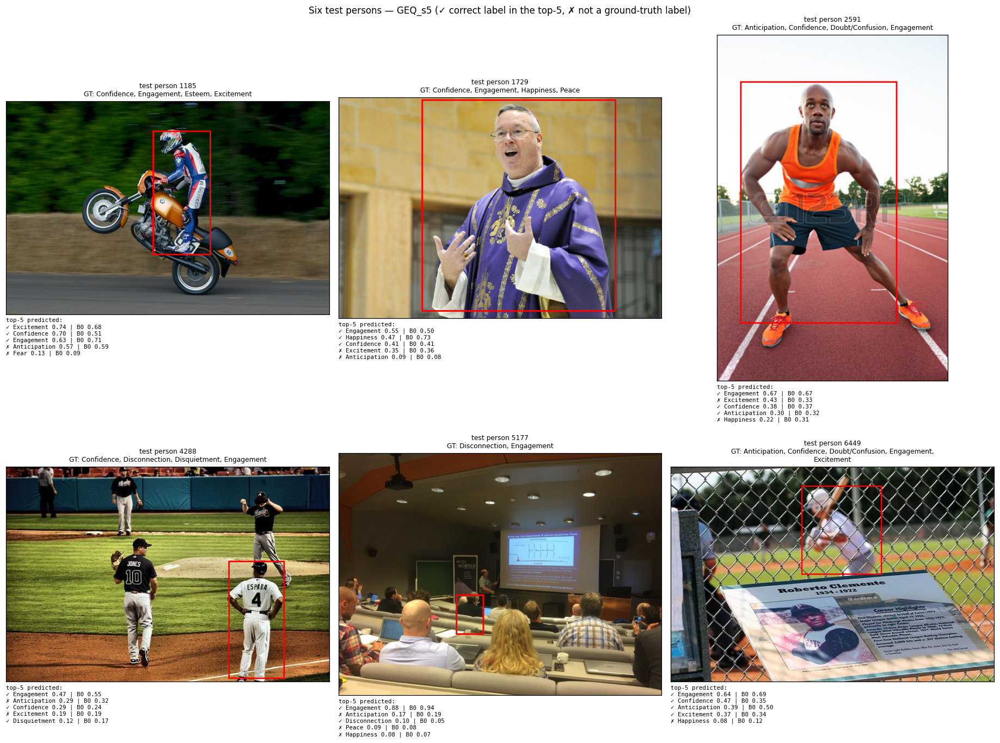

  ✓ six test samples shown and saved                   got /kaggle/working/figures/phaseC_geq/qualitative_samples.png, expected png

10.2  FIGURES


Training curves (validation selection metric, mean ± std over seeds)



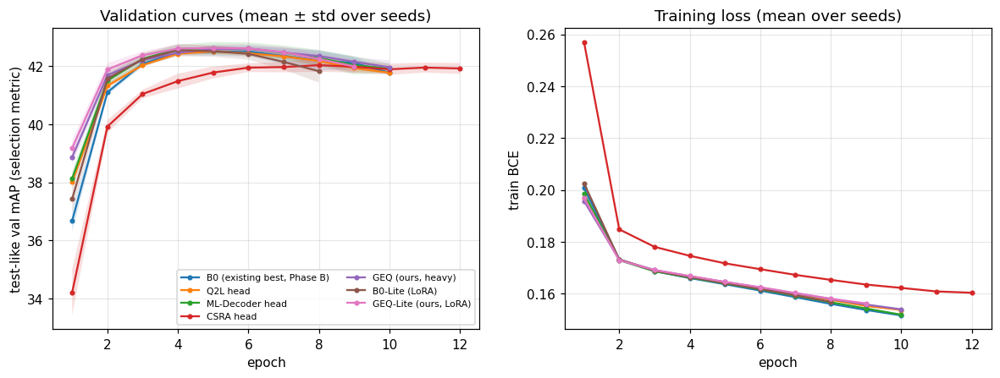

  ✓ figure: curves                                     got /kaggle/working/figures/phaseC_geq/training_curves.png, expected png

Conditional false-positive matrix (multi-label confusion structure)



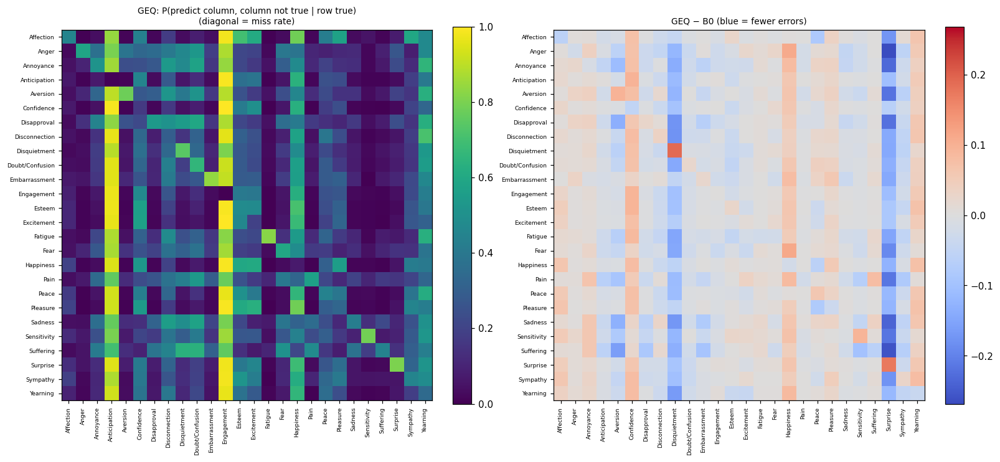

  ✓ figure: confusion                                  got /kaggle/working/figures/phaseC_geq/conditional_false_positives.png, expected png

ROC / PR



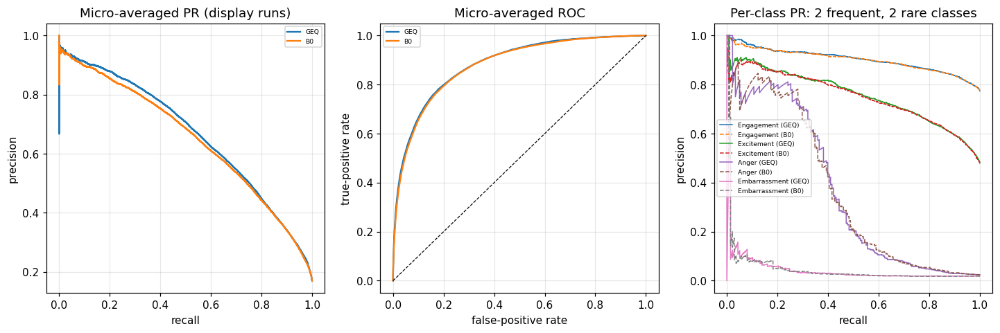

  ✓ figure: roc_pr                                     got /kaggle/working/figures/phaseC_geq/roc_pr.png, expected png

Reliability diagrams (test; Platt fitted on val)



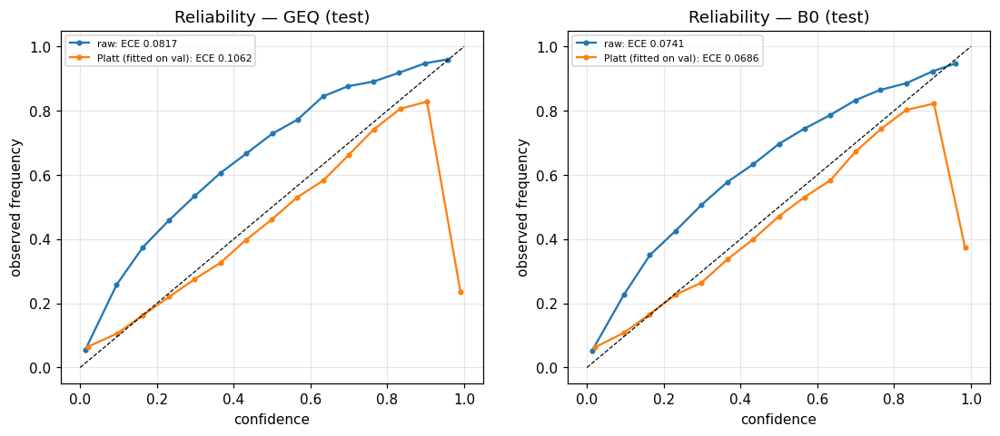

  ✓ figure: calibration                                got /kaggle/working/figures/phaseC_geq/reliability.png, expected png

Per-class AP gain with 95% CIs



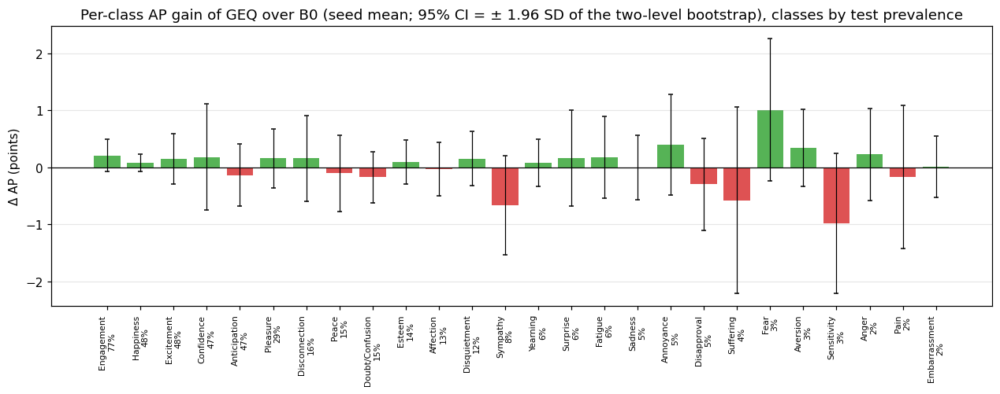

  ✓ figure: per_class                                  got /kaggle/working/figures/phaseC_geq/per_class_gain.png, expected png

Robustness



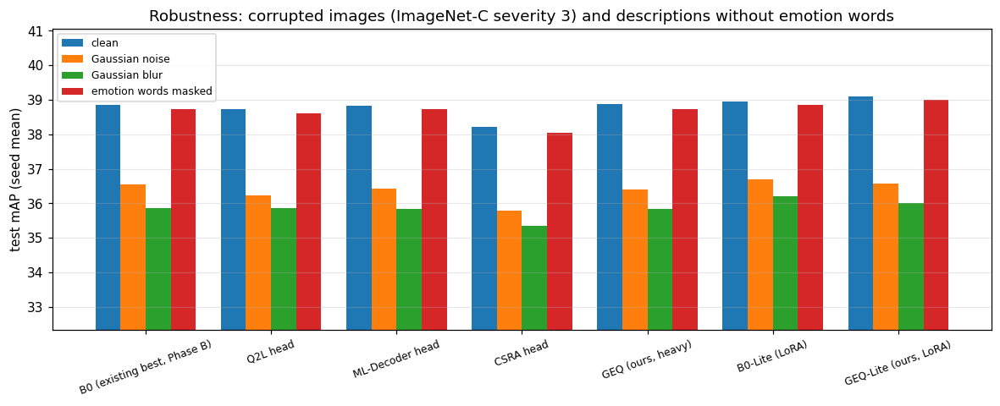

  ✓ figure: robustness                                 got /kaggle/working/figures/phaseC_geq/robustness.png, expected png

10.3  FAILURE CASES


Highest per-person loss of the proposed model



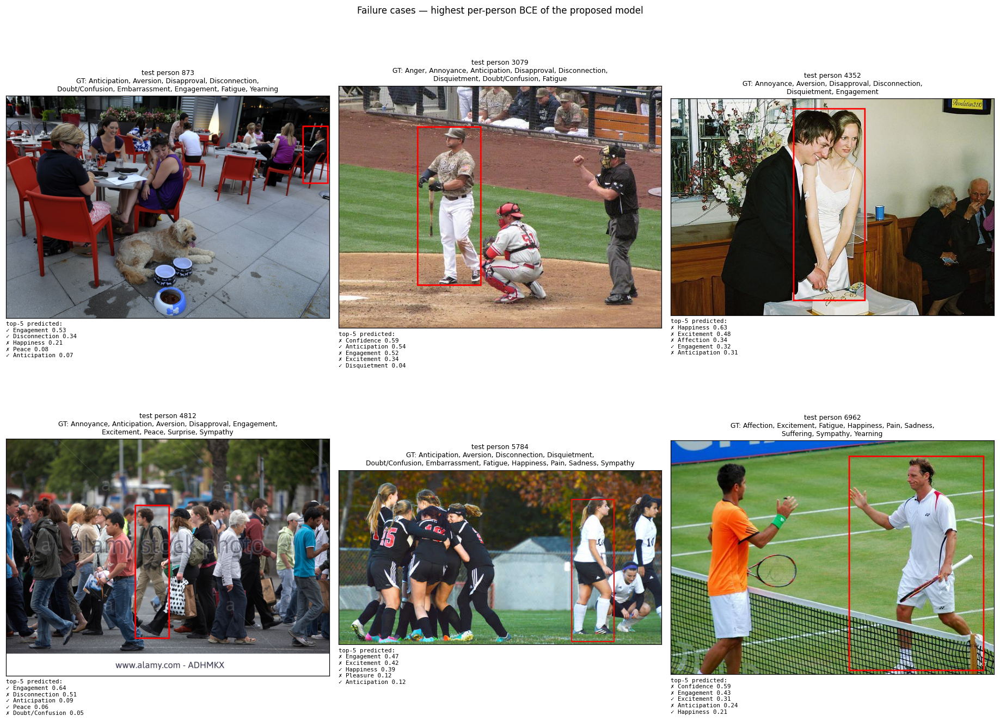

  ✓ failure cases shown and saved                      got /kaggle/working/figures/phaseC_geq/failure_cases.png, expected png

10.4  SALIENCY AND SANITY CHECK


Saliency — GEQ_s5



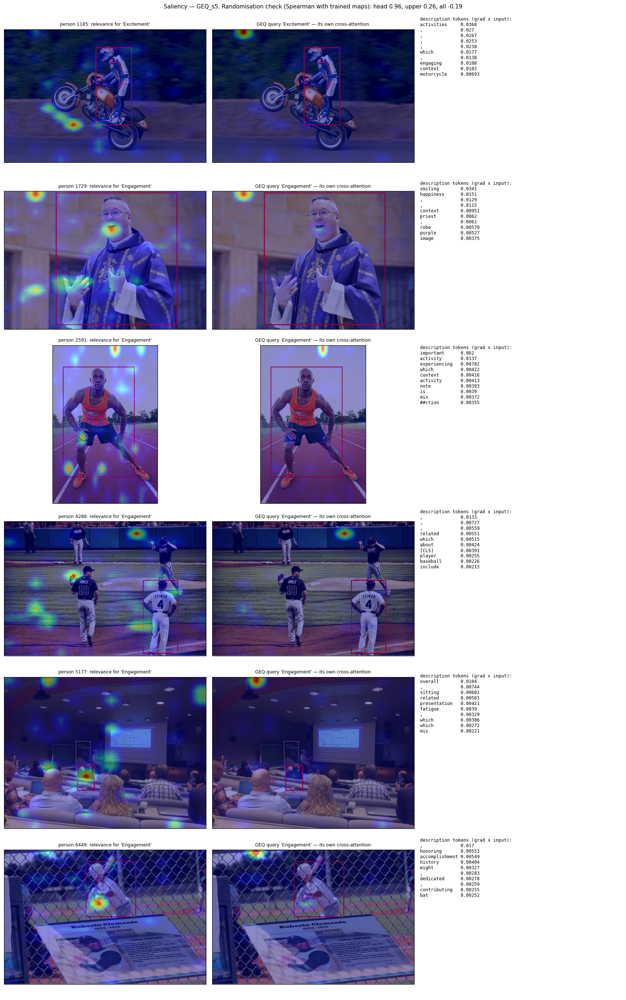


Randomisation test — GEQ_s5



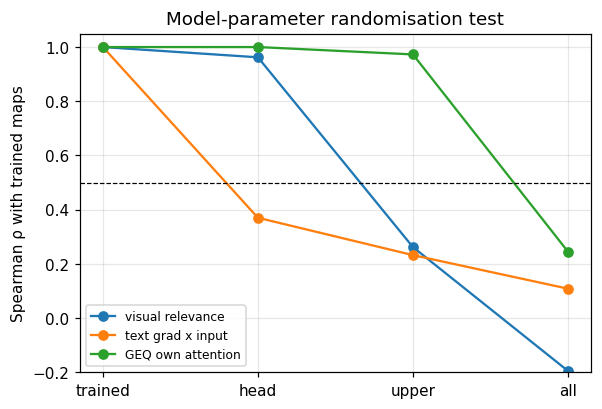

  GEQ: Spearman ρ (trained vs randomised maps) visual head +0.96  upper +0.26  all -0.19 | text head +0.37  upper +0.23  all +0.11
  ✓ [GEQ] maps depend on the learned weights (ρ after full randomisation < 0.5) got -0.19, expected < 0.50

Saliency — B0_s5



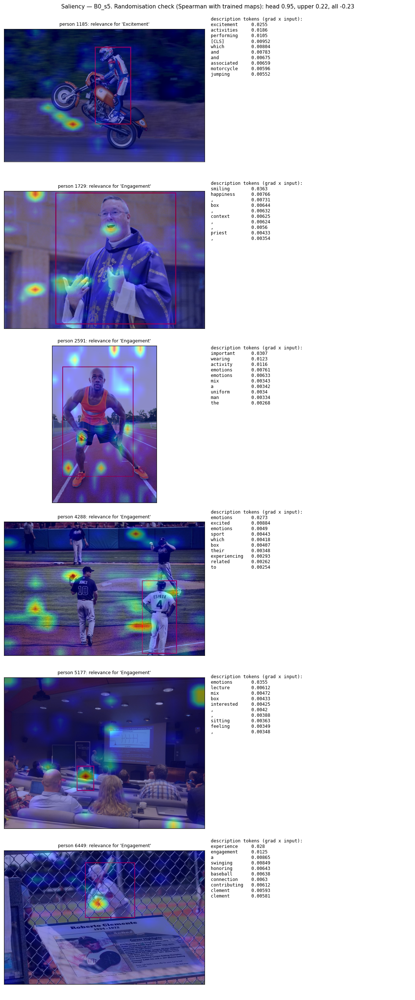


Randomisation test — B0_s5



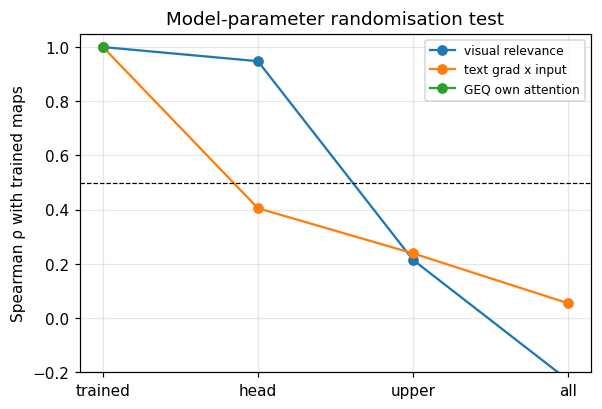

  B0: Spearman ρ (trained vs randomised maps) visual head +0.95  upper +0.22  all -0.23 | text head +0.41  upper +0.24  all +0.05
  ✓ [B0] maps depend on the learned weights (ρ after full randomisation < 0.5) got -0.23, expected < 0.50
  · all figures: /kaggle/working/figures/phaseC_geq

════════════════════════════════════════════════════════════════════════════
  VERDICT — BLOCK 10
════════════════════════════════════════════════════════════════════════════

  ✓ final evaluation available (Block 09 ran on every planned run)
  ✓ six test samples shown and saved
  ✓ figure: curves
  ✓ figure: confusion
  ✓ figure: roc_pr
  ✓ figure: calibration
  ✓ figure: per_class
  ✓ figure: robustness
  ✓ failure cases shown and saved
  ✓ [GEQ] maps depend on the learned weights (ρ after full randomisation < 0.5)
  ✓ [B0] maps depend on the learned weights (ρ after full randomisation < 0.5)

████████████████████████████████████████████████████████████████████████████
█  BLOCK 10: ALL 11 CHECKS PASS

In [11]:
# Block 10 — Six Test Samples, Figures, Error Analysis & Saliency with Sanity Check  [Phase C]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Block 09 in this session (it runs once every planned run is finished;
#                 until then this block only reports that it is waiting)
#
#   10.1  six test persons (fixed seed, persons with >= 2 labels): image with the red box,
#         ground truth, GEQ's top-5 (✓ correct / ✗ not a ground-truth label) and the
#         strongest comparator's probability for the same emotions — shown here and saved
#   10.2  training curves, conditional false-positive matrix (multi-label confusion
#         structure), ROC / PR, reliability diagrams, per-class gains, robustness
#   10.3  failure cases (highest per-person loss)
#   10.4  saliency on the six persons for GEQ and the strongest comparator:
#         gradient-weighted cross-attention relevance (Chefer et al. 2021), GEQ's own
#         per-emotion attention, gradient x input on the description; SANITY CHECK
#         (Adebayo et al. 2018): cascading randomisation of the weights (head → upper
#         Q-Former → everything) must decorrelate the maps (Spearman ρ < 0.5).
# ══════════════════════════════════════════════════════════════════════════════

import numpy as np
from IPython.display import Image as _Img, display as _display

header("BLOCK 10 — Samples, Figures, Error Analysis & Saliency  [Phase C]")
V = BlockVerdict(10, "Figures & saliency")
TEST_MODE = os.environ.get("EMOTIC_TEST_MODE") == "1"
if "FEAT_DIR" not in globals():
    FEAT_DIR = Path(PU.read_json(CFG.cache_dir / "feat_dir_phaseC.json", {})["feat_dir"])
from phaseC import visualize as PV
_R = PU.read_json(CFG.results_dir / "final_results.json") or {}
_prog10 = PA.plan_progress(CFG.runs_dir, PA.plan_runs(TRAIN_CFG))
_all_finished = len(_prog10["done"]) + len(_prog10["stopped"]) == len(PA.plan_runs(TRAIN_CFG))
FIGURES_READY = bool(_R) and not globals().get("TEST_SEALED", False) and (
    _all_finished or os.environ.get("EMOTIC_PHASEC_PROVISIONAL") == "1")
V.check("final evaluation available (Block 09 ran on every planned run)", FIGURES_READY,
        "final_results.json" if FIGURES_READY else "waiting for the last runs", "present", fatal=False)
if not FIGURES_READY:
    _bar = "█" * 76
    _msg = "█  FIGURES WAIT FOR THE FINAL EVALUATION (Block 09)"
    print(f"\n{_Y}{_bar}\n{_msg}{' ' * max(1, 75 - len(_msg))}█\n{_bar}{_0}")
    print("  Nothing to draw yet: this block runs automatically in the session in which the last run finishes.")

else:
    _t0 = time.time()
    FIGS = PV.run_visualization(TRAIN_CFG, CFG.work_dir, FEAT_DIR, CFG.results_dir, CFG.figures_dir, saliency=True,
                                tokenizer_repo=CFG.backbone_ckpt)
    V.note("figure time", f"{time.time() - _t0:.0f}s")

    def _show(key, title):
        p = FIGS["figures"].get(key)
        if p and Path(p).exists():
            print(f"\n{title}\n")
            _display(_Img(filename=p))
            return True
        return False


    # ──────────────────────────────────────────────────────────────────────────────
    # 10.1  SIX TEST SAMPLES (shown live and saved)
    # ──────────────────────────────────────────────────────────────────────────────
    print("10.1  SIX TEST SAMPLES\n")
    V.check("six test samples shown and saved", _show("samples", f"Six test persons {FIGS['samples']}"),
            FIGS["figures"].get("samples", "missing"), "png")

    # ──────────────────────────────────────────────────────────────────────────────
    # 10.2  CURVES, ERROR STRUCTURE, ROC/PR, CALIBRATION, PER-CLASS, ROBUSTNESS
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n10.2  FIGURES\n")
    for _k, _t in (("curves", "Training curves (validation selection metric, mean ± std over seeds)"),
                   ("confusion", "Conditional false-positive matrix (multi-label confusion structure)"),
                   ("roc_pr", "ROC / PR"), ("calibration", "Reliability diagrams (test; Platt fitted on val)"),
                   ("per_class", "Per-class AP gain with 95% CIs"), ("robustness", "Robustness")):
        V.check(f"figure: {_k}", _show(_k, _t), FIGS["figures"].get(_k, "missing"), "png", fatal=False)

    # ──────────────────────────────────────────────────────────────────────────────
    # 10.3  FAILURE CASES
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n10.3  FAILURE CASES\n")
    V.check("failure cases shown and saved", _show("failures", "Highest per-person loss of the proposed model"),
            FIGS["figures"].get("failures", "missing"), "png", fatal=False)

    # ──────────────────────────────────────────────────────────────────────────────
    # 10.4  SALIENCY + RANDOMISATION SANITY CHECK
    # ──────────────────────────────────────────────────────────────────────────────
    print("\n10.4  SALIENCY AND SANITY CHECK\n")
    if not FIGS["saliency"]:
        V.check("saliency computed (needs the kept weights of the display runs)", False, "no weights", "GEQ / B0",
                fatal=False)
    for _e, _s in FIGS["saliency"].items():
        _show(f"saliency_{_e}", f"Saliency — {_s['run']}")
        _show(f"sanity_{_e}", f"Randomisation test — {_s['run']}")
        _vis = _s["spearman_visual"]
        print(f"  {_e}: Spearman ρ (trained vs randomised maps) visual "
              + "  ".join(f"{k} {v:+.2f}" for k, v in _vis.items())
              + " | text " + "  ".join(f"{k} {v:+.2f}" for k, v in _s["spearman_text"].items()))
        V.check(f"[{_e}] maps depend on the learned weights (ρ after full randomisation < 0.5)", _s["passes"],
                f"{_vis['all']:+.2f}", "< 0.50", fatal=False)
    PU.write_json(CFG.results_dir / "saliency_sanity.json", FIGS["saliency"])
    V.note("all figures", str(CFG.figures_dir))
free_memory()
BLOCK_10_OK = V.finish()


In [12]:
# Block 11 — Session Clean-up, Results Archive & Final Status  [Phase C]
# ══════════════════════════════════════════════════════════════════════════════
# PREREQUISITES : Blocks 01–10 of this session (Run All)
#
# EVERY SESSION — removes only what is never needed again, never a result:
#   * leftovers of interrupted writes (*.tmp), STOP files, the smoke-test workspaces,
#     the package's __pycache__
#   * last.pt of FINISHED runs (normally deleted by the worker itself); the last.pt of
#     a PAUSED run is its resume point and is always kept
#   * nothing is touched while a training or extraction worker is still alive
#   * releases this kernel's GPU / host memory, reports the disk, and prints the
#     progress of the plan with the number of sessions still needed
# FINAL SESSION — once every planned run is finished and Blocks 09–10 have written the
# evaluation and the figures:
#   * /kaggle/working/phaseC_results_archive.zip: LaTeX + Markdown tables, figures,
#     final_results.json, selection.json, pre-registration, environment, test-access
#     log, per-run history / result / eval / spec / sealed scores, logs, the code
#     (no model weights — the kept fp16 weights stay in runs_phaseC/)
#   * the scratch feature cache is deleted (Block 07 rebuilds it whenever needed)
#   * final banner: PHASE C COMPLETE
# ══════════════════════════════════════════════════════════════════════════════

import math
import zipfile

header("BLOCK 11 — Clean-up, Results Archive & Final Status  [Phase C]")
V = BlockVerdict(11, "Clean-up & archive")
if "TRAIN_CFG" not in globals():
    raise RuntimeError("Run Blocks 01–06 in this session first (Run All).")
ARCHIVE = CFG.work_dir / "phaseC_results_archive.zip"


def _alive_workers():
    """Training / scoring / extraction workers of Phase C that are still running."""
    out = []
    try:
        import psutil
        for _p in psutil.process_iter(["pid", "cmdline"]):
            _cl = _p.info.get("cmdline") or []
            if "phaseC.train" in _cl or ("phaseC.dataset" in _cl and "extract" in _cl):
                out.append(_p.info["pid"])
    except Exception:
        pass
    return out


def _size_gb(path):
    path = Path(path)
    if path.is_dir() and not path.is_symlink():
        return dir_size_gb(path)
    try:
        return path.lstat().st_size / 1e9
    except OSError:
        return 0.0


def _remove(path, removed):
    path = Path(path)
    if not path.exists() and not path.is_symlink():
        return
    gb = _size_gb(path)
    try:
        if path.is_dir() and not path.is_symlink():
            shutil.rmtree(path)
        else:
            path.unlink()
        removed.append((str(path), gb))
    except OSError as e:
        print(f"  {_Y}! could not remove {path}: {e}{_0}")


# ──────────────────────────────────────────────────────────────────────────────
# 11.1  SAFE CLEAN-UP (every session)
# ──────────────────────────────────────────────────────────────────────────────
print("11.1  SAFE CLEAN-UP\n")
PLAN_11 = PA.plan_runs(TRAIN_CFG)
STATES_11 = {n: PA.run_state(CFG.runs_dir / n) for n in PLAN_11}
_alive = _alive_workers()
_removed = []
if _alive:
    V.note("workers still running", f"{len(_alive)} (pid {_alive}) — nothing is removed while they work; "
                                    f"Block 08S stops and saves them")
else:
    for _n, _st in STATES_11.items():
        _d = CFG.runs_dir / _n
        if _st == "done":
            _remove(_d / "last.pt", _removed)
        if _d.is_dir():
            for _f in _d.glob("*.tmp"):
                _remove(_f, _removed)
    for _root in (CFG.results_dir, CFG.figures_dir, CFG.cache_dir):
        for _f in Path(_root).rglob("*.tmp"):
            _remove(_f, _removed)
    if CFG.control_dir.exists():
        for _f in CFG.control_dir.glob("STOP*"):
            _remove(_f, _removed)
    _remove(CFG.work_dir / "runs_smoke", _removed)
    for _root in ("/kaggle/temp", "/tmp"):
        _remove(Path(_root) / "phaseC_smoke", _removed)
    for _pc in list((CFG.work_dir / "phaseC").rglob("__pycache__")):
        _remove(_pc, _removed)
for _p, _gb in _removed:
    V.note("  removed", f"{_p}  ({_gb:.2f} GB)")
V.note("clean-up", f"{len(_removed)} item(s) removed, {sum(g for _, g in _removed):.2f} GB freed")
_paused = [n for n, s in STATES_11.items() if s == "paused"]
V.check("every paused run keeps its resume point (last.pt)",
        all((CFG.runs_dir / n / "last.pt").exists() for n in _paused), f"{len(_paused)} paused run(s)", "all kept")
_failed = [n for n, s in STATES_11.items() if s == "failed"]
V.check("no failed run (a crashed run is retried next session)", not _failed, _failed or "none", "none",
        fatal=False)
free_memory()
V.note("memory", f"host RAM in use {host_mem()}; this kernel's GPU cache released")
_w_gb = dir_size_gb(CFG.work_dir)
V.check("/kaggle/working stays below the 20 GB that persist between sessions", _w_gb < 19.0,
        f"{_w_gb:.1f} GB used", "< 19 GB", fatal=False)

# ──────────────────────────────────────────────────────────────────────────────
# 11.2  PROGRESS OF THE PLAN
# ──────────────────────────────────────────────────────────────────────────────
print("\n11.2  PROGRESS OF THE PLAN\n")
_prog11 = PA.plan_progress(CFG.runs_dir, PLAN_11)
_n_done = len(_prog11["done"]) + len(_prog11["stopped"])     # stopped = pre-registered floor check (final)
for _g in TRAIN_CFG["order"]:
    _names = [n for n in PLAN_11 if TRAIN_CFG["experiments"][PA.parse_run(n)[0]]["group"] == _g]
    _dn = sum(STATES_11[n] == "done" for n in _names)
    _ps = sum(STATES_11[n] == "paused" for n in _names)
    V.note(f"  {_g:<9s}", f"{_dn}/{len(_names)} done" + (f", {_ps} paused (resume next session)" if _ps else ""))
ALL_RUNS_DONE = _n_done == len(PLAN_11)
_R11 = PU.read_json(CFG.results_dir / "final_results.json", {}) or {}
_figs_needed = ("qualitative_samples.png", "training_curves.png", "per_class_gain.png", "reliability.png")
FINAL_READY = (ALL_RUNS_DONE and bool(_R11) and not globals().get("TEST_SEALED", False)
               and all((CFG.figures_dir / f).exists() for f in _figs_needed))
if not ALL_RUNS_DONE:
    _ep_run = min(10, int(TRAIN_CFG["train"]["max_epochs"]))       # typical run length (early stopping)
    _left_epochs = 0
    for _n, _st in STATES_11.items():
        if _n not in _prog11["done"] and _n not in _prog11["stopped"]:
            _h = CFG.runs_dir / _n / "history.csv"
            _ran = max(0, len(_h.read_text().splitlines()) - 1) if _h.exists() else 0
            _left_epochs += max(1, _ep_run - _ran)
    _em = PA.epoch_minutes(CFG.runs_dir, PLAN_11)
    if _em:
        _gpu_h = _left_epochs * _em / 60.0
        _sess = math.ceil(_gpu_h / max(1, min(N_GPUS, 2)) / max(1.0, SESSION_BUDGET_H - 1.3))
        V.note("remaining", f"{len(PLAN_11) - _n_done} run(s), ≈ {_left_epochs} epochs ≈ {_gpu_h:.1f} GPU-hours "
                            f"→ ≈ {_sess} more session(s) on {max(1, min(N_GPUS, 2))} GPU(s) (measured epoch time "
                            f"{_em:.1f} min, {_ep_run} epochs per run assumed)")
    else:
        V.note("remaining", f"{len(PLAN_11) - _n_done} run(s); the session estimate appears once an epoch has run")

# ──────────────────────────────────────────────────────────────────────────────
# 11.3  RESULTS ARCHIVE + FINAL CLEAN-UP (final session only)
# ──────────────────────────────────────────────────────────────────────────────
print("\n11.3  RESULTS ARCHIVE\n")
if not FINAL_READY:
    V.note("archive", "written in the final session (after every run is finished and evaluated)")
else:
    _tmp = ARCHIVE.with_name(ARCHIVE.name + ".tmp")
    _n_files = 0
    with zipfile.ZipFile(_tmp, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as _z:
        def _add(path, arc):
            global _n_files
            if Path(path).is_file() and not str(path).endswith((".tmp", ".pt")):
                _z.write(path, arc)
                _n_files += 1
        for _root, _arc in ((CFG.results_dir, "results"), (CFG.figures_dir, "figures"), (CFG.log_dir, "logs")):
            for _f in sorted(Path(_root).rglob("*")):
                _add(_f, f"{_arc}/{_f.relative_to(_root)}")
        for _n in PLAN_11:
            for _fn in ("history.csv", "result.json", "eval.json", "spec.json", "spec_resolved.json", "scores.npz",
                        "worker.log"):
                _add(CFG.runs_dir / _n / _fn, f"runs/{_n}/{_fn}")
        for _f in sorted(CFG.cache_dir.glob("*.json")):
            _add(_f, f"cache/{_f.name}")
        for _f in sorted((CFG.work_dir / "phaseC").glob("*")):
            _add(_f, f"code/phaseC/{_f.name}")
    os.replace(_tmp, ARCHIVE)
    with zipfile.ZipFile(ARCHIVE) as _z:
        _bad = _z.testzip()
    V.check("results archive written and readable", _bad is None and _n_files > 0,
            f"{ARCHIVE.name}: {_n_files} files, {ARCHIVE.stat().st_size / 1e6:.0f} MB", "complete")
    _feat = Path((PU.read_json(CFG.cache_dir / "feat_dir_phaseC.json", {}) or {}).get("feat_dir", ""))
    if str(_feat) not in ("", ".") and _feat.exists() and not _alive_workers():
        _gb = dir_size_gb(_feat)
        shutil.rmtree(_feat, ignore_errors=True)
        V.note("scratch feature cache deleted", f"{_feat} ({_gb:.1f} GB) — Block 07 rebuilds it if ever needed")
    free_memory()

# ──────────────────────────────────────────────────────────────────────────────
# 11.4  FINAL STATUS
# ──────────────────────────────────────────────────────────────────────────────
print("\n11.4  STATUS\n")
_bar = "█" * 76
if FINAL_READY:
    _gt = _R11.get("gate") or {}
    _ag = _R11.get("aggregate") or {}
    _pr, _st_ = _gt.get("proposed"), _gt.get("strongest")
    if _pr in _ag and _st_ in _ag:
        _c = (_R11.get("comparisons") or {}).get(f"{_pr}|{_st_}", {})
        _ci = _c.get("boot_ci") or [float("nan"), float("nan")]
        print(f"  {_pr}: {_ag[_pr]['mean']:.2f} ± {_ag[_pr]['std']:.2f} test mAP | strongest comparator {_st_}: "
              f"{_ag[_st_]['mean']:.2f} ± {_ag[_st_]['std']:.2f} | Δ {_c.get('delta_mean', float('nan')):+.2f} "
              f"(95% CI [{_ci[0]:+.2f}, {_ci[1]:+.2f}])")
    print(f"  decision gate (pre-registered): {_gt.get('verdict', 'n/a')}"
          + (f" | lite claim: {'holds' if (_gt.get('lite') or {}).get('claim') else 'does not hold'}"
             if _gt.get("lite") else ""))
    print(f"  tables:   {CFG.results_dir / 'tables'}\n  figures:  {CFG.figures_dir}\n  archive:  {ARCHIVE}")
    _msg = f"█  PHASE C COMPLETE — {_n_done}/{len(PLAN_11)} runs · gate: {_gt.get('verdict', 'n/a')} · archived"
    print(f"\n{_G}{_bar}\n{_msg}{' ' * max(1, 75 - len(_msg))}█\n{_bar}{_0}")
else:
    _msg = f"█  PHASE C IN PROGRESS — {_n_done}/{len(PLAN_11)} runs done · next session: Run All"
    print(f"\n{_Y}{_bar}\n{_msg}{' ' * max(1, 75 - len(_msg))}█\n{_bar}{_0}")
    print("  /kaggle/working keeps every finished run and every resume point (Persistence: Files only).")
BLOCK_11_OK = V.finish()



════════════════════════════════════════════════════════════════════════════
  BLOCK 11 — Clean-up, Results Archive & Final Status  [Phase C]
════════════════════════════════════════════════════════════════════════════

11.1  SAFE CLEAN-UP

  ·   removed: /kaggle/working/phaseC/__pycache__  (0.00 GB)
  · clean-up: 1 item(s) removed, 0.00 GB freed
  ✓ every paused run keeps its resume point (last.pt)  got 0 paused run(s), expected all kept
  ✓ no failed run (a crashed run is retried next session) got none, expected none
  · memory: host RAM in use 5.1/33.7GB; this kernel's GPU cache released
  ✓ /kaggle/working stays below the 20 GB that persist between sessions got 4.3 GB used, expected < 19 GB

11.2  PROGRESS OF THE PLAN

  ·   main     : 25/25 done
  ·   lite     : 10/10 done
  ·   ablation : 25/25 done

11.3  RESULTS ARCHIVE

  ✓ results archive written and readable               got phaseC_results_archive.zip: 481 files, 282 MB, expected complete
  · scratch feature cache deleted: